# Формирование одиночного солитона в PINN

Проверяем, воспроизводит ли одна PINN эволюцию гауссова импульса на всём интервале $t\in[0,30]$.
Начальное условие взято из [первого эксперимента](../01_initial-pulse-outcomes/initial-outcomes.ipynb),
$A=1.6$ и $\sigma=0.32933120784708886$. Спектральный расчёт используется для сравнения после обучения.

## Запуск обучения

Выполните из корня проекта в PowerShell. Первая команда обновляет lock-файл и устанавливает зависимости эксперимента.

```powershell
uv sync --extra pinn --extra notebooks
$env:DDE_BACKEND = "pytorch"
uv run --locked --extra pinn --extra notebooks lle pinn train --config experiments/05_pinn-single-soliton/pinn_config.yaml
```

В каталоге `runs/<run_id>/` сохраняются веса `model.pt`, взвешенные компоненты функции потерь в `losses.csv` и комплексное поле в `field_evolution.npz`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from lle.analysis.criteria import is_homogeneous, is_stationary
from lle.analysis.fields import relative_field_l2_error, relative_l2_error, time_mask
from lle.analysis.peaks import peak_indices
from lle.runs.runs import get_run
from lle.storage import load_evolution

PINN_RUN_ID = "2026-11-09_04-10-04_566770"
REFERENCE_RUN_ID = "2026-11-02_09-17-58_787839"

if not PINN_RUN_ID:
    raise ValueError("Укажите ID завершённого прогона PINN")

pinn = load_evolution(get_run(PINN_RUN_ID).path)
reference = load_evolution(get_run(REFERENCE_RUN_ID).path)
reference = reference[time_mask(reference.times, pinn.times[0], pinn.times[-1])]
if not np.array_equal(pinn.theta, reference.theta) or not np.array_equal(pinn.times, reference.times):
    raise ValueError("Для сравнения нужны совпадающие сетки и моменты записи")

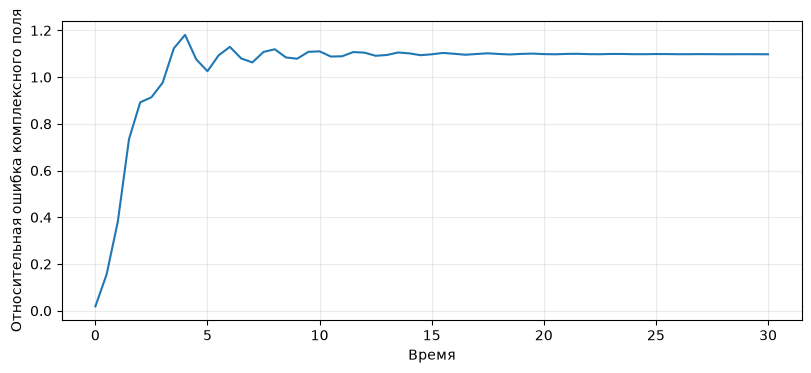

In [31]:
error = relative_l2_error(pinn.values, reference.values)
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(pinn.times, error)
ax.set(xlabel="Время", ylabel="Относительная ошибка комплексного поля")
ax.grid(alpha=0.25)
plt.show()

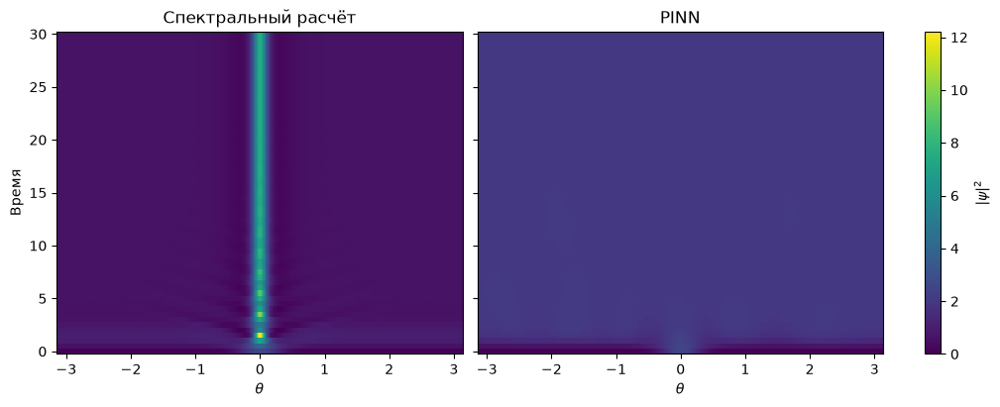

In [32]:
reference_intensity = reference.intensity.values
pinn_intensity = pinn.intensity.values
vmax = max(reference_intensity.max(), pinn_intensity.max())
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, layout="constrained")
for ax, intensity, label in zip(axes, (reference_intensity, pinn_intensity),
                                ("Спектральный расчёт", "PINN")):
    image = ax.pcolormesh(pinn.theta, pinn.times, intensity, shading="auto", vmin=0, vmax=vmax)
    ax.set(title=label, xlabel=r"$\theta$")
axes[0].set_ylabel("Время")
fig.colorbar(image, ax=axes, label=r"$|\psi|^2$")
plt.show()

Спектральный расчёт: один выраженный пик на всех снимках — True, стационарность — False, изменение поля — 0.00111, пиковая интенсивность при t=30 — 7.5409
PINN: один выраженный пик на всех снимках — False, стационарность — True, изменение поля — 0.000365, пиковая интенсивность при t=30 — 2.0016


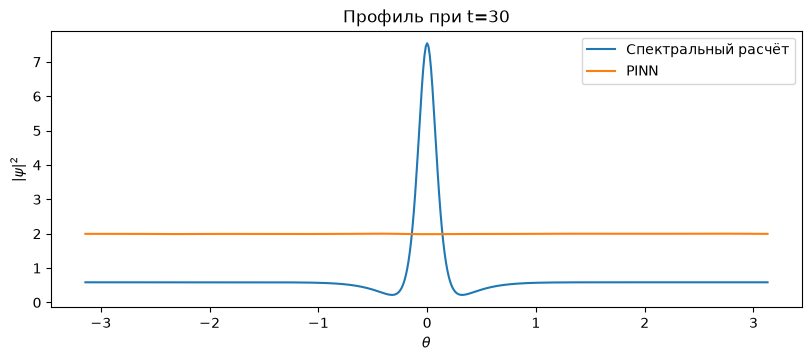

Относительная L²-ошибка PINN к однородному решению при t=30: 0.29%


In [33]:
tail_start = 27.0
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
for evolution, label in ((reference, "Спектральный расчёт"), (pinn, "PINN")):
    tail = evolution[time_mask(evolution.times, tail_start, 30.0)]
    intensity = tail.intensity
    one_peak = all(not is_homogeneous(profile) and len(peak_indices(profile)) == 1
                   for profile in intensity)
    change = relative_field_l2_error(tail, tail[-1]).max()
    stationary = is_stationary(tail)
    print(f"{label}: один выраженный пик на всех снимках — {one_peak}, "
          f"стационарность — {stationary}, изменение поля — {change:.3g}, "
          f"пиковая интенсивность при t=30 — {intensity[-1].values.max():.4f}")
    ax.plot(evolution.theta, intensity[-1].values, label=label)
ax.set(xlabel=r"$\theta$", ylabel=r"$|\psi|^2$", title="Профиль при t=30")
ax.legend()
plt.show()

homogeneous_field = np.full_like(pinn[-1].values, 1 - 1j)
homogeneous_error = relative_l2_error(pinn[-1].values, homogeneous_field)
print(f"Относительная L²-ошибка PINN к однородному решению при t=30: {homogeneous_error:.2%}")

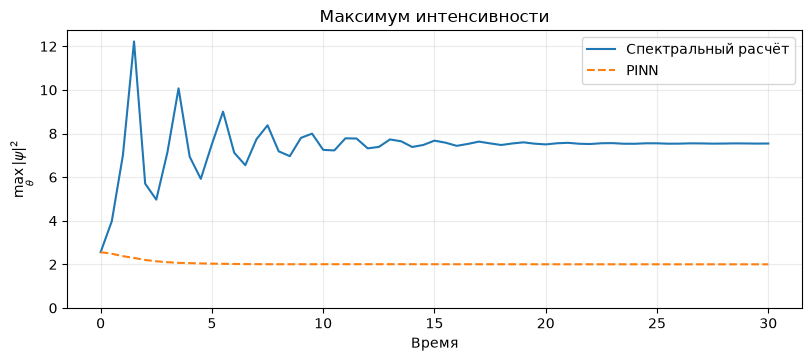

In [34]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(reference.times, reference_intensity.max(axis=1), label="Спектральный расчёт")
ax.plot(pinn.times, pinn_intensity.max(axis=1), "--", label="PINN")
ax.set(title="Максимум интенсивности", xlabel="Время", ylabel=r"$\max_\theta |\psi|^2$", ylim=(0, None))
ax.legend()
ax.grid(alpha=0.25)
plt.show()

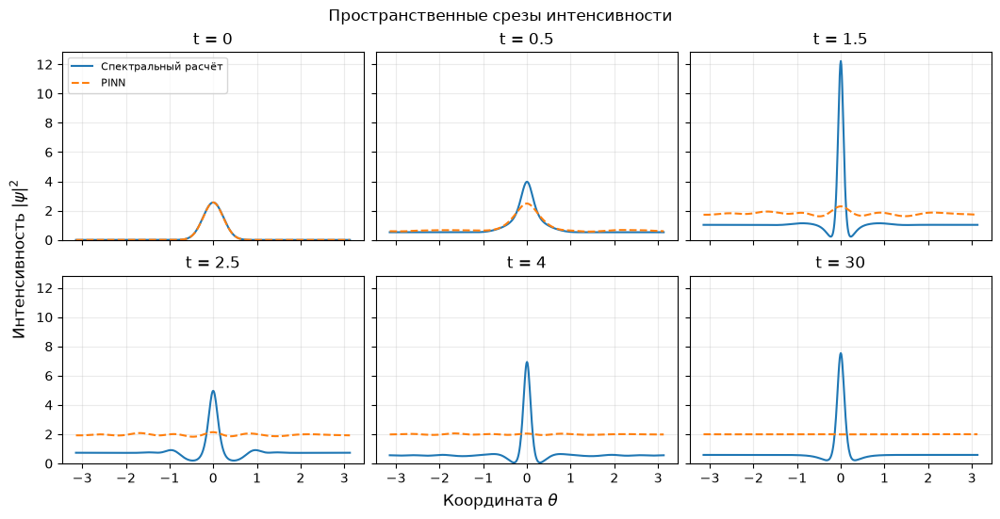

In [35]:
slice_times = (0, 0.5, 1.5, 2.5, 4, 30)
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.4), sharex=True, sharey=True, layout="constrained")
fig.suptitle("Пространственные срезы интенсивности")
for ax, time in zip(axes.flat, slice_times):
    reference_profile = reference.at_time(time).intensity
    pinn_profile = pinn.at_time(time).intensity
    ax.plot(reference_profile.theta, reference_profile.values, label="Спектральный расчёт")
    ax.plot(pinn_profile.theta, pinn_profile.values, "--", label="PINN")
    ax.set_title(f"t = {time:g}")
    ax.grid(alpha=0.25)
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supxlabel(r"Координата $\theta$")
fig.supylabel(r"Интенсивность $|\psi|^2$")
plt.show()

### История функции потерь

Для каждого прогона показана сумма двух вещественных компонент невязки LLE на обучающих и проверочных точках. Для начального условия показана сумма двух взвешенных компонент из `losses.csv`. DeepXDE использует одни и те же точки начального условия при расчёте обучающих и проверочных потерь, поэтому для него приведена одна кривая.

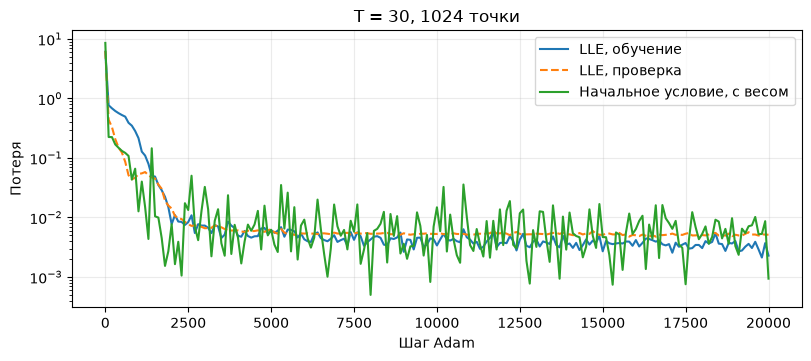

In [36]:
def plot_loss_history(run_id, title):
    losses = np.genfromtxt(get_run(run_id).path / "losses.csv", delimiter=",", names=True)
    fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
    ax.semilogy(losses["step"], losses["train_pde_u"] + losses["train_pde_v"],
                label="LLE, обучение")
    ax.semilogy(losses["step"], losses["test_pde_u"] + losses["test_pde_v"], "--",
                label="LLE, проверка")
    ax.semilogy(losses["step"], losses["train_ic_u"] + losses["train_ic_v"],
                label="Начальное условие, с весом")
    ax.set(title=title, xlabel="Шаг Adam", ylabel="Потеря")
    ax.legend()
    ax.grid(alpha=0.25)
    return fig


fig = plot_loss_history(PINN_RUN_ID, "T = 30, 1024 точки")
plt.show()

## Выводы по прогону `2026-11-09_04-10-04_566770`

После 20 000 шагов Adam PINN не воспроизвела формирование одиночного солитона. Относительная $L^2$-ошибка комплексного поля выросла с 1,9 % при $t=0$ до 73,4 % при $t=1.5$ и достигла 109,8 % при $t=30$. Уже на раннем переходном участке пик в спектральном расчёте растёт, а у PINN постепенно затухает.

На окне $[27,30]$ относительное изменение поля PINN не превышает $3.65\times10^{-4}$. К $t=30$ поле почти однородно и отличается всего на **0,29 %** по относительной $L^2$-норме от $\psi=1-i$. Это точное однородное стационарное решение при $F=2$ и $\Delta=3$: $|\psi|^2=2$, пространственная производная равна нулю, а $[1+i(\Delta-|\psi|^2)]\psi=(1+i)(1-i)=2=F$.

Максимальная интенсивность PINN при $t=30$ равна 2,002, а пик спектрального солитона достигает 7,541. Малая невязка уравнения совместима с таким расхождением, поскольку поле PINN приближается к другому стационарному решению.

## Обучение на коротком интервале $[0,0.5]$

Проверяем, воспроизводит ли PINN начальный рост импульса при обучении на коротком интервале. Параметры уравнения, импульс, архитектура, seed и число шагов Adam совпадают с длинным прогоном. Для сравнения со спектральным решателем сохраняем поле через $0.01$.

In [37]:
SHORT_PINN_RUN_ID = "2026-11-09_04-47-43_102416"
SHORT_REFERENCE_RUN_ID = "2026-11-09_04-57-10_283382"

short_pinn = load_evolution(get_run(SHORT_PINN_RUN_ID).path)
short_reference = load_evolution(get_run(SHORT_REFERENCE_RUN_ID).path)
if not np.array_equal(short_pinn.theta, short_reference.theta) or not np.array_equal(
    short_pinn.times, short_reference.times
):
    raise ValueError("Для сравнения нужны совпадающие сетки и моменты записи")

short_error = relative_l2_error(short_pinn.values, short_reference.values)
long_endpoint = pinn.at_time(short_pinn.times[-1])
long_endpoint_error = relative_field_l2_error(long_endpoint, short_reference[-1])
print(f"Ошибка комплексного поля при t=0: {short_error[0]:.2%}")
print(f"Максимальная ошибка на сохранённых срезах: {short_error.max():.2%} "
      f"при t={short_pinn.times[short_error.argmax()]:g}")
print(f"Ошибка при t=0.5: короткий прогон {short_error[-1]:.2%}, "
      f"длинный прогон {long_endpoint_error:.2%}")
print(f"Пик при t=0.5: короткий прогон {short_pinn[-1].intensity.values.max():.4f}, "
      f"длинный прогон {long_endpoint.intensity.values.max():.4f}, "
      f"спектральный расчёт {short_reference[-1].intensity.values.max():.4f}")

Ошибка комплексного поля при t=0: 0.10%
Максимальная ошибка на сохранённых срезах: 0.12% при t=0.12
Ошибка при t=0.5: короткий прогон 0.09%, длинный прогон 15.50%
Пик при t=0.5: короткий прогон 3.9706, длинный прогон 2.4856, спектральный расчёт 3.9748


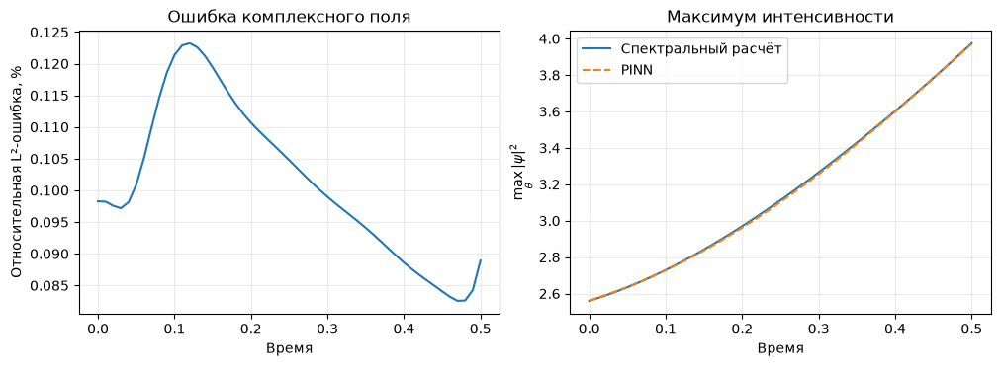

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].plot(short_pinn.times, 100 * short_error)
axes[0].set(title="Ошибка комплексного поля", xlabel="Время", ylabel="Относительная L²-ошибка, %")
axes[1].plot(short_reference.times, short_reference.intensity.values.max(axis=1),
             label="Спектральный расчёт")
axes[1].plot(short_pinn.times, short_pinn.intensity.values.max(axis=1), "--", label="PINN")
axes[1].set(title="Максимум интенсивности", xlabel="Время", ylabel=r"$\max_\theta |\psi|^2$")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

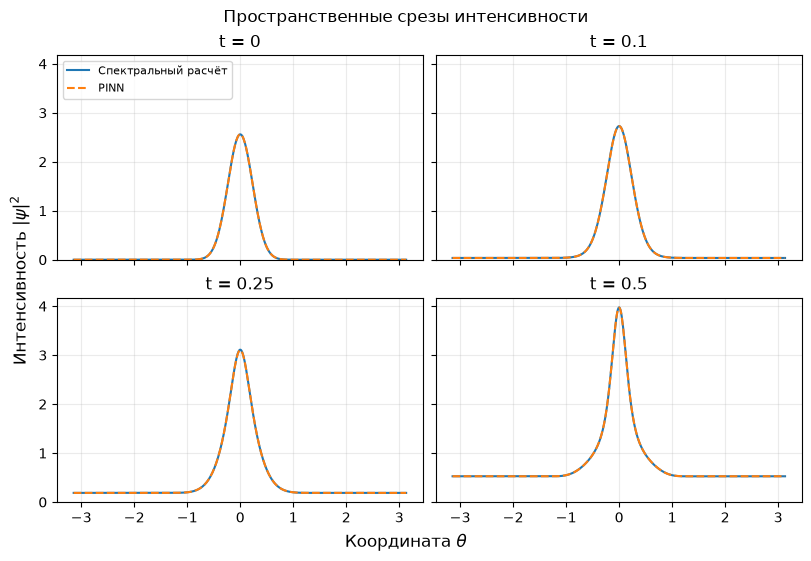

In [39]:
short_slice_times = (0, 0.1, 0.25, 0.5)
fig, axes = plt.subplots(2, 2, figsize=(8, 5.5), sharex=True, sharey=True, layout="constrained")
fig.suptitle("Пространственные срезы интенсивности")
for ax, time in zip(axes.flat, short_slice_times):
    reference_profile = short_reference.at_time(time).intensity
    pinn_profile = short_pinn.at_time(time).intensity
    ax.plot(reference_profile.theta, reference_profile.values, label="Спектральный расчёт")
    ax.plot(pinn_profile.theta, pinn_profile.values, "--", label="PINN")
    ax.set_title(f"t = {time:g}")
    ax.grid(alpha=0.25)
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supxlabel(r"Координата $\theta$")
fig.supylabel(r"Интенсивность $|\psi|^2$")
plt.show()

### История функции потерь

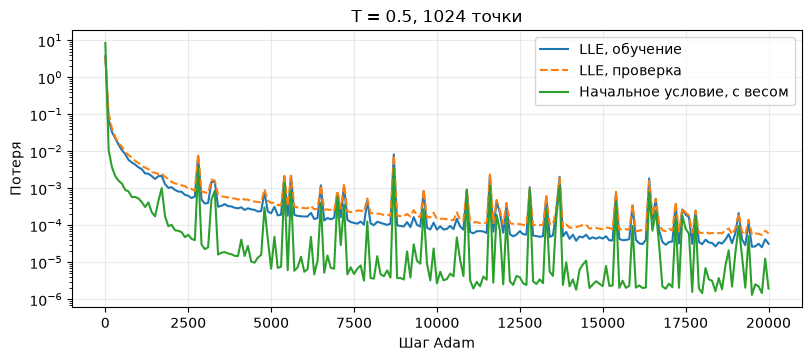

In [40]:
fig = plot_loss_history(SHORT_PINN_RUN_ID, "T = 0.5, 1024 точки")
plt.show()

## Обучение на интервале $[0,2]$

Проверяем, воспроизводит ли PINN резкий рост и сужение пика около $t=1.5$ и последующий спад. Параметры сети и обучения совпадают с прогоном на $[0,0.5]$. Начинаем обучение с новой инициализации по тому же seed.

Запуск из корня проекта в PowerShell.

```powershell
$env:DDE_BACKEND = "pytorch"
uv run --no-sync lle pinn train --config experiments/05_pinn-single-soliton/pinn_config.yaml domain.time_end=2.0 recording.interval=0.01
```

Спектральный эталон записан в 201 момент от $0$ до $2$ с шагом $0.01$.

In [41]:
PINN_T2_RUN_ID = "2026-11-09_05-04-52_453080"
REFERENCE_T2_RUN_ID = "2026-11-09_05-03-32_207710"

if not PINN_T2_RUN_ID:
    raise ValueError("Укажите ID завершённого прогона PINN на интервале [0, 2]")

pinn_t2 = load_evolution(get_run(PINN_T2_RUN_ID).path)
reference_t2 = load_evolution(get_run(REFERENCE_T2_RUN_ID).path)
if not np.array_equal(pinn_t2.theta, reference_t2.theta) or (
    pinn_t2.times.shape != reference_t2.times.shape
    or not np.allclose(pinn_t2.times, reference_t2.times, rtol=0, atol=1e-10)
):
    raise ValueError("Для сравнения нужны совпадающие сетки и моменты записи")

t2_error = relative_l2_error(pinn_t2.values, reference_t2.values)
t2_slice_times = (0.5, 1.0, 1.5, 2.0)
print(f"Максимальная ошибка поля: {t2_error.max():.2%} "
      f"при t={pinn_t2.times[t2_error.argmax()]:g}")
for time in t2_slice_times:
    predicted = pinn_t2.at_time(time)
    expected = reference_t2.at_time(time)
    error_at_time = relative_field_l2_error(predicted, expected)
    print(f"t={time:g}: ошибка поля {error_at_time:.2%}, "
          f"пик PINN {predicted.intensity.values.max():.4f}, "
          f"спектральный пик {expected.intensity.values.max():.4f}")

Максимальная ошибка поля: 51.92% при t=1.65
t=0.5: ошибка поля 5.80%, пик PINN 3.3188, спектральный пик 3.9748
t=1: ошибка поля 17.88%, пик PINN 4.2275, спектральный пик 7.0036
t=1.5: ошибка поля 47.49%, пик PINN 6.3090, спектральный пик 12.2209
t=2: ошибка поля 29.96%, пик PINN 9.3558, спектральный пик 5.7006


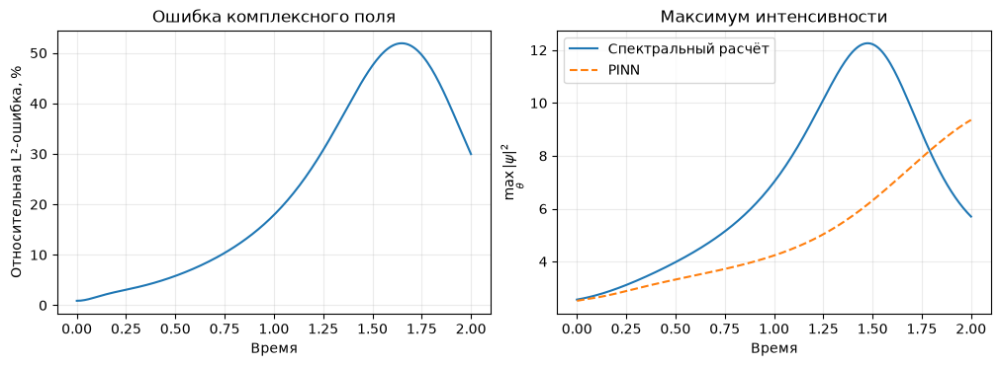

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].plot(pinn_t2.times, 100 * t2_error)
axes[0].set(title="Ошибка комплексного поля", xlabel="Время", ylabel="Относительная L²-ошибка, %")
axes[1].plot(reference_t2.times, reference_t2.intensity.values.max(axis=1),
             label="Спектральный расчёт")
axes[1].plot(pinn_t2.times, pinn_t2.intensity.values.max(axis=1), "--", label="PINN")
axes[1].set(title="Максимум интенсивности", xlabel="Время", ylabel=r"$\max_\theta |\psi|^2$")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

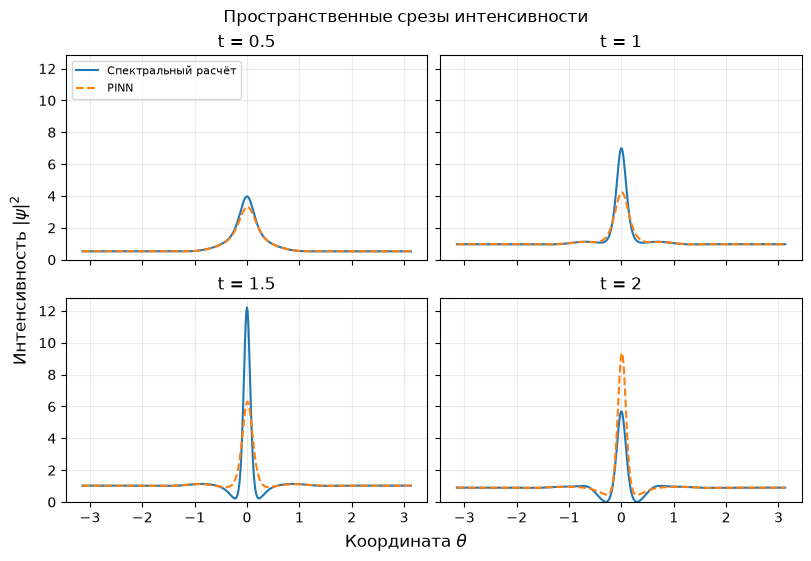

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(8, 5.5), sharex=True, sharey=True, layout="constrained")
fig.suptitle("Пространственные срезы интенсивности")
for ax, time in zip(axes.flat, t2_slice_times):
    reference_profile = reference_t2.at_time(time).intensity
    pinn_profile = pinn_t2.at_time(time).intensity
    ax.plot(reference_profile.theta, reference_profile.values, label="Спектральный расчёт")
    ax.plot(pinn_profile.theta, pinn_profile.values, "--", label="PINN")
    ax.set_title(f"t = {time:g}")
    ax.grid(alpha=0.25)
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supxlabel(r"Координата $\theta$")
fig.supylabel(r"Интенсивность $|\psi|^2$")
plt.show()

### История функции потерь

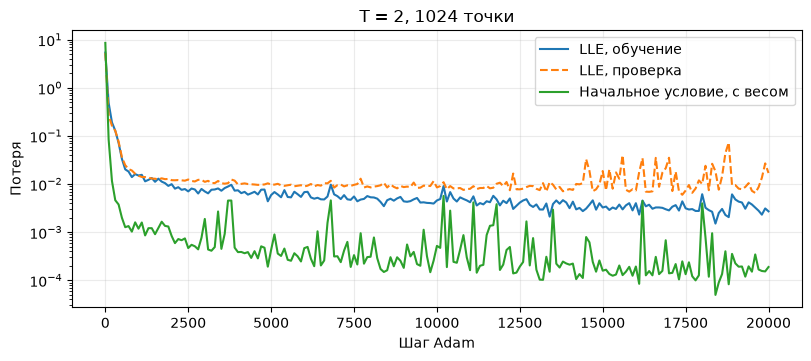

In [44]:
fig = plot_loss_history(PINN_T2_RUN_ID, "T = 2, 1024 точки")
plt.show()

## Обучение на $[0,2]$ с 4096 точками невязки

Сравниваем равномерную выборку из 4096 внутренних точек с базовым прогоном на 1024 точках. Оба прогона используют 256 точек начального условия, одинаковые архитектуру, seed и число шагов Adam. Спектральный эталон и моменты записи совпадают.

Запуск из корня проекта в PowerShell.

```powershell
$env:DDE_BACKEND = "pytorch"
uv run --no-sync lle pinn train --config experiments/05_pinn-single-soliton/pinn_config.yaml domain.time_end=2.0 recording.interval=0.01 domain.interior_points=4096
```

In [45]:
PINN_T2_4096_RUN_ID = "2026-11-09_05-27-14_881035"

if not PINN_T2_4096_RUN_ID:
    raise ValueError("Укажите ID прогона PINN с 4096 внутренними точками")

pinn_t2_4096 = load_evolution(get_run(PINN_T2_4096_RUN_ID).path)
if not np.array_equal(pinn_t2_4096.theta, reference_t2.theta) or (
    pinn_t2_4096.times.shape != reference_t2.times.shape
    or not np.allclose(pinn_t2_4096.times, reference_t2.times, rtol=0, atol=1e-10)
):
    raise ValueError("Для сравнения нужны совпадающие сетки и моменты записи")

t2_error_4096 = relative_l2_error(pinn_t2_4096.values, reference_t2.values)
for label, evolution, error_by_time in (
    ("1024 точки", pinn_t2, t2_error),
    ("4096 точек", pinn_t2_4096, t2_error_4096),
):
    maxima = evolution.intensity.values.max(axis=1)
    peak_index = maxima.argmax()
    error_at_half = relative_field_l2_error(evolution.at_time(0.5), reference_t2.at_time(0.5))
    print(f"{label}: ошибка при t=0.5 — {error_at_half:.2%}, "
          f"максимальная ошибка — {error_by_time.max():.2%}, "
          f"наибольший пик — {maxima[peak_index]:.4f} при t={evolution.times[peak_index]:g}, "
          f"пик при t=2 — {maxima[-1]:.4f}")

1024 точки: ошибка при t=0.5 — 5.80%, максимальная ошибка — 51.92%, наибольший пик — 9.3558 при t=2, пик при t=2 — 9.3558
4096 точек: ошибка при t=0.5 — 5.81%, максимальная ошибка — 43.81%, наибольший пик — 10.5421 при t=1.97, пик при t=2 — 10.5237


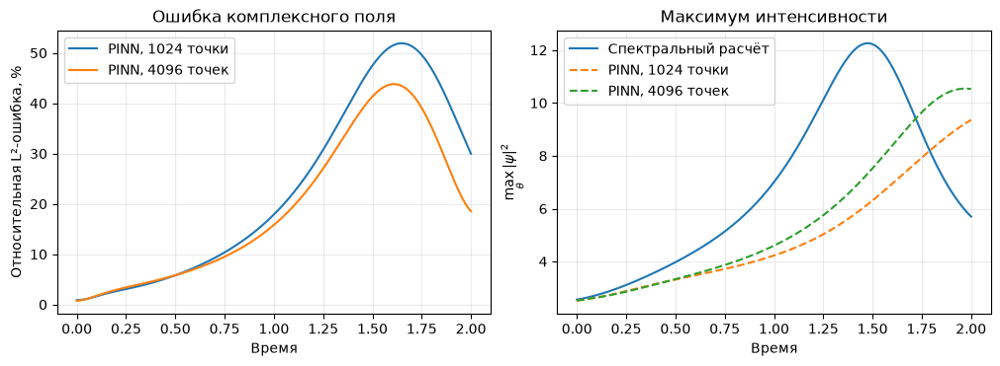

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[1].plot(reference_t2.times, reference_t2.intensity.values.max(axis=1),
             label="Спектральный расчёт")
for label, evolution, error_by_time in (
    ("PINN, 1024 точки", pinn_t2, t2_error),
    ("PINN, 4096 точек", pinn_t2_4096, t2_error_4096),
):
    axes[0].plot(evolution.times, 100 * error_by_time, label=label)
    axes[1].plot(evolution.times, evolution.intensity.values.max(axis=1), "--", label=label)
axes[0].set(title="Ошибка комплексного поля", xlabel="Время", ylabel="Относительная L²-ошибка, %")
axes[1].set(title="Максимум интенсивности", xlabel="Время", ylabel=r"$\max_\theta |\psi|^2$")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.show()

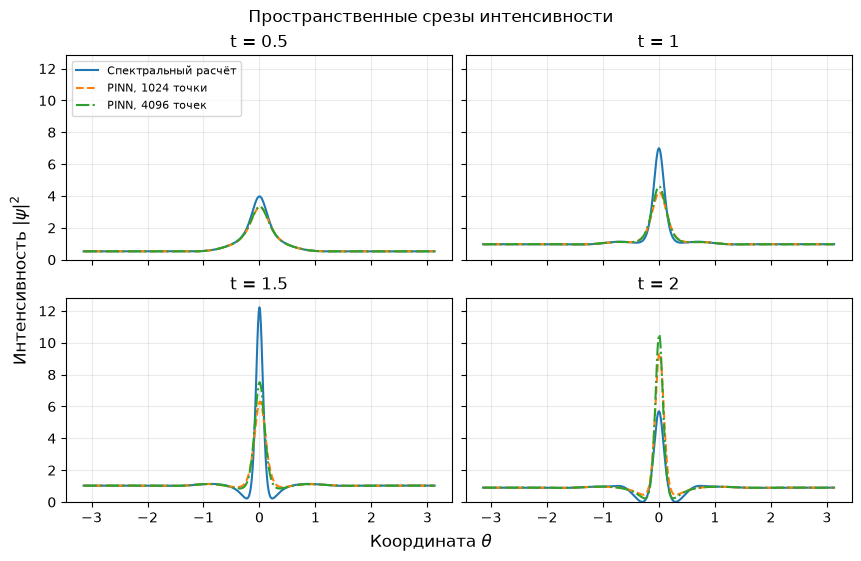

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(8.5, 5.5), sharex=True, sharey=True,
                         layout="constrained")
fig.suptitle("Пространственные срезы интенсивности")
profiles = (
    (reference_t2, "Спектральный расчёт", "-"),
    (pinn_t2, "PINN, 1024 точки", "--"),
    (pinn_t2_4096, "PINN, 4096 точек", "-."),
)
for ax, time in zip(axes.flat, t2_slice_times):
    for evolution, label, style in profiles:
        profile = evolution.at_time(time).intensity
        ax.plot(profile.theta, profile.values, style, label=label)
    ax.set_title(f"t = {time:g}")
    ax.grid(alpha=0.25)
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supxlabel(r"Координата $\theta$")
fig.supylabel(r"Интенсивность $|\psi|^2$")
plt.show()

### История функции потерь

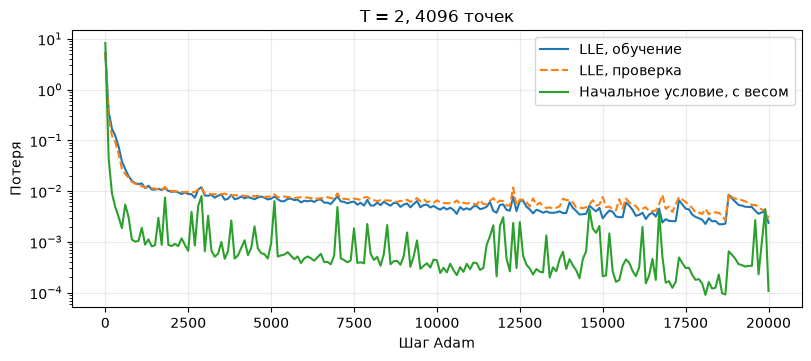

In [48]:
fig = plot_loss_history(PINN_T2_4096_RUN_ID, "T = 2, 4096 точек")
plt.show()

## Варианты PINN при фиксированном числе точек

Контроль для всех вариантов — прогон `2026-11-09_05-04-52_453080` на $[0,2]$ с 1024 внутренними точками, четырьмя слоями по 64 нейрона, четырьмя пространственными гармониками и фиксированными весами. Спектральный эталон — `2026-11-09_05-03-32_207710`. В каждом прогоне меняется один фактор.

In [49]:
def compare_t2_variant(run_id, label, baseline, reference, baseline_label="Базовая PINN"):
    variant = load_evolution(get_run(run_id).path)
    if not np.array_equal(variant.theta, reference.theta) or (
        variant.times.shape != reference.times.shape
        or not np.allclose(variant.times, reference.times, rtol=0, atol=1e-10)
    ):
        raise ValueError("Для сравнения нужны совпадающие сетки и моменты записи")

    profiles = (
        (reference, "Спектральный расчёт", "-"),
        (baseline, baseline_label, "--"),
        (variant, label, "-."),
    )
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
    for evolution, name, style in profiles:
        peaks = evolution.intensity.values.max(axis=1)
        axes[1].plot(evolution.times, peaks, style, label=name)
        if evolution is not reference:
            error = relative_l2_error(evolution.values, reference.values)
            axes[0].plot(evolution.times, 100 * error, style, label=name)
            print(f"{name}: максимальная ошибка поля — {error.max():.2%}")
        peak_index = peaks.argmax()
        print(f"{name}: максимум {peaks[peak_index]:.4f} при t={evolution.times[peak_index]:g}, "
              f"пик при t=2 — {peaks[-1]:.4f}")
    axes[0].set(title="Ошибка комплексного поля", xlabel="Время", ylabel="Относительная L²-ошибка, %")
    axes[1].set(title="Максимум интенсивности", xlabel="Время", ylabel=r"$\max_\theta |\psi|^2$")
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.25)
    plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(8.5, 5.5), sharex=True, sharey=True,
                             layout="constrained")
    fig.suptitle("Пространственные срезы интенсивности")
    for ax, time in zip(axes.flat, (0.5, 1.0, 1.5, 2.0)):
        for evolution, name, style in profiles:
            profile = evolution.at_time(time).intensity
            ax.plot(profile.theta, profile.values, style, label=name)
        ax.set_title(f"t = {time:g}")
        ax.grid(alpha=0.25)
    axes[0, 0].set_ylim(bottom=0)
    axes[0, 0].legend(loc="upper left", fontsize=8)
    fig.supxlabel(r"Координата $\theta$")
    fig.supylabel(r"Интенсивность $|\psi|^2$")
    plt.show()

### 12 Фурье-гармоник

```powershell
$env:DDE_BACKEND = "pytorch"
uv run --no-sync lle pinn train --config experiments/05_pinn-single-soliton/pinn_config.yaml domain.time_end=2.0 recording.interval=0.01 domain.interior_points=1024 network.spatial_harmonics=12
```

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN: максимальная ошибка поля — 51.92%
Базовая PINN: максимум 9.3558 при t=2, пик при t=2 — 9.3558
12 Фурье-гармоник: максимальная ошибка поля — 51.38%
12 Фурье-гармоник: максимум 9.7880 при t=2, пик при t=2 — 9.7880


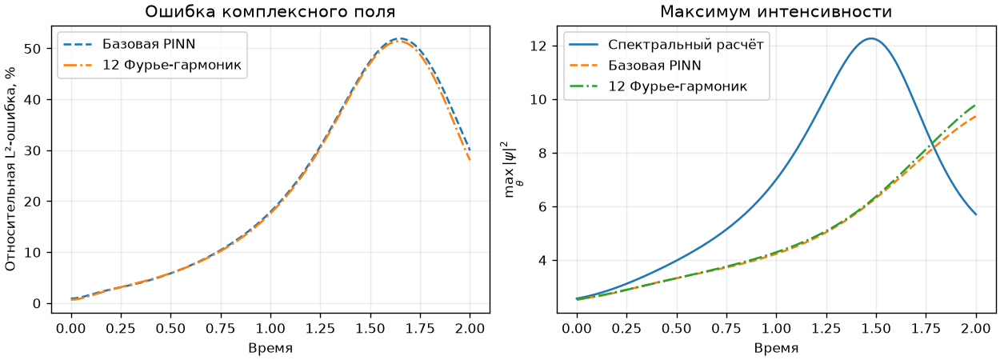

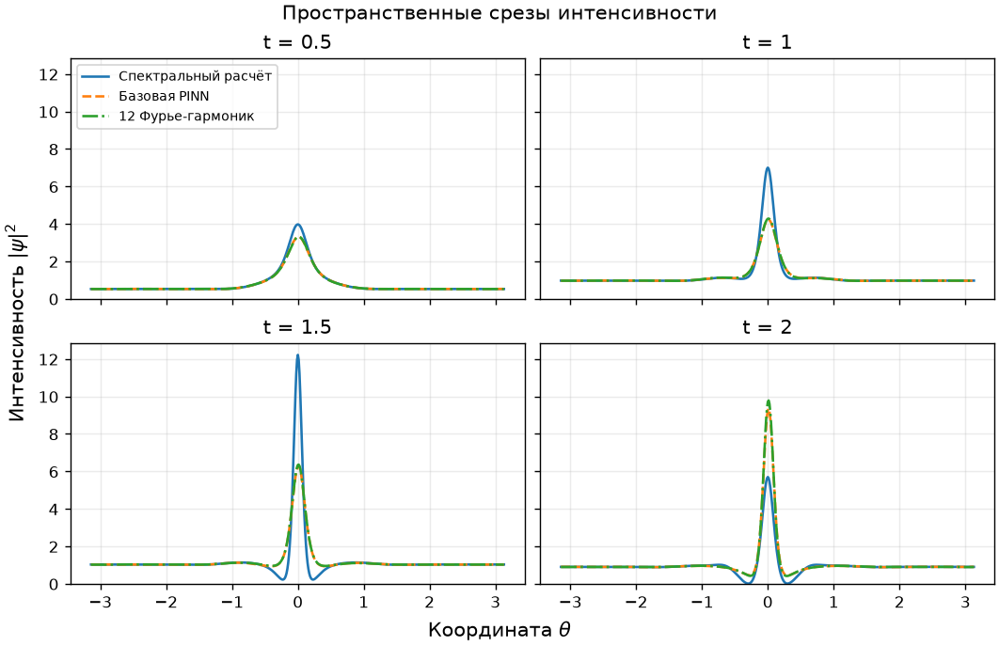

In [50]:
FOURIER12_RUN_ID = "2026-11-09_07-42-22_585534"
compare_t2_variant(FOURIER12_RUN_ID, "12 Фурье-гармоник", pinn_t2, reference_t2)

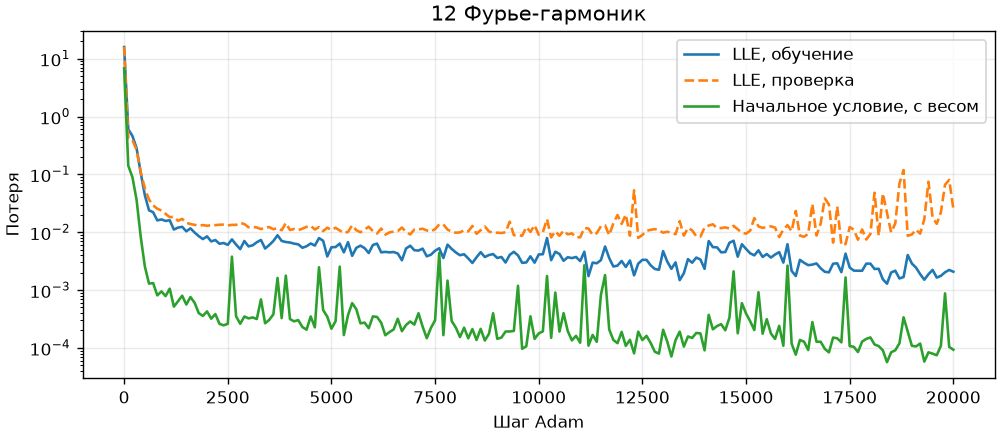

In [51]:
fig = plot_loss_history(FOURIER12_RUN_ID, "12 Фурье-гармоник")
plt.show()

### Ширина сети 128

```powershell
$env:DDE_BACKEND = "pytorch"
uv run --no-sync lle pinn train --config experiments/05_pinn-single-soliton/pinn_config.yaml domain.time_end=2.0 recording.interval=0.01 domain.interior_points=1024 network.hidden_width=128
```

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN: максимальная ошибка поля — 51.92%
Базовая PINN: максимум 9.3558 при t=2, пик при t=2 — 9.3558
Ширина сети 128: максимальная ошибка поля — 60.41%
Ширина сети 128: максимум 7.8084 при t=2, пик при t=2 — 7.8084


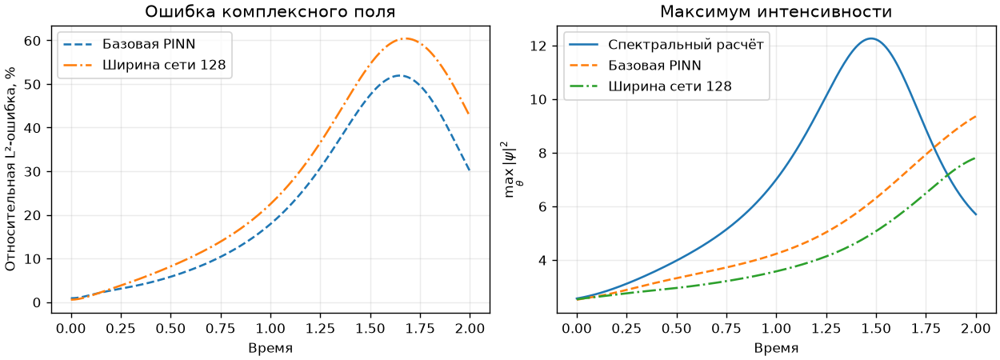

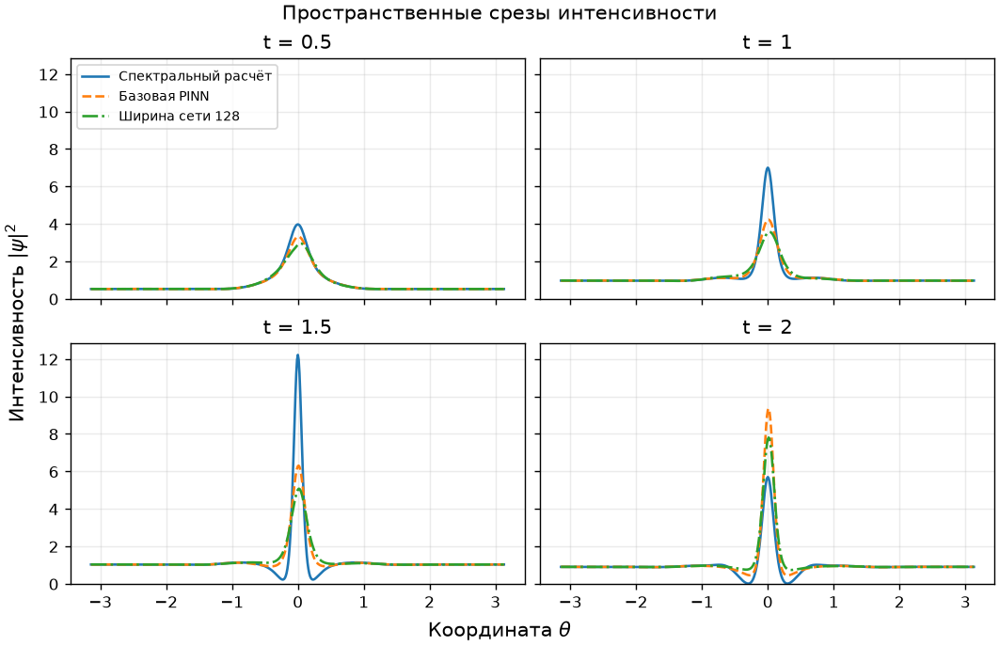

In [52]:
WIDTH128_RUN_ID = "2026-11-09_07-42-22_672514"
compare_t2_variant(WIDTH128_RUN_ID, "Ширина сети 128", pinn_t2, reference_t2)

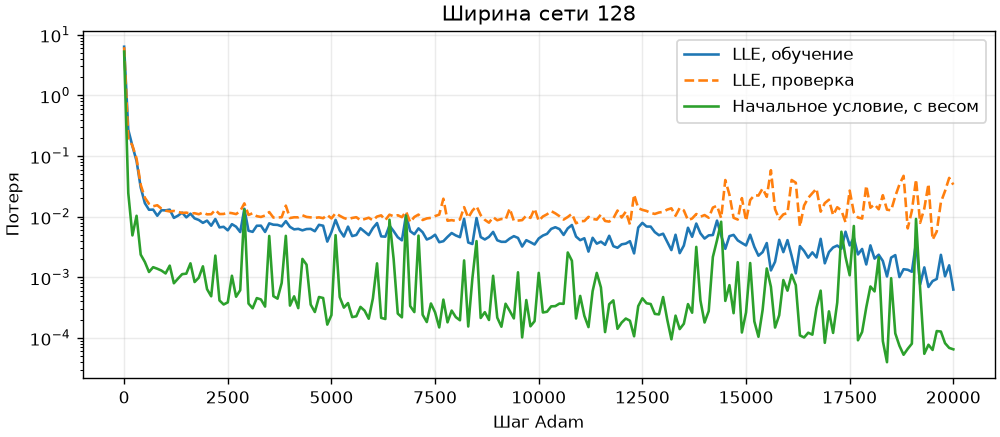

In [53]:
fig = plot_loss_history(WIDTH128_RUN_ID, "Ширина сети 128")
plt.show()

### ReLoBRaLo

Веса обеих групп стартуют с 1. После первого шага ReLoBRaLo обновляет их по относительному изменению потерь.

```powershell
$env:DDE_BACKEND = "pytorch"
uv run --no-sync lle pinn train --config experiments/05_pinn-single-soliton/pinn_config.yaml domain.time_end=2.0 recording.interval=0.01 domain.interior_points=1024 'loss.relobralo={}'
```

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN: максимальная ошибка поля — 51.92%
Базовая PINN: максимум 9.3558 при t=2, пик при t=2 — 9.3558
ReLoBRaLo: максимальная ошибка поля — 62.99%
ReLoBRaLo: максимум 7.1097 при t=2, пик при t=2 — 7.1097


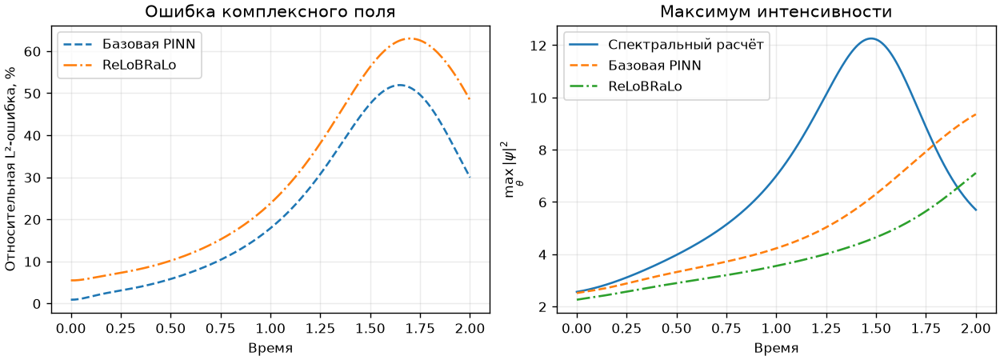

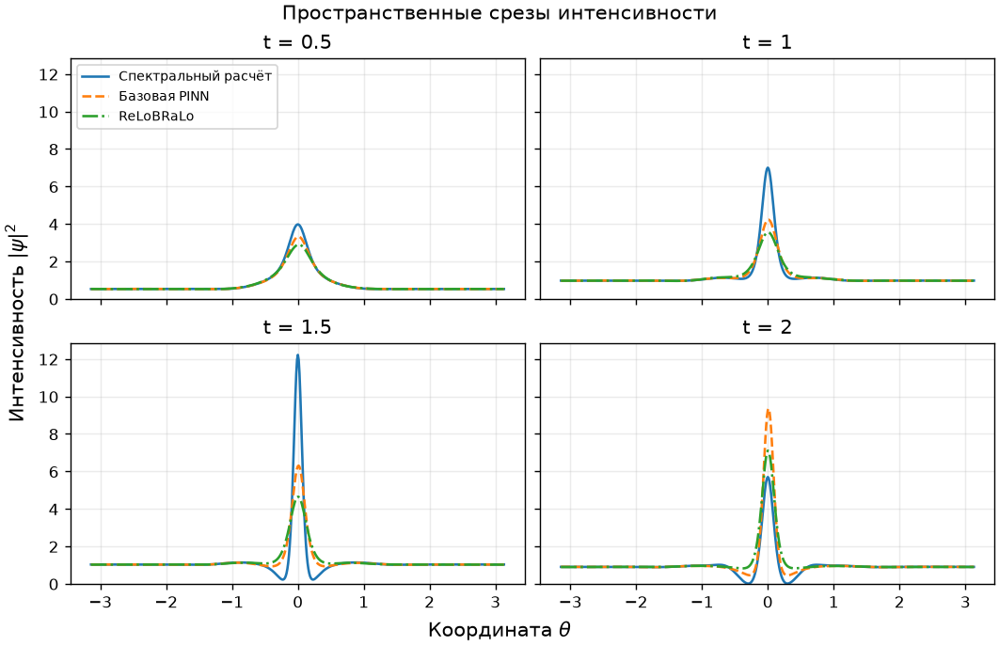

In [57]:
RELOBRALO_RUN_ID = "2026-11-09_08-36-06_835749"
compare_t2_variant(RELOBRALO_RUN_ID, "ReLoBRaLo", pinn_t2, reference_t2)

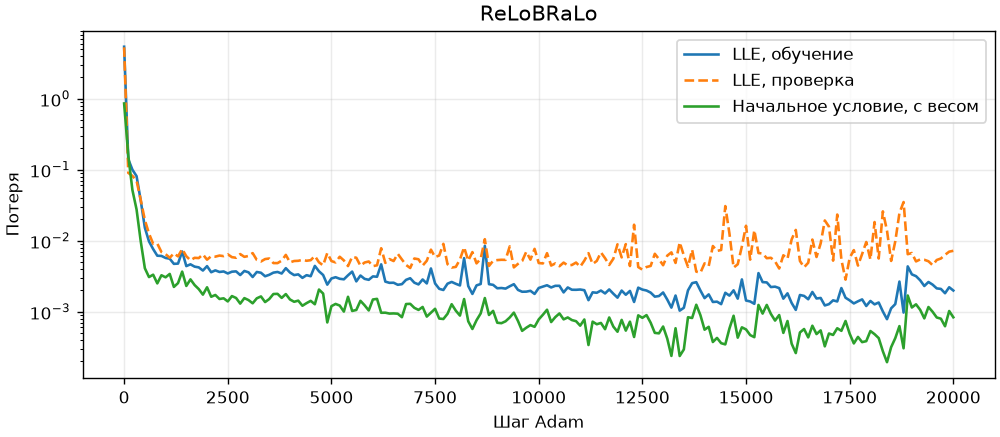

In [58]:
fig = plot_loss_history(RELOBRALO_RUN_ID, "ReLoBRaLo")
plt.show()

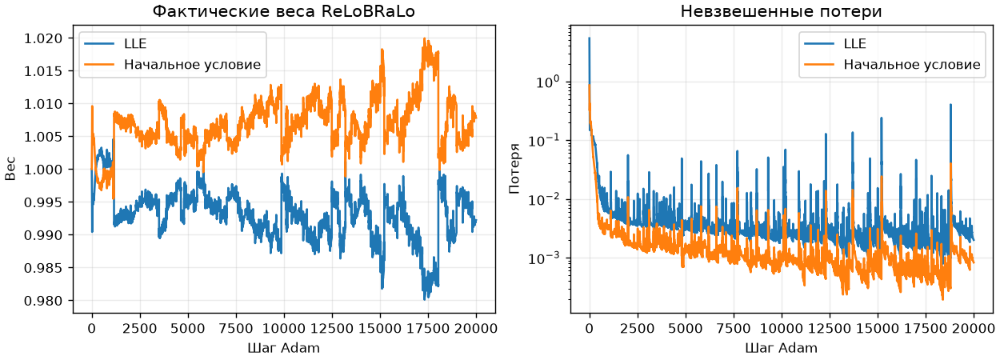

In [59]:
weights = np.genfromtxt(get_run(RELOBRALO_RUN_ID).path / "loss_weights.csv",
                        delimiter=",", names=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].plot(weights["step"], weights["weight_pde"], label="LLE")
axes[0].plot(weights["step"], weights["weight_ic"], label="Начальное условие")
axes[0].set(title="Фактические веса ReLoBRaLo", xlabel="Шаг Adam", ylabel="Вес")
axes[1].semilogy(weights["step"], weights["raw_pde"], label="LLE")
axes[1].semilogy(weights["step"], weights["raw_ic"], label="Начальное условие")
axes[1].set(title="Невзвешенные потери", xlabel="Шаг Adam", ylabel="Потеря")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.show()

## Карты невязки LLE на $[0,2]$

Для каждой сохранённой модели пересчитываем $|r|=\sqrt{r_u^2+r_v^2}$ по автоматическим производным. Используем 256 пространственных узлов спектральной сетки и все 201 сохранённый момент времени. Карты имеют общую логарифмическую цветовую шкалу и показывают невязку уравнения до взвешивания.

In [60]:
import os

os.environ.setdefault("DDE_BACKEND", "pytorch")
import deepxde as dde
import torch
from matplotlib.colors import LogNorm

from lle.workflows.pinn_gaussian.config import PinnGaussianConfig

if dde.backend.backend_name != "pytorch":
    raise RuntimeError("Для карт невязки нужен бэкенд PyTorch")

from lle.pinn.model import build_network, lle_residual, evaluate_residual
from lle.pinn.features import PeriodicFeatures
from lle.physics.equation import LLEParameters
residual_theta = reference_t2.theta[::2]
residual_times = reference_t2.times
theta_grid, time_grid = np.meshgrid(residual_theta, residual_times)
residual_points = np.column_stack((theta_grid.ravel(), time_grid.ravel()))


def load_pinn_for_diagnostics(run_id):
    run = get_run(run_id)
    config = run.load_config(PinnGaussianConfig)
    features = PeriodicFeatures(config.domain.length, config.domain.time_end, config.network.spatial_harmonics)
    net = build_network(input_size=features.output_size,
                        hidden_layers=config.network.hidden_layers,
                        hidden_width=config.network.hidden_width)
    net.apply_feature_transform(features)
    equation = LLEParameters(**config.equation.model_dump())
    checkpoint = torch.load(run.path / "model.pt", map_location="cpu", weights_only=True)
    net.load_state_dict(checkpoint["model_state_dict"])
    return net, equation


def evaluate_residual_map(run_id):
    net, equation = load_pinn_for_diagnostics(run_id)
    residual = lle_residual(equation)
    blocks = []
    for start in range(0, len(residual_points), 2048):
        points = residual_points[start:start + 2048]
        r_u, r_v = evaluate_residual(net, points, residual)
        blocks.append(np.hypot(r_u, r_v).ravel())
    return np.concatenate(blocks).reshape(time_grid.shape)


residual_maps = {
    run_id: evaluate_residual_map(run_id)
    for run_id in (PINN_T2_RUN_ID, PINN_T2_4096_RUN_ID, FOURIER12_RUN_ID,
                   WIDTH128_RUN_ID, RELOBRALO_RUN_ID)
}
residual_norm = LogNorm(vmin=1e-4, vmax=max(values.max() for values in residual_maps.values()))


def plot_residual_map(run_id, title):
    fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
    image = ax.pcolormesh(
        residual_theta, residual_times, residual_maps[run_id], shading="auto",
        cmap="magma", norm=residual_norm,
    )
    ax.set(title=title, xlabel=r"Координата $\theta$", ylabel="Время")
    fig.colorbar(image, ax=ax, label=r"$\sqrt{r_u^2+r_v^2}$", extend="min")
    plt.show()

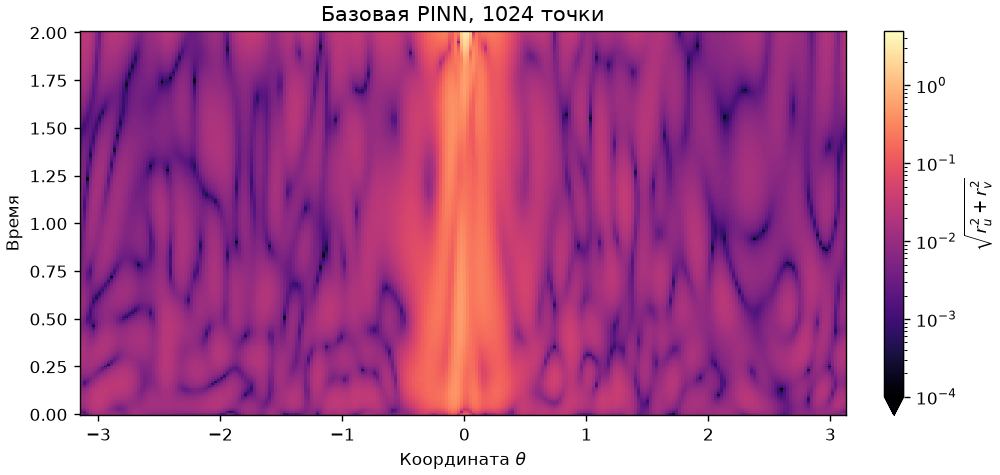

In [61]:
plot_residual_map(PINN_T2_RUN_ID, "Базовая PINN, 1024 точки")

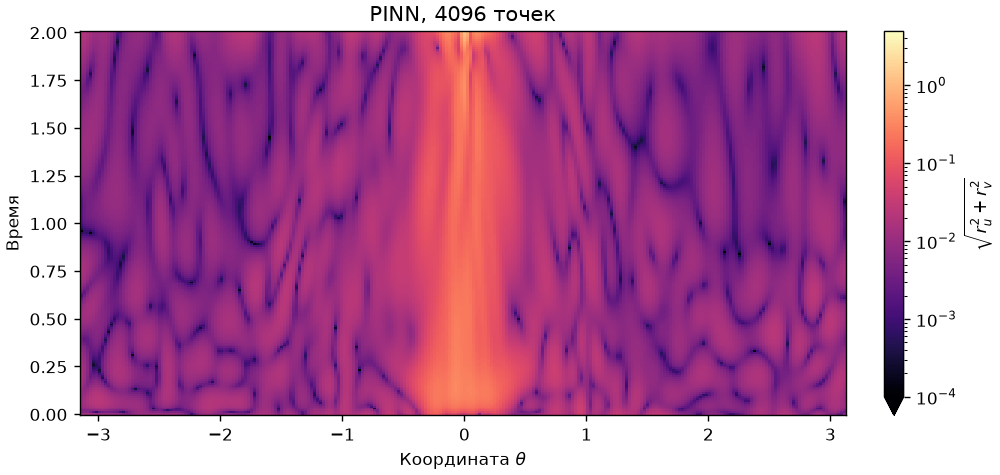

In [62]:
plot_residual_map(PINN_T2_4096_RUN_ID, "PINN, 4096 точек")

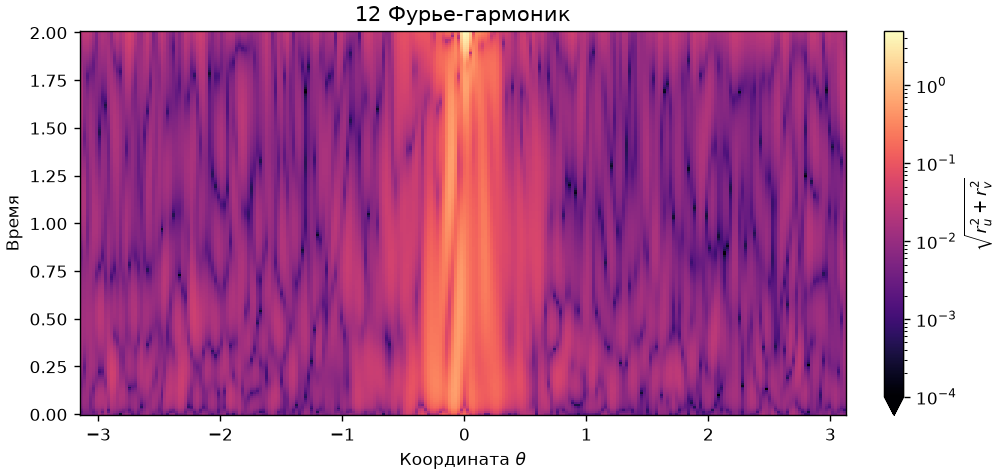

In [63]:
plot_residual_map(FOURIER12_RUN_ID, "12 Фурье-гармоник")

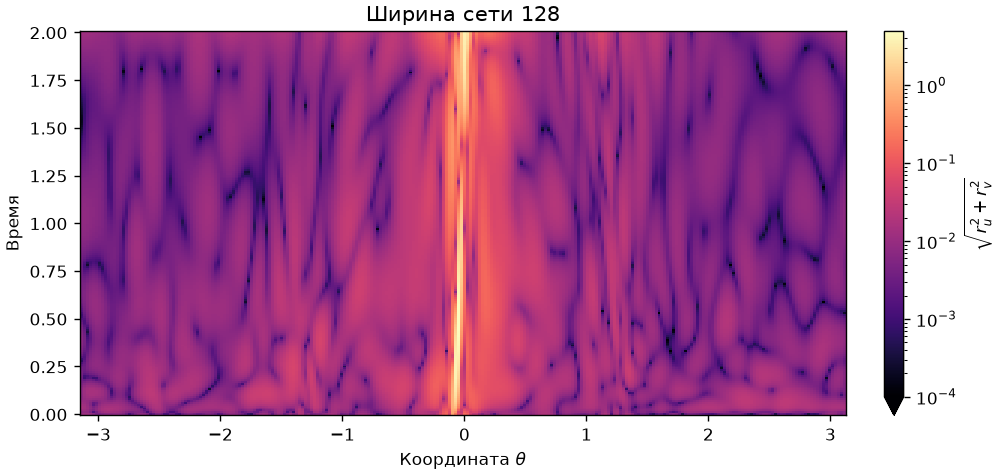

In [64]:
plot_residual_map(WIDTH128_RUN_ID, "Ширина сети 128")

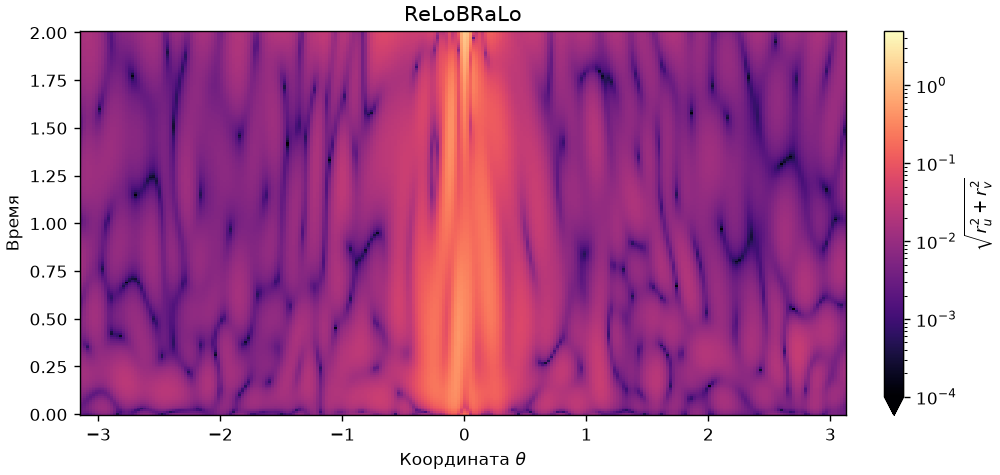

In [65]:
plot_residual_map(RELOBRALO_RUN_ID, "ReLoBRaLo")

## Члены уравнения LLE в области максимальной невязки

Все члены перенесены в левую часть уравнения, поэтому их сумма даёт комплексную невязку. Для каждой модели берём два среза через максимум $|r|$ на её карте. Слева меняется время при фиксированном $	heta$, справа — координата при фиксированном $t$. Верхний ряд показывает вещественную часть, нижний — мнимую. Пространственный срез приближен к месту максимума.

In [66]:
def plot_lle_terms(run_id, title):
    net, equation = load_pinn_for_diagnostics(run_id)
    magnitude = residual_maps[run_id]
    time_index, theta_index = np.unravel_index(magnitude.argmax(), magnitude.shape)
    peak_theta = residual_theta[theta_index]
    peak_time = residual_times[time_index]

    def lle_terms(points, field):
        psi = torch.complex(field[:, :1], field[:, 1:2])
        psi_t = torch.complex(
            dde.grad.jacobian(field, points, i=0, j=1),
            dde.grad.jacobian(field, points, i=1, j=1),
        )
        psi_theta2 = torch.complex(
            dde.grad.hessian(field, points, component=0, i=0, j=0),
            dde.grad.hessian(field, points, component=1, i=0, j=0),
        )
        return torch.cat((
            psi_t,
            psi,
            1j * equation.detuning * psi,
            torch.full_like(psi, -equation.pump_amplitude),
            1j * equation.beta2 / 2 * psi_theta2,
            -1j * psi.abs().square() * psi,
        ), dim=1)

    time_slice = np.column_stack((np.full_like(residual_times, peak_theta), residual_times))
    space_slice = np.column_stack((residual_theta, np.full_like(residual_theta, peak_time)))
    time_terms = evaluate_residual(net, time_slice, lambda points, field: [lle_terms(points, field)])[0]
    space_terms = evaluate_residual(net, space_slice, lambda points, field: [lle_terms(points, field)])[0]
    time_sum = time_terms.sum(axis=1)
    space_sum = space_terms.sum(axis=1)
    np.testing.assert_allclose(np.abs(time_sum), magnitude[:, theta_index], atol=5e-5, rtol=5e-5)
    np.testing.assert_allclose(np.abs(space_sum), magnitude[time_index], atol=5e-5, rtol=5e-5)

    labels = (
        r"$\partial_t\psi$",
        r"$\psi$",
        r"$i\Delta\psi$",
        r"$-F$",
        r"$i(\beta_2/2)\,\partial_{\theta\theta}\psi$",
        r"$-i|\psi|^2\psi$",
    )
    fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex="col", sharey="row",
                             layout="constrained")
    fig.suptitle(title)
    slices = (
        (residual_times, time_terms, time_sum, peak_time, "Время"),
        (residual_theta, space_terms, space_sum, peak_theta, r"Координата $\theta$"),
    )
    for column, (coordinate, terms, total, peak, xlabel) in enumerate(slices):
        for row, (part, ylabel) in enumerate(((np.real, "Вещественная часть"),
                                              (np.imag, "Мнимая часть"))):
            ax = axes[row, column]
            for term, label in zip(terms.T, labels):
                ax.plot(coordinate, part(term), label=label)
            ax.plot(coordinate, part(total), "k--", linewidth=1.7, label="Невязка")
            ax.axvline(peak, color="0.6", linestyle=":", linewidth=1)
            ax.grid(alpha=0.2)
            if column == 0:
                ax.set_ylabel(ylabel)
        axes[1, column].set_xlabel(xlabel)
    axes[0, 0].set_title(rf"По времени при $\theta={peak_theta:.3g}$")
    axes[0, 1].set_title(rf"По координате при $t={peak_time:g}$")
    axes[0, 1].set_xlim(peak_theta - 0.65, peak_theta + 0.65)
    handles, legend_labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="outside lower center", ncols=7, frameon=False)
    plt.show()

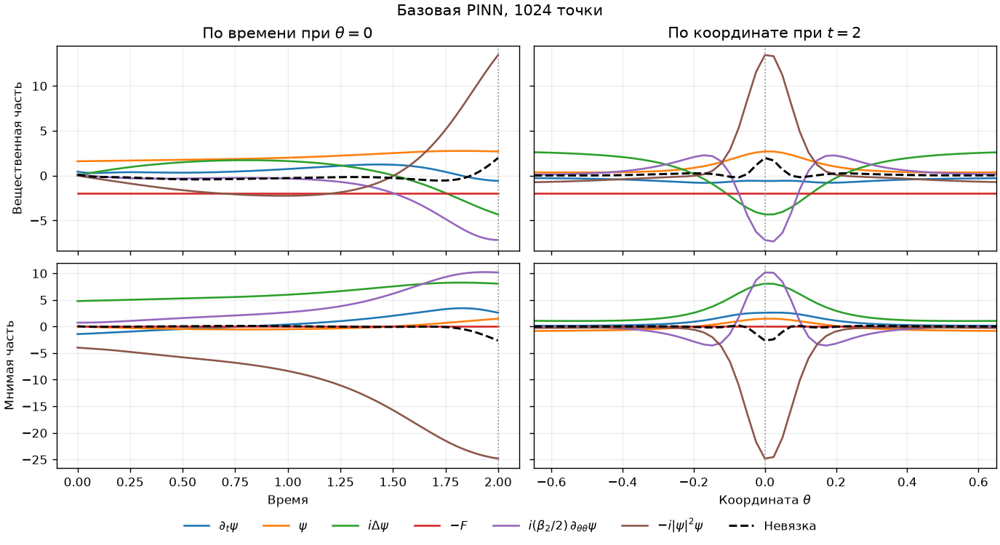

In [67]:
plot_lle_terms(PINN_T2_RUN_ID, "Базовая PINN, 1024 точки")

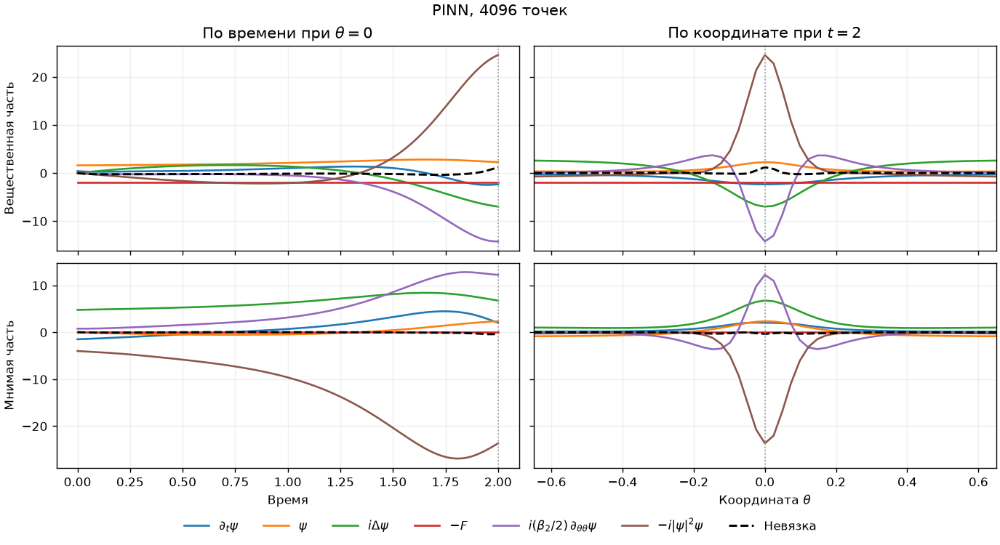

In [68]:
plot_lle_terms(PINN_T2_4096_RUN_ID, "PINN, 4096 точек")

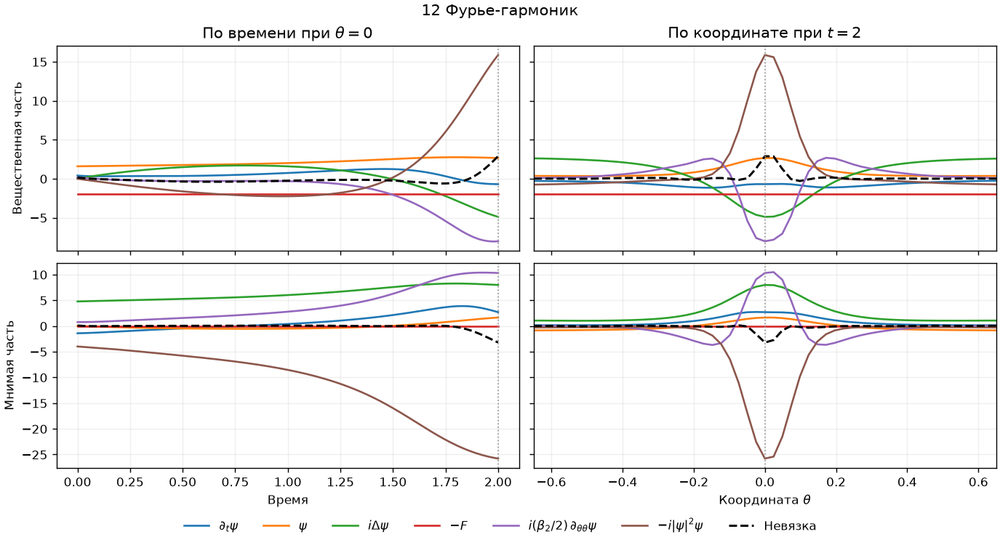

In [69]:
plot_lle_terms(FOURIER12_RUN_ID, "12 Фурье-гармоник")

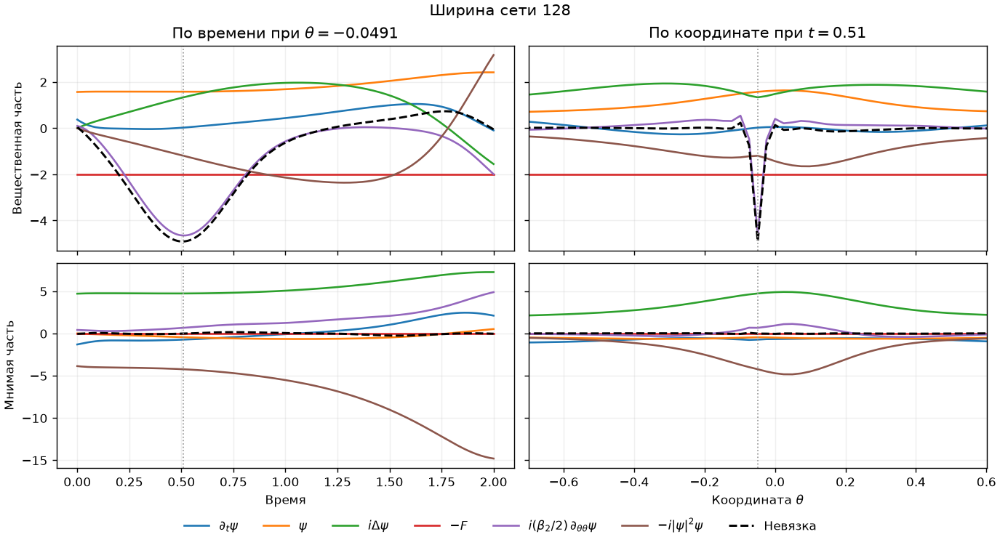

In [70]:
plot_lle_terms(WIDTH128_RUN_ID, "Ширина сети 128")

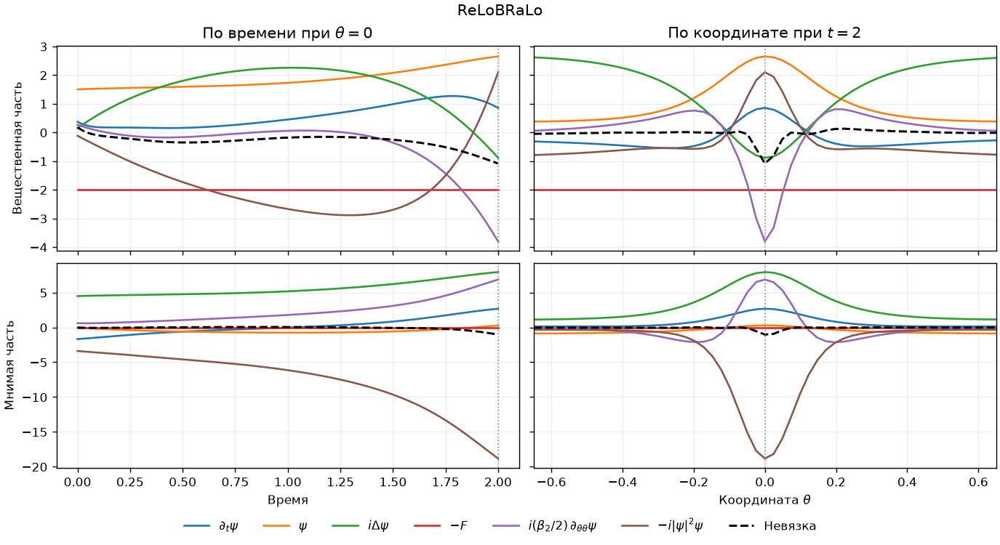

In [71]:
plot_lle_terms(RELOBRALO_RUN_ID, "ReLoBRaLo")

## Причинное взвешивание невязки на $[0,2]$

Контроль — базовый прогон `2026-11-09_05-04-52_453080` с 1024 внутренними точками. Равномерная выборка, архитектура и коэффициент 10 при начальном условии сохраняются.

Интервал делим на четыре полосы по $0.5$. Для каждой полосы считаем среднее $R_j$ от $r_u^2+r_v^2$. Используем $w_1=1$, $w_j=\exp(-\varepsilon\sum_{i<j}R_i)$ и стартовое $\varepsilon=1$. Веса пересчитываются на каждом шаге Adam, градиент через них отключён. [Исходная работа](https://doi.org/10.1016/j.cma.2024.116813)

```powershell
$env:DDE_BACKEND = "pytorch"
uv run --no-sync lle pinn train --config experiments/05_pinn-single-soliton/pinn_config.yaml domain.time_end=2.0 recording.interval=0.01 domain.interior_points=1024 loss.causal.bands=4 loss.causal.epsilon=1.0
```

В `loss_weights.csv` сохраняются невзвешенные невязки и веса каждой полосы на каждом шаге. В `losses.csv` обучающая невязка LLE взвешена по полосам, а проверочная считается на штатной сетке без причинных весов. Сравнение поля выполняется на прежнем спектральном эталоне `2026-11-09_05-03-32_207710`.

In [72]:
def plot_causal_weights(run_id, label):
    history = np.genfromtxt(get_run(run_id).path / "loss_weights.csv", delimiter=",", names=True)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
    for band in range(1, 5):
        interval = f"Полоса {band}"
        axes[0].plot(history["step"], history[f"weight_band_{band}"], label=interval)
        axes[1].semilogy(history["step"], history[f"raw_band_{band}"], label=interval, alpha=0.8)
    axes[0].set(title="Причинные веса", xlabel="Шаг Adam", ylabel="Вес", ylim=(0, 1.05))
    axes[1].set(title="Невзвешенная невязка по полосам", xlabel="Шаг Adam", ylabel=r"$R_j$")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle(label)
    plt.show()

    last_band = history["weight_band_4"]
    crossings = history["step"][last_band > 0.99]
    first = f"шаг {int(crossings[0])}" if crossings.size else "порог не достигнут"
    print(f"Первое превышение w₄=0.99: {first}")
    print(f"Медиана w₄ за последние 5000 шагов: {np.median(last_band[-5000:]):.3f}")

### Причинные веса, ε = 0.1

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN: максимальная ошибка поля — 51.92%
Базовая PINN: максимум 9.3558 при t=2, пик при t=2 — 9.3558
Причинные веса, ε = 0.1: максимальная ошибка поля — 59.54%
Причинные веса, ε = 0.1: максимум 8.5179 при t=2, пик при t=2 — 8.5179


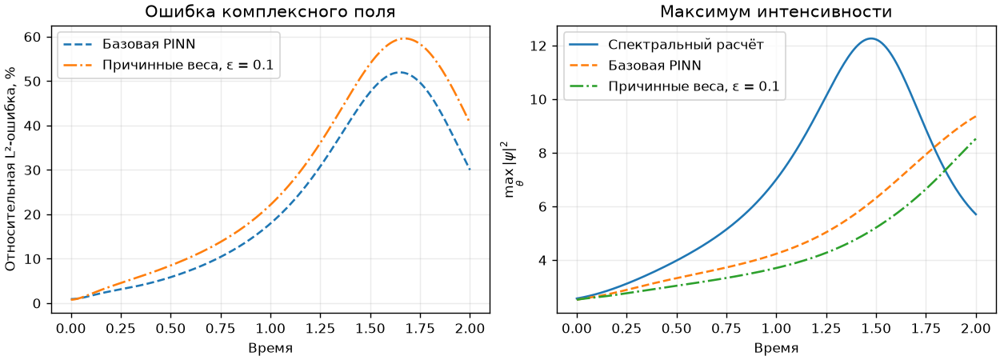

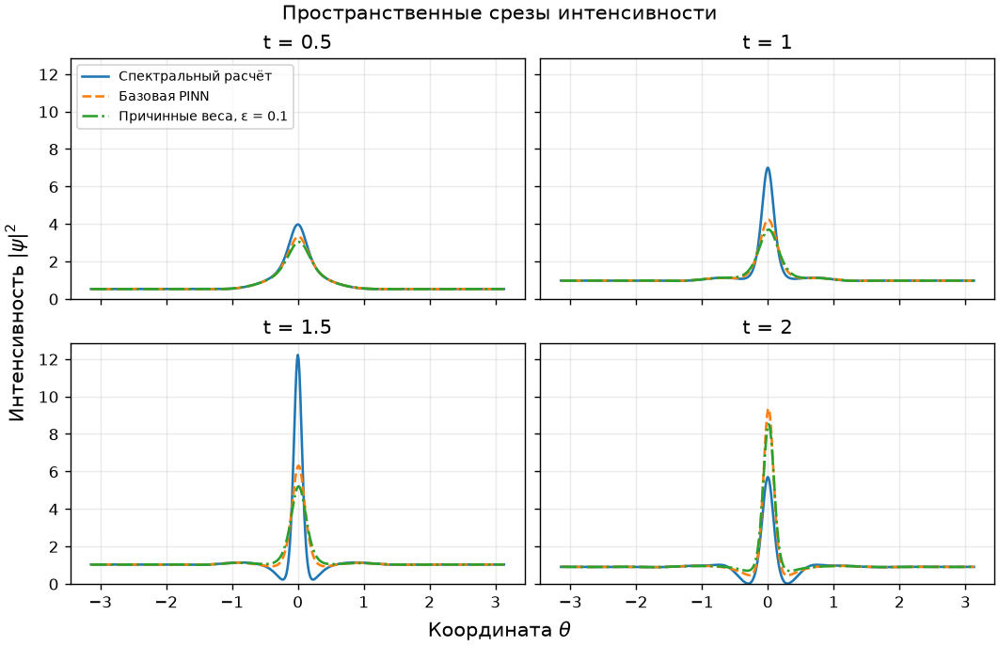

In [73]:
CAUSAL_EPS01_RUN_ID = "2026-11-09_10-55-35_638231"
compare_t2_variant(CAUSAL_EPS01_RUN_ID, "Причинные веса, ε = 0.1", pinn_t2, reference_t2)

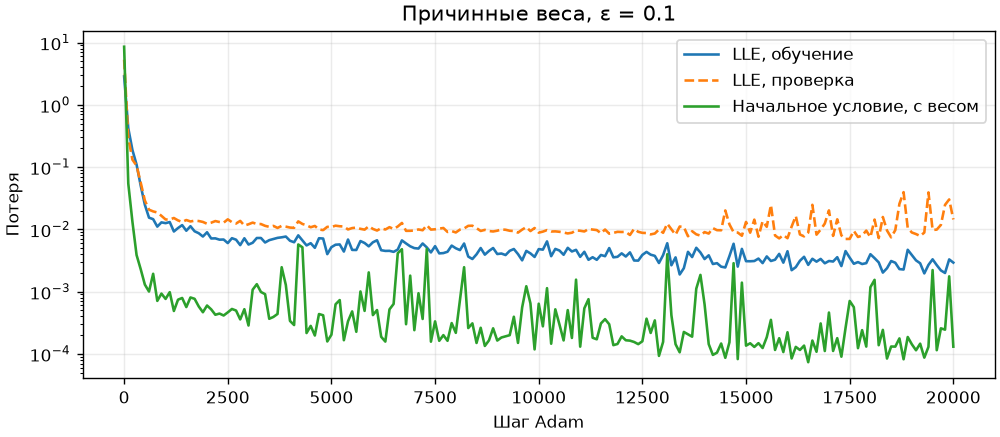

In [74]:
fig = plot_loss_history(CAUSAL_EPS01_RUN_ID, "Причинные веса, ε = 0.1")
plt.show()

Первое превышение w₄=0.99: шаг 468
Медиана w₄ за последние 5000 шагов: 0.999


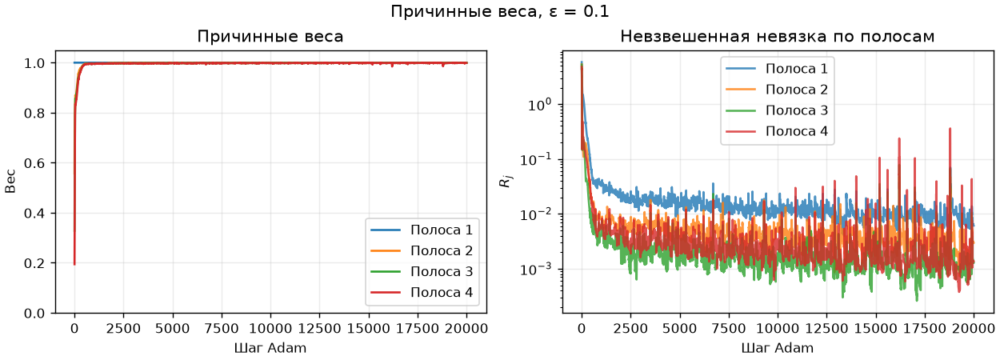

In [75]:
plot_causal_weights(CAUSAL_EPS01_RUN_ID, "Причинные веса, ε = 0.1")

### Причинные веса, ε = 1

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN: максимальная ошибка поля — 51.92%
Базовая PINN: максимум 9.3558 при t=2, пик при t=2 — 9.3558
Причинные веса, ε = 1: максимальная ошибка поля — 57.87%
Причинные веса, ε = 1: максимум 8.8378 при t=2, пик при t=2 — 8.8378


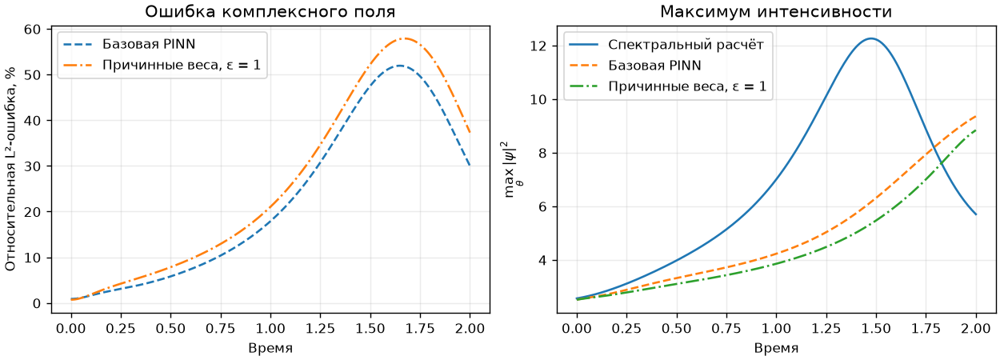

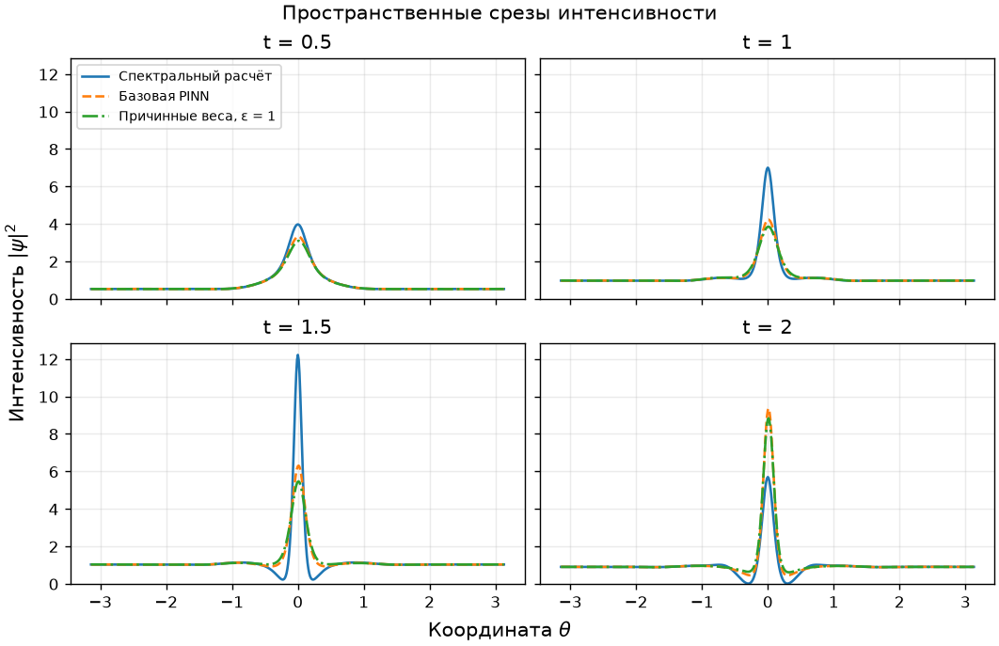

In [76]:
CAUSAL_EPS1_RUN_ID = "2026-11-09_10-45-52_326937"
compare_t2_variant(CAUSAL_EPS1_RUN_ID, "Причинные веса, ε = 1", pinn_t2, reference_t2)

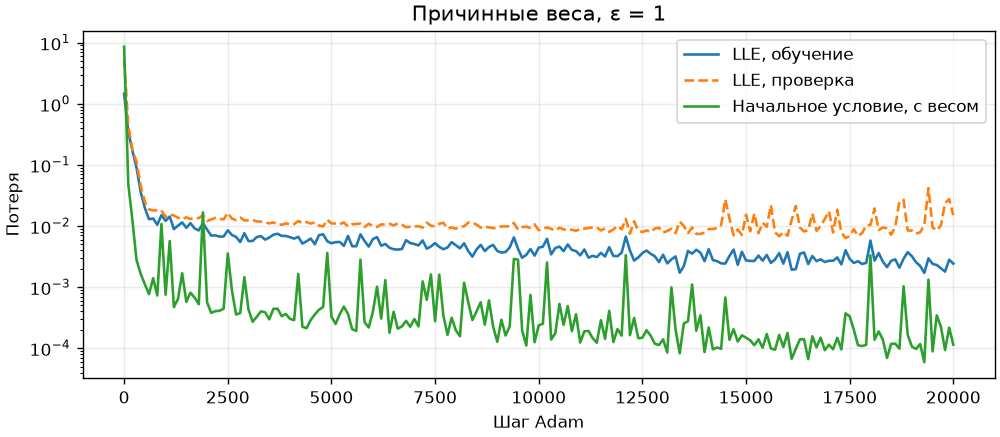

In [77]:
fig = plot_loss_history(CAUSAL_EPS1_RUN_ID, "Причинные веса, ε = 1")
plt.show()

Первое превышение w₄=0.99: шаг 12287
Медиана w₄ за последние 5000 шагов: 0.989


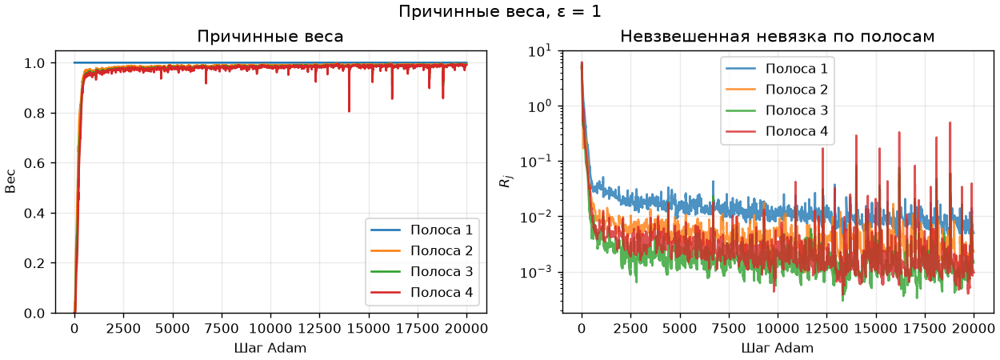

In [78]:
plot_causal_weights(CAUSAL_EPS1_RUN_ID, "Причинные веса, ε = 1")

### Причинные веса, ε = 10

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN: максимальная ошибка поля — 51.92%
Базовая PINN: максимум 9.3558 при t=2, пик при t=2 — 9.3558
Причинные веса, ε = 10: максимальная ошибка поля — 58.48%
Причинные веса, ε = 10: максимум 8.8415 при t=2, пик при t=2 — 8.8415


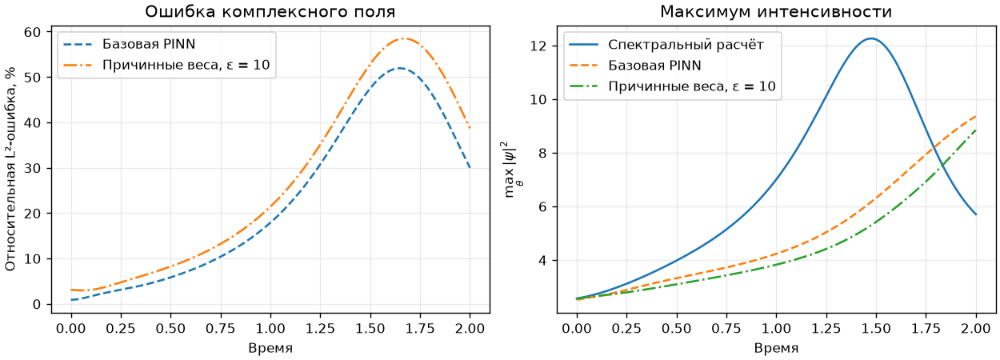

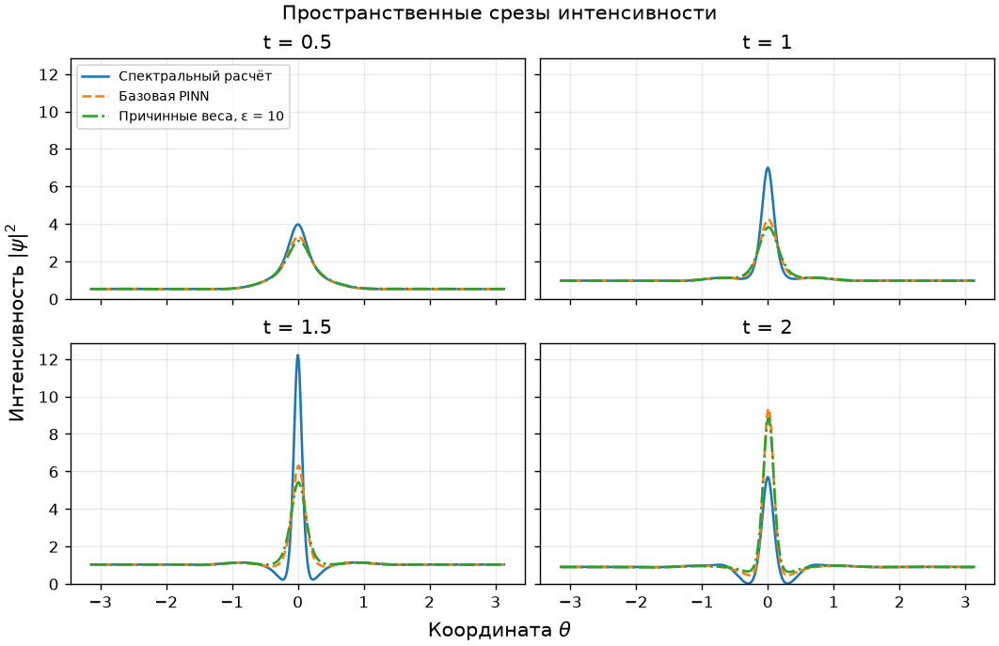

In [79]:
CAUSAL_EPS10_RUN_ID = "2026-11-09_10-55-35_892253"
compare_t2_variant(CAUSAL_EPS10_RUN_ID, "Причинные веса, ε = 10", pinn_t2, reference_t2)

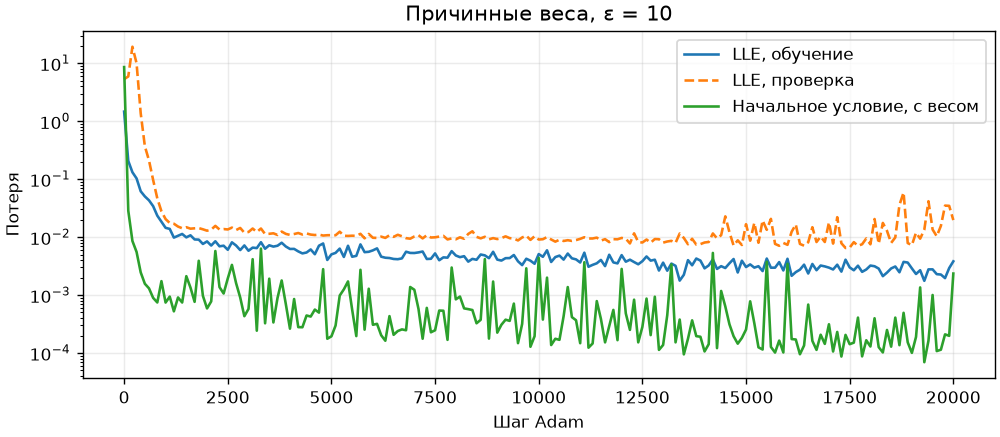

In [80]:
fig = plot_loss_history(CAUSAL_EPS10_RUN_ID, "Причинные веса, ε = 10")
plt.show()

Первое превышение w₄=0.99: порог не достигнут
Медиана w₄ за последние 5000 шагов: 0.889


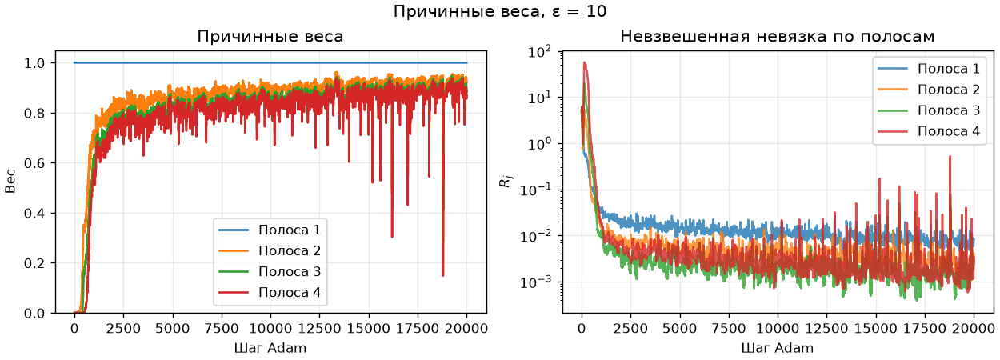

In [81]:
plot_causal_weights(CAUSAL_EPS10_RUN_ID, "Причинные веса, ε = 10")

### Итоги сравнения причинных весов

| Прогон | Ошибка поля при $t=0.5$ | Максимальная ошибка поля | Медиана $w_4$ за последние 5000 шагов |
| --- | ---: | ---: | ---: |
| Базовая PINN | 5,80 % | 51,92 % | — |
| $
arepsilon=0.1$ | 8,44 % | 59,54 % | 0,999 |
| $
arepsilon=1$ | 7,83 % | 57,87 % | 0,989 |
| $
arepsilon=10$ | 8,20 % | 58,48 % | 0,889 |

Увеличение $\varepsilon$ дольше удерживало низкий вес последней полосы. При $\varepsilon=0.1$ вес $w_4$ впервые превысил 0,99 на шаге 468, при $\varepsilon=1$ — на шаге 12 287, а при $\varepsilon=10$ порог за 20 000 шагов не достигнут.

Из трёх причинных прогонов наименьшую максимальную ошибку дал $\varepsilon=1$. У базовой PINN ошибка при $t=0.5$ и максимальная ошибка по всему интервалу ниже, чем у каждого из трёх причинных вариантов. Все три причинных прогона достигают максимума интенсивности при $t=2$, тогда как спектральный пик достигает максимума при $t=1.48$ и затем спадает.

## Причинное взвешивание с расписанием $\varepsilon$

Проверяем порядок из алгоритма 1: $0.01\to0.1\to1\to10\to100$. На каждой стадии переходим дальше, как только $\min_j w_j>0.99$ или пройдены 4000 шагов. Максимальный бюджет — 20 000 шагов. Между стадиями сохраняются параметры сети, состояние Adam и счётчик пересэмплирования. [Wang, Sankaran и Perdikaris](https://arxiv.org/html/2203.07404)

Оставляем ту же LLE, интервал $[0,2]$, четыре временные полосы, 1024 внутренние точки и коэффициент 10 для начального условия. Сравнение с прогонами при фиксированном $\varepsilon$ проверяет изменение расписания при той же функции потерь.

```powershell
$env:DDE_BACKEND = "pytorch"
uv run --no-sync lle pinn train --config experiments/05_pinn-single-soliton/pinn_config.yaml domain.time_end=2.0 recording.interval=0.01 domain.interior_points=1024 loss.causal.bands=4 'loss.causal.schedule={}'
```

В `causal_stages.csv` записываются номер стадии, значение $\varepsilon$, диапазон шагов, минимальный вес и причина перехода. Комплексное поле на границах стадий сохраняется в `stage_01/field_evolution.npz` и последующих каталогах. `loss_weights.csv` содержит общую историю по шагам Adam.

In [82]:
CAUSAL_SCHEDULE_RUN_ID = "2026-11-09_11-24-34_218892"
schedule_run = get_run(CAUSAL_SCHEDULE_RUN_ID)
stages = np.genfromtxt(schedule_run.path / "causal_stages.csv", delimiter=",",
                       names=True, dtype=None, encoding="utf-8")

for stage in stages:
    snapshot = load_evolution(schedule_run.path / f"stage_{stage['number']:02d}")
    stage_error = relative_l2_error(snapshot.values, reference_t2.values)
    peak = snapshot.intensity.values.max(axis=1)
    peak_index = peak.argmax()
    reason = "порог" if stage["reason"] == "threshold" else "лимит шагов"
    print(f"ε={stage['epsilon']:g}, шаги {stage['first_step']}–{stage['last_step']}: "
          f"min(w)={stage['min_weight']:.3f} ({reason}), "
          f"ошибка при t=0.5 — {stage_error[50]:.2%}, максимум ошибки — {stage_error.max():.2%}, "
          f"пик {peak[peak_index]:.2f} при t={snapshot.times[peak_index]:g}")

ε=0.01, шаги 1–158: min(w)=0.990 (порог), ошибка при t=0.5 — 21.09%, максимум ошибки — 80.98%, пик 3.16 при t=0.39
ε=0.1, шаги 159–541: min(w)=0.990 (порог), ошибка при t=0.5 — 17.17%, максимум ошибки — 74.68%, пик 2.51 при t=0.04
ε=1, шаги 542–4541: min(w)=0.981 (лимит шагов), ошибка при t=0.5 — 14.69%, максимум ошибки — 71.71%, пик 3.51 при t=2
ε=10, шаги 4542–8541: min(w)=0.816 (лимит шагов), ошибка при t=0.5 — 10.67%, максимум ошибки — 68.43%, пик 4.82 при t=2
ε=100, шаги 8542–12541: min(w)=0.206 (лимит шагов), ошибка при t=0.5 — 7.97%, максимум ошибки — 61.28%, пик 6.38 при t=2


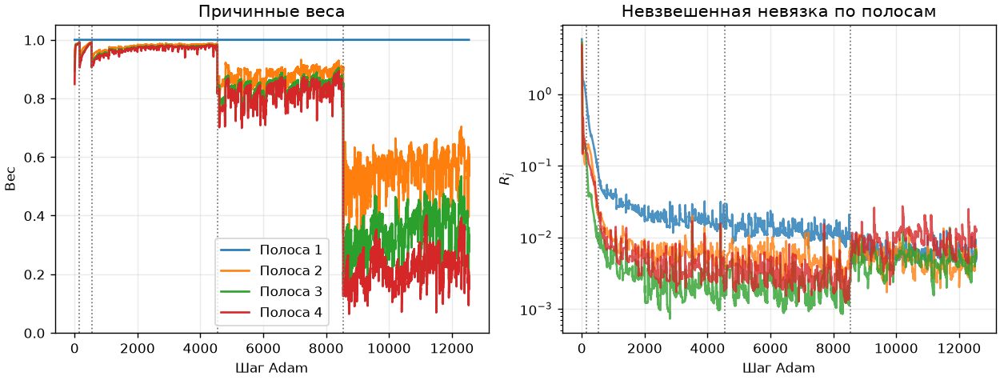

In [83]:
schedule_weights = np.genfromtxt(schedule_run.path / "loss_weights.csv",
                                 delimiter=",", names=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, layout="constrained")
for band in range(1, 5):
    axes[0].plot(schedule_weights["step"], schedule_weights[f"weight_band_{band}"],
                 label=f"Полоса {band}")
    axes[1].semilogy(schedule_weights["step"], schedule_weights[f"raw_band_{band}"], alpha=0.8)
for stage in stages[:-1]:
    for ax in axes:
        ax.axvline(stage["last_step"], color="0.45", linestyle=":", linewidth=1)
axes[0].set(title="Причинные веса", xlabel="Шаг Adam", ylabel="Вес", ylim=(0, 1.05))
axes[1].set(title="Невзвешенная невязка по полосам", xlabel="Шаг Adam", ylabel=r"$R_j$")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN: максимальная ошибка поля — 51.92%
Базовая PINN: максимум 9.3558 при t=2, пик при t=2 — 9.3558
Причинное расписание: максимальная ошибка поля — 61.28%
Причинное расписание: максимум 6.3780 при t=2, пик при t=2 — 6.3780


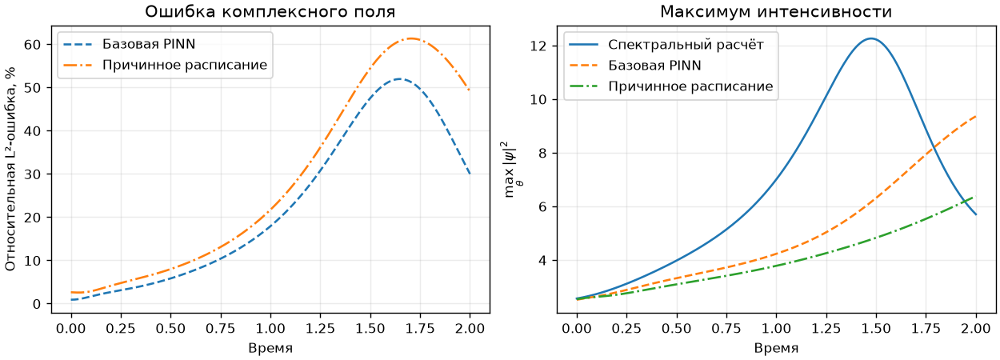

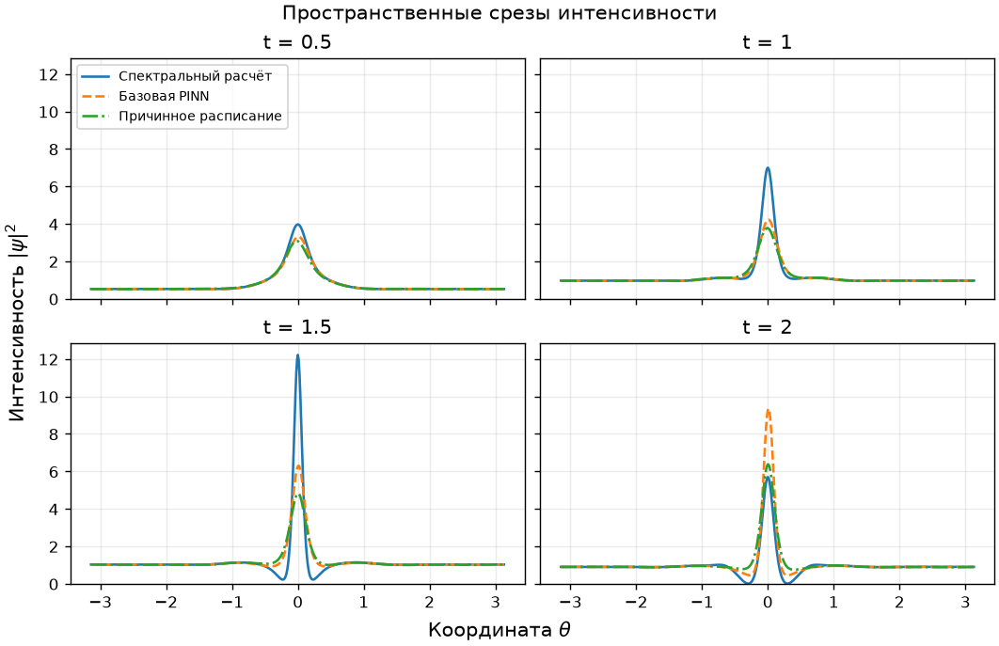

In [84]:
compare_t2_variant(CAUSAL_SCHEDULE_RUN_ID, "Причинное расписание", pinn_t2, reference_t2)

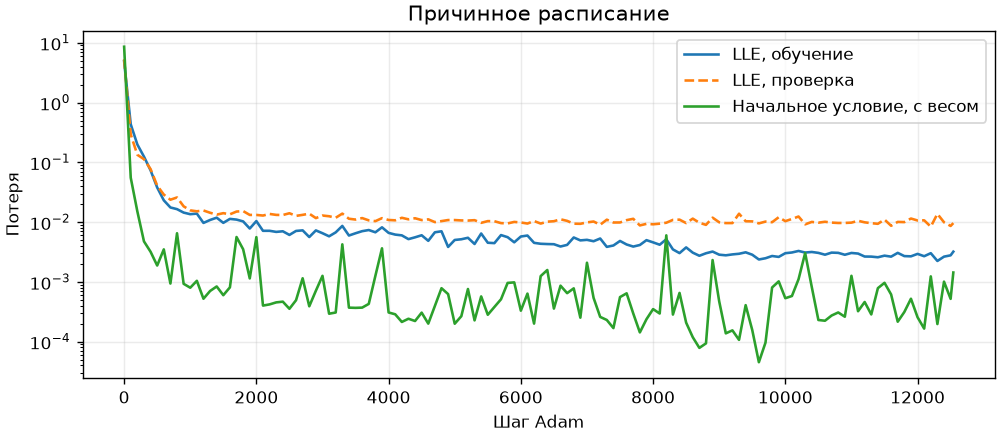

In [85]:
fig = plot_loss_history(CAUSAL_SCHEDULE_RUN_ID, "Причинное расписание")
plt.show()

Первые две стадии завершились по порогу, остальные — по лимиту шагов. Максимальная ошибка по сохранённым стадиям снизилась с 80,98 % до 61,28 %. Итоговая ошибка остаётся выше, чем у базовой PINN (51,92 %) и у лучшего варианта с фиксированным $\varepsilon=1$ (57,87 %). Сравнение проведено при одном максимальном бюджете, а расписание из-за ранних переходов использовало 12 541 шаг из 20 000.

PINN достигает максимума интенсивности 6,38 при $t=2$. Эталон достигает 12,26 при $t=1.48$ и спадает до 5,70 при $t=2$.

## Увеличение бюджета Adam до 40 000 шагов

Оба прогона обучены с нуля на $[0,2]$ с 1024 внутренними точками. Настройки совпадают с соответствующими прогонами при бюджете 20 000. Для расписания лимит стадии увеличен с 4000 до 8000 шагов, а порог $w_{\min}>0.99$ сохранён.

### Базовая PINN

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN, 20 000 шагов: максимальная ошибка поля — 51.92%
Базовая PINN, 20 000 шагов: максимум 9.3558 при t=2, пик при t=2 — 9.3558
Базовая PINN, 40 000 шагов: максимальная ошибка поля — 43.65%
Базовая PINN, 40 000 шагов: максимум 10.4285 при t=1.96, пик при t=2 — 10.3935


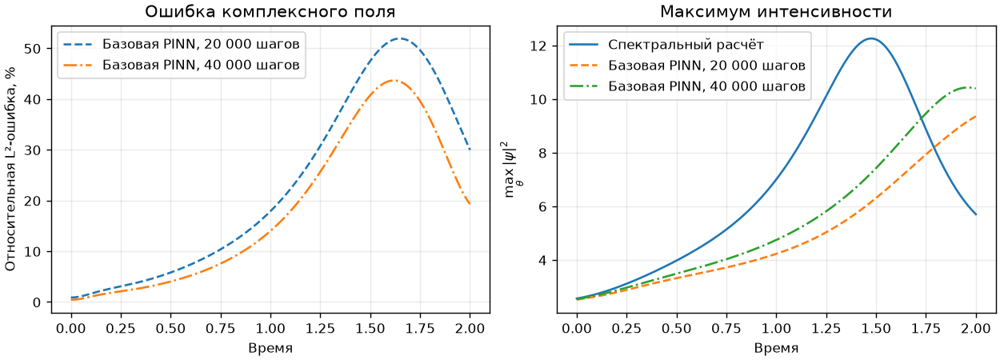

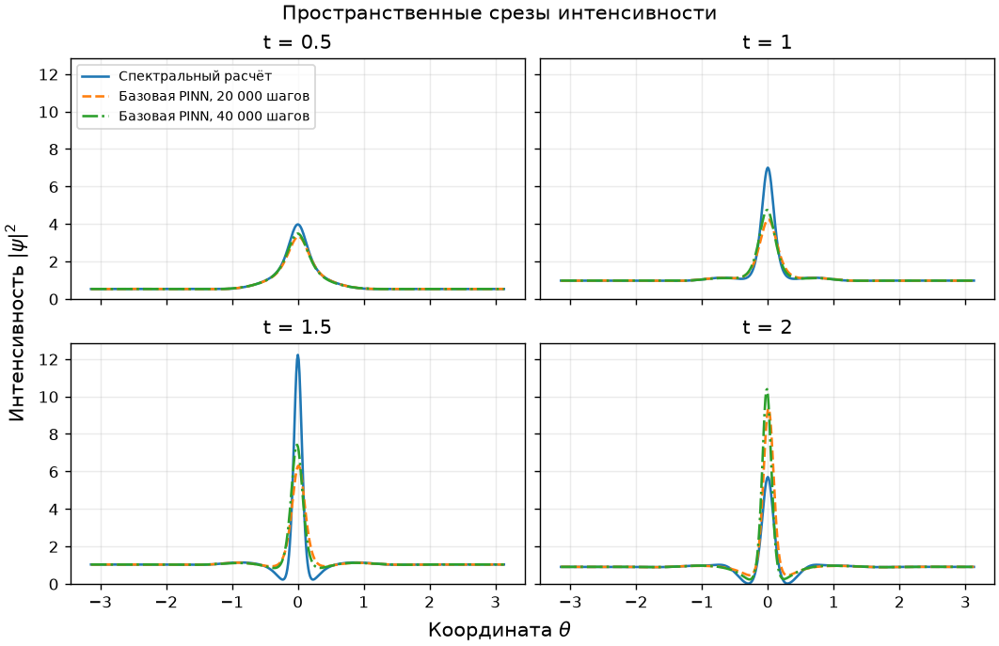

In [86]:
BASELINE40_RUN_ID = "2026-11-09_11-42-23_942678"
compare_t2_variant(BASELINE40_RUN_ID, "Базовая PINN, 40 000 шагов", pinn_t2, reference_t2,
                   baseline_label="Базовая PINN, 20 000 шагов")

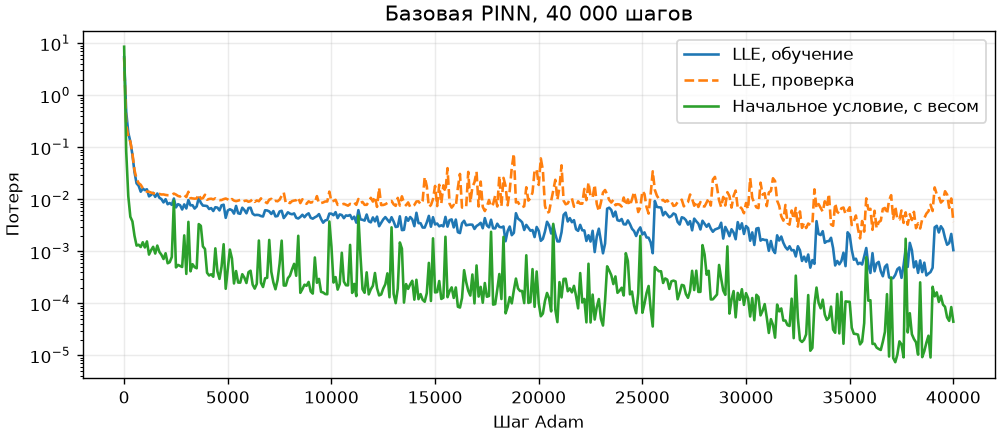

In [87]:
fig = plot_loss_history(BASELINE40_RUN_ID, "Базовая PINN, 40 000 шагов")
plt.show()

### Причинное расписание

In [88]:
CAUSAL_SCHEDULE40_RUN_ID = "2026-11-09_11-42-43_091154"
schedule40_run = get_run(CAUSAL_SCHEDULE40_RUN_ID)
stages40 = np.genfromtxt(schedule40_run.path / "causal_stages.csv", delimiter=",",
                       names=True, dtype=None, encoding="utf-8")

for stage in stages40:
    snapshot = load_evolution(schedule40_run.path / f"stage_{stage['number']:02d}")
    stage_error = relative_l2_error(snapshot.values, reference_t2.values)
    peak = snapshot.intensity.values.max(axis=1)
    peak_index = peak.argmax()
    reason = "порог" if stage["reason"] == "threshold" else "лимит шагов"
    print(f"ε={stage['epsilon']:g}, шаги {stage['first_step']}–{stage['last_step']}: "
          f"min(w)={stage['min_weight']:.3f} ({reason}), "
          f"ошибка при t=0.5 — {stage_error[50]:.2%}, максимум ошибки — {stage_error.max():.2%}, "
          f"пик {peak[peak_index]:.2f} при t={snapshot.times[peak_index]:g}")

ε=0.01, шаги 1–158: min(w)=0.990 (порог), ошибка при t=0.5 — 21.09%, максимум ошибки — 80.98%, пик 3.16 при t=0.39
ε=0.1, шаги 159–541: min(w)=0.990 (порог), ошибка при t=0.5 — 17.17%, максимум ошибки — 74.68%, пик 2.51 при t=0.04
ε=1, шаги 542–8541: min(w)=0.982 (лимит шагов), ошибка при t=0.5 — 11.04%, максимум ошибки — 68.69%, пик 4.73 при t=2
ε=10, шаги 8542–16541: min(w)=0.874 (лимит шагов), ошибка при t=0.5 — 9.66%, максимум ошибки — 62.71%, пик 7.55 при t=2
ε=100, шаги 16542–24541: min(w)=0.736 (лимит шагов), ошибка при t=0.5 — 4.04%, максимум ошибки — 31.98%, пик 10.54 при t=1.81


Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Расписание, лимит 4000: максимальная ошибка поля — 61.28%
Расписание, лимит 4000: максимум 6.3780 при t=2, пик при t=2 — 6.3780
Расписание, лимит 8000: максимальная ошибка поля — 31.98%
Расписание, лимит 8000: максимум 10.5432 при t=1.81, пик при t=2 — 10.0279


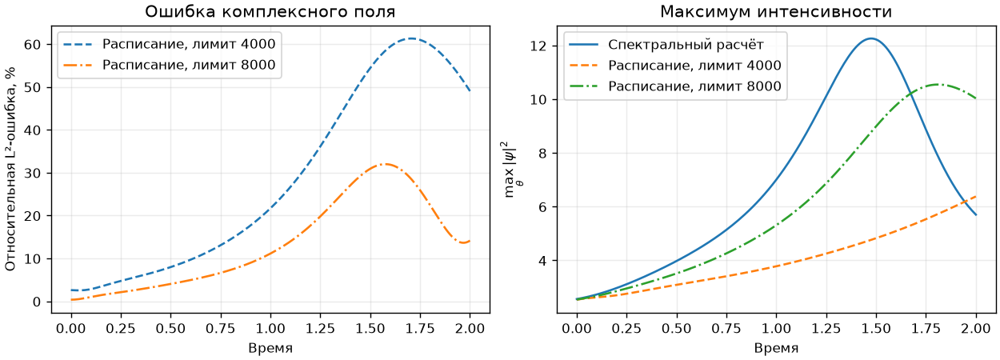

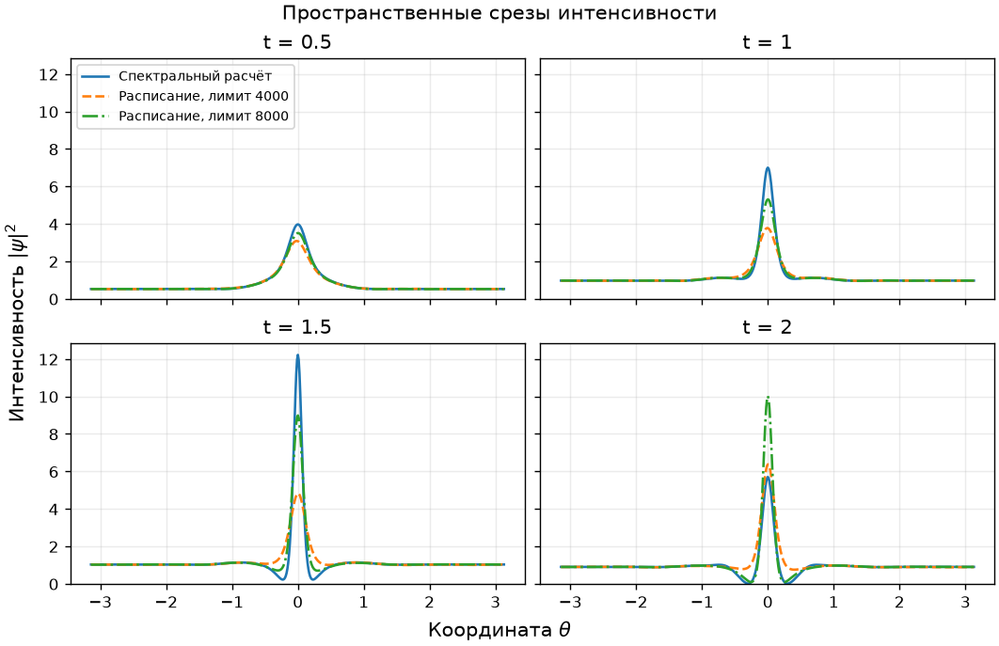

In [89]:
schedule20_field = load_evolution(get_run(CAUSAL_SCHEDULE_RUN_ID).path)
compare_t2_variant(CAUSAL_SCHEDULE40_RUN_ID, "Расписание, лимит 8000",
                   schedule20_field, reference_t2, baseline_label="Расписание, лимит 4000")

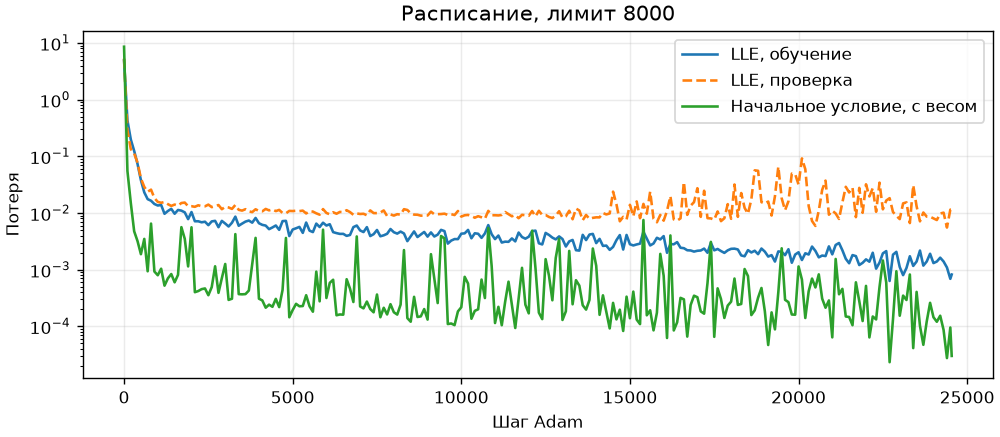

In [90]:
fig = plot_loss_history(CAUSAL_SCHEDULE40_RUN_ID, "Расписание, лимит 8000")
plt.show()

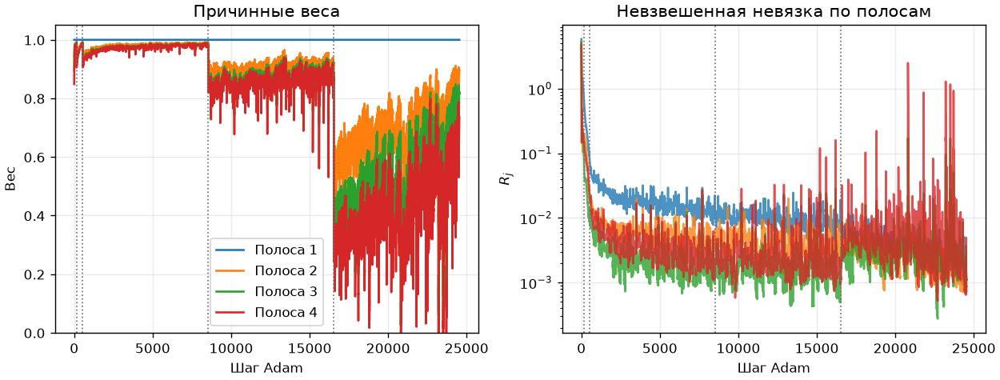

In [91]:
schedule40_weights = np.genfromtxt(schedule40_run.path / "loss_weights.csv",
                                 delimiter=",", names=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, layout="constrained")
for band in range(1, 5):
    axes[0].plot(schedule40_weights["step"], schedule40_weights[f"weight_band_{band}"],
                 label=f"Полоса {band}")
    axes[1].semilogy(schedule40_weights["step"], schedule40_weights[f"raw_band_{band}"], alpha=0.8)
for stage in stages40[:-1]:
    for ax in axes:
        ax.axvline(stage["last_step"], color="0.45", linestyle=":", linewidth=1)
axes[0].set(title="Причинные веса", xlabel="Шаг Adam", ylabel="Вес", ylim=(0, 1.05))
axes[1].set(title="Невзвешенная невязка по полосам", xlabel="Шаг Adam", ylabel=r"$R_j$")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

### Итог сравнения бюджетов

| Прогон | Фактические шаги | Максимальная $L^2$-ошибка поля | Время максимума интенсивности | Пик при $t=2$ |
| --- | ---: | ---: | ---: | ---: |
| Базовая PINN, бюджет 20 000 | 20 000 | 51,92 % | 2,00 | 9,36 |
| Базовая PINN, бюджет 40 000 | 40 000 | 43,65 % | 1,96 | 10,39 |
| Расписание, бюджет 20 000 | 12 541 | 61,28 % | 2,00 | 6,38 |
| Расписание, бюджет 40 000 | 24 541 | 31,98 % | 1,81 | 10,03 |
| Спектральный расчёт | — | — | 1,48 | 5,70 |

Увеличение бюджета снизило ошибку поля в обоих вариантах. Расписание с лимитом 8000 шагов на стадию дало наименьшую ошибку и частично восстановило спад пика. Максимум всё ещё запаздывает на 0,33, а к $t=2$ пик остаётся выше эталонного.

У расписания первые две стадии завершились на тех же шагах 158 и 541. Последние три использовали по 8000 шагов. Итоговый минимальный причинный вес вырос с 0,206 до 0,736.

## Увеличение бюджета Adam до 80 000 шагов

Сравниваем причинное расписание с лимитами 8000 и 16 000 шагов на стадию. Оба прогона обучались с нуля на $[0,2]$ с 1024 внутренними точками. Сохранённые конфигурации отличаются только общим бюджетом.

In [92]:
CAUSAL_SCHEDULE80_RUN_ID = "2026-11-09_13-20-06_535704"
schedule80_run = get_run(CAUSAL_SCHEDULE80_RUN_ID)
stages80 = np.genfromtxt(schedule80_run.path / "causal_stages.csv", delimiter=",",
                       names=True, dtype=None, encoding="utf-8")

for stage in stages80:
    snapshot = load_evolution(schedule80_run.path / f"stage_{stage['number']:02d}")
    stage_error = relative_l2_error(snapshot.values, reference_t2.values)
    peak = snapshot.intensity.values.max(axis=1)
    peak_index = peak.argmax()
    reason = "порог" if stage["reason"] == "threshold" else "лимит шагов"
    print(f"ε={stage['epsilon']:g}, шаги {stage['first_step']}–{stage['last_step']}: "
          f"min(w)={stage['min_weight']:.3f} ({reason}), "
          f"ошибка при t=0.5 — {stage_error[50]:.2%}, максимум ошибки — {stage_error.max():.2%}, "
          f"пик {peak[peak_index]:.2f} при t={snapshot.times[peak_index]:g}")

ε=0.01, шаги 1–158: min(w)=0.990 (порог), ошибка при t=0.5 — 21.09%, максимум ошибки — 80.98%, пик 3.16 при t=0.39
ε=0.1, шаги 159–541: min(w)=0.990 (порог), ошибка при t=0.5 — 17.17%, максимум ошибки — 74.68%, пик 2.51 при t=0.04
ε=1, шаги 542–12861: min(w)=0.990 (порог), ошибка при t=0.5 — 13.18%, максимум ошибки — 66.99%, пик 5.88 при t=2
ε=10, шаги 12862–28861: min(w)=0.960 (лимит шагов), ошибка при t=0.5 — 6.32%, максимум ошибки — 51.68%, пик 10.31 при t=2
ε=100, шаги 28862–44861: min(w)=0.927 (лимит шагов), ошибка при t=0.5 — 3.07%, максимум ошибки — 22.22%, пик 11.09 при t=1.67


Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Расписание, лимит 8000: максимальная ошибка поля — 31.98%
Расписание, лимит 8000: максимум 10.5432 при t=1.81, пик при t=2 — 10.0279
Расписание, лимит 16 000: максимальная ошибка поля — 22.22%
Расписание, лимит 16 000: максимум 11.0937 при t=1.67, пик при t=2 — 8.5791


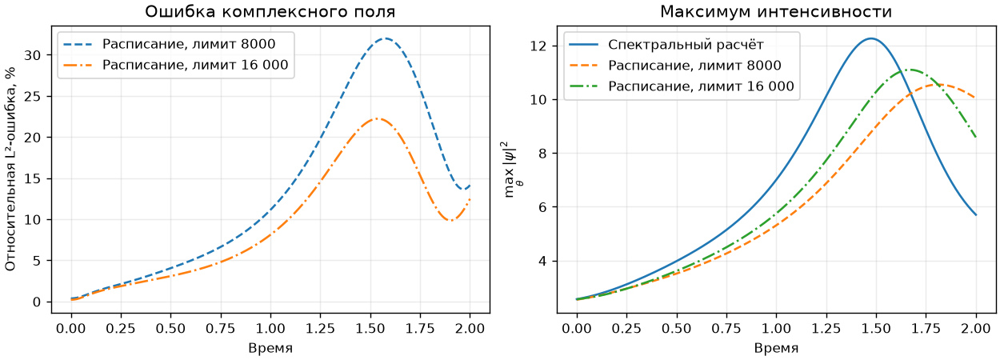

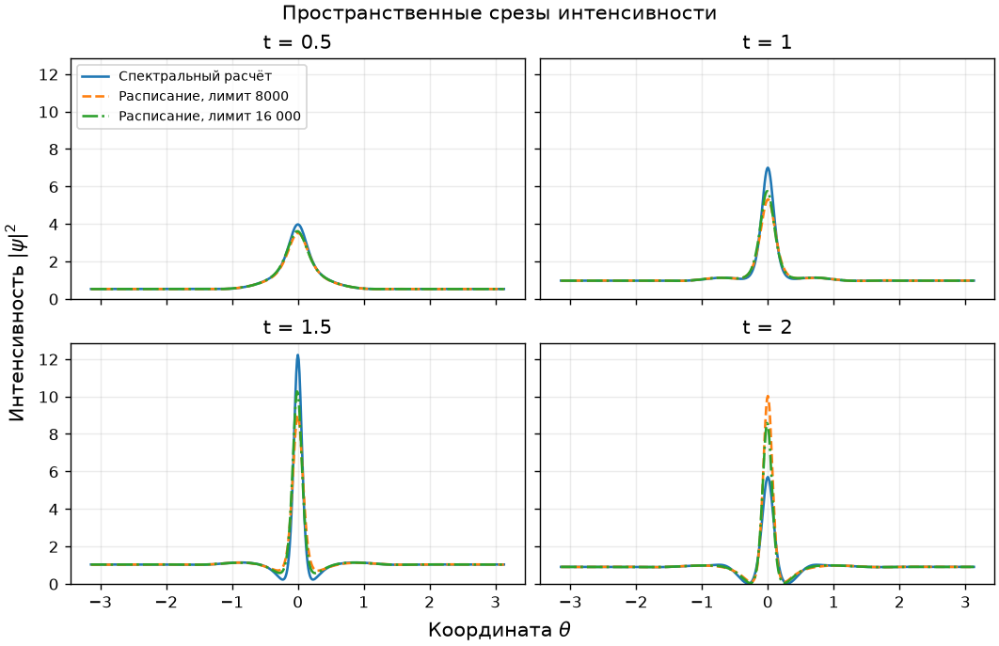

In [93]:
schedule40_field = load_evolution(get_run(CAUSAL_SCHEDULE40_RUN_ID).path)
compare_t2_variant(CAUSAL_SCHEDULE80_RUN_ID, "Расписание, лимит 16 000",
                   schedule40_field, reference_t2, baseline_label="Расписание, лимит 8000")

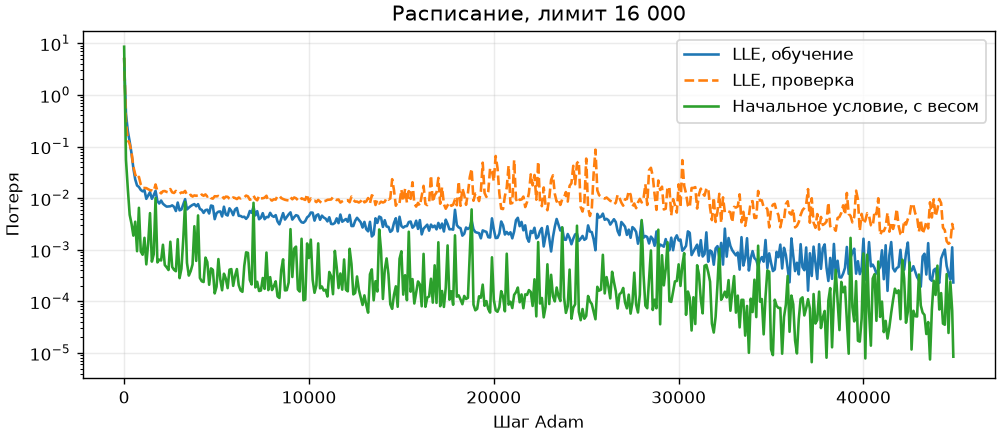

In [94]:
fig = plot_loss_history(CAUSAL_SCHEDULE80_RUN_ID, "Расписание, лимит 16 000")
plt.show()

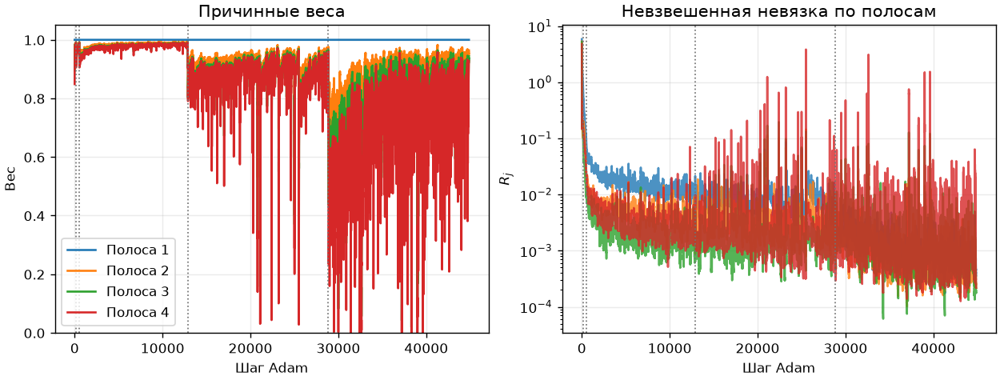

In [95]:
schedule80_weights = np.genfromtxt(schedule80_run.path / "loss_weights.csv",
                                 delimiter=",", names=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, layout="constrained")
for band in range(1, 5):
    axes[0].plot(schedule80_weights["step"], schedule80_weights[f"weight_band_{band}"],
                 label=f"Полоса {band}")
    axes[1].semilogy(schedule80_weights["step"], schedule80_weights[f"raw_band_{band}"], alpha=0.8)
for stage in stages80[:-1]:
    for ax in axes:
        ax.axvline(stage["last_step"], color="0.45", linestyle=":", linewidth=1)
axes[0].set(title="Причинные веса", xlabel="Шаг Adam", ylabel="Вес", ylim=(0, 1.05))
axes[1].set(title="Невзвешенная невязка по полосам", xlabel="Шаг Adam", ylabel=r"$R_j$")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

### Итог сравнения бюджетов расписания

| Прогон | Фактические шаги | Максимальная $L^2$-ошибка поля | Время максимума | Высота максимума | Пик при $t=2$ |
| --- | ---: | ---: | ---: | ---: | ---: |
| Лимит 8000 | 24 541 | 31,98 % | 1,81 | 10,54 | 10,03 |
| Лимит 16 000 | 44 861 | 22,22 % | 1,67 | 11,09 | 8,58 |
| Спектральный расчёт | — | — | 1,48 | 12,26 | 5,70 |

При большем бюджете сеть воспроизводит более выраженный спад, а запаздывание максимума сокращается с 0,33 до 0,19. При $t=2$ пик всё ещё выше эталонного. Третья стадия впервые завершилась по порогу, на шаге 12 861. Четвёртая и пятая использовали по 16 000 шагов. Итоговый минимальный вес вырос с 0,736 до 0,927.

## Сравнение длинных прогонов на $[0,2]$

Базовые PINN на 80 000 и 160 000 шагов и причинное расписание с лимитом 32 000 шагов на стадию обучены на другом устройстве. У всех 1024 внутренние точки, одна архитектура и один спектральный эталон. В таблице приводится фактическое число шагов, поскольку расписание допускает ранние переходы.

### Базовая PINN, 80 000 шагов

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN, 40 000 шагов: максимальная ошибка поля — 43.65%
Базовая PINN, 40 000 шагов: максимум 10.4285 при t=1.96, пик при t=2 — 10.3935
Базовая PINN, 80 000 шагов: максимальная ошибка поля — 4.14%
Базовая PINN, 80 000 шагов: максимум 11.7166 при t=1.49, пик при t=2 — 6.3240


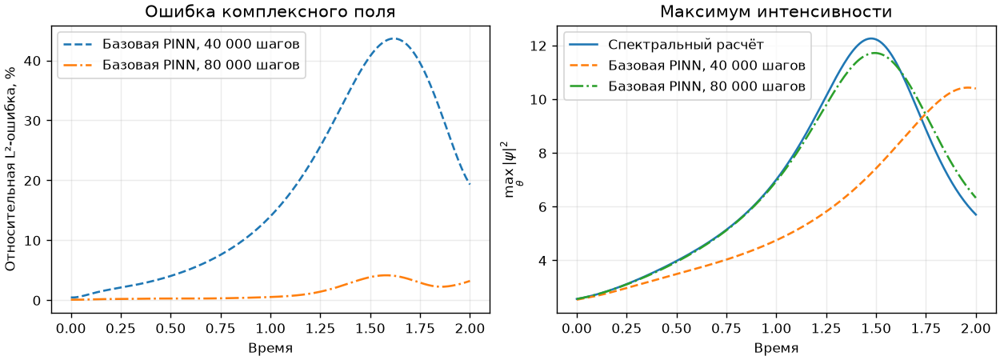

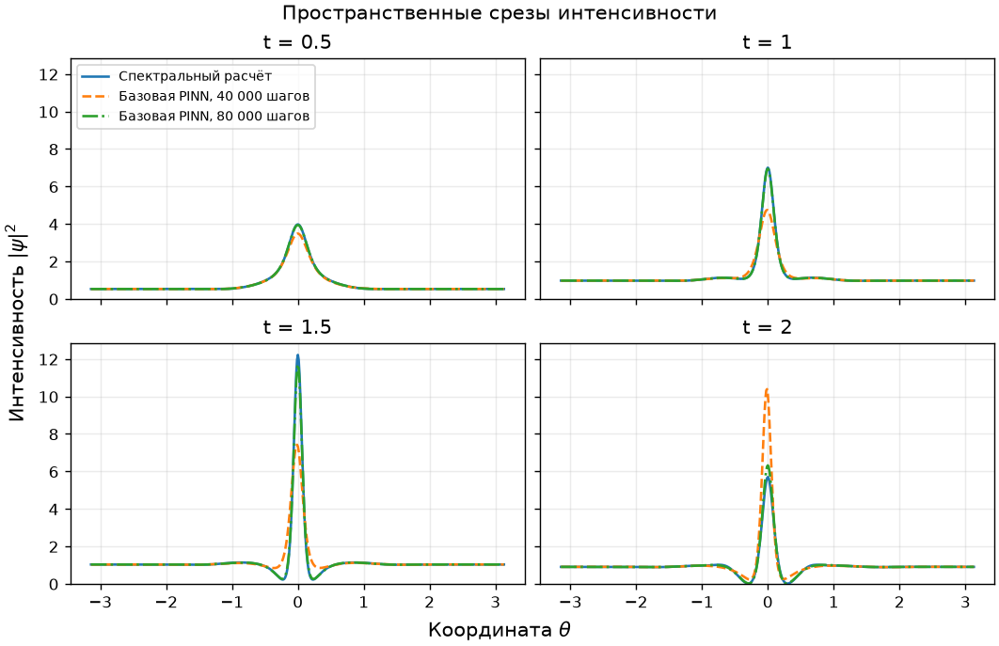

In [96]:
BASELINE80_RUN_ID = "2026-11-10_02-56-53_878205"
baseline40_field = load_evolution(get_run(BASELINE40_RUN_ID).path)
compare_t2_variant(BASELINE80_RUN_ID, "Базовая PINN, 80 000 шагов",
                   baseline40_field, reference_t2, baseline_label="Базовая PINN, 40 000 шагов")

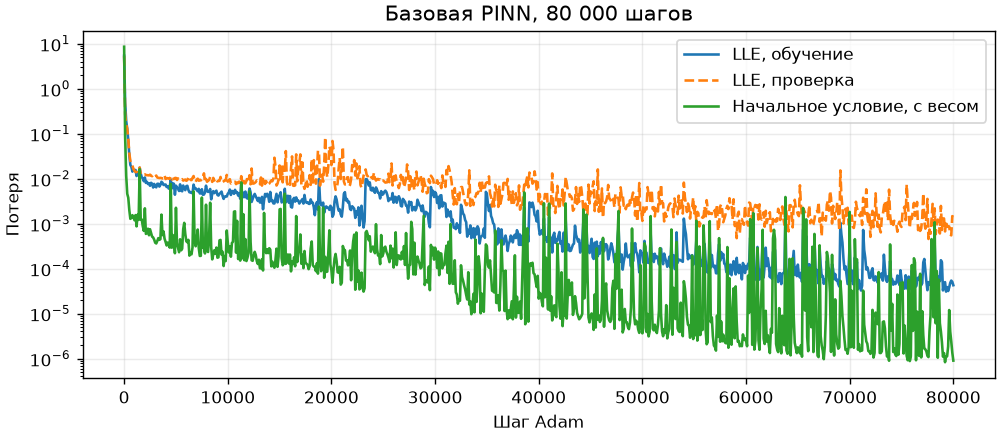

In [97]:
fig = plot_loss_history(BASELINE80_RUN_ID, "Базовая PINN, 80 000 шагов")
plt.show()

### Базовая PINN, 160 000 шагов

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Базовая PINN, 80 000 шагов: максимальная ошибка поля — 4.14%
Базовая PINN, 80 000 шагов: максимум 11.7166 при t=1.49, пик при t=2 — 6.3240
Базовая PINN, 160 000 шагов: максимальная ошибка поля — 2.84%
Базовая PINN, 160 000 шагов: максимум 11.9077 при t=1.49, пик при t=2 — 6.0400


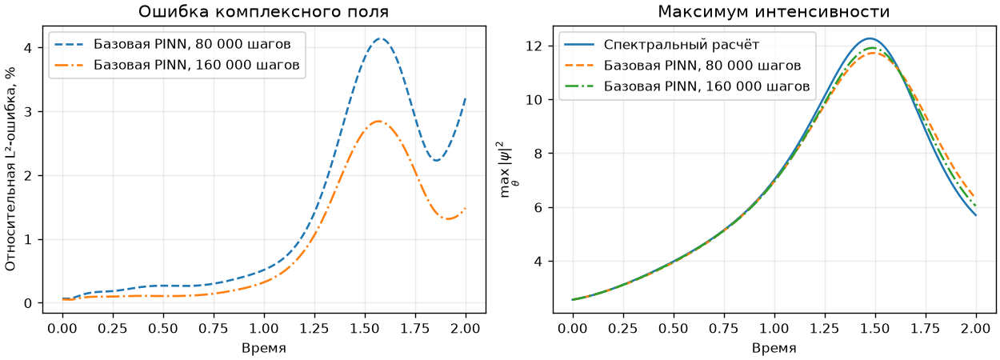

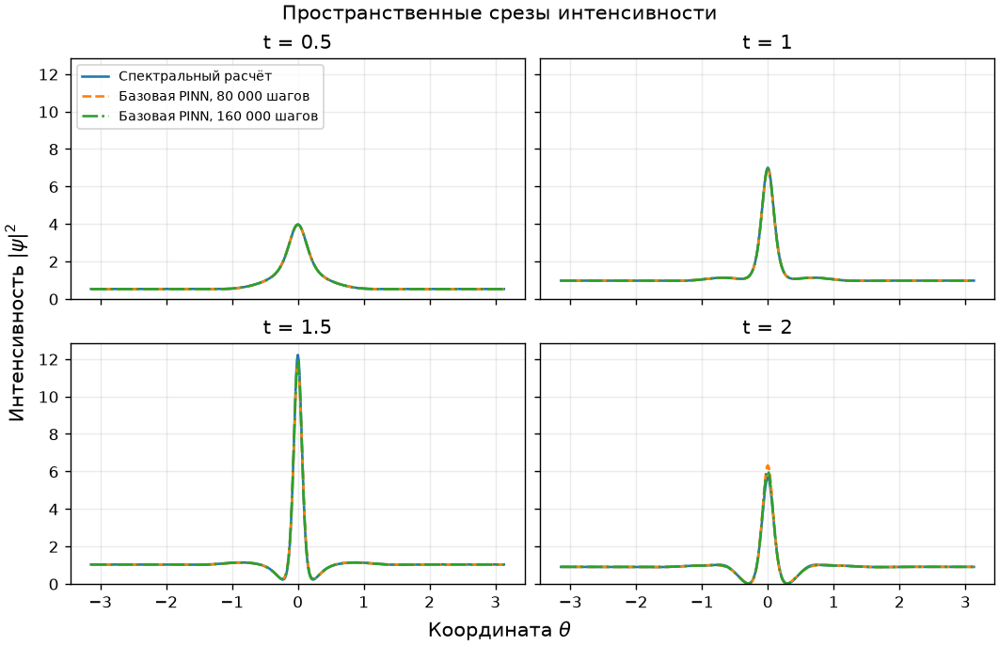

In [98]:
BASELINE160_RUN_ID = "2026-11-10_02-57-09_390828"
baseline80_field = load_evolution(get_run(BASELINE80_RUN_ID).path)
compare_t2_variant(BASELINE160_RUN_ID, "Базовая PINN, 160 000 шагов",
                   baseline80_field, reference_t2, baseline_label="Базовая PINN, 80 000 шагов")

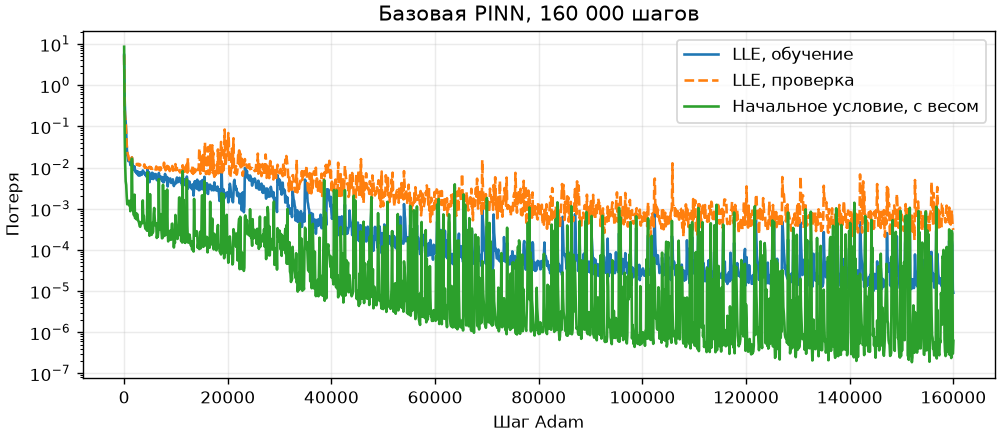

In [99]:
fig = plot_loss_history(BASELINE160_RUN_ID, "Базовая PINN, 160 000 шагов")
plt.show()

### Причинное расписание, лимит 32 000 шагов на стадию

In [100]:
CAUSAL_SCHEDULE160_RUN_ID = "2026-11-10_02-56-31_186798"
schedule160_run = get_run(CAUSAL_SCHEDULE160_RUN_ID)
stages160 = np.genfromtxt(schedule160_run.path / "causal_stages.csv", delimiter=",",
                       names=True, dtype=None, encoding="utf-8")

for stage in stages160:
    snapshot = load_evolution(schedule160_run.path / f"stage_{stage['number']:02d}")
    stage_error = relative_l2_error(snapshot.values, reference_t2.values)
    peak = snapshot.intensity.values.max(axis=1)
    peak_index = peak.argmax()
    reason = "порог" if stage["reason"] == "threshold" else "лимит шагов"
    print(f"ε={stage['epsilon']:g}, шаги {stage['first_step']}–{stage['last_step']}: "
          f"min(w)={stage['min_weight']:.3f} ({reason}), "
          f"ошибка при t=0.5 — {stage_error[50]:.2%}, максимум ошибки — {stage_error.max():.2%}, "
          f"пик {peak[peak_index]:.2f} при t={snapshot.times[peak_index]:g}")

ε=0.01, шаги 1–158: min(w)=0.990 (порог), ошибка при t=0.5 — 21.09%, максимум ошибки — 80.98%, пик 3.16 при t=0.39
ε=0.1, шаги 159–541: min(w)=0.990 (порог), ошибка при t=0.5 — 17.17%, максимум ошибки — 74.68%, пик 2.51 при t=0.04
ε=1, шаги 542–12861: min(w)=0.990 (порог), ошибка при t=0.5 — 13.19%, максимум ошибки — 67.06%, пик 5.87 при t=2
ε=10, шаги 12862–36960: min(w)=0.990 (порог), ошибка при t=0.5 — 4.07%, максимум ошибки — 36.85%, пик 10.79 при t=1.85
ε=100, шаги 36961–68960: min(w)=0.980 (лимит шагов), ошибка при t=0.5 — 0.85%, максимум ошибки — 8.57%, пик 11.60 при t=1.54


Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
Расписание, лимит 16 000: максимальная ошибка поля — 22.22%
Расписание, лимит 16 000: максимум 11.0937 при t=1.67, пик при t=2 — 8.5791
Расписание, лимит 32 000: максимальная ошибка поля — 8.57%
Расписание, лимит 32 000: максимум 11.5961 при t=1.54, пик при t=2 — 6.7421


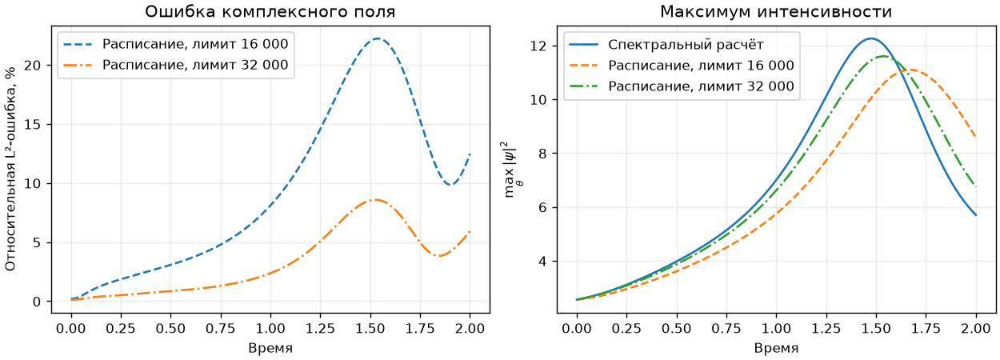

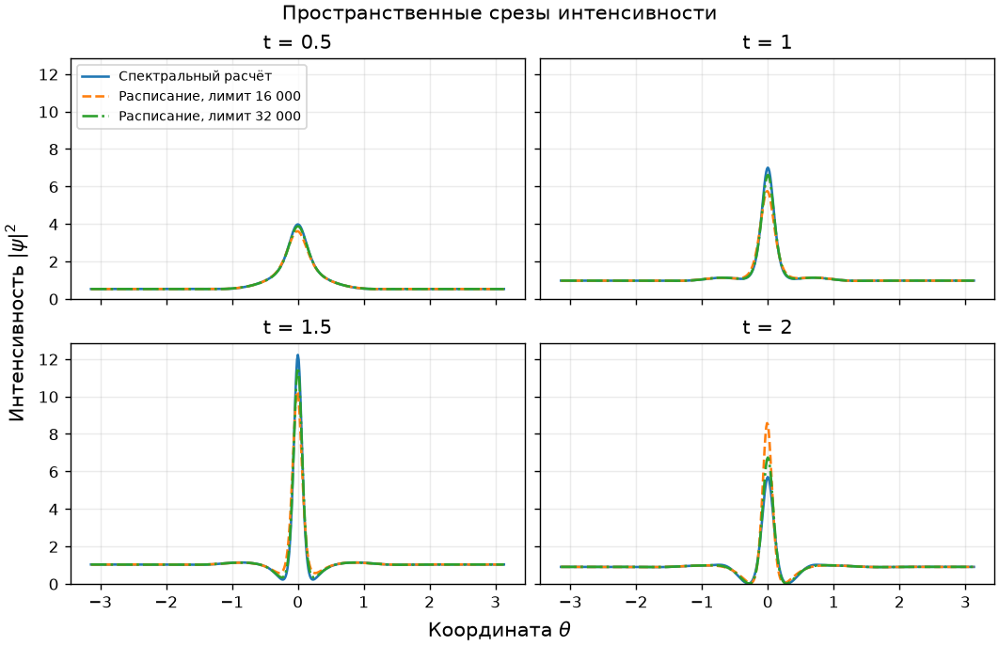

In [101]:
schedule80_field = load_evolution(get_run(CAUSAL_SCHEDULE80_RUN_ID).path)
compare_t2_variant(CAUSAL_SCHEDULE160_RUN_ID, "Расписание, лимит 32 000",
                   schedule80_field, reference_t2, baseline_label="Расписание, лимит 16 000")

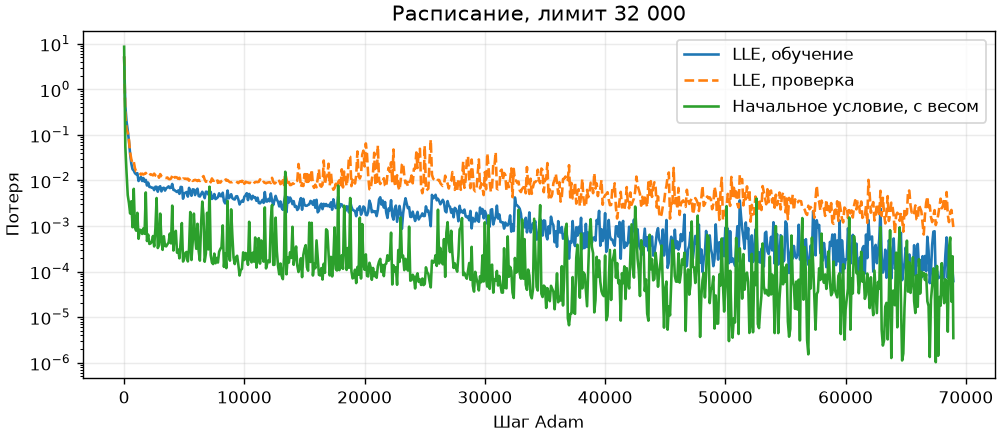

In [102]:
fig = plot_loss_history(CAUSAL_SCHEDULE160_RUN_ID, "Расписание, лимит 32 000")
plt.show()

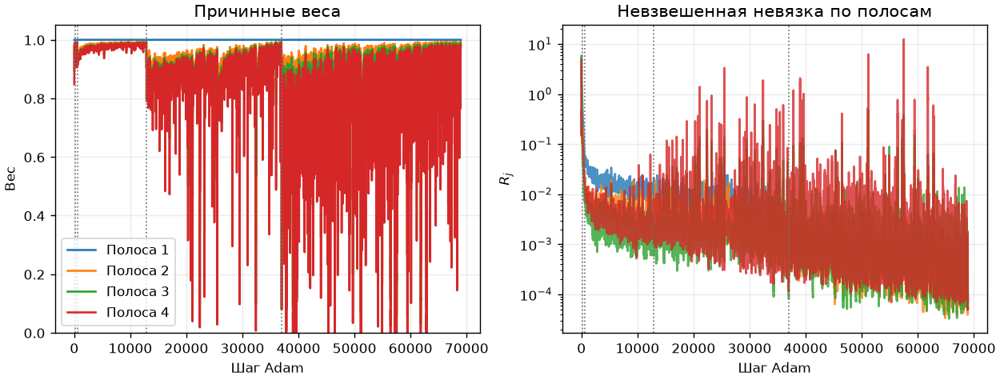

In [103]:
schedule160_weights = np.genfromtxt(schedule160_run.path / "loss_weights.csv",
                                 delimiter=",", names=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, layout="constrained")
for band in range(1, 5):
    axes[0].plot(schedule160_weights["step"], schedule160_weights[f"weight_band_{band}"],
                 label=f"Полоса {band}")
    axes[1].semilogy(schedule160_weights["step"], schedule160_weights[f"raw_band_{band}"], alpha=0.8)
for stage in stages160[:-1]:
    for ax in axes:
        ax.axvline(stage["last_step"], color="0.45", linestyle=":", linewidth=1)
axes[0].set(title="Причинные веса", xlabel="Шаг Adam", ylabel="Вес", ylim=(0, 1.05))
axes[1].set(title="Невзвешенная невязка по полосам", xlabel="Шаг Adam", ylabel=r"$R_j$")
axes[0].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

### Итоги

| Прогон | Фактические шаги | Максимальная $L^2$-ошибка | Время максимума пика | Высота максимума | Пик при $t=2$ |
| --- | ---: | ---: | ---: | ---: | ---: |
| Базовая PINN, 40 000 | 40 000 | 43,65 % | 1,96 | 10,43 | 10,39 |
| Базовая PINN, 80 000 | 80 000 | 4,14 % | 1,49 | 11,72 | 6,32 |
| Базовая PINN, 160 000 | 160 000 | 2,84 % | 1,49 | 11,91 | 6,04 |
| Расписание, лимит 16 000 | 44 861 | 22,22 % | 1,67 | 11,09 | 8,58 |
| Расписание, лимит 32 000 | 68 960 | 8,57 % | 1,54 | 11,60 | 6,74 |
| Спектральный расчёт | — | — | 1,48 | 12,26 | 5,70 |

Оба длинных базовых прогона воспроизвели подъём и спад пика. Основное улучшение наблюдается между 40 000 и 80 000 шагов. Дальнейшее удвоение бюджета снизило ошибку с 4,14 % до 2,84 % и приблизило высоту пика к эталону.

При лимите 32 000 первые четыре стадии расписания завершились по порогу. Последняя стадия использовала весь лимит и закончилась с минимальным весом 0,980. Расписание также восстановило спад, но при фактических 68 960 шагах его максимальная ошибка осталась выше, чем у базовой PINN при 80 000. Для вывода об эффективности при равном числе шагов нужна базовая PINN на том же фактическом бюджете.

## Уменьшение числа внутренних точек при 160 000 шагах Adam

Прогоны на $[0,2]$ отличаются от контроля только числом внутренних точек. Используем seed 42, 256 точек начального условия и пересэмплирование через 100 шагов. Общий эталон — спектральный прогон `2026-11-09_05-03-32_207710`.

Критерии на общей сетке: максимальная относительная $L^2$-ошибка поля до 10 %, ошибка времени максимума до 0,05 и относительная ошибка высоты пика при $t=2$ до 10 %.

In [104]:
sampling_control = load_evolution(get_run(BASELINE160_RUN_ID).path)

### PINN, 512 точки

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
PINN, 1024 точки: максимальная ошибка поля — 2.84%
PINN, 1024 точки: максимум 11.9077 при t=1.49, пик при t=2 — 6.0400
PINN, 512 точки: максимальная ошибка поля — 70.85%
PINN, 512 точки: максимум 4.0357 при t=2, пик при t=2 — 4.0357


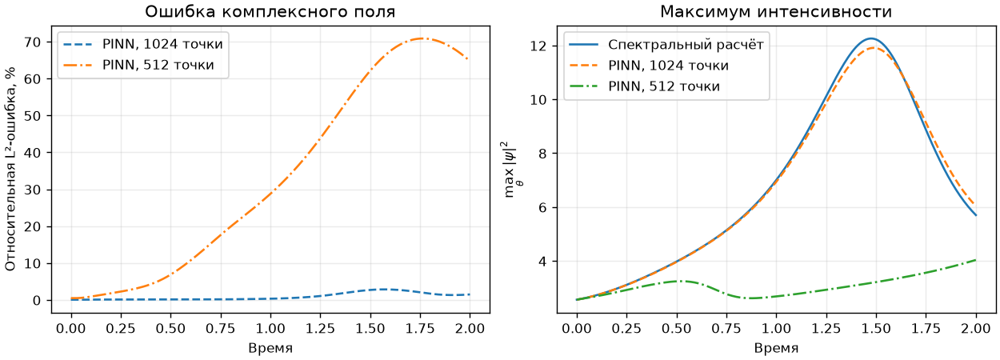

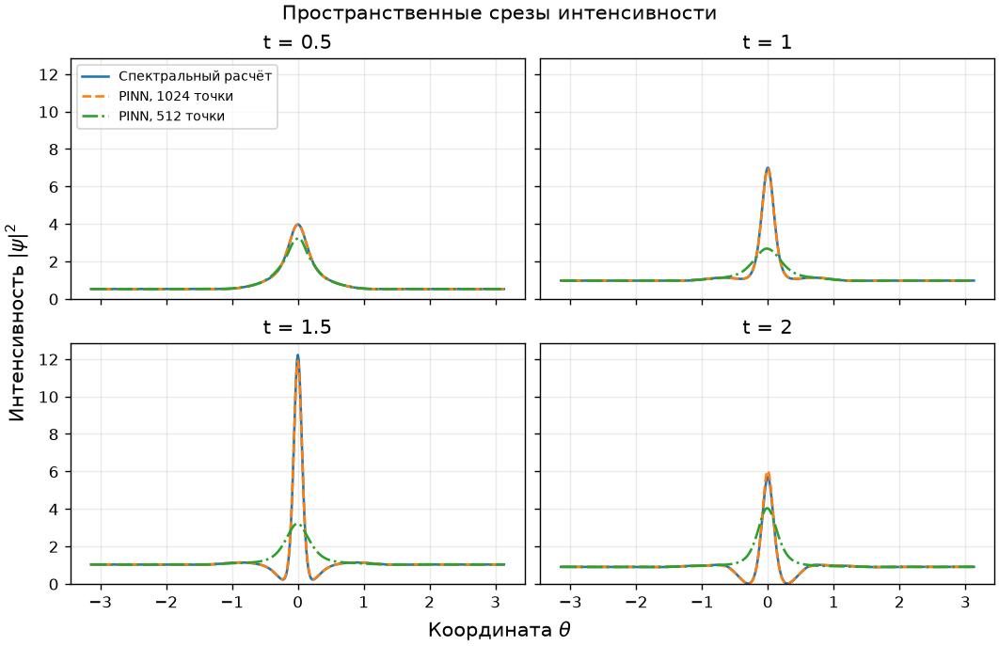

In [105]:
SAMPLING512_RUN_ID = "2026-11-10_05-34-46_830558"
compare_t2_variant(SAMPLING512_RUN_ID, "PINN, 512 точки", sampling_control, reference_t2,
                   baseline_label="PINN, 1024 точки")

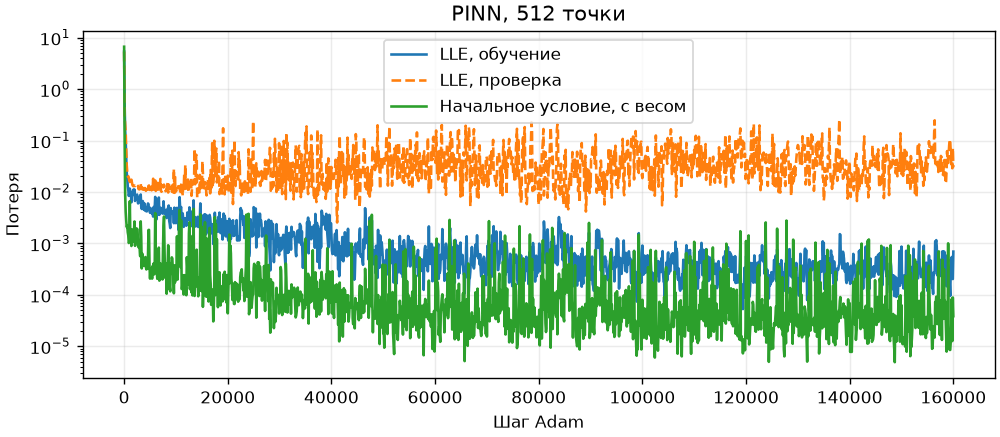

In [106]:
fig = plot_loss_history(SAMPLING512_RUN_ID, "PINN, 512 точки")
plt.show()

### PINN, 256 точек

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
PINN, 1024 точки: максимальная ошибка поля — 2.84%
PINN, 1024 точки: максимум 11.9077 при t=1.49, пик при t=2 — 6.0400
PINN, 256 точек: максимальная ошибка поля — 70.41%
PINN, 256 точек: максимум 4.7724 при t=2, пик при t=2 — 4.7724


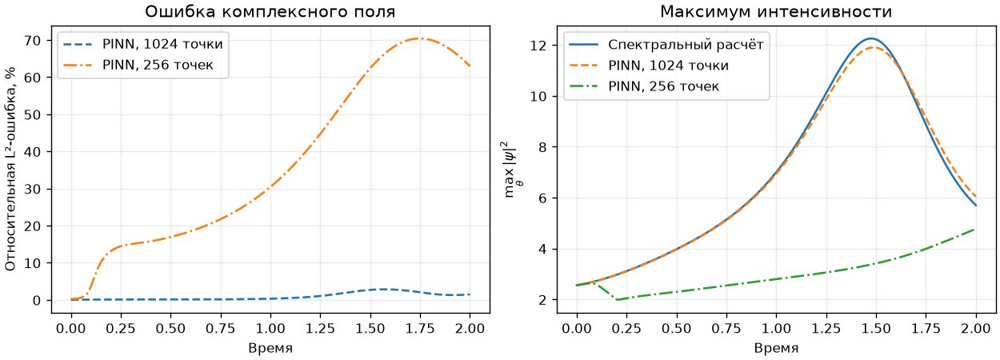

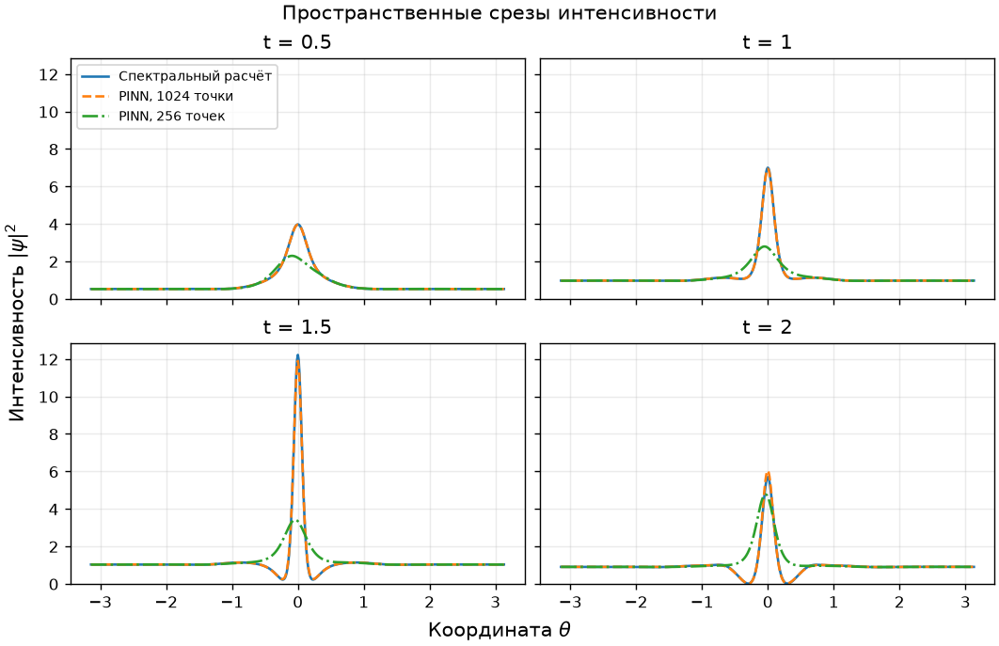

In [107]:
SAMPLING256_RUN_ID = "2026-11-10_05-34-54_484645"
compare_t2_variant(SAMPLING256_RUN_ID, "PINN, 256 точек", sampling_control, reference_t2,
                   baseline_label="PINN, 1024 точки")

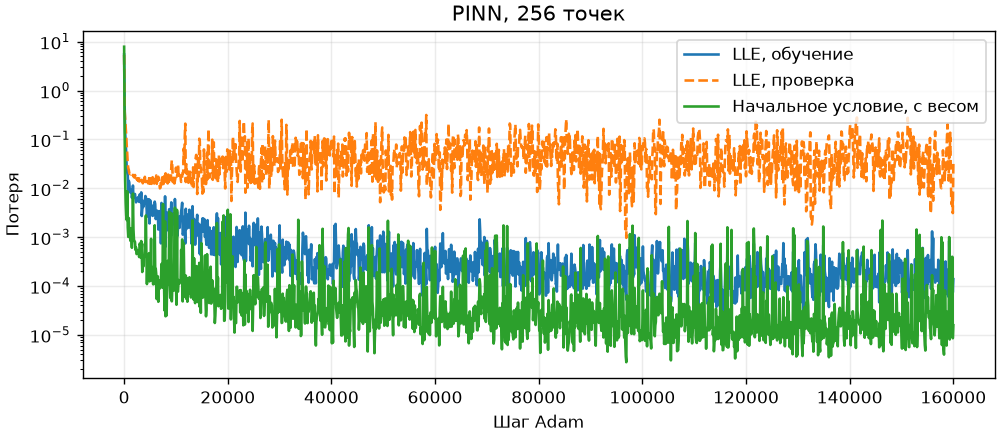

In [108]:
fig = plot_loss_history(SAMPLING256_RUN_ID, "PINN, 256 точек")
plt.show()

### PINN, 128 точек

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
PINN, 1024 точки: максимальная ошибка поля — 2.84%
PINN, 1024 точки: максимум 11.9077 при t=1.49, пик при t=2 — 6.0400
PINN, 128 точек: максимальная ошибка поля — 65.42%
PINN, 128 точек: максимум 5.4978 при t=1.97, пик при t=2 — 5.4956


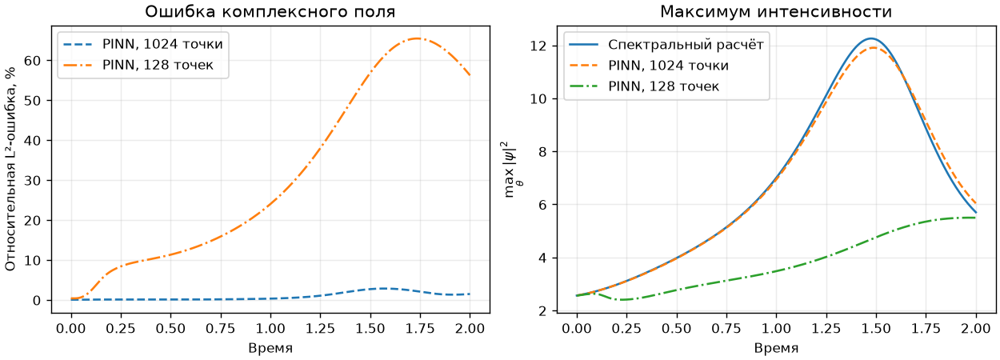

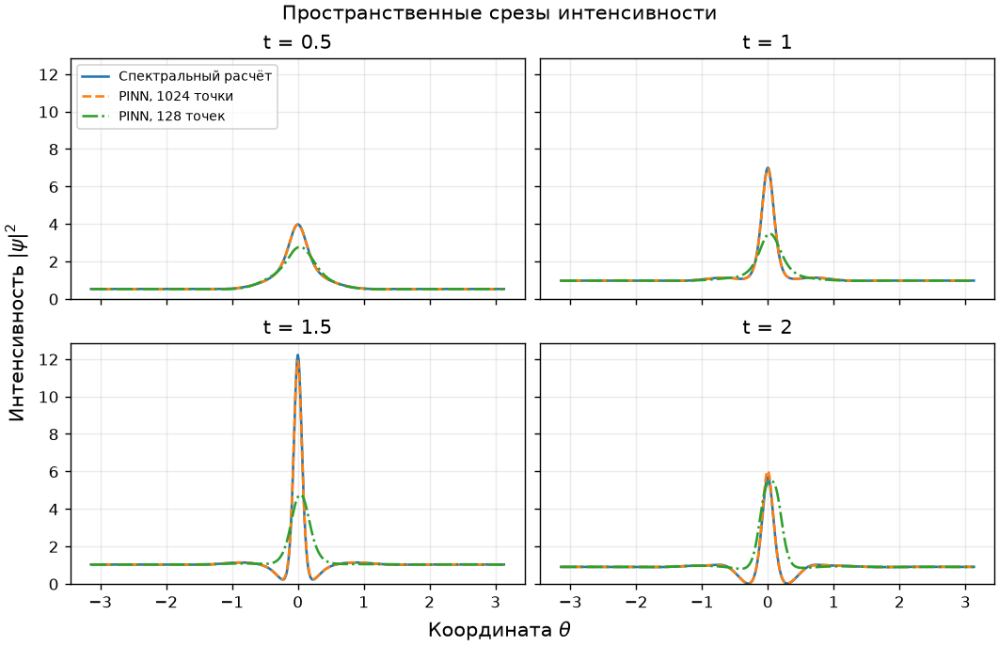

In [109]:
SAMPLING128_RUN_ID = "2026-11-10_05-35-03_480665"
compare_t2_variant(SAMPLING128_RUN_ID, "PINN, 128 точек", sampling_control, reference_t2,
                   baseline_label="PINN, 1024 точки")

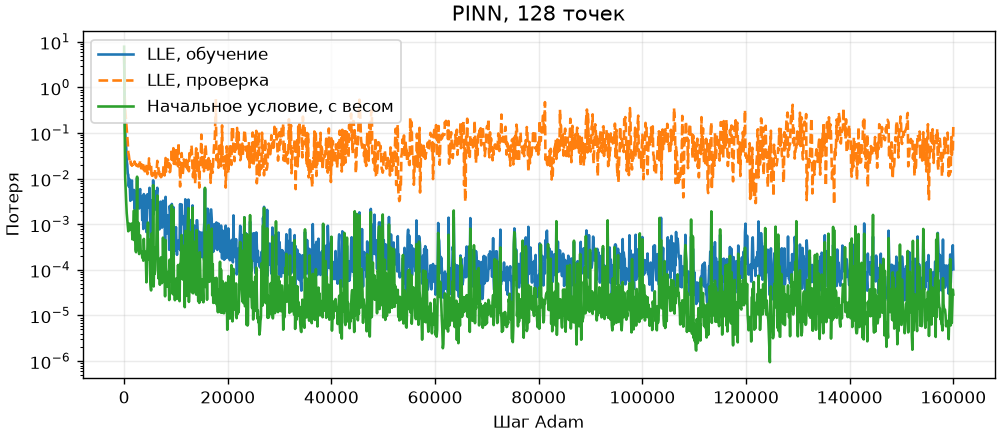

In [110]:
fig = plot_loss_history(SAMPLING128_RUN_ID, "PINN, 128 точек")
plt.show()

### PINN, 64 точки

Спектральный расчёт: максимум 12.2560 при t=1.48, пик при t=2 — 5.7006
PINN, 1024 точки: максимальная ошибка поля — 2.84%
PINN, 1024 точки: максимум 11.9077 при t=1.49, пик при t=2 — 6.0400
PINN, 64 точки: максимальная ошибка поля — 69.07%
PINN, 64 точки: максимум 4.1081 при t=2, пик при t=2 — 4.1081


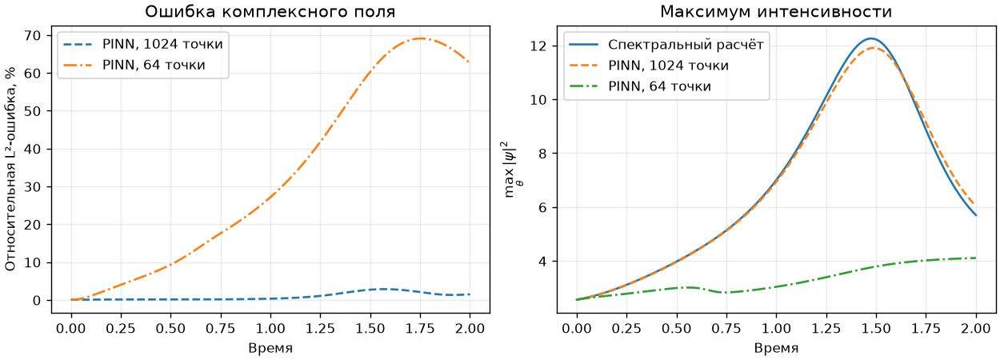

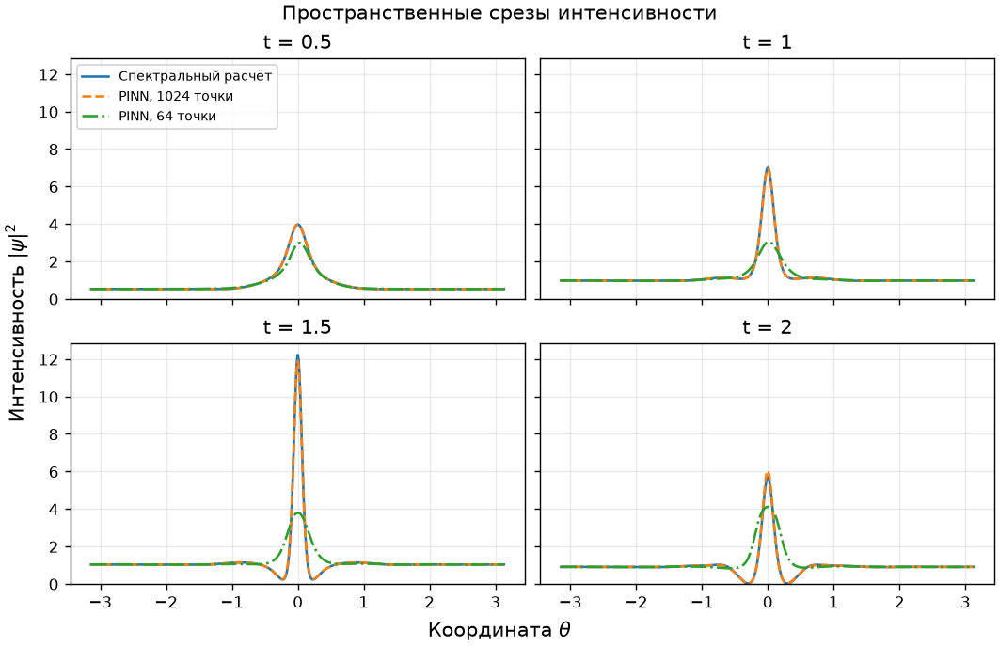

In [111]:
SAMPLING64_RUN_ID = "2026-11-10_05-35-13_027046"
compare_t2_variant(SAMPLING64_RUN_ID, "PINN, 64 точки", sampling_control, reference_t2,
                   baseline_label="PINN, 1024 точки")

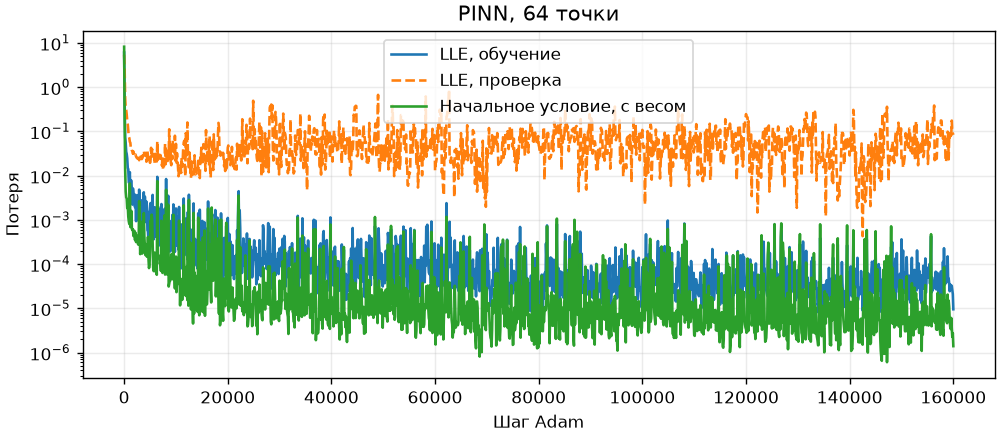

In [112]:
fig = plot_loss_history(SAMPLING64_RUN_ID, "PINN, 64 точки")
plt.show()

### Итоги

| Внутренние точки | Максимальная $L^2$-ошибка | Время максимума | Высота максимума | Пик при $t=2$ |
| ---: | ---: | ---: | ---: | ---: |
| 1024 | 2,84 % | 1,49 | 11,91 | 6,04 |
| 512 | 70,85 % | 2,00 | 4,04 | 4,04 |
| 256 | 70,41 % | 2,00 | 4,77 | 4,77 |
| 128 | 65,42 % | 1,97 | 5,50 | 5,50 |
| 64 | 69,07 % | 2,00 | 4,11 | 4,11 |
| Спектральный расчёт | — | 1,48 | 12,26 | 5,70 |

При seed 42 качество резко падает уже при уменьшении числа внутренних точек с 1024 до 512. Все четыре прогона завершили 160 000 шагов, но пропустили резкий подъём пика около $t=1.48$. Вариант на 128 точках близок к эталону по высоте пика при $t=2$, хотя ошибается по времени максимума и по комплексному полю. Среди проверенных значений проходит только 1024. Положение границы внутри диапазона от 512 до 1024 и её устойчивость к смене seed ещё предстоит проверить.

## Обучение на интервале $[0,4]$

Базовая PINN обучалась с нуля 160 000 шагов Adam с 1024 внутренними точками. Конфигурация отличается от успешного базового прогона на $[0,2]$ только конечным временем. Спектральный эталон пересчитан с прежним шагом интегрирования $0.0005$ и записью через $0.01$.

In [113]:
PINN_T4_RUN_ID = "2026-11-10_05-09-19_653859"
REFERENCE_T4_RUN_ID = "2026-11-10_07-44-12_914080"

pinn_t4 = load_evolution(get_run(PINN_T4_RUN_ID).path)
reference_t4 = load_evolution(get_run(REFERENCE_T4_RUN_ID).path)
baseline_t2 = load_evolution(get_run(BASELINE160_RUN_ID).path)
reference_first_two = reference_t4[time_mask(reference_t4.times, 0, 2)]
for prediction, expected in ((pinn_t4, reference_t4), (baseline_t2, reference_first_two)):
    np.testing.assert_array_equal(prediction.theta, expected.theta)
    np.testing.assert_allclose(prediction.times, expected.times, rtol=0, atol=1e-10)

t4_error = relative_l2_error(pinn_t4.values, reference_t4.values)
t2_control_error = relative_l2_error(baseline_t2.values, reference_first_two.values)
peak_t4 = pinn_t4.intensity.values.max(axis=1)
peak_ref_t4 = reference_t4.intensity.values.max(axis=1)
print(f"Максимальная ошибка поля — {t4_error.max():.2%} "
      f"при t={pinn_t4.times[t4_error.argmax()]:g}")
print(f"На [0,2] максимальная ошибка — {t4_error[pinn_t4.times <= 2].max():.2%} "
      f"против {t2_control_error.max():.2%} у PINN, обученной до T=2")
for time in (1.48, 2.0, 3.5, 4.0):
    predicted = pinn_t4.at_time(time)
    expected = reference_t4.at_time(time)
    error = relative_field_l2_error(predicted, expected)
    print(f"t={time:g}: ошибка {error:.2%}, пик PINN {predicted.intensity.values.max():.2f}, "
          f"спектральный пик {expected.intensity.values.max():.2f}")

Максимальная ошибка поля — 83.44% при t=3.8
На [0,2] максимальная ошибка — 72.70% против 2.84% у PINN, обученной до T=2
t=1.48: ошибка 63.60%, пик PINN 2.39, спектральный пик 12.26
t=2: ошибка 70.03%, пик PINN 2.54, спектральный пик 5.70
t=3.5: ошибка 76.76%, пик PINN 3.01, спектральный пик 10.07
t=4: ошибка 80.88%, пик PINN 3.03, спектральный пик 6.94


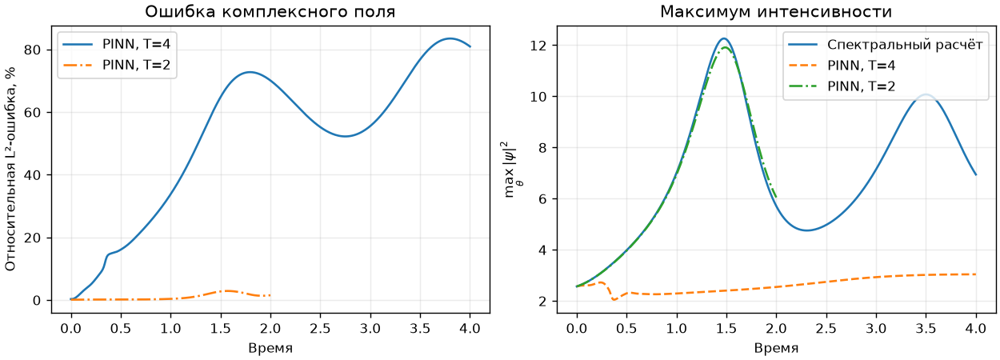

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].plot(pinn_t4.times, 100 * t4_error, label="PINN, T=4")
axes[0].plot(baseline_t2.times, 100 * t2_control_error, "-.", label="PINN, T=2")
axes[1].plot(reference_t4.times, peak_ref_t4, label="Спектральный расчёт")
axes[1].plot(pinn_t4.times, peak_t4, "--", label="PINN, T=4")
axes[1].plot(baseline_t2.times, baseline_t2.intensity.values.max(axis=1), "-.", label="PINN, T=2")
axes[0].set(title="Ошибка комплексного поля", xlabel="Время", ylabel="Относительная L²-ошибка, %")
axes[1].set(title="Максимум интенсивности", xlabel="Время", ylabel=r"$\max_\theta |\psi|^2$")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.show()

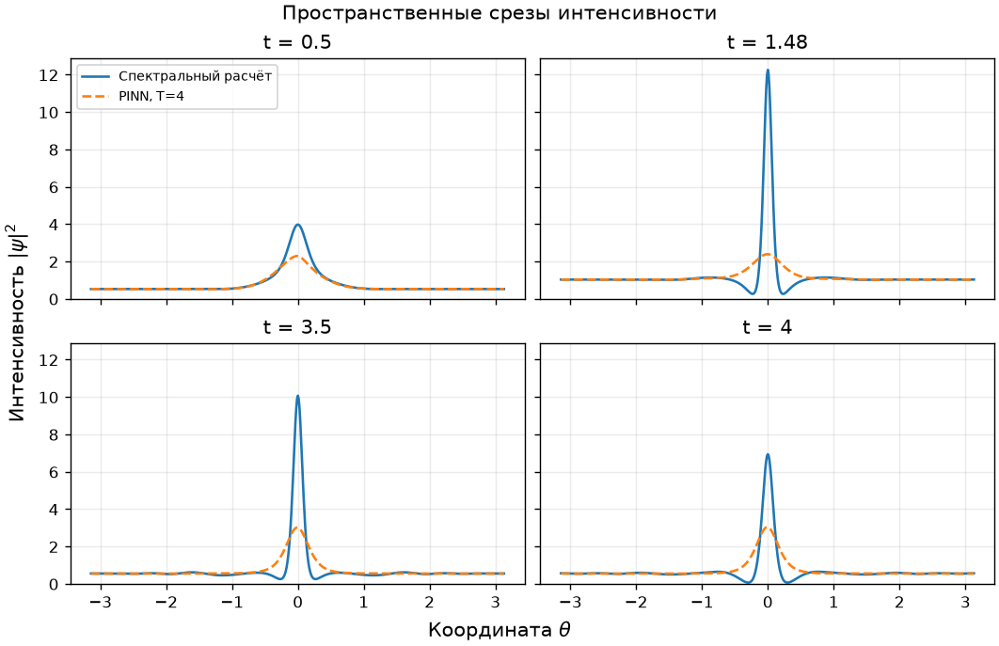

In [115]:
fig, axes = plt.subplots(2, 2, figsize=(8.5, 5.5), sharex=True, sharey=True,
                         layout="constrained")
fig.suptitle("Пространственные срезы интенсивности")
for ax, time in zip(axes.flat, (0.5, 1.48, 3.5, 4.0)):
    for evolution, label, style in ((reference_t4, "Спектральный расчёт", "-"),
                                   (pinn_t4, "PINN, T=4", "--")):
        profile = evolution.at_time(time).intensity
        ax.plot(profile.theta, profile.values, style, label=label)
    ax.set_title(f"t = {time:g}")
    ax.grid(alpha=0.25)
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.supxlabel(r"Координата $\theta$")
fig.supylabel(r"Интенсивность $|\psi|^2$")
plt.show()

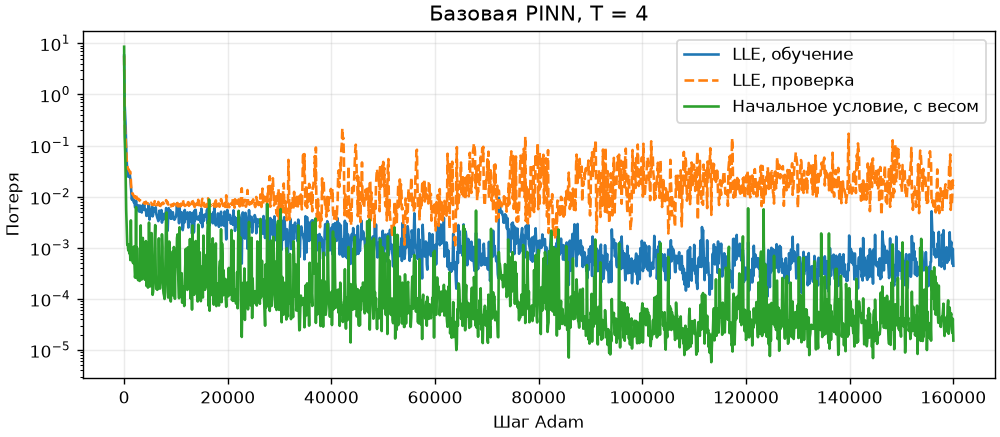

In [116]:
fig = plot_loss_history(PINN_T4_RUN_ID, "Базовая PINN, T = 4")
plt.show()

### Итог

Увеличение горизонта до $T=4$ резко ухудшило уже первый участок траектории. На $[0,2]$ максимальная ошибка выросла с 2,84 % до 72,70 %. На всём $[0,4]$ она достигла 83,44 % при $t=3.8$.

PINN пропустила оба выраженных максимума спектрального расчёта: при $t=1.48$ высота пика 2,39 вместо 12,26, при $t=3.5$ — 3,01 вместо 10,07. При $t=4$ пик PINN равен 3,03 против 6,94 у эталона.

## Число точек и бюджет на $[0,4]$

Три новых прогона выполнены на NVIDIA GeForce RTX 4060 Laptop GPU. Сохранённые конфигурации различаются только числом внутренних точек и шагов Adam. У старого контроля устройство в метаданных отсутствует. Ошибки рассчитаны на одной спектральной сетке.

In [117]:
def compare_t4_sweep(run_id, label):
    variant = load_evolution(get_run(run_id).path)
    np.testing.assert_array_equal(variant.theta, reference_t4.theta)
    np.testing.assert_allclose(variant.times, reference_t4.times, rtol=0, atol=1e-10)
    error = relative_l2_error(variant.values, reference_t4.values)
    peak = variant.intensity.values.max(axis=1)
    print(f"Максимальная ошибка — {error.max():.2%} при t={variant.times[error.argmax()]:g}")
    print(f"На [0,2] максимальная ошибка — {error[variant.times <= 2].max():.2%}")
    control = "Контроль, 1024 точки и 160 000 шагов"

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
    axes[0].plot(pinn_t4.times, 100 * t4_error, "--", label=control)
    axes[0].plot(variant.times, 100 * error, "-.", label=label)
    axes[1].plot(reference_t4.times, peak_ref_t4, label="Спектральный расчёт")
    axes[1].plot(pinn_t4.times, peak_t4, "--", label=control)
    axes[1].plot(variant.times, peak, "-.", label=label)
    axes[0].set(title="Ошибка комплексного поля", xlabel="Время", ylabel="Относительная L²-ошибка, %")
    axes[1].set(title="Максимум интенсивности", xlabel="Время", ylabel=r"$\max_\theta |\psi|^2$")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.25)
    plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(8.5, 5.5), sharex=True, sharey=True,
                             layout="constrained")
    fig.suptitle("Пространственные срезы интенсивности")
    for ax, time in zip(axes.flat, (0.5, 1.48, 3.5, 4.0)):
        for evolution, name, style in ((reference_t4, "Спектральный расчёт", "-"),
                                       (pinn_t4, control, "--"), (variant, label, "-.")):
            profile = evolution.at_time(time).intensity
            ax.plot(profile.theta, profile.values, style, label=name)
        ax.set_title(f"t = {time:g}")
        ax.grid(alpha=0.25)
    axes[0, 0].set_ylim(bottom=0)
    axes[0, 0].legend(loc="upper left", fontsize=8)
    fig.supxlabel(r"Координата $\theta$")
    fig.supylabel(r"Интенсивность $|\psi|^2$")
    plt.show()

### 2048 точек, 160 000 шагов

Максимальная ошибка — 83.40% при t=3.8
На [0,2] максимальная ошибка — 72.75%


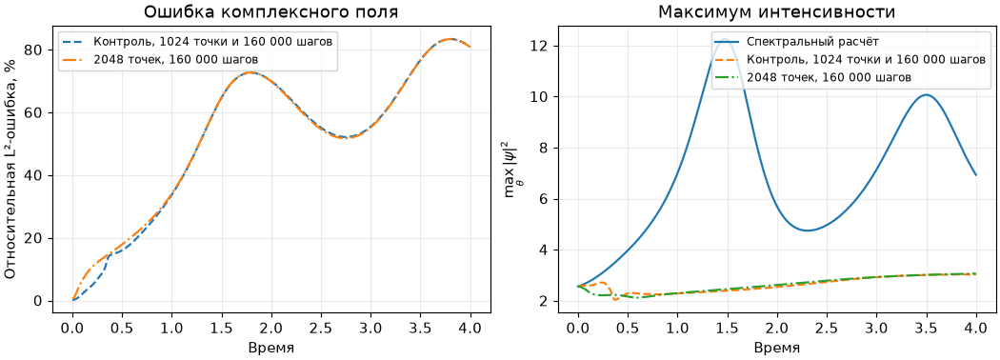

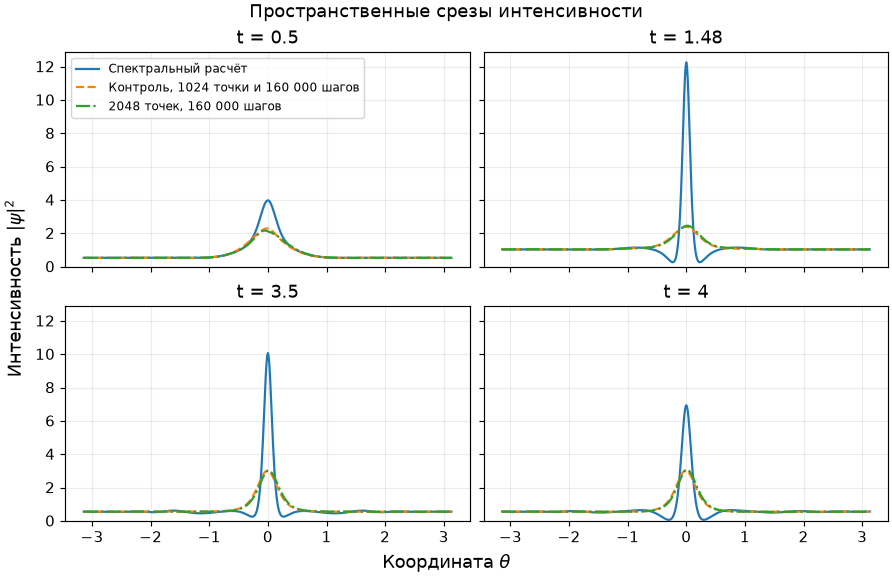

In [118]:
T4_2048_160K_RUN_ID = "2026-11-10_08-58-48_416907"
compare_t4_sweep(T4_2048_160K_RUN_ID, "2048 точек, 160 000 шагов")

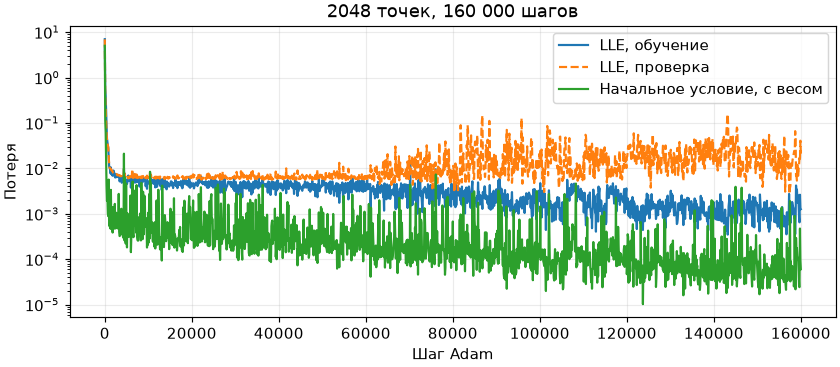

In [119]:
fig = plot_loss_history(T4_2048_160K_RUN_ID, "2048 точек, 160 000 шагов")
plt.show()

### 2048 точек, 320 000 шагов

Максимальная ошибка — 82.49% при t=3.79
На [0,2] максимальная ошибка — 72.56%


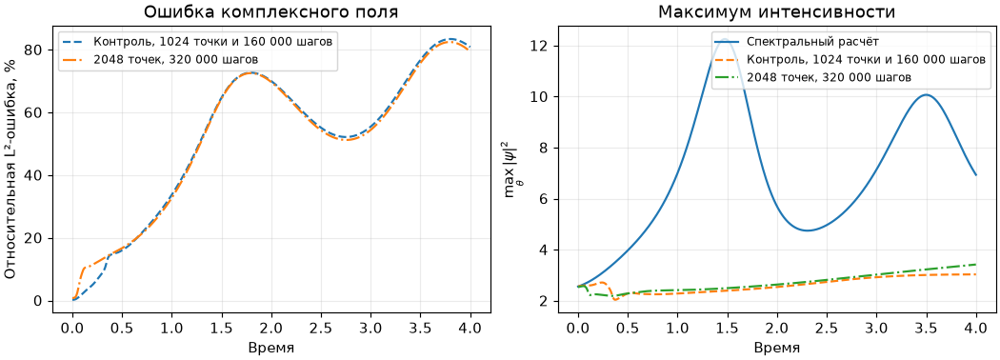

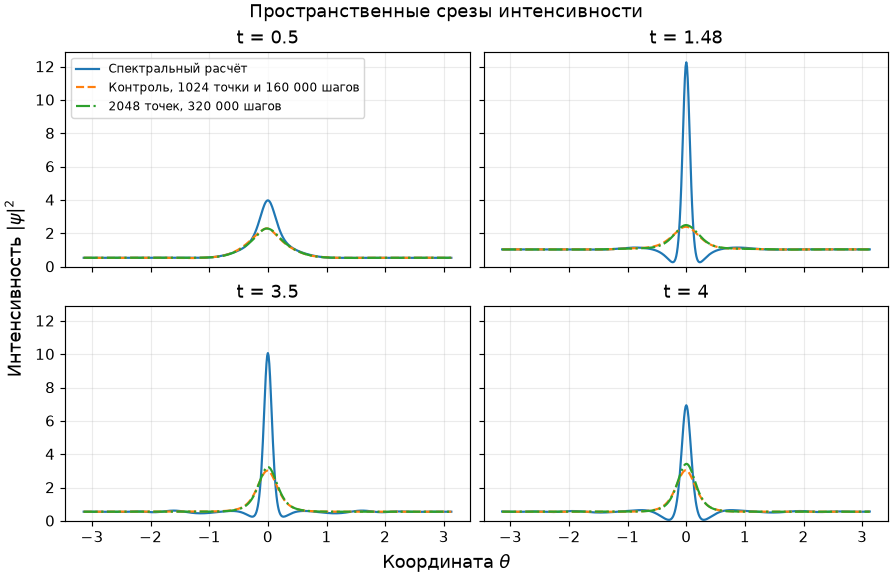

In [120]:
T4_2048_320K_RUN_ID = "2026-11-10_08-58-53_217255"
compare_t4_sweep(T4_2048_320K_RUN_ID, "2048 точек, 320 000 шагов")

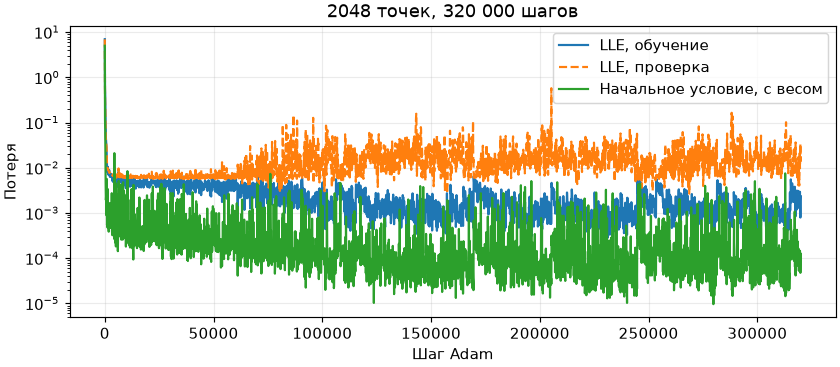

In [121]:
fig = plot_loss_history(T4_2048_320K_RUN_ID, "2048 точек, 320 000 шагов")
plt.show()

### 1024 точки, 320 000 шагов

Максимальная ошибка — 83.33% при t=3.8
На [0,2] максимальная ошибка — 72.84%


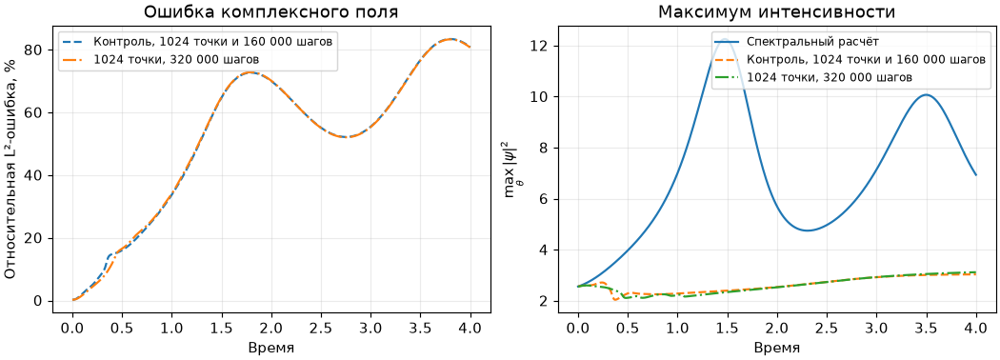

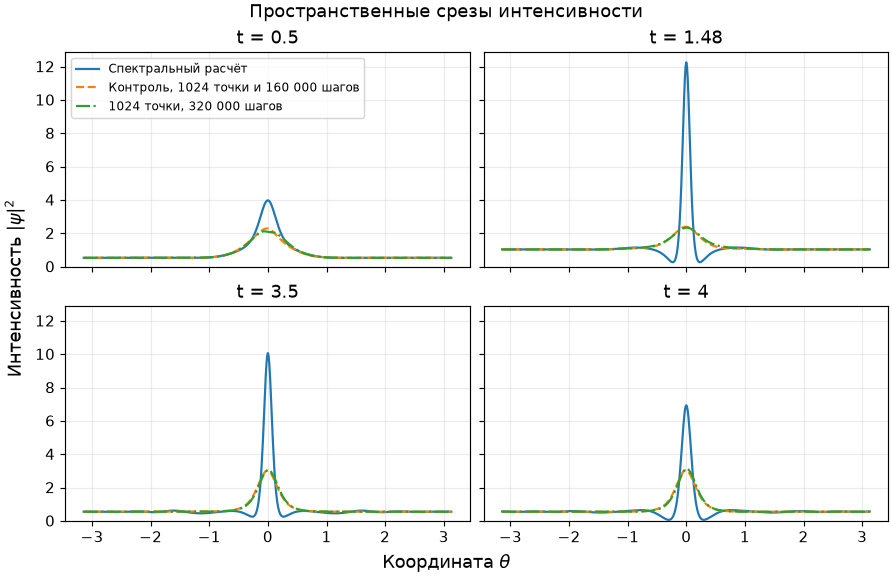

In [122]:
T4_1024_320K_RUN_ID = "2026-11-10_08-58-58_518504"
compare_t4_sweep(T4_1024_320K_RUN_ID, "1024 точки, 320 000 шагов")

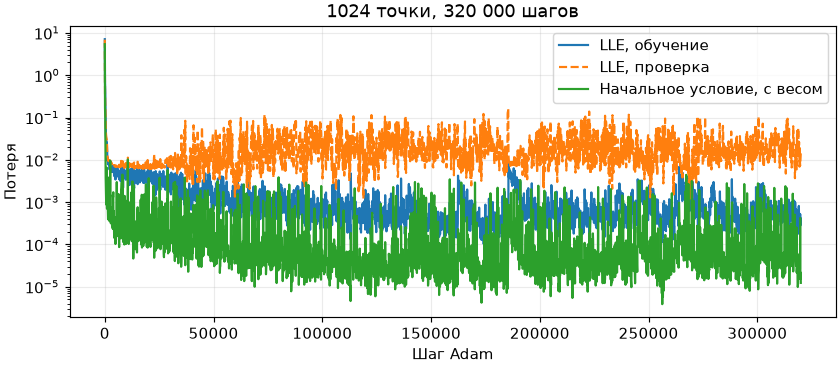

In [123]:
fig = plot_loss_history(T4_1024_320K_RUN_ID, "1024 точки, 320 000 шагов")
plt.show()

### Итоги

| Внутренние точки | Шаги Adam | Макс. $L^2$-ошибка | Пик при $t=1.48$ | Пик при $t=3.5$ | Пик при $t=4$ |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 1024 | 160 000 | 83,44 % | 2,39 | 3,01 | 3,03 |
| 2048 | 160 000 | 83,40 % | 2,45 | 3,02 | 3,07 |
| 2048 | 320 000 | 82,49 % | 2,49 | 3,23 | 3,42 |
| 1024 | 320 000 | 83,33 % | 2,33 | 3,05 | 3,12 |
| Спектральный расчёт | — | — | 12,26 | 10,07 | 6,94 |

Удвоение числа точек при 160 000 шагах почти не изменило результат. При 320 000 шагах вариант с 2048 точками немного лучше по ошибке поля. Все новые прогоны пропустили оба выраженных максимума. На $[0,2]$ их максимальная ошибка составляет 72,56–72,84 %, тогда как отдельное обучение до $T=2$ дало 2,84 % на этом же участке.

## Длина интервала, повтор базового запуска и варианты на $[0,4]$

Для всех запусков использован один спектральный эталон на $[0,4]$. Сравниваем максимумы относительной $L^2$-ошибки комплексного поля по сохранённым моментам времени на общем интервале $[0,2]$ и на всём интервале обучения. Контроль для базовых запусков с 1024 внутренними точками — прежняя PINN на $[0,2]$ с seed 42. Контроль для вариантов с 2048 точками — базовая PINN на $[0,4]$ с 160 000 шагов.

In [124]:
from csv import DictReader

horizon_reference = load_evolution(get_run(REFERENCE_T4_RUN_ID).path)
horizon_control = load_evolution(get_run(BASELINE160_RUN_ID).path)
t4_control = load_evolution(get_run(T4_2048_160K_RUN_ID).path)


def horizon_error(field, reference=None):
    if reference is None:
        reference = horizon_reference
    n = len(field.times)
    np.testing.assert_array_equal(field.theta, reference.theta)
    np.testing.assert_allclose(field.times, reference.times[:n], rtol=0, atol=1e-10)
    return relative_l2_error(field.values, reference.values[:n])


def show_horizon_run(run_id, title, control, control_label, times, *, reference=None, early_end=2):
    if reference is None:
        reference = horizon_reference
    variant = load_evolution(get_run(run_id).path)
    error = horizon_error(variant, reference)
    early = variant.times <= early_end + 1e-10
    print(f"Максимальная ошибка на [0,{early_end:g}] — {error[early].max():.2%}")
    print(f"Максимальная ошибка на [0,T] — {error.max():.2%} при t = {variant.times[error.argmax()]:g}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
    fig.suptitle(title)
    axes[0].plot(control.times, 100 * horizon_error(control, reference), "--", label=control_label)
    axes[0].plot(variant.times, 100 * error, label="Эксперимент")
    axes[0].set(title="Ошибка комплексного поля", xlabel="Время", ylabel="Относительная L²-ошибка, %")
    n = len(variant.times)
    axes[1].plot(reference.times[:n], reference.intensity.values[:n].max(axis=1),
                 label="Спектральный расчёт")
    axes[1].plot(control.times, control.intensity.values.max(axis=1), "--", label=control_label)
    axes[1].plot(variant.times, variant.intensity.values.max(axis=1), "-.", label="Эксперимент")
    axes[1].set(title="Пиковая интенсивность", xlabel="Время", ylabel=r"$\max_\theta |\psi|^2$")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.25)
    plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(9, 5.7), sharex=True, sharey=True, layout="constrained")
    fig.suptitle("Пространственные срезы интенсивности")
    for ax, time in zip(axes.flat, times):
        for field, label, style in ((reference, "Спектральный расчёт", "-"),
                                    (control, control_label, "--"), (variant, "Эксперимент", "-.")):
            if time <= field.times[-1] + 1e-10:
                profile = field.at_time(time).intensity
                ax.plot(profile.theta, profile.values, style, label=label)
        ax.set_title(f"t = {time:g}")
        ax.grid(alpha=0.25)
    axes[0, 0].set_ylim(bottom=0)
    axes[0, 0].legend(loc="upper left", fontsize=8)
    fig.supxlabel(r"Координата $\theta$")
    fig.supylabel(r"Интенсивность $|\psi|^2$")
    plt.show()

### Базовая PINN, T = 2,5

Максимальная ошибка на [0,2] — 71.48%
Максимальная ошибка на [0,T] — 71.48% при t = 1.77


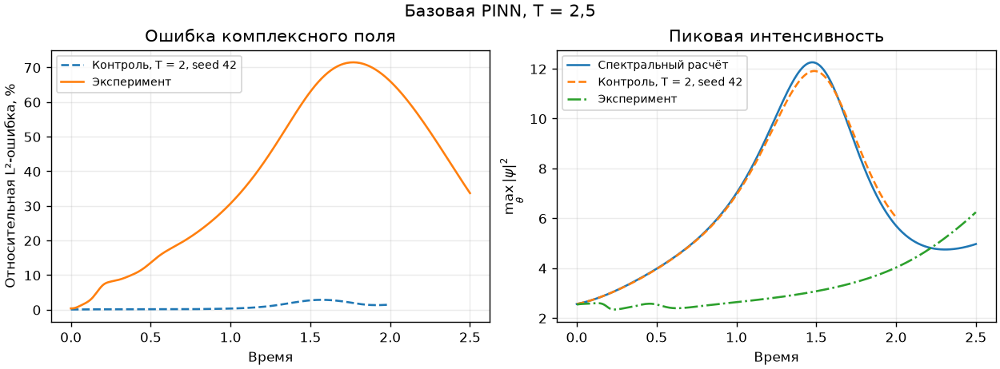

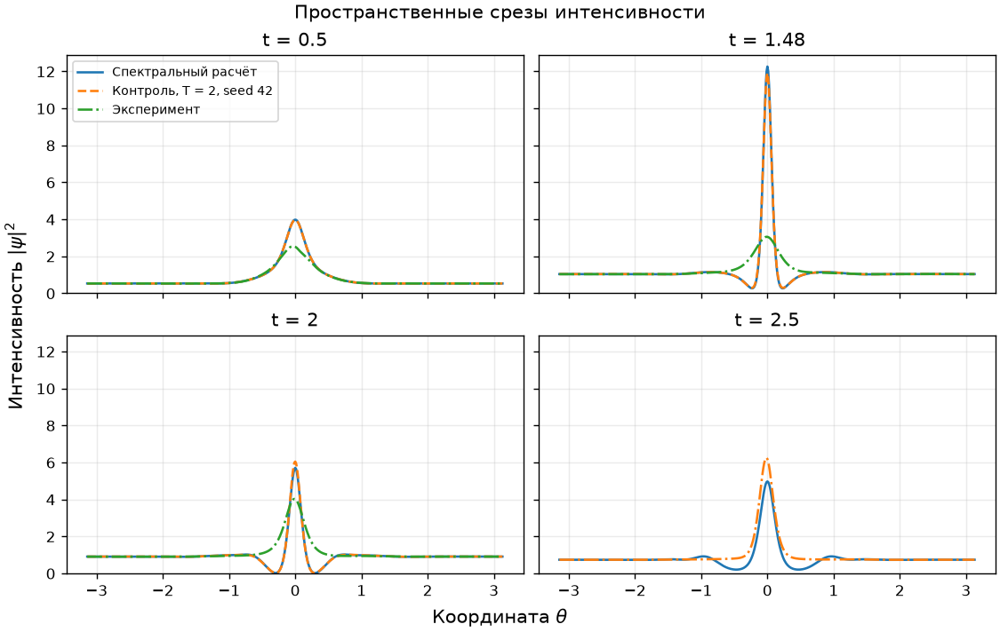

In [125]:
HORIZON_25_RUN_ID = "2026-11-11_01-38-55_693579"
show_horizon_run(HORIZON_25_RUN_ID, 'Базовая PINN, T = 2,5', horizon_control, 'Контроль, T = 2, seed 42', (0.5, 1.48, 2, 2.5))

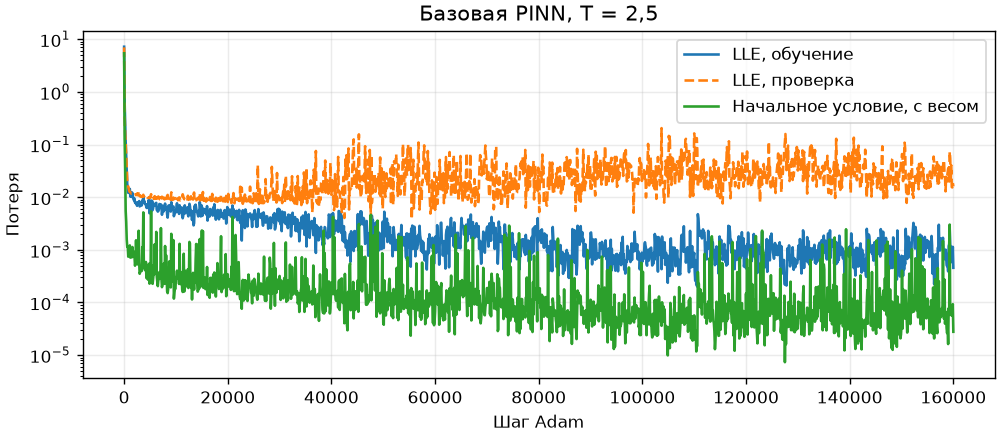

In [126]:
fig = plot_loss_history(HORIZON_25_RUN_ID, 'Базовая PINN, T = 2,5')
plt.show()

### Базовая PINN, T = 3

Максимальная ошибка на [0,2] — 72.86%
Максимальная ошибка на [0,T] — 72.86% при t = 1.79


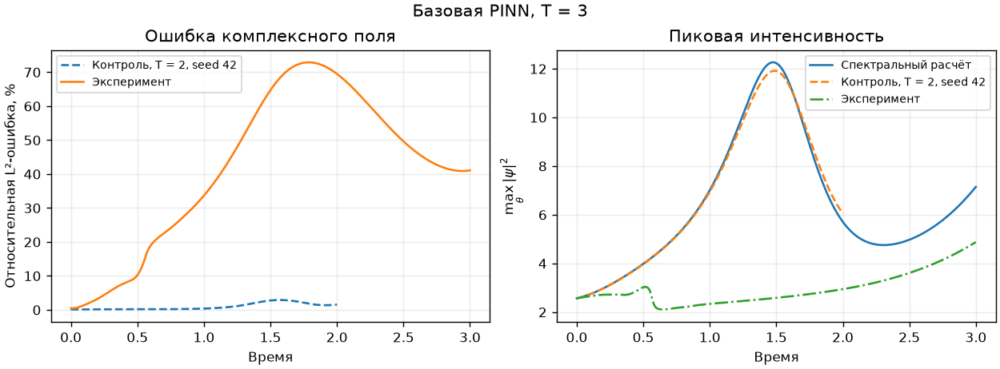

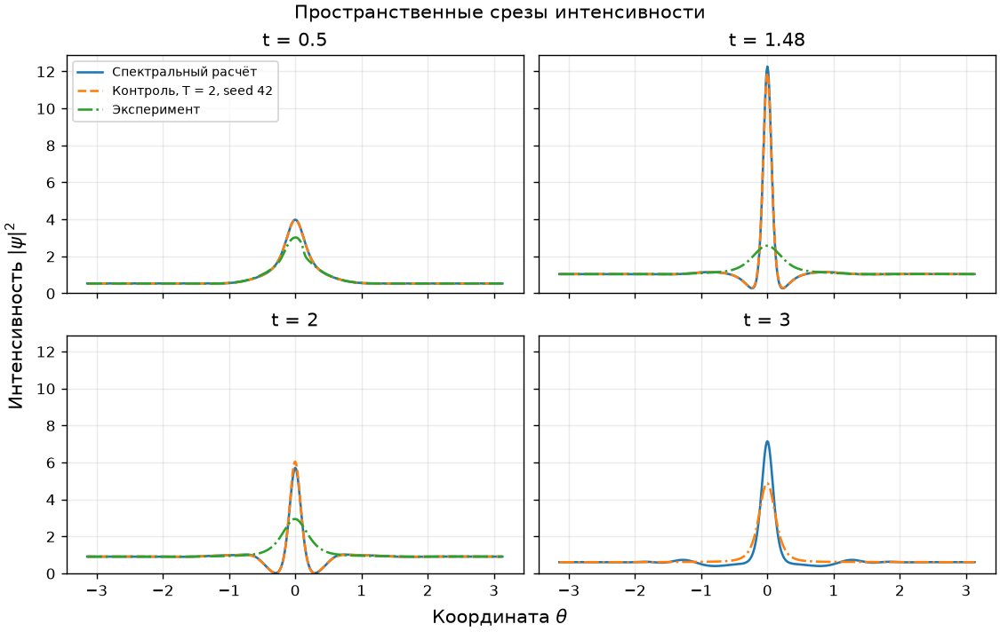

In [127]:
HORIZON_3_RUN_ID = "2026-11-11_01-39-00_638191"
show_horizon_run(HORIZON_3_RUN_ID, 'Базовая PINN, T = 3', horizon_control, 'Контроль, T = 2, seed 42', (0.5, 1.48, 2, 3))

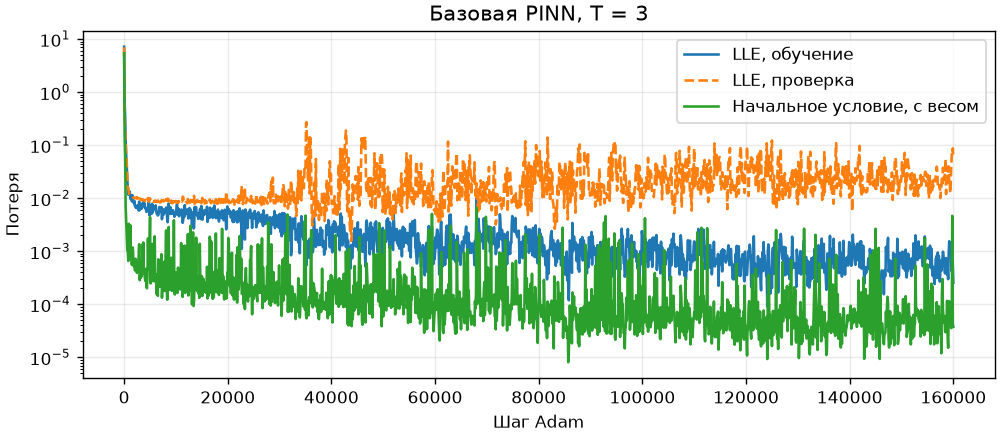

In [128]:
fig = plot_loss_history(HORIZON_3_RUN_ID, 'Базовая PINN, T = 3')
plt.show()

### Базовая PINN, T = 3,5

Максимальная ошибка на [0,2] — 72.58%
Максимальная ошибка на [0,T] — 77.11% при t = 3.5


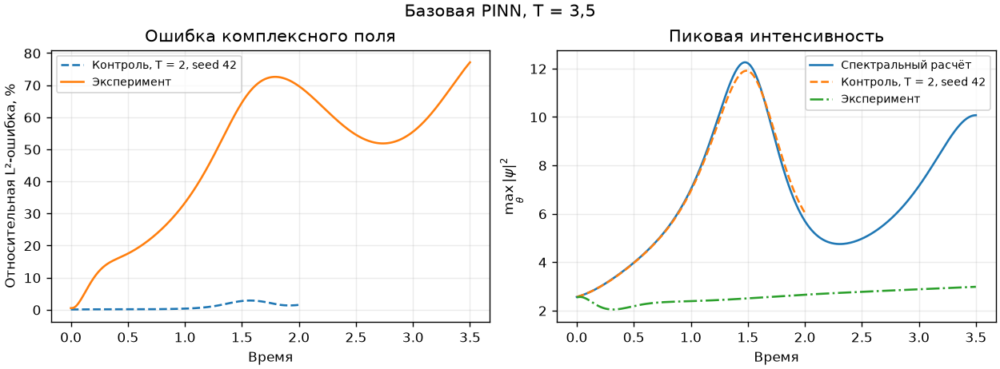

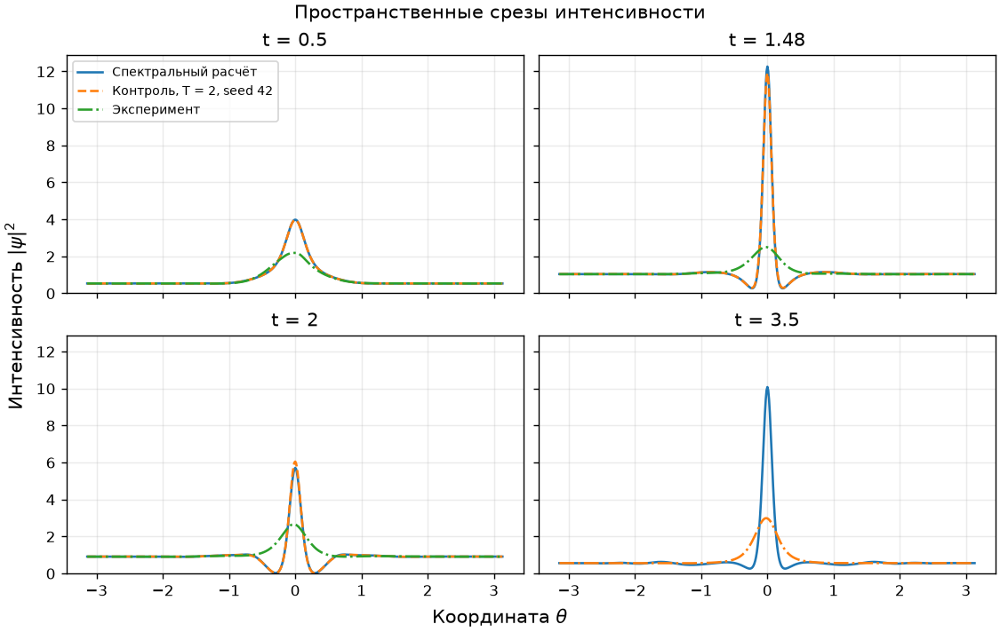

In [129]:
HORIZON_35_RUN_ID = "2026-11-11_01-39-07_039396"
show_horizon_run(HORIZON_35_RUN_ID, 'Базовая PINN, T = 3,5', horizon_control, 'Контроль, T = 2, seed 42', (0.5, 1.48, 2, 3.5))

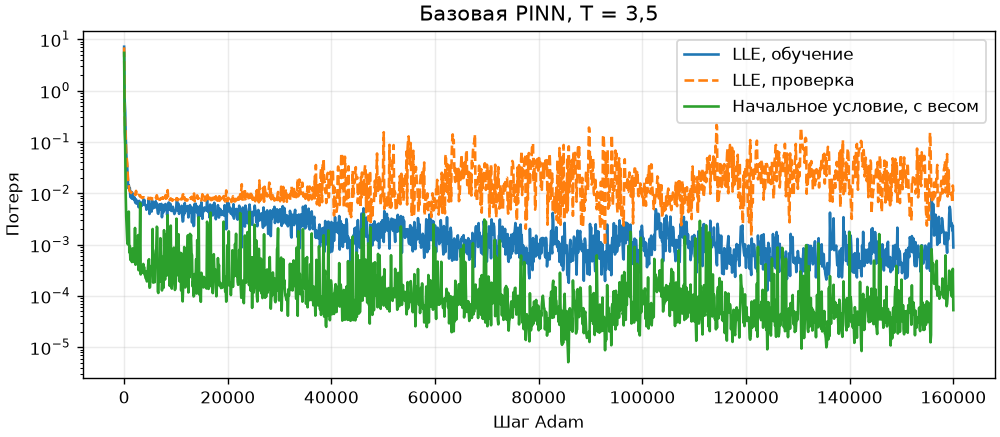

In [130]:
fig = plot_loss_history(HORIZON_35_RUN_ID, 'Базовая PINN, T = 3,5')
plt.show()

### Базовая PINN, T = 2, seed 43

Максимальная ошибка на [0,2] — 3.95%
Максимальная ошибка на [0,T] — 3.95% при t = 1.62


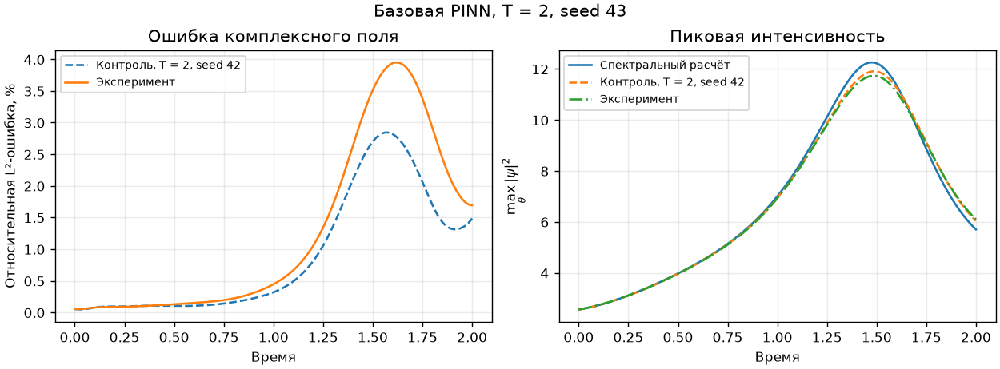

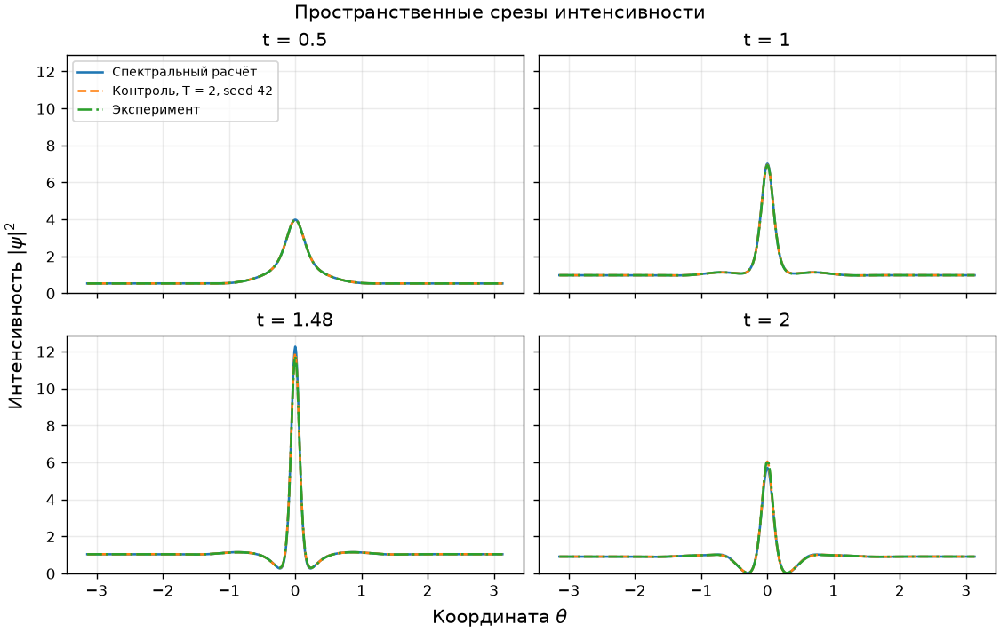

In [131]:
HORIZON_SEED43_RUN_ID = "2026-11-11_03-23-59_789179"
show_horizon_run(HORIZON_SEED43_RUN_ID, 'Базовая PINN, T = 2, seed 43', horizon_control, 'Контроль, T = 2, seed 42', (0.5, 1, 1.48, 2))

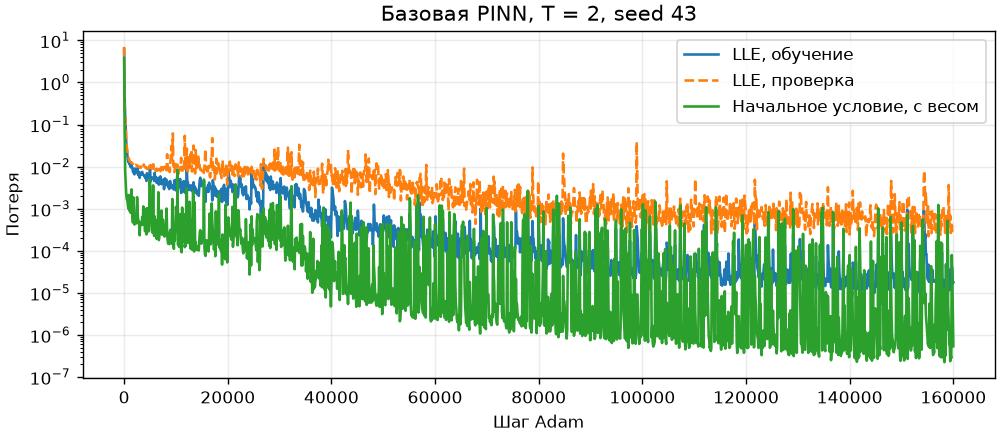

In [132]:
fig = plot_loss_history(HORIZON_SEED43_RUN_ID, 'Базовая PINN, T = 2, seed 43')
plt.show()

### Причинное взвешивание, T = 4

Максимальная ошибка на [0,2] — 71.65%
Максимальная ошибка на [0,T] — 81.95% при t = 3.8


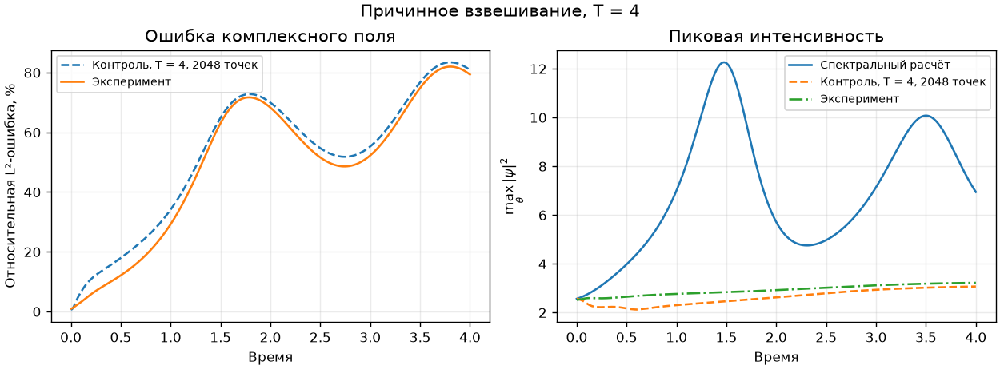

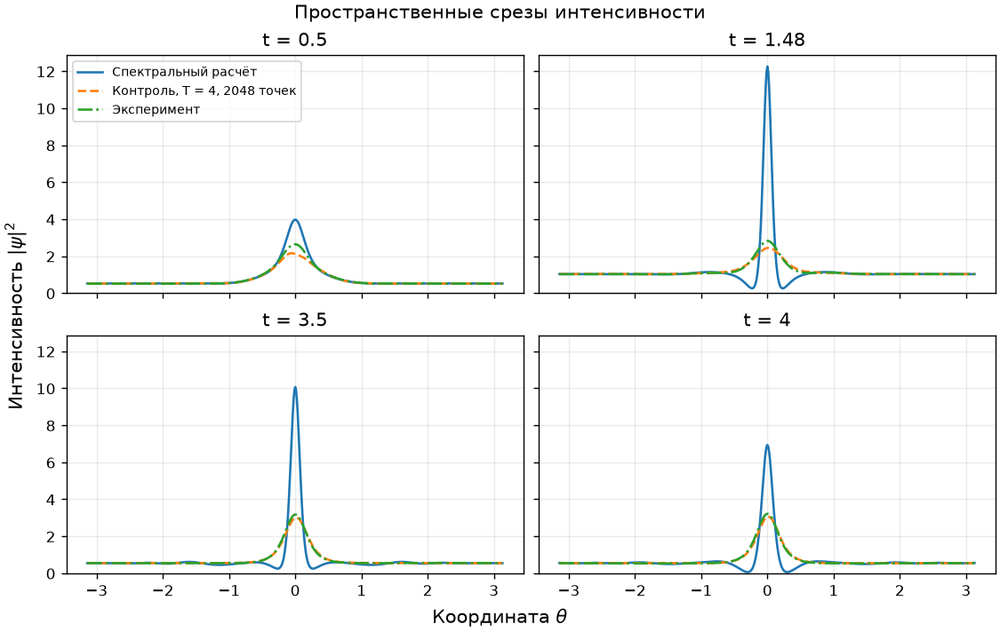

In [133]:
HORIZON_CAUSAL_RUN_ID = "2026-11-11_04-35-48_441099"
show_horizon_run(HORIZON_CAUSAL_RUN_ID, 'Причинное взвешивание, T = 4', t4_control, 'Контроль, T = 4, 2048 точек', (0.5, 1.48, 3.5, 4))

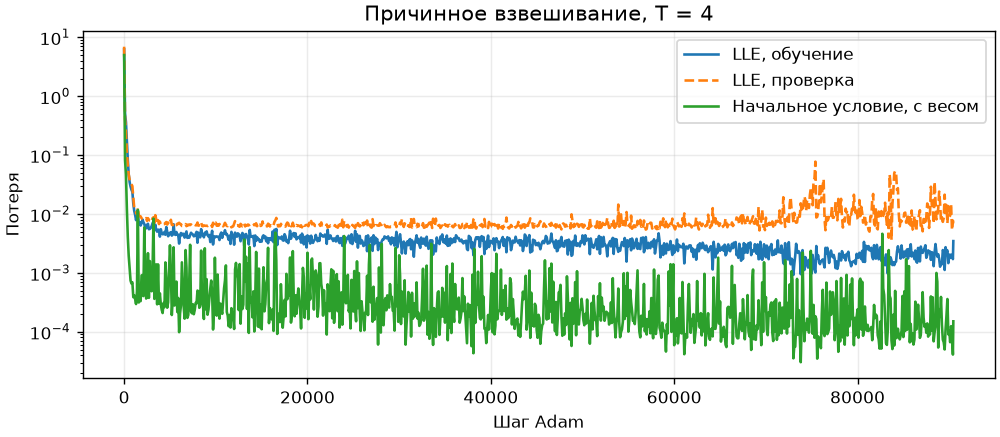

In [134]:
fig = plot_loss_history(HORIZON_CAUSAL_RUN_ID, 'Причинное взвешивание, T = 4')
plt.show()

In [135]:
causal_run = get_run(HORIZON_CAUSAL_RUN_ID)
with (causal_run.path / "causal_stages.csv").open(newline="", encoding="utf-8") as file:
    causal_stages_t4 = list(DictReader(file))

print("ε       Шаги   Мин. вес  Причина завершения   Макс. ошибка на [0,4]")
for stage in causal_stages_t4:
    steps = int(stage["last_step"]) - int(stage["first_step"]) + 1
    number = int(stage["number"])
    field = load_evolution(causal_run.path / f"stage_{number:02d}")
    reason = {"threshold": "порог", "step_limit": "лимит шагов"}[stage["reason"]]
    print(f'{float(stage["epsilon"]):<6g} {steps:>6}   {float(stage["min_weight"]):.4f}    '
          f'{reason:<20} {horizon_error(field).max():.2%}')

ε       Шаги   Мин. вес  Причина завершения   Макс. ошибка на [0,4]
0.01      237   0.9900    порог                118.86%
0.1       549   0.9900    порог                107.84%
1       25660   0.9900    порог                83.35%
10      32000   0.8972    лимит шагов          83.08%
100     32000   0.1325    лимит шагов          81.95%


### Ширина 128 и 12 гармоник, T = 4

Максимальная ошибка на [0,2] — 72.94%
Максимальная ошибка на [0,T] — 83.59% при t = 3.8


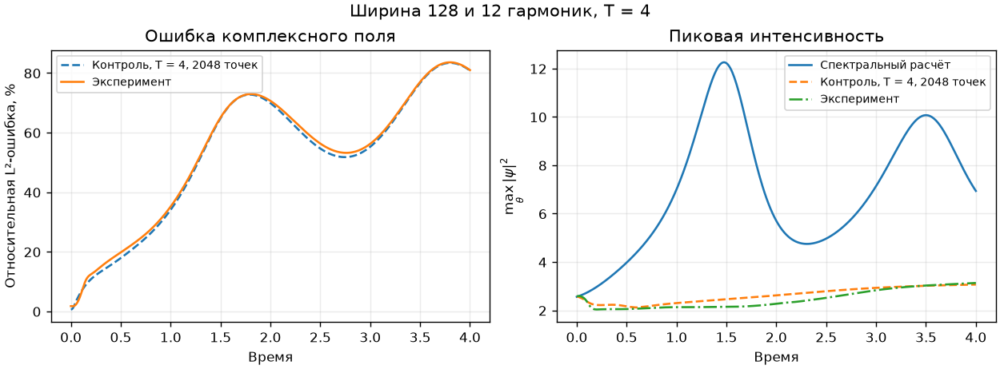

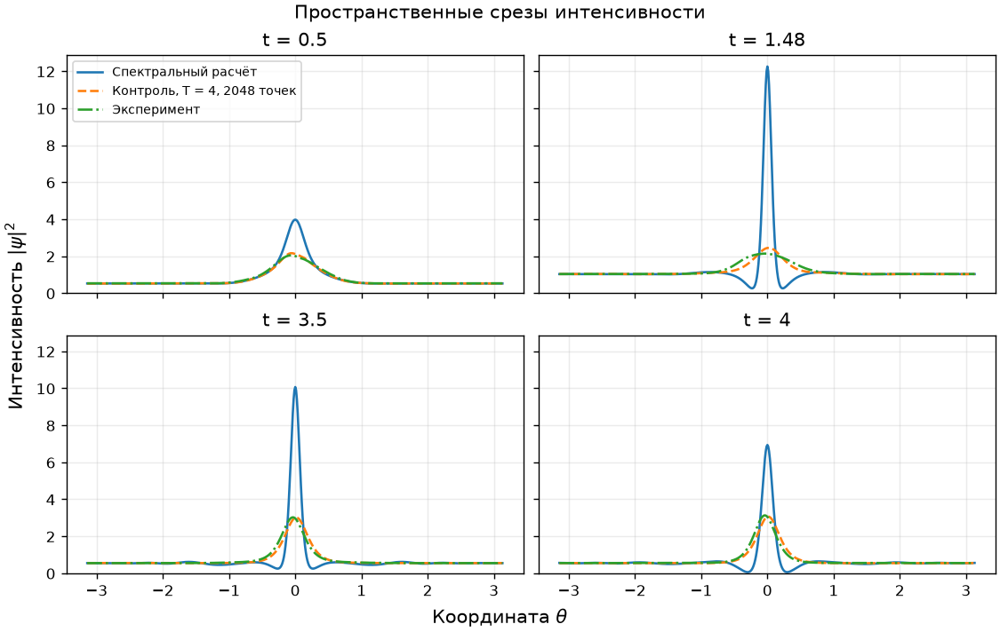

In [136]:
HORIZON_WIDE_RUN_ID = "2026-11-11_05-17-31_596118"
show_horizon_run(HORIZON_WIDE_RUN_ID, 'Ширина 128 и 12 гармоник, T = 4', t4_control, 'Контроль, T = 4, 2048 точек', (0.5, 1.48, 3.5, 4))

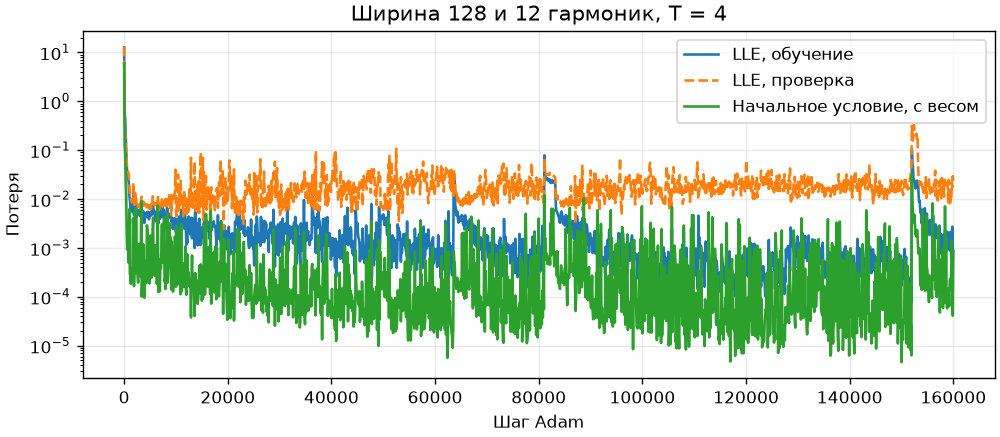

In [137]:
fig = plot_loss_history(HORIZON_WIDE_RUN_ID, 'Ширина 128 и 12 гармоник, T = 4')
plt.show()

### Итоги

| Вариант | Макс. ошибка на $[0,2]$ | Макс. ошибка на $[0,T]$ | Пиковая интенсивность при $t=1{,}48$ |
|---|---:|---:|---:|
| Контроль, $T=2$, seed 42 | 2,84% | 2,84% | 11,91 |
| $T=2$, seed 43 | 3,95% | 3,95% | 11,73 |
| $T=2{,}5$ | 71,48% | 71,48% | 3,05 |
| $T=3$ | 72,86% | 72,86% | 2,57 |
| $T=3{,}5$ | 72,58% | 77,11% | 2,49 |
| Контроль, $T=4$, 2048 точек | 72,75% | 83,40% | 2,45 |
| $T=4$, причинное взвешивание | 71,65% | 81,95% | 2,83 |
| $T=4$, ширина 128, 12 гармоник | 72,94% | 83,59% | 2,14 |

Спектральный пик при $t=1{,}48$ равен 12,26. Оба запуска до $T=2$ воспроизводят его, а при обучении до $T=2{,}5$ и дальше пик сильно занижен уже внутри $[0,2]$. Резкая деградация наблюдается между проверенными $T=2$ и $T=2{,}5$. Новый seed проверен только при $T=2$. При увеличении $T$ число внутренних точек сохранялось, поэтому одновременно менялась их плотность по времени. Для прежнего контрольного запуска до $T=2$ устройство в метаданных отсутствует.

В причинном запуске первые три стадии закончились по порогу 0,99, а последние две использовали весь лимит. Фактический бюджет составил 90 446 шагов. Ошибка по ходу стадий в итоге снизилась до 81,95%, но пик при $t=1{,}48$ остался на уровне 2,83. При одинаковом бюджете в 160 000 шагов увеличение ширины и числа гармоник вместе дало 83,59% против 83,40% у контроля на $[0,4]$.

## Уточнение границы обучения и увеличение ресурсов при $T=2{,}5$

Завершены 13 новых запусков на NVIDIA GeForce RTX 4060 Laptop GPU. Четыре уточняют зависимость от длины интервала, девять проверяют архитектуру, число внутренних точек и число шагов при $T=2{,}5$. Для сравнения взяты прежние базовые запуски при $T=2$ и $T=2{,}5$.

Относительная $L^2$-ошибка комплексного поля вычислена по общему спектральному расчёту на совпадающих пространственных и временных сетках. Максимумы берутся по сохранённым срезам с шагом $\Delta t=0{,}01$. Пиковая интенсивность при $t=1{,}48$ в спектральном расчёте равна 12,26.

In [138]:
from lle.workflows.pinn_gaussian.config import PinnGaussianConfig

sweep_t25_control = load_evolution(get_run(HORIZON_25_RUN_ID).path)


def t25_metrics(run_id):
    run = get_run(run_id)
    config = run.load_config(PinnGaussianConfig)
    field = load_evolution(run.path)
    error = horizon_error(field)
    early = field.times <= 2 + 1e-10
    late = field.times >= 2 - 1e-10
    losses = np.genfromtxt(run.path / "losses.csv", delimiter=",", names=True)
    assert run.load_metadata()["status"] == "complete"
    assert losses["step"][-1] == config.training.iterations
    return (config, error[early].max(), error[late].max(), error.max(),
            field.at_time(1.48).intensity.values.max())

### Базовая PINN при разных горизонтах

Сеть 4 × 64, 4 гармоники, 1024 внутренние точки, 160 000 шагов Adam и seed 42.

| Вариант | Макс. ошибка на $[0,2]$ | На $[2,T]$ | На $[0,T]$ | Пик при $t=1{,}48$ |
| --- | ---: | ---: | ---: | ---: |
| T=2 | 2,84% | — | 2,84% | 11,91 |
| T=2,1 | 3,67% | 2,36% | 3,67% | 11,74 |
| T=2,2 | 69,22% | 59,76% | 69,22% | 3,60 |
| T=2,3 | 70,86% | 64,28% | 70,86% | 3,21 |
| T=2,4 | 72,15% | 67,47% | 72,15% | 2,90 |
| T=2,5 | 71,48% | 66,02% | 71,48% | 3,05 |

При $T=2{,}1$ максимальная ошибка составляет 3,67%, а при $T=2{,}2$ вырастает до 69,22% уже внутри общего интервала $[0,2]$. Это граница между соседними проверенными горизонтами для данной конфигурации и seed. При фиксированном числе точек с ростом $T$ уменьшается их средняя плотность по времени.

#### T = 2,1

Максимальная ошибка на [0,2] — 3.67%
Максимальная ошибка на [0,T] — 3.67% при t = 1.6


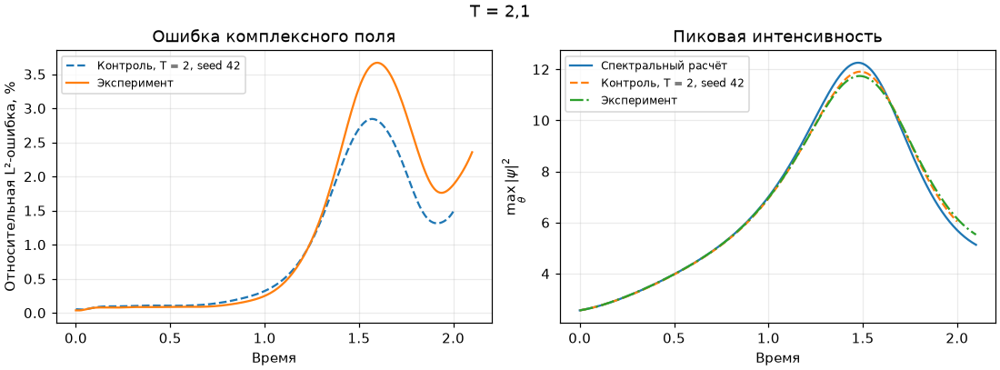

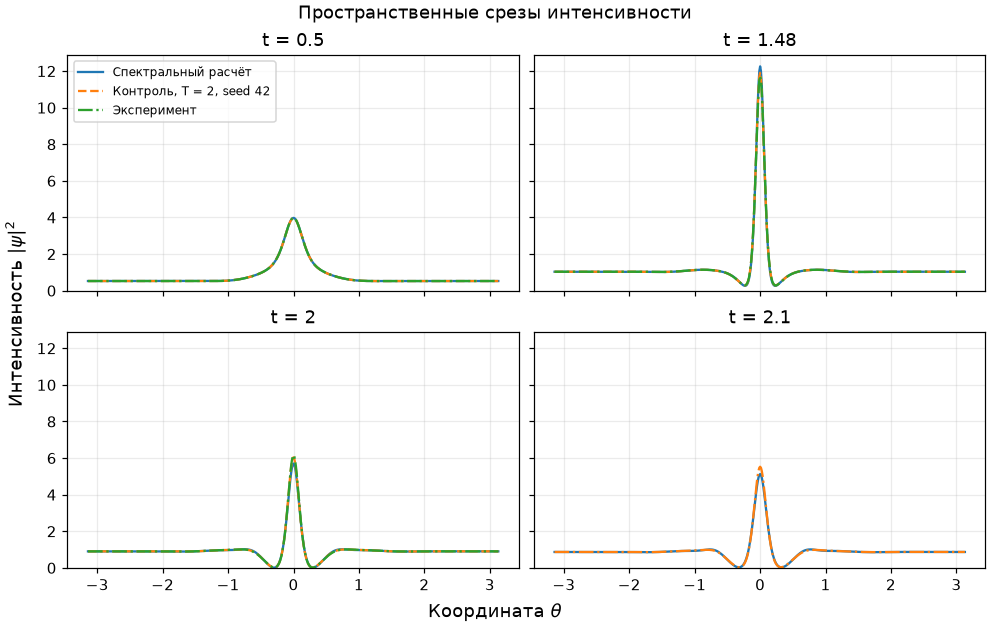

In [139]:
SHORT_HORIZON_1_RUN_ID = "2026-11-12_16-03-25_526046"
show_horizon_run(SHORT_HORIZON_1_RUN_ID, 'T = 2,1', horizon_control, 'Контроль, T = 2, seed 42', (0.5, 1.48, 2.0, 2.1))

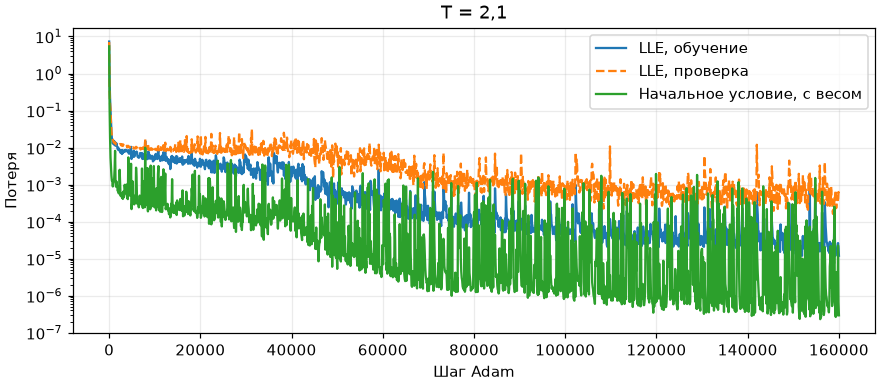

In [140]:
fig = plot_loss_history(SHORT_HORIZON_1_RUN_ID, 'T = 2,1')
plt.show()

#### T = 2,2

Максимальная ошибка на [0,2] — 69.22%
Максимальная ошибка на [0,T] — 69.22% при t = 1.74


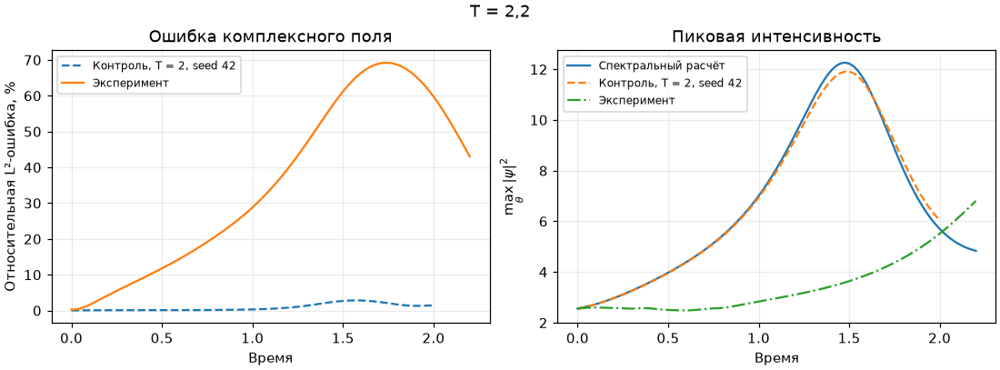

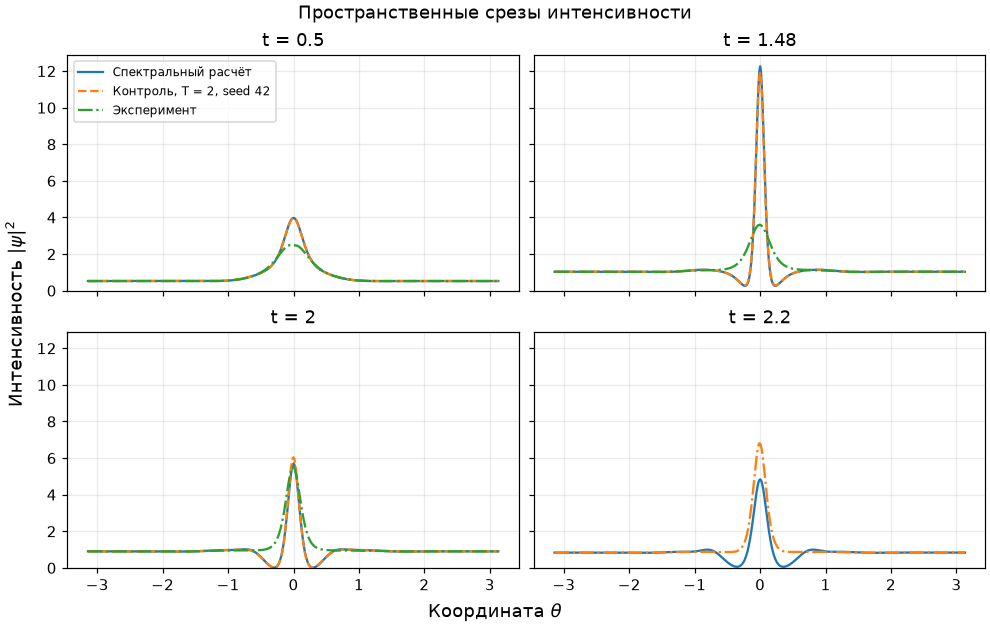

In [141]:
SHORT_HORIZON_2_RUN_ID = "2026-11-12_16-03-36_203057"
show_horizon_run(SHORT_HORIZON_2_RUN_ID, 'T = 2,2', horizon_control, 'Контроль, T = 2, seed 42', (0.5, 1.48, 2.0, 2.2))

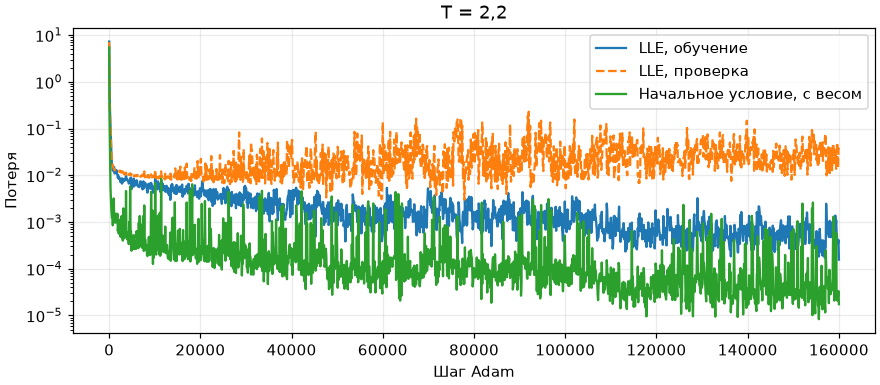

In [142]:
fig = plot_loss_history(SHORT_HORIZON_2_RUN_ID, 'T = 2,2')
plt.show()

#### T = 2,3

Максимальная ошибка на [0,2] — 70.86%
Максимальная ошибка на [0,T] — 70.86% при t = 1.76


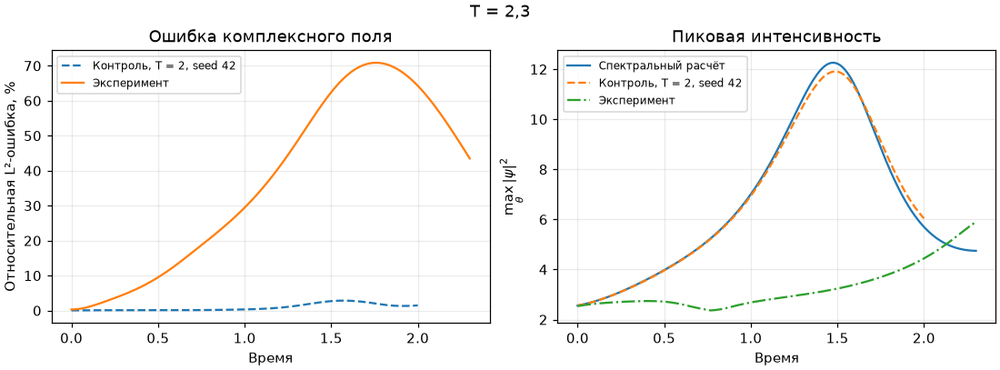

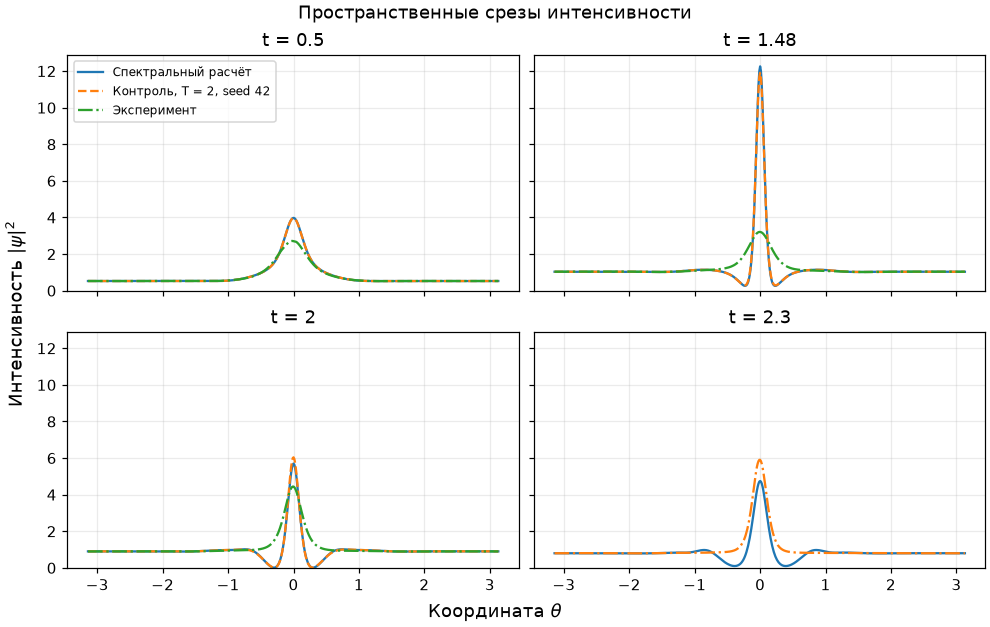

In [143]:
SHORT_HORIZON_3_RUN_ID = "2026-11-12_16-03-47_099225"
show_horizon_run(SHORT_HORIZON_3_RUN_ID, 'T = 2,3', horizon_control, 'Контроль, T = 2, seed 42', (0.5, 1.48, 2.0, 2.3))

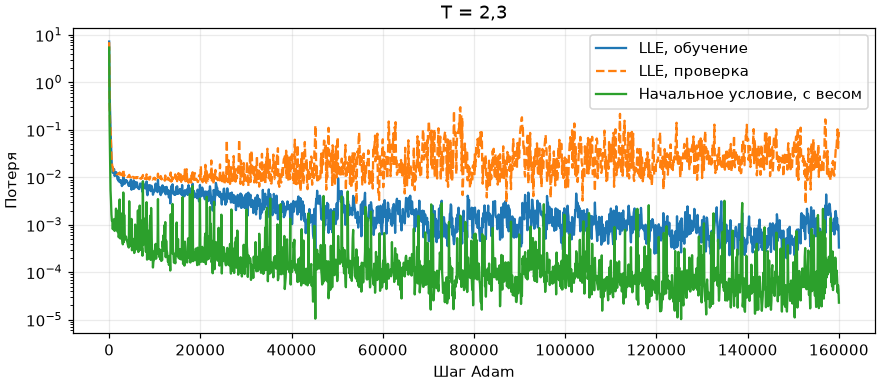

In [144]:
fig = plot_loss_history(SHORT_HORIZON_3_RUN_ID, 'T = 2,3')
plt.show()

#### T = 2,4

Максимальная ошибка на [0,2] — 72.15%
Максимальная ошибка на [0,T] — 72.15% при t = 1.78


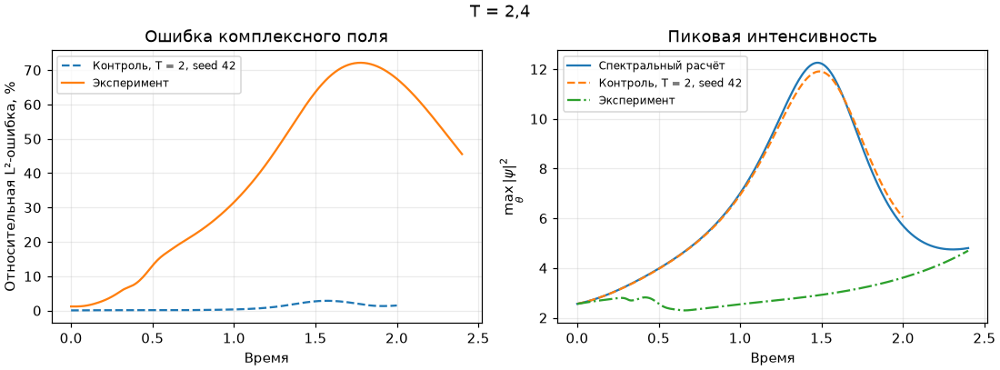

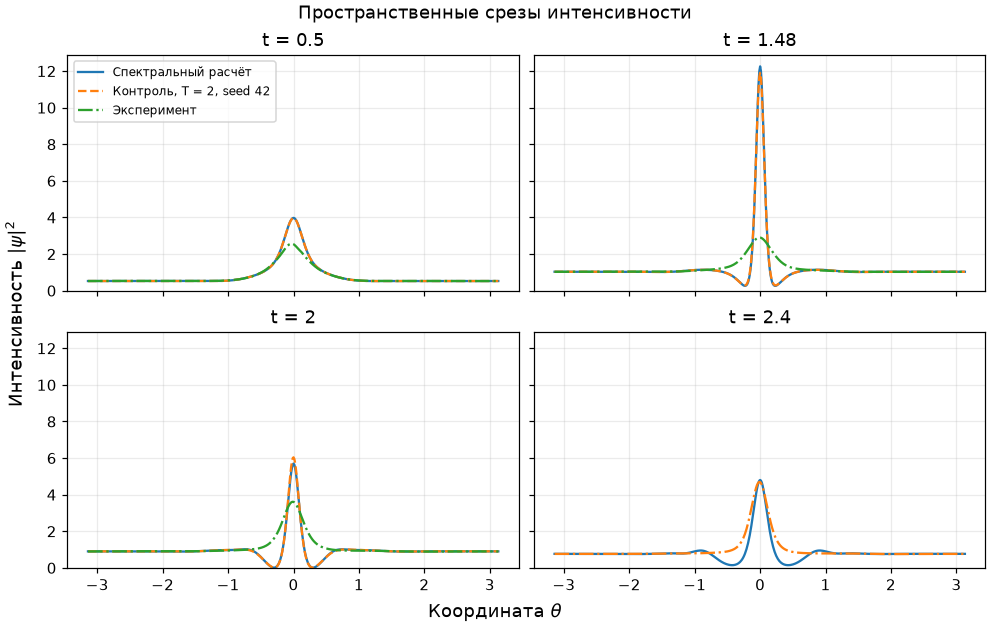

In [145]:
SHORT_HORIZON_4_RUN_ID = "2026-11-12_16-03-57_802852"
show_horizon_run(SHORT_HORIZON_4_RUN_ID, 'T = 2,4', horizon_control, 'Контроль, T = 2, seed 42', (0.5, 1.48, 2.0, 2.4))

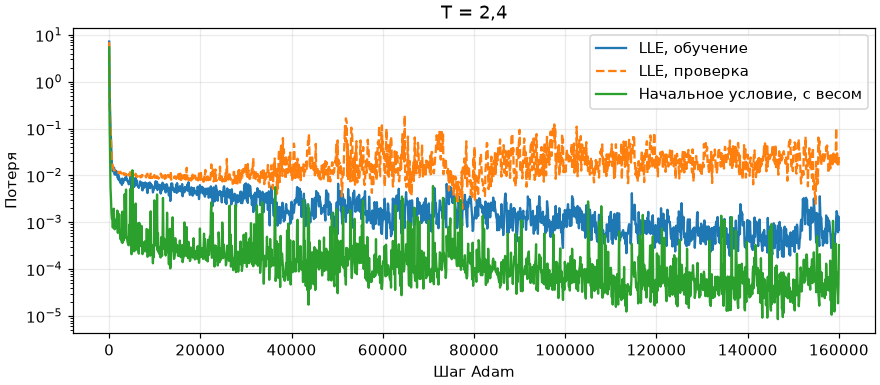

In [146]:
fig = plot_loss_history(SHORT_HORIZON_4_RUN_ID, 'T = 2,4')
plt.show()

### Девять вариантов при $T=2{,}5$

| Вариант | Слои × ширина | Гармоники | Точки | Шаги Adam | Макс. ошибка на $[0,2]$ | На $[2,T]$ | На $[0,T]$ | Пик при $t=1{,}48$ |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Контроль | 4 × 64 | 4 | 1024 | 160 тыс. | 71,48% | 66,02% | 71,48% | 3,05 |
| 01. Больше шагов | 4 × 64 | 4 | 1024 | 320 тыс. | 71,76% | 66,32% | 71,76% | 3,07 |
| 02. Больше точек | 4 × 64 | 4 | 4096 | 160 тыс. | 1,58% | 1,37% | 1,58% | 12,07 |
| 03. Больше гармоник | 4 × 64 | 12 | 1024 | 160 тыс. | 72,40% | 68,75% | 72,40% | 2,67 |
| 04. Шире сеть | 4 × 128 | 4 | 1024 | 160 тыс. | 72,77% | 69,29% | 72,77% | 2,60 |
| 05. Шире сеть, больше гармоник, точек и шагов | 4 × 128 | 12 | 4096 | 320 тыс. | 70,87% | 64,17% | 70,87% | 3,29 |
| 06. № 05 с удвоенным бюджетом | 4 × 128 | 12 | 4096 | 640 тыс. | 71,46% | 65,67% | 71,46% | 3,15 |
| 07. № 05 с удвоенным числом точек | 4 × 128 | 12 | 8192 | 320 тыс. | 0,98% | 0,88% | 0,98% | 12,13 |
| 08. № 05 с большей глубиной | 6 × 128 | 12 | 4096 | 320 тыс. | 71,57% | 66,03% | 71,57% | 3,03 |
| 09. № 05 с большей шириной | 4 × 256 | 12 | 4096 | 320 тыс. | 72,42% | 68,06% | 72,42% | 2,80 |

Критерий до 5% на обоих участках выполнен в двух запусках. № 02 с базовой сетью и 4096 точками дал 1,58% на всём интервале. № 07 с сетью 4 × 128, 12 гармониками и 8192 точками дал 0,98%. Пиковая интенсивность при $t=2{,}5$ составляет 4,97 у спектрального решения, 5,02 у № 02 и 5,03 у № 07.

Увеличение числа точек сработало в двух парных сравнениях при фиксированных архитектуре и бюджете. У базовой сети переход с 1024 на 4096 точек снизил ошибку с 71,48% до 1,58%. У сети 4 × 128 с 12 гармониками переход с 4096 на 8192 точки при 320 000 шагах снизил ошибку с 70,87% до 0,98%. В текущей конфигурации вместе с числом внутренних точек растёт число проверочных точек. Итоговая ошибка во всех строках измерена на общей сетке спектрального решения. Варианты с удвоенным числом шагов в обеих архитектурах остались около 71–72%. Оба успешных результата получены с seed 42.

#### № 01. Больше шагов

Максимальная ошибка на [0,2] — 71.76%
Максимальная ошибка на [0,T] — 71.76% при t = 1.77


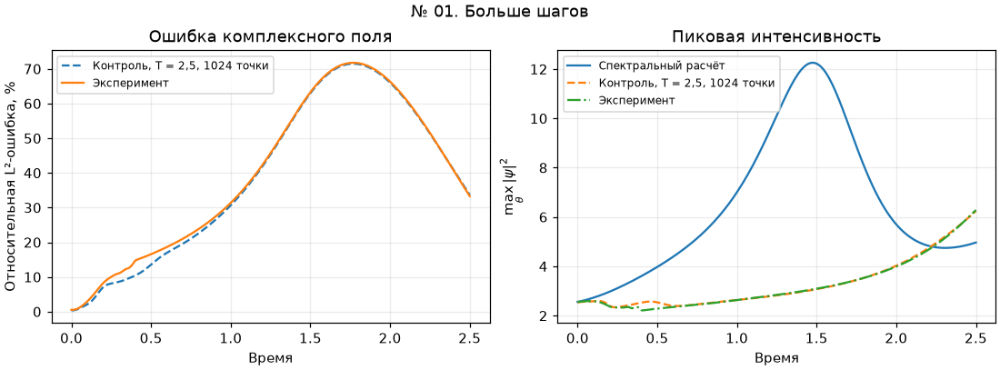

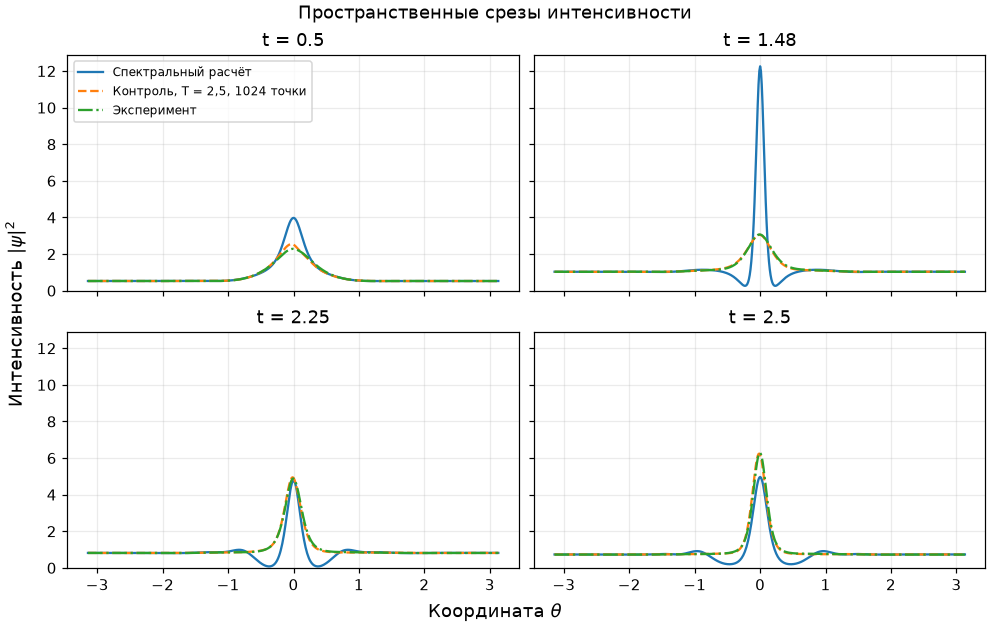

In [147]:
SWEEP_T25_01_RUN_ID = "2026-11-11_11-24-48_345623"
show_horizon_run(SWEEP_T25_01_RUN_ID, '№ 01. Больше шагов', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

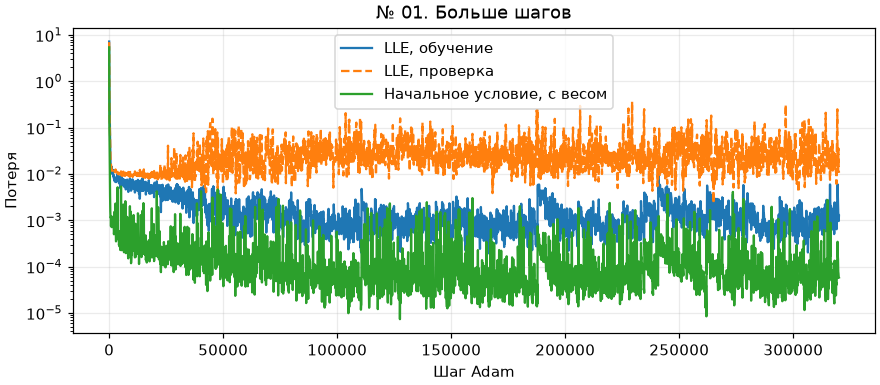

In [148]:
fig = plot_loss_history(SWEEP_T25_01_RUN_ID, '№ 01. Больше шагов')
plt.show()

#### № 02. Больше точек

Максимальная ошибка на [0,2] — 1.58%
Максимальная ошибка на [0,T] — 1.58% при t = 1.57


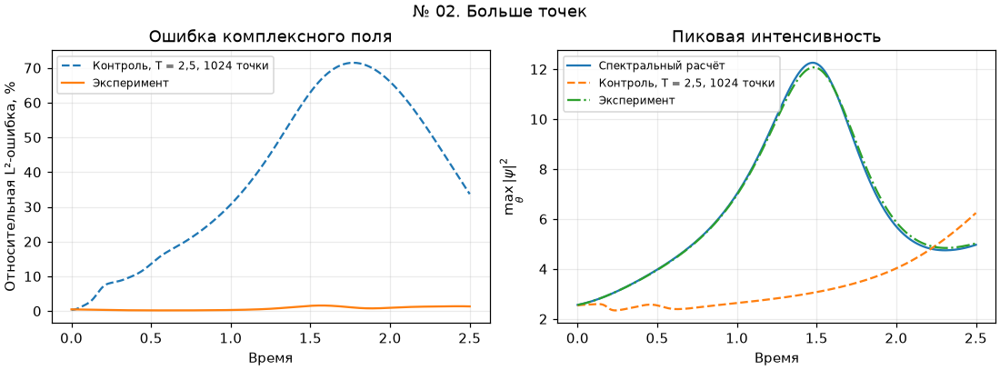

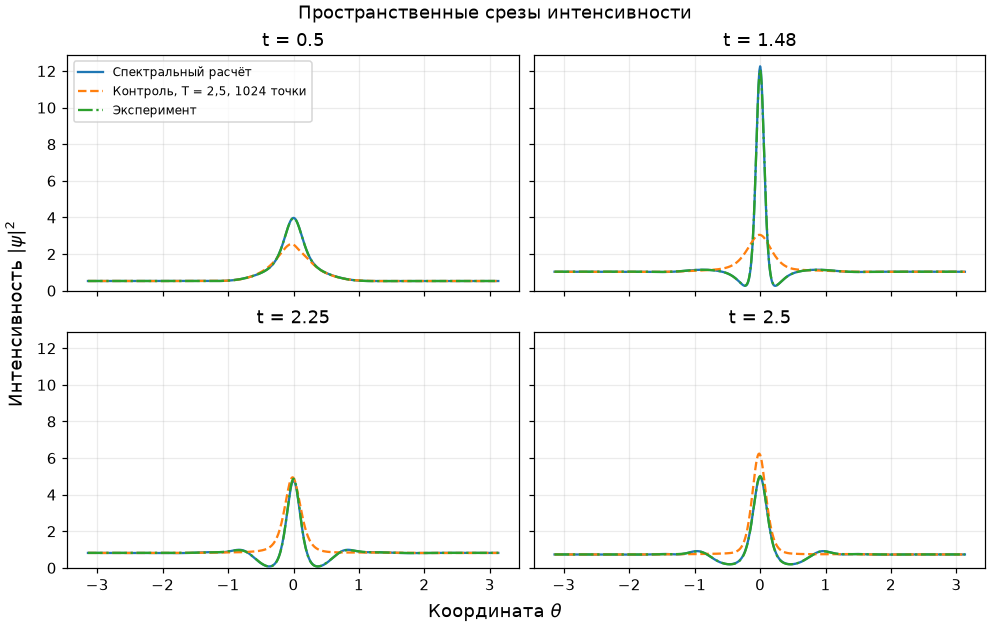

In [149]:
SWEEP_T25_02_RUN_ID = "2026-11-11_11-24-48_876931"
show_horizon_run(SWEEP_T25_02_RUN_ID, '№ 02. Больше точек', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

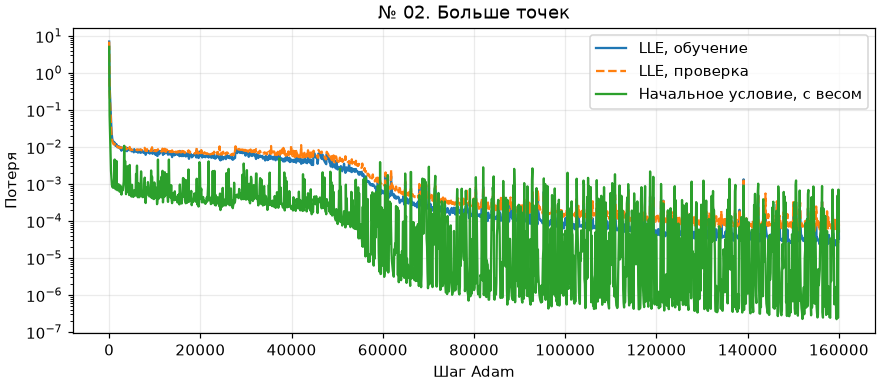

In [150]:
fig = plot_loss_history(SWEEP_T25_02_RUN_ID, '№ 02. Больше точек')
plt.show()

#### № 03. Больше гармоник

Максимальная ошибка на [0,2] — 72.40%
Максимальная ошибка на [0,T] — 72.40% при t = 1.79


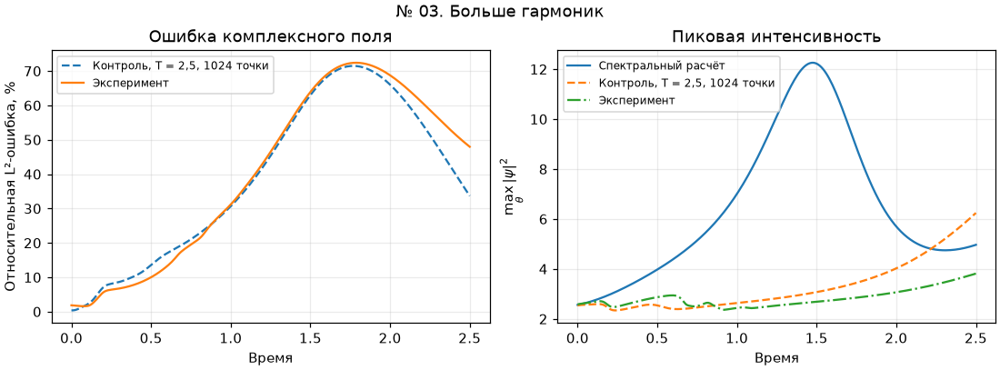

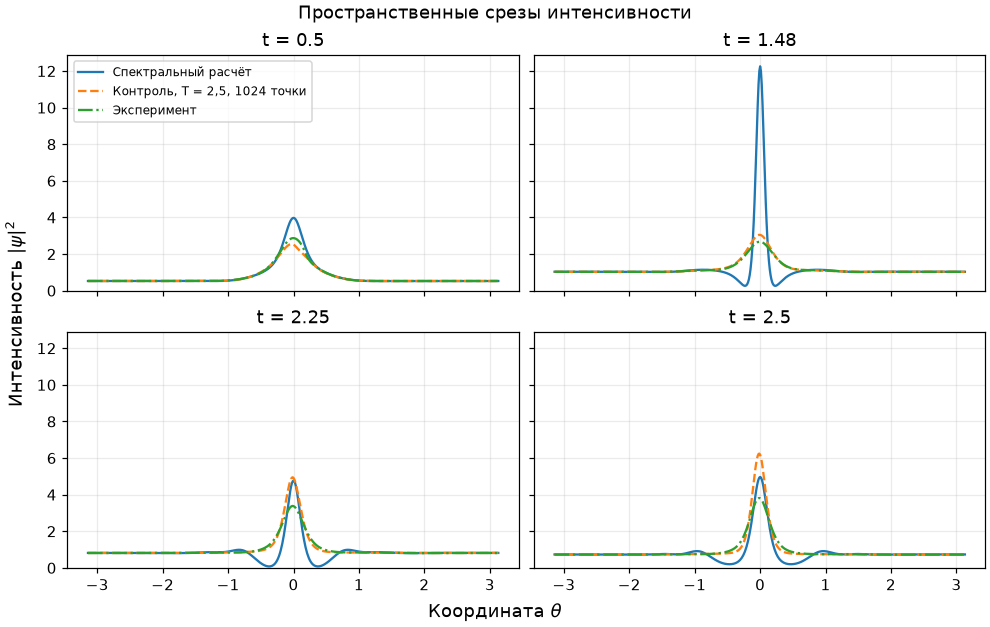

In [151]:
SWEEP_T25_03_RUN_ID = "2026-11-11_11-24-54_935853"
show_horizon_run(SWEEP_T25_03_RUN_ID, '№ 03. Больше гармоник', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

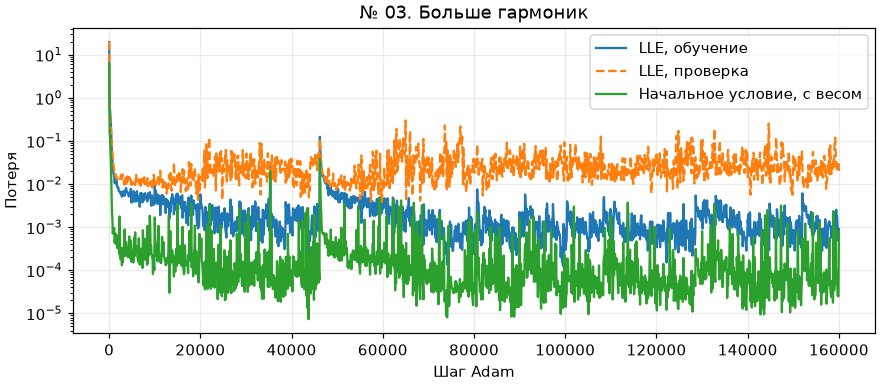

In [152]:
fig = plot_loss_history(SWEEP_T25_03_RUN_ID, '№ 03. Больше гармоник')
plt.show()

#### № 04. Шире сеть

Максимальная ошибка на [0,2] — 72.77%
Максимальная ошибка на [0,T] — 72.77% при t = 1.79


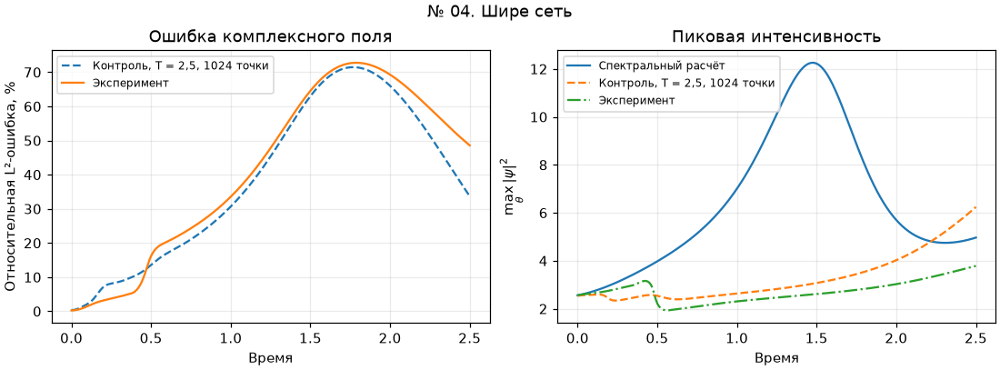

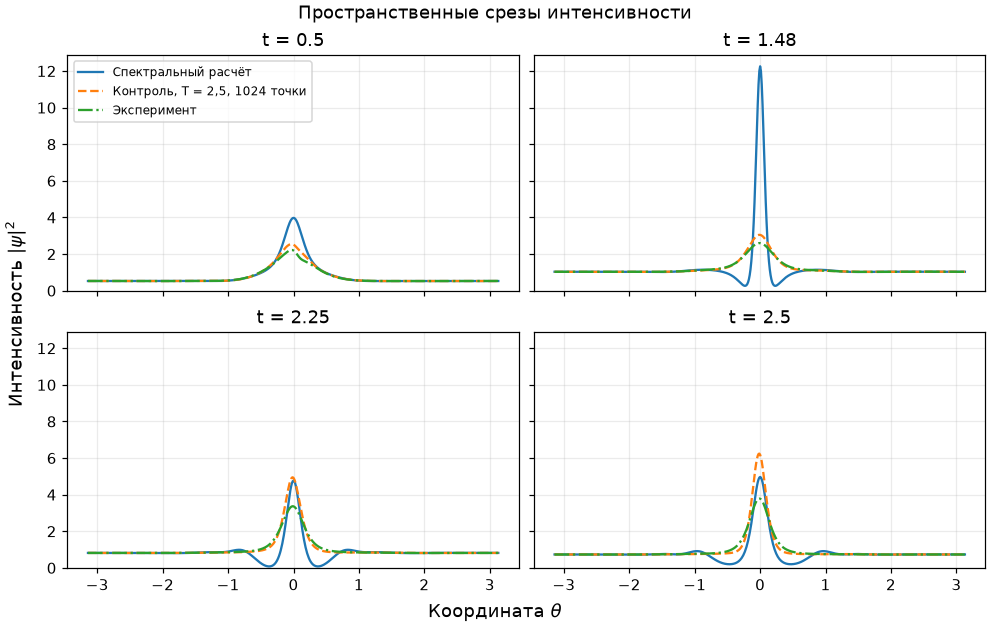

In [153]:
SWEEP_T25_04_RUN_ID = "2026-11-11_13-42-51_642460"
show_horizon_run(SWEEP_T25_04_RUN_ID, '№ 04. Шире сеть', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

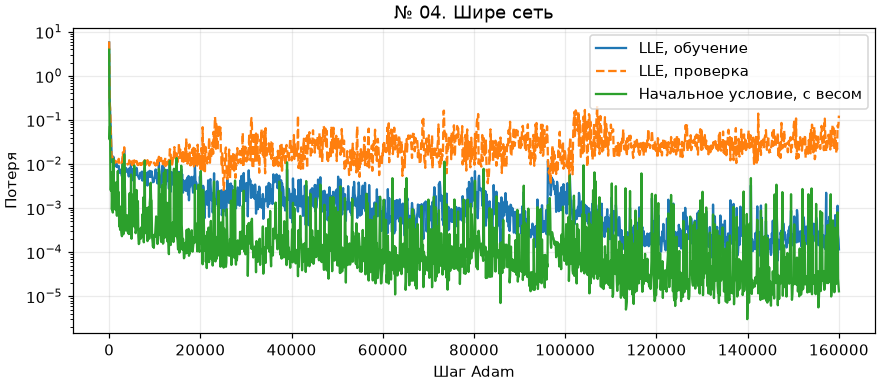

In [154]:
fig = plot_loss_history(SWEEP_T25_04_RUN_ID, '№ 04. Шире сеть')
plt.show()

#### № 05. Шире сеть, больше гармоник, точек и шагов

Максимальная ошибка на [0,2] — 70.87%
Максимальная ошибка на [0,T] — 70.87% при t = 1.76


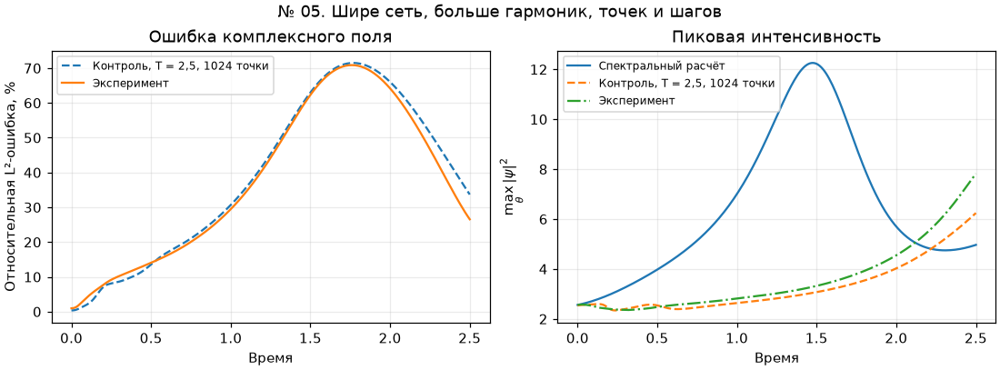

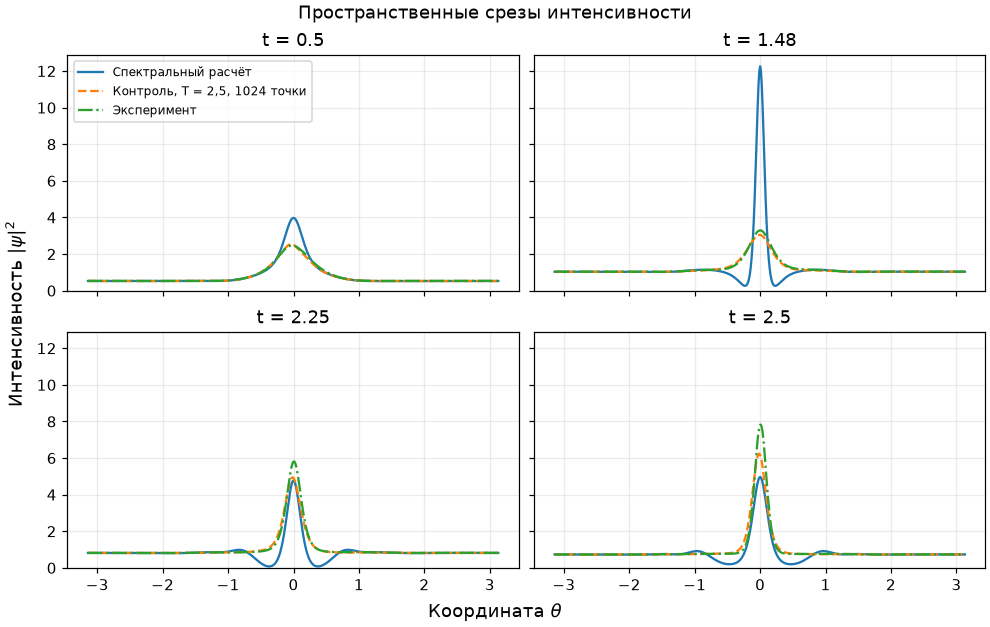

In [155]:
SWEEP_T25_05_RUN_ID = "2026-11-11_21-58-22_813371"
show_horizon_run(SWEEP_T25_05_RUN_ID, '№ 05. Шире сеть, больше гармоник, точек и шагов', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

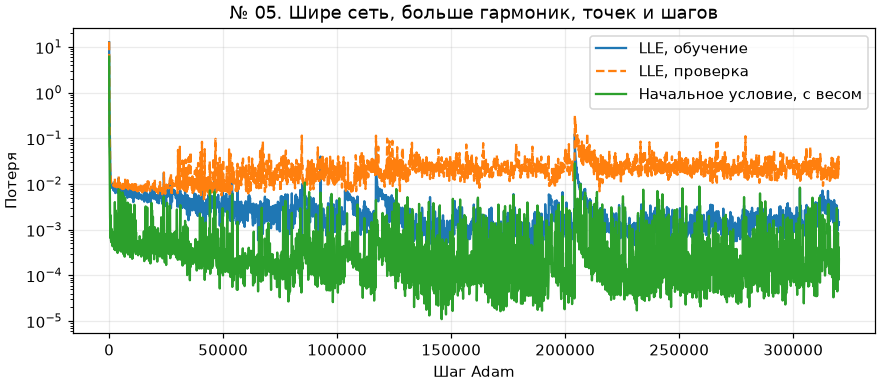

In [156]:
fig = plot_loss_history(SWEEP_T25_05_RUN_ID, '№ 05. Шире сеть, больше гармоник, точек и шагов')
plt.show()

#### № 06. № 05 с удвоенным бюджетом

Максимальная ошибка на [0,2] — 71.46%
Максимальная ошибка на [0,T] — 71.46% при t = 1.77


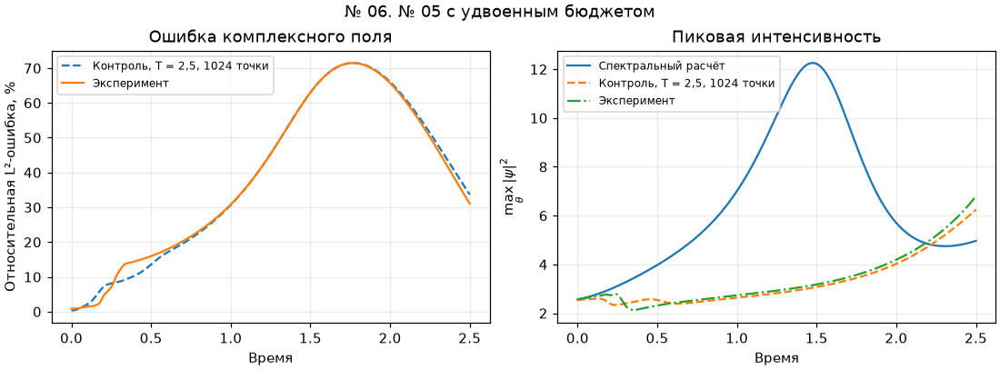

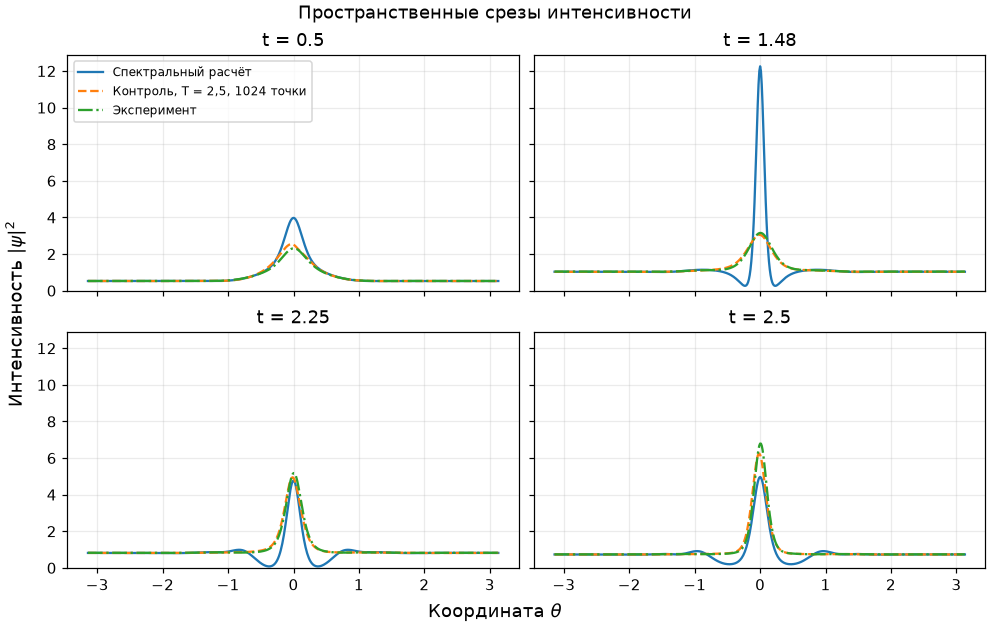

In [157]:
SWEEP_T25_06_RUN_ID = "2026-11-12_16-04-08_699587"
show_horizon_run(SWEEP_T25_06_RUN_ID, '№ 06. № 05 с удвоенным бюджетом', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

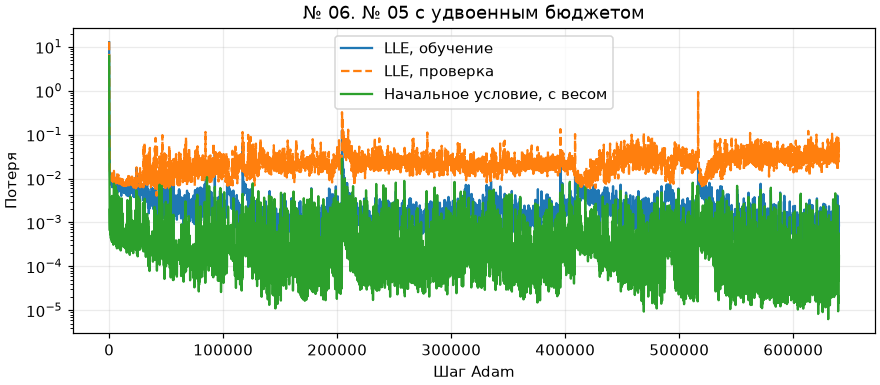

In [158]:
fig = plot_loss_history(SWEEP_T25_06_RUN_ID, '№ 06. № 05 с удвоенным бюджетом')
plt.show()

#### № 07. № 05 с удвоенным числом точек

Максимальная ошибка на [0,2] — 0.98%
Максимальная ошибка на [0,T] — 0.98% при t = 1.61


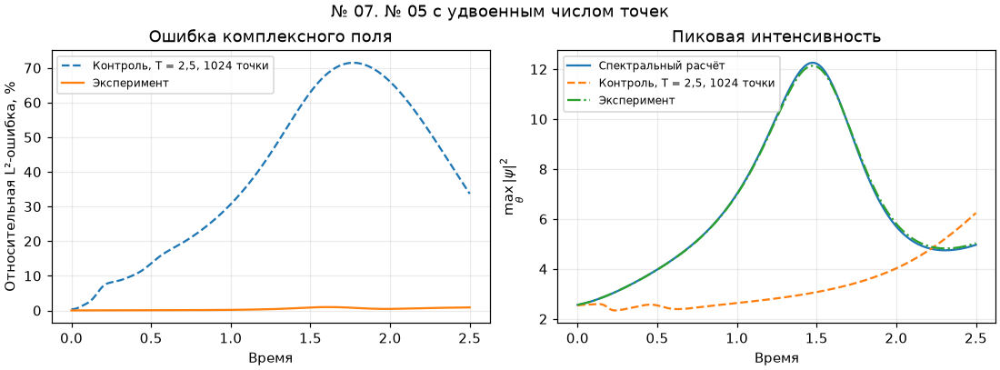

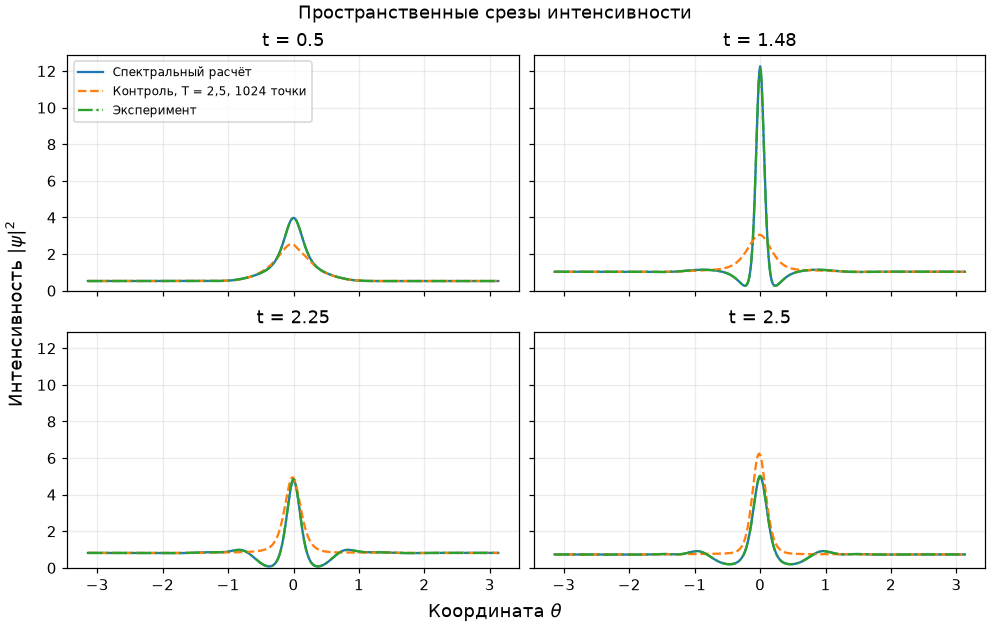

In [159]:
SWEEP_T25_07_RUN_ID = "2026-11-11_21-58-34_873270"
show_horizon_run(SWEEP_T25_07_RUN_ID, '№ 07. № 05 с удвоенным числом точек', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

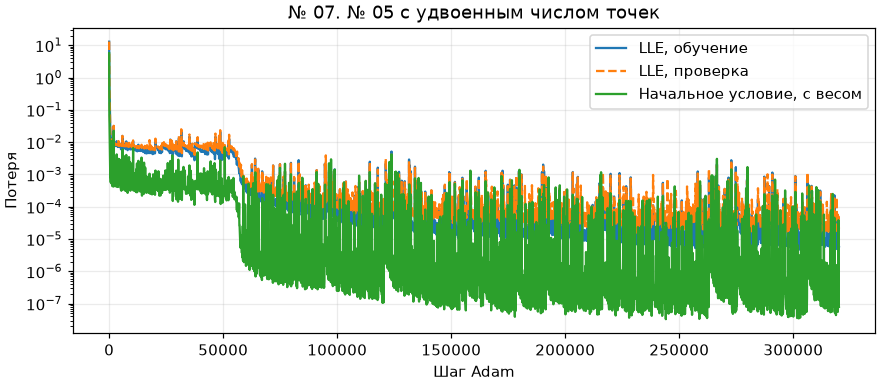

In [160]:
fig = plot_loss_history(SWEEP_T25_07_RUN_ID, '№ 07. № 05 с удвоенным числом точек')
plt.show()

#### № 08. № 05 с большей глубиной

Максимальная ошибка на [0,2] — 71.57%
Максимальная ошибка на [0,T] — 71.57% при t = 1.77


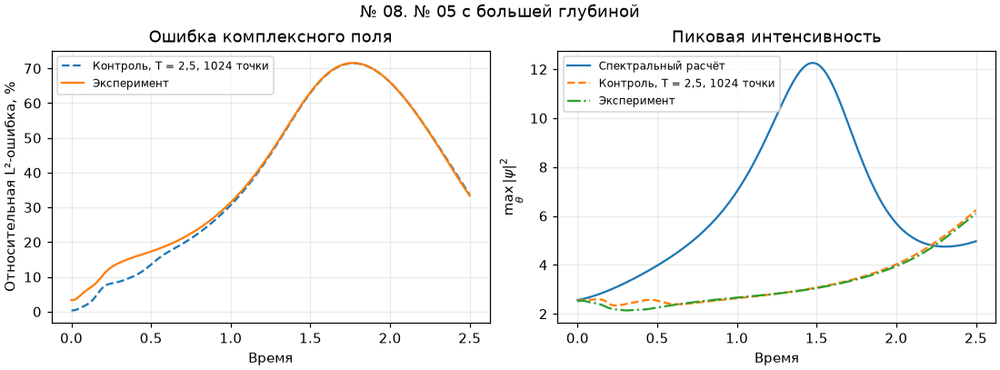

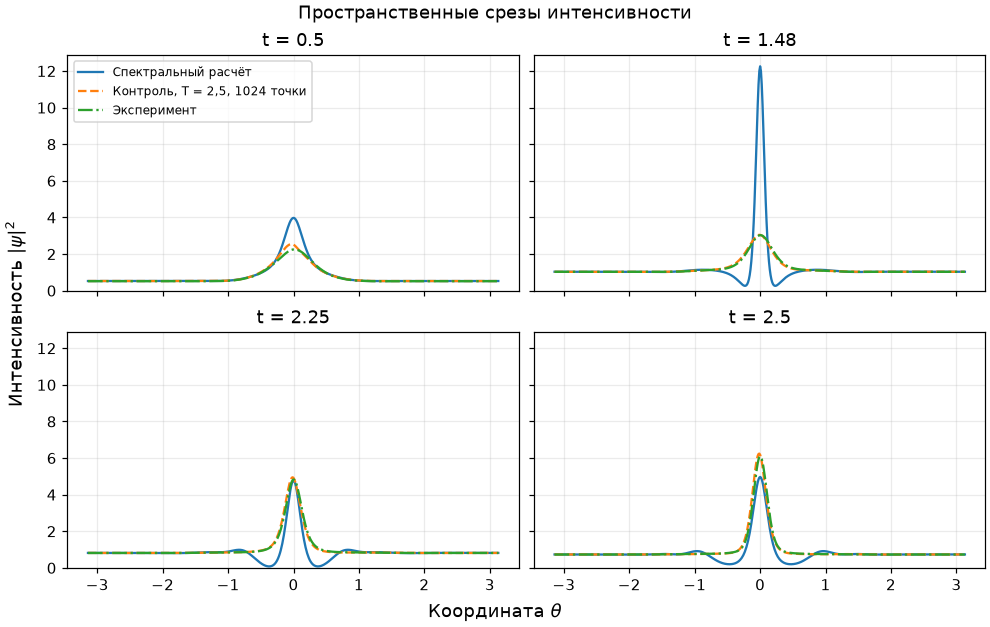

In [161]:
SWEEP_T25_08_RUN_ID = "2026-11-11_21-58-40_678698"
show_horizon_run(SWEEP_T25_08_RUN_ID, '№ 08. № 05 с большей глубиной', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

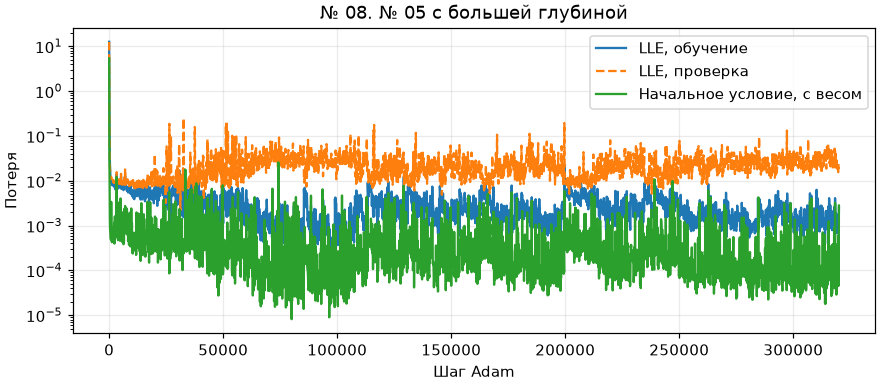

In [162]:
fig = plot_loss_history(SWEEP_T25_08_RUN_ID, '№ 08. № 05 с большей глубиной')
plt.show()

#### № 09. № 05 с большей шириной

Максимальная ошибка на [0,2] — 72.42%
Максимальная ошибка на [0,T] — 72.42% при t = 1.78


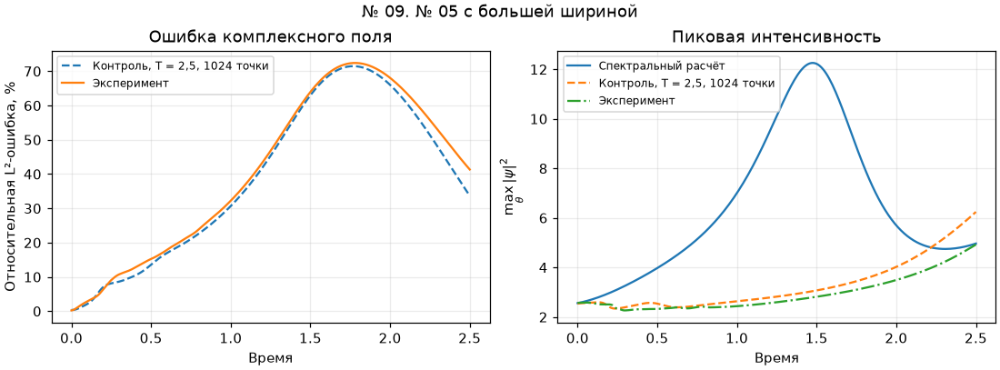

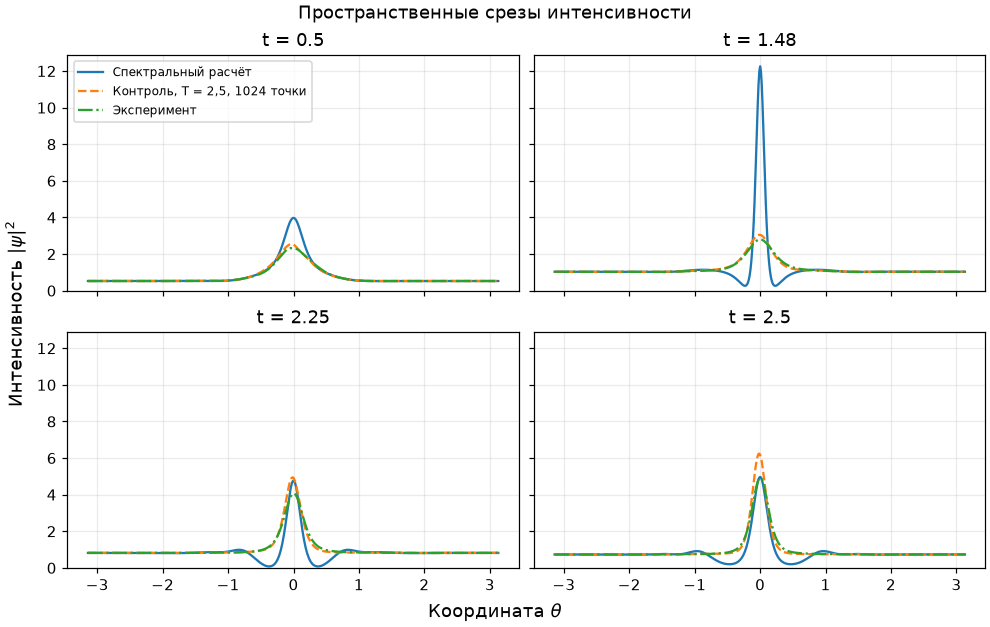

In [163]:
SWEEP_T25_09_RUN_ID = "2026-11-11_21-58-46_143617"
show_horizon_run(SWEEP_T25_09_RUN_ID, '№ 09. № 05 с большей шириной', sweep_t25_control, 'Контроль, T = 2,5, 1024 точки', (0.5, 1.48, 2.25, 2.5))

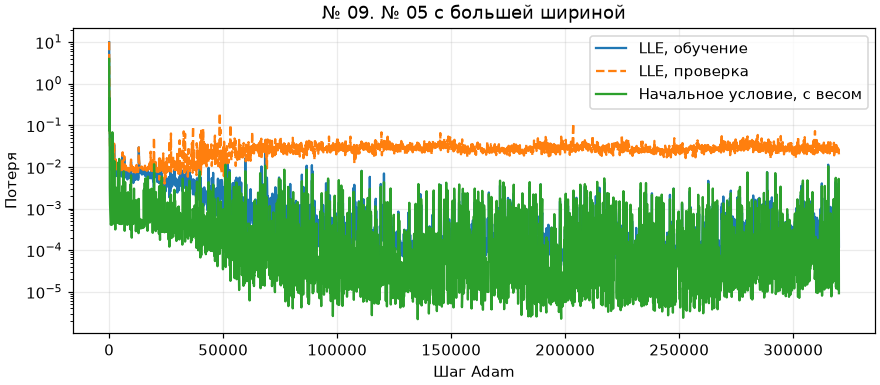

In [164]:
fig = plot_loss_history(SWEEP_T25_09_RUN_ID, '№ 09. № 05 с большей шириной')
plt.show()

## Базовая PINN на $[0,3]$ и $[0,4]$ с 4096 и 8192 точками

Во всех четырёх запусках использована одна конфигурация с четырьмя скрытыми слоями шириной 64, четырьмя гармониками, 160 000 шагов Adam и seed 42. Менялись горизонт и число внутренних точек. Максимальная относительная $L^2$-ошибка комплексного поля измерена на сохранённых срезах относительно спектрального решения.

| $T$ | Внутренние точки | Макс. ошибка на $[0,2{,}5]$ | На $[2{,}5,T]$ | На $[0,T]$ | Пик при $t=1{,}48$ | Пик при $t=3{,}5$ |
|---:|---:|---:|---:|---:|---:|---:|
| 3 | 4096 | 70,81% | 33,04% | 70,81% | 3,21 | — |
| 3 | 8192 | 3,10% | 2,40% | 3,10% | 11,96 | — |
| 4 | 4096 | 72,51% | 83,01% | 83,01% | 2,50 | 3,10 |
| 4 | 8192 | 72,06% | 75,93% | 75,93% | 2,70 | 4,21 |
| Спектральный расчёт | — | — | — | — | 12,26 | 10,07 |

При $T=3$ вариант с 8192 точками прошёл критерий 5% на всём интервале. В конечном срезе относительная ошибка 1,16%, а пиковая интенсивность 7,02 при эталонной 7,14. С 4096 точками уже на $[0,2{,}5]$ ошибка достигает 70,81%, хотя обучение той же сети на $[0,2{,}5]$ с 4096 точками давало 1,58%.

При $T=4$ увеличение числа точек снижает максимальную ошибку с 83,01% до 75,93%. При этом на общем участке $[0,2{,}5]$ ошибка остаётся выше 72%, а оба выраженных пика существенно занижены.

In [165]:
baseline_t25_4096 = load_evolution(get_run(SWEEP_T25_02_RUN_ID).path)

### T = 3, 4096 внутренних точек

Максимальная ошибка на [0,2] — 70.81%
Максимальная ошибка на [0,T] — 70.81% при t = 1.77


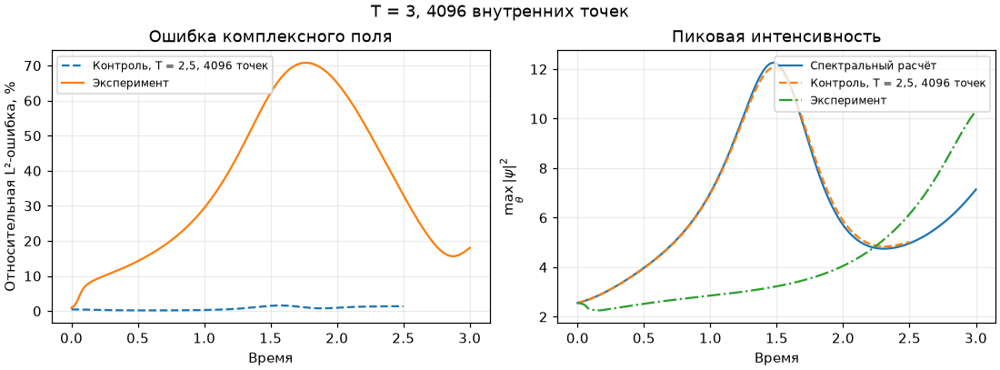

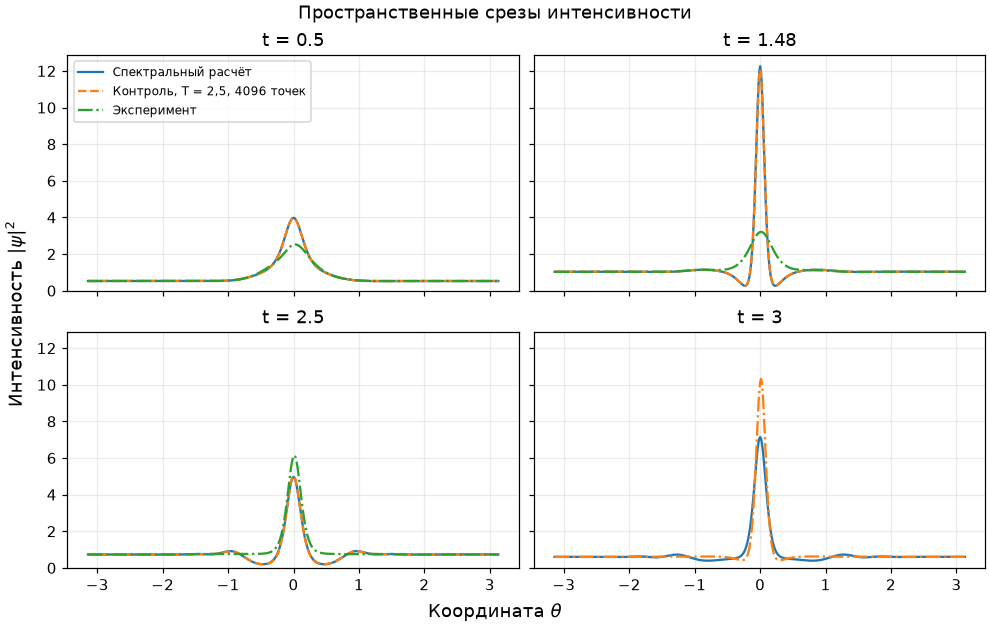

In [166]:
T3_4096_RUN_ID = "2026-11-13_02-31-19_718264"
show_horizon_run(T3_4096_RUN_ID, 'T = 3, 4096 внутренних точек', baseline_t25_4096, 'Контроль, T = 2,5, 4096 точек', (0.5, 1.48, 2.5, 3.0))

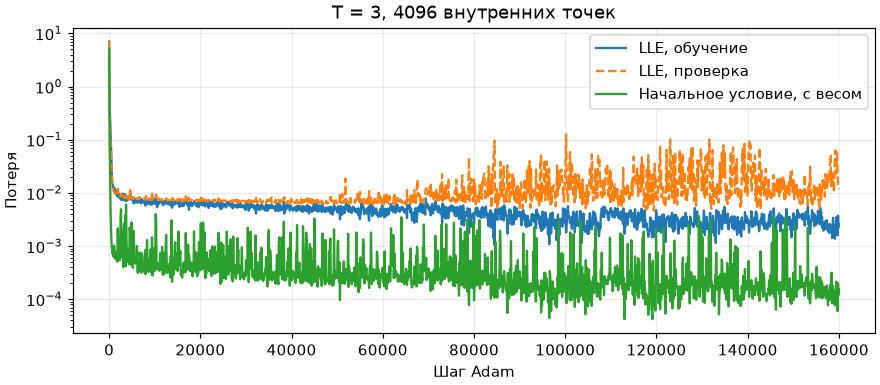

In [167]:
fig = plot_loss_history(T3_4096_RUN_ID, 'T = 3, 4096 внутренних точек')
plt.show()

### T = 3, 8192 внутренних точек

Максимальная ошибка на [0,2] — 3.10%
Максимальная ошибка на [0,T] — 3.10% при t = 1.52


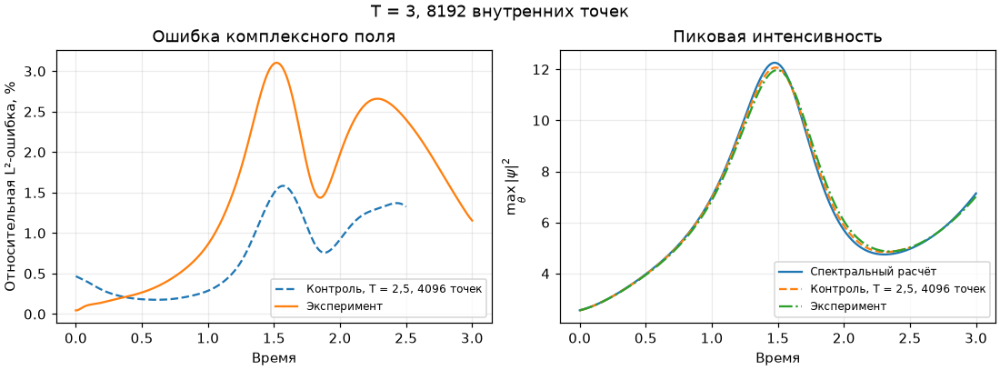

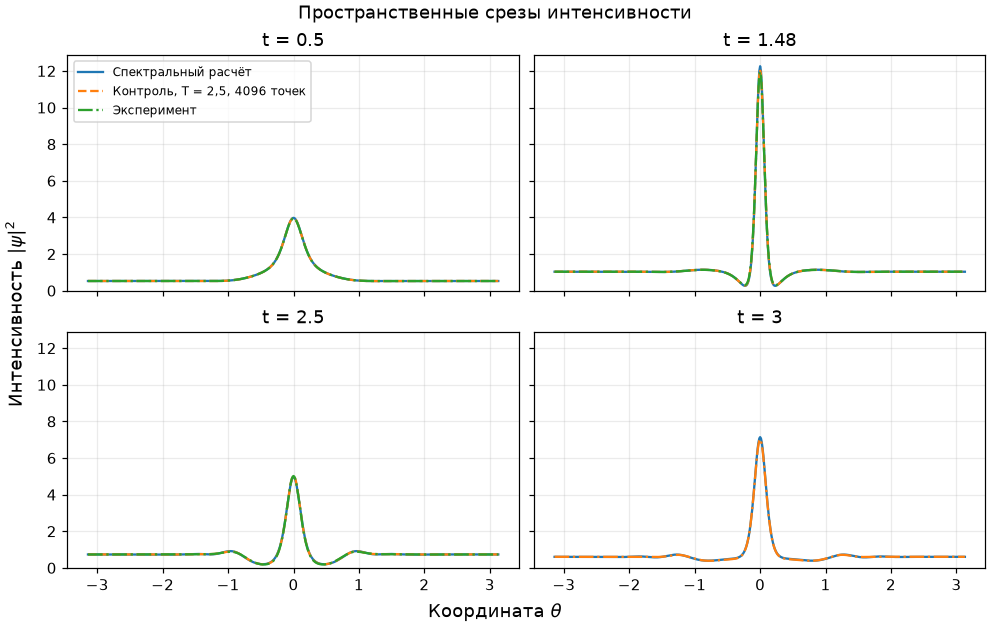

In [168]:
T3_8192_RUN_ID = "2026-11-13_02-31-19_726640"
show_horizon_run(T3_8192_RUN_ID, 'T = 3, 8192 внутренних точек', baseline_t25_4096, 'Контроль, T = 2,5, 4096 точек', (0.5, 1.48, 2.5, 3.0))

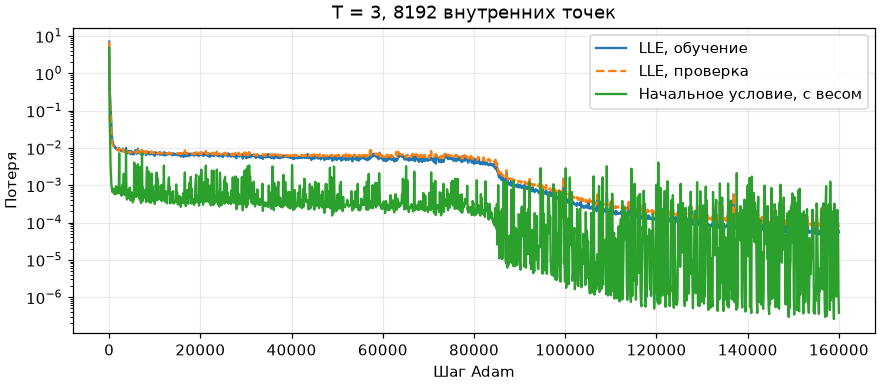

In [169]:
fig = plot_loss_history(T3_8192_RUN_ID, 'T = 3, 8192 внутренних точек')
plt.show()

### T = 4, 4096 внутренних точек

Максимальная ошибка на [0,2] — 72.51%
Максимальная ошибка на [0,T] — 83.01% при t = 3.8


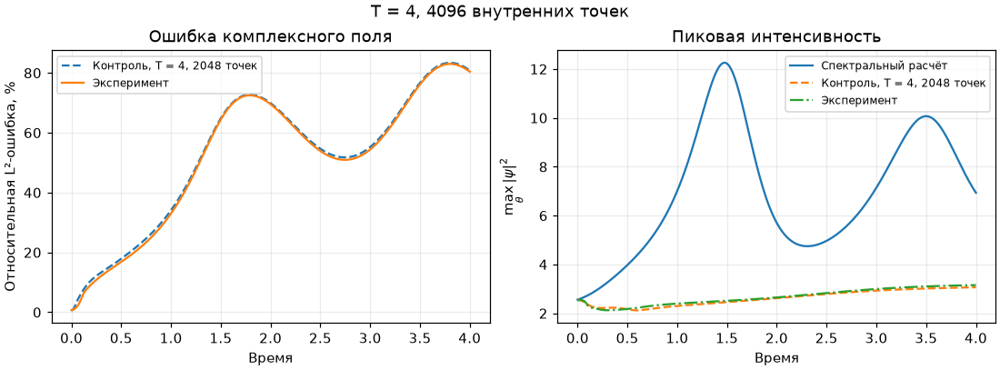

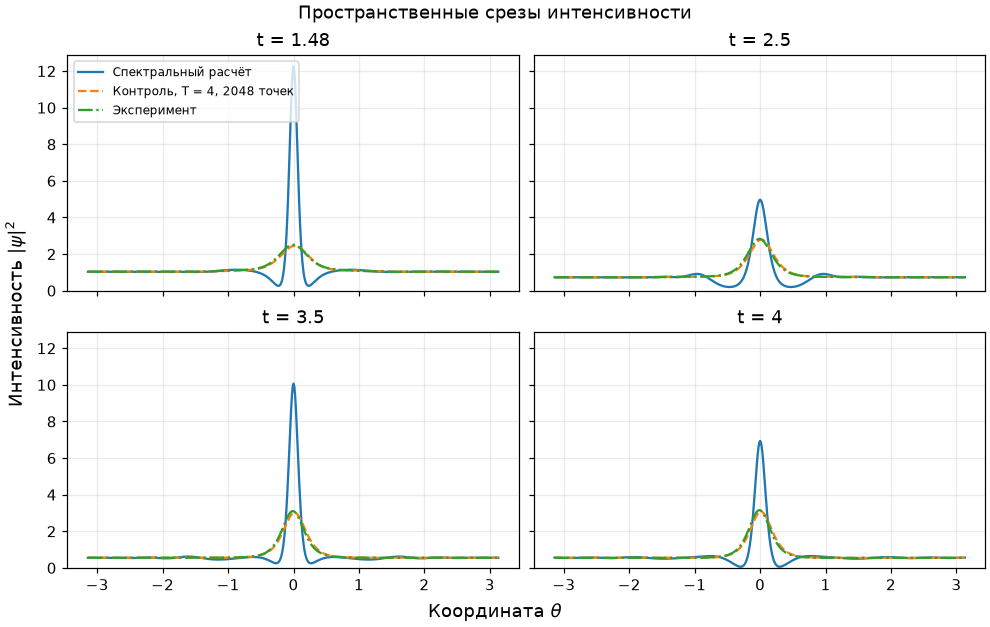

In [170]:
T4_4096_RUN_ID = "2026-11-13_02-31-19_730200"
show_horizon_run(T4_4096_RUN_ID, 'T = 4, 4096 внутренних точек', t4_control, 'Контроль, T = 4, 2048 точек', (1.48, 2.5, 3.5, 4.0))

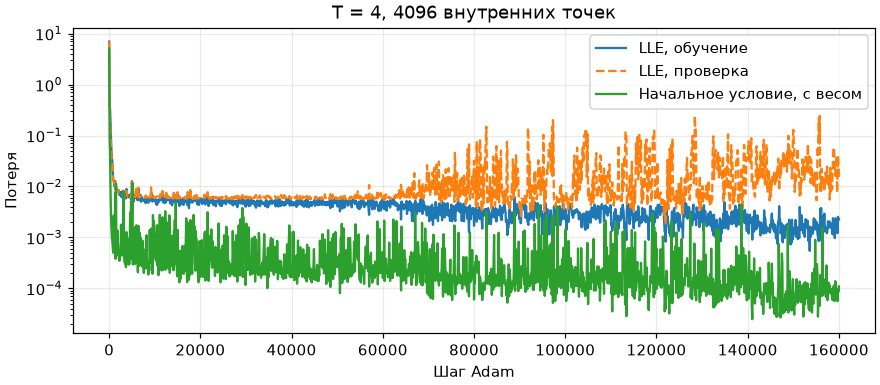

In [171]:
fig = plot_loss_history(T4_4096_RUN_ID, 'T = 4, 4096 внутренних точек')
plt.show()

### T = 4, 8192 внутренних точек

Максимальная ошибка на [0,2] — 72.06%
Максимальная ошибка на [0,T] — 75.93% при t = 3.73


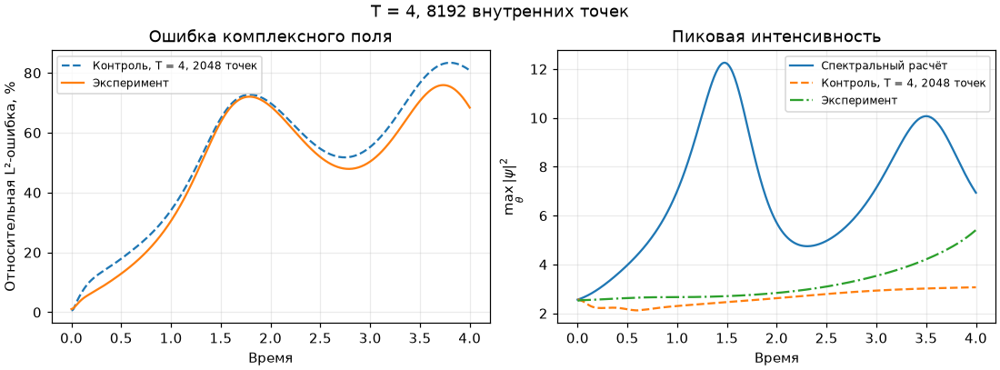

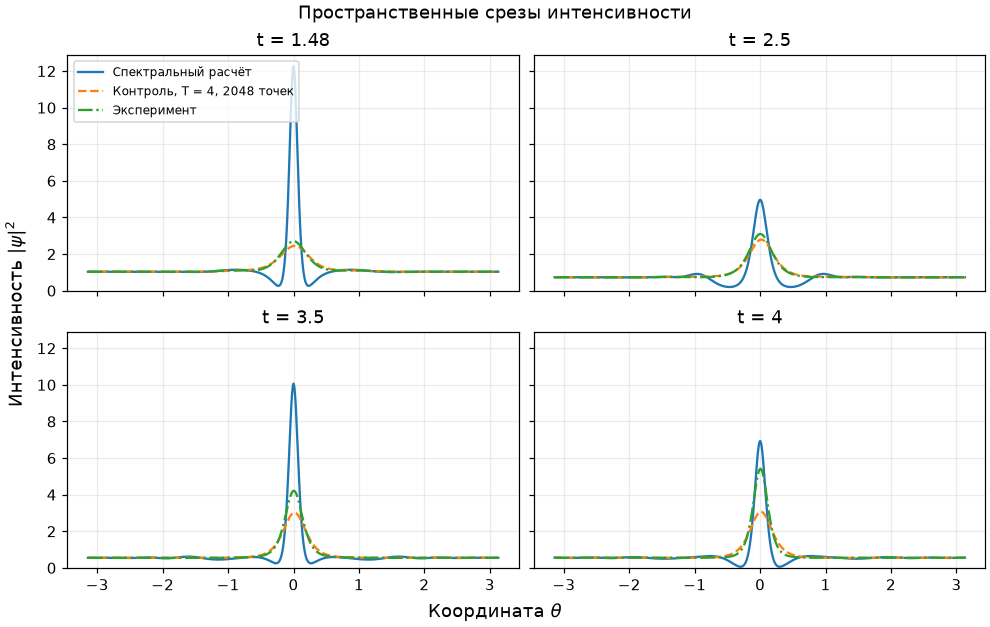

In [172]:
T4_8192_RUN_ID = "2026-11-13_02-31-22_146903"
show_horizon_run(T4_8192_RUN_ID, 'T = 4, 8192 внутренних точек', t4_control, 'Контроль, T = 4, 2048 точек', (1.48, 2.5, 3.5, 4.0))

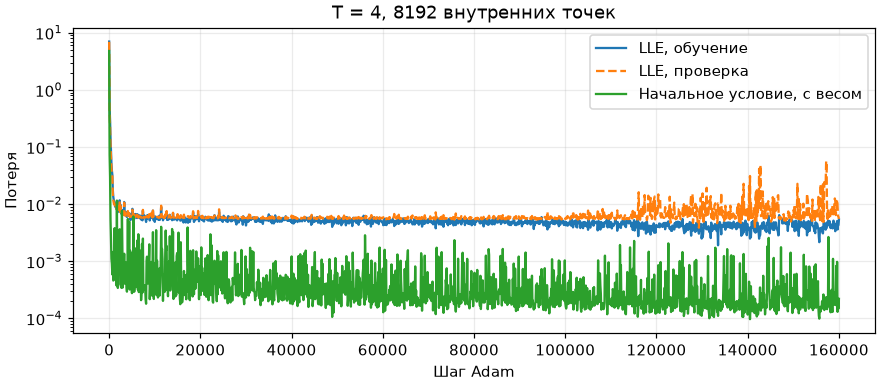

In [173]:
fig = plot_loss_history(T4_8192_RUN_ID, 'T = 4, 8192 внутренних точек')
plt.show()

## Увеличение числа точек на $[0,3{,}5]$ и $[0,4]$

Во всех четырёх запусках использована базовая PINN с четырьмя слоями шириной 64, четырьмя гармониками, 160 000 шагов Adam и seed 42. Максимальная относительная $L^2$-ошибка комплексного поля вычислена на сохранённых срезах относительно общего спектрального решения.

| $T$ | Внутренние точки | Макс. ошибка на $[0,3]$ | На $[3,T]$ | На всём интервале | Ошибка при $t=T$ |
|---:|---:|---:|---:|---:|---:|
| 3,5 | 8192 | 71,95% | 53,08% | 71,95% | 53,08% |
| 3,5 | 16 384 | 18,98% | 16,32% | 18,98% | 11,95% |
| 4 | 16 384 | 72,33% | 70,24% | 72,33% | 56,68% |
| 4 | 32 768 | 72,05% | 61,99% | 72,05% | 39,75% |

При $T=3{,}5$ с 16 384 точками виден поздний перелом около 150 000 шагов. Медиана проверочной невязки LLE снижается с $4{,}71\times10^{-3}$ на шагах 145–150 тыс. до $1{,}72\times10^{-3}$ на 150–155 тыс. и $1{,}09\times10^{-3}$ на 155–160 тыс. Обучающая невязка тоже снижается. В конечном поле интенсивность пика при $t=1{,}48$ составляет 10,55 при эталонной 12,26. При $t=3{,}5$ — 7,90 при эталонной 10,07. Максимальная ошибка 18,98% приходится на $t=2{,}75$. Промежуточные поля в ходе обучения не сохранялись.

В остальных трёх запусках сопоставимого устойчивого спада после плато нет. При $T=4$ увеличение числа точек до 32 768 снижает ошибку на позднем участке, но сохраняется большая ошибка ранней траектории. Например, при $t=1{,}48$ пиковая интенсивность равна 2,76 при эталонной 12,26. Критерий 5% на всём интервале пока не выполнен ни в одном из четырёх запусков.

In [174]:
t35_control = load_evolution(get_run(T3_8192_RUN_ID).path)
t4_8192_control = load_evolution(get_run(T4_8192_RUN_ID).path)

### T = 3,5, 8192 внутренних точек

Максимальная ошибка на [0,2] — 71.95%
Максимальная ошибка на [0,T] — 71.95% при t = 1.79


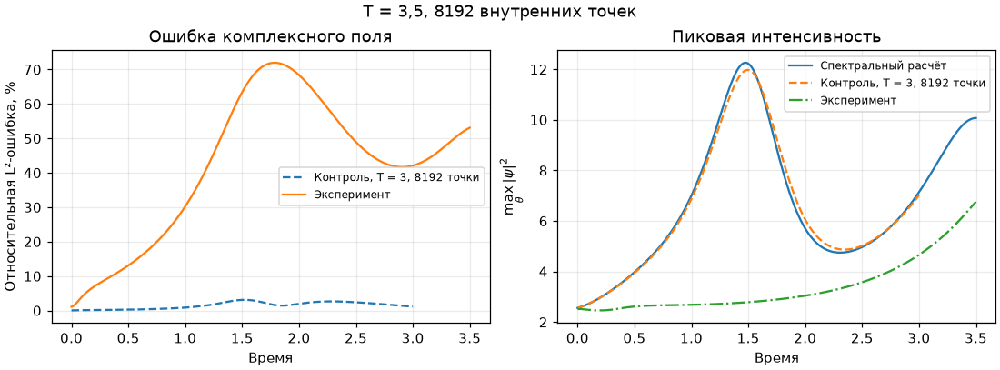

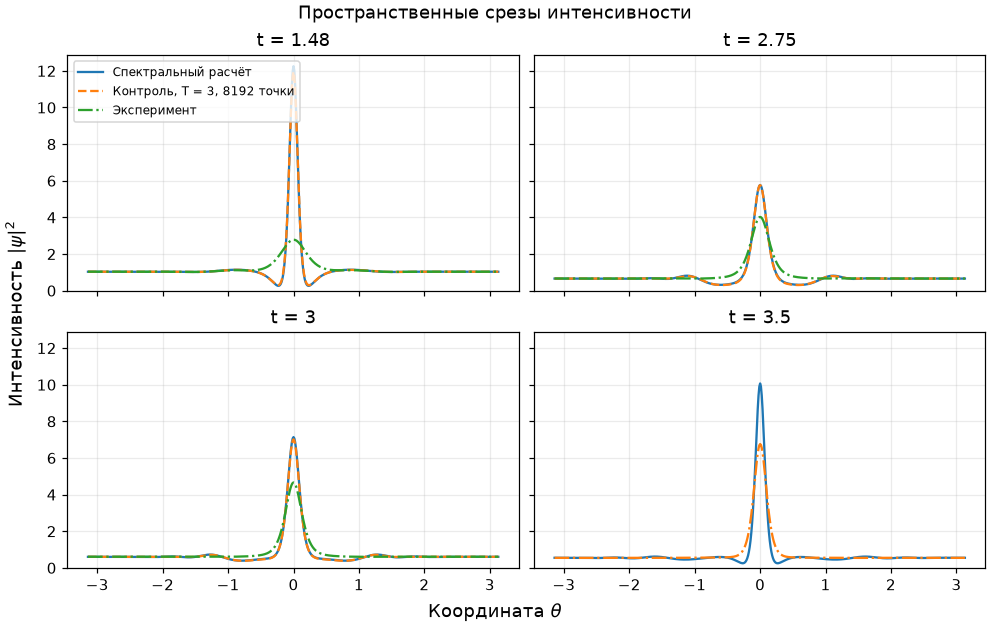

In [175]:
T35_8192_RUN_ID = "2026-11-13_05-29-02_360013"
show_horizon_run(T35_8192_RUN_ID, 'T = 3,5, 8192 внутренних точек', t35_control, 'Контроль, T = 3, 8192 точки', (1.48, 2.75, 3.0, 3.5))

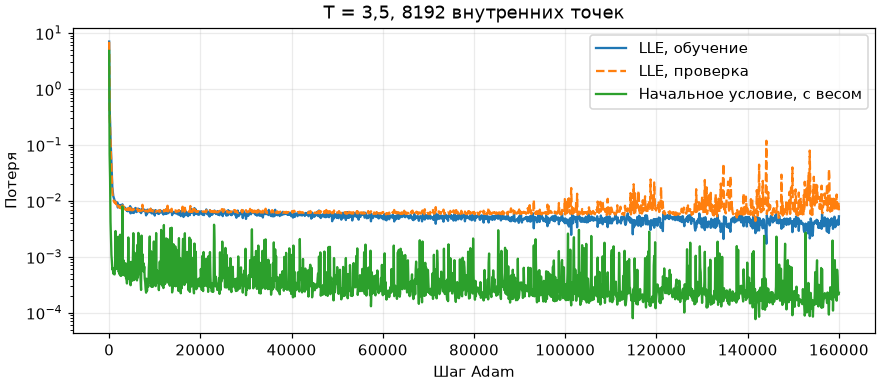

In [176]:
fig = plot_loss_history(T35_8192_RUN_ID, 'T = 3,5, 8192 внутренних точек')
plt.show()

### T = 3,5, 16384 внутренних точек

Максимальная ошибка на [0,2] — 13.55%
Максимальная ошибка на [0,T] — 18.98% при t = 2.75


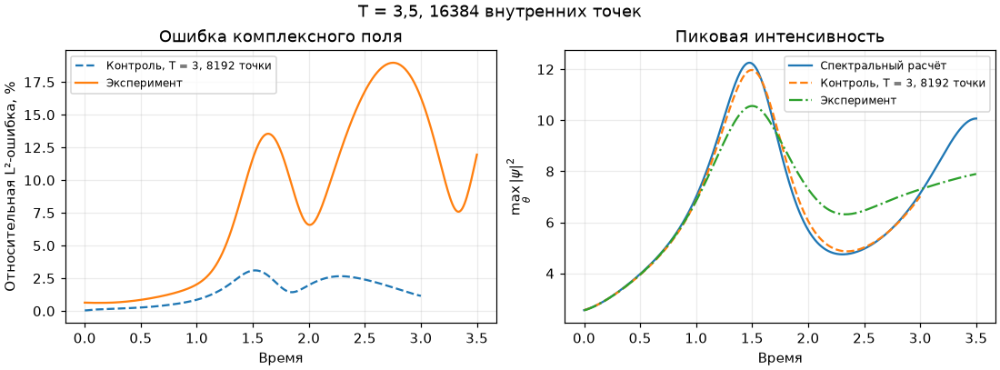

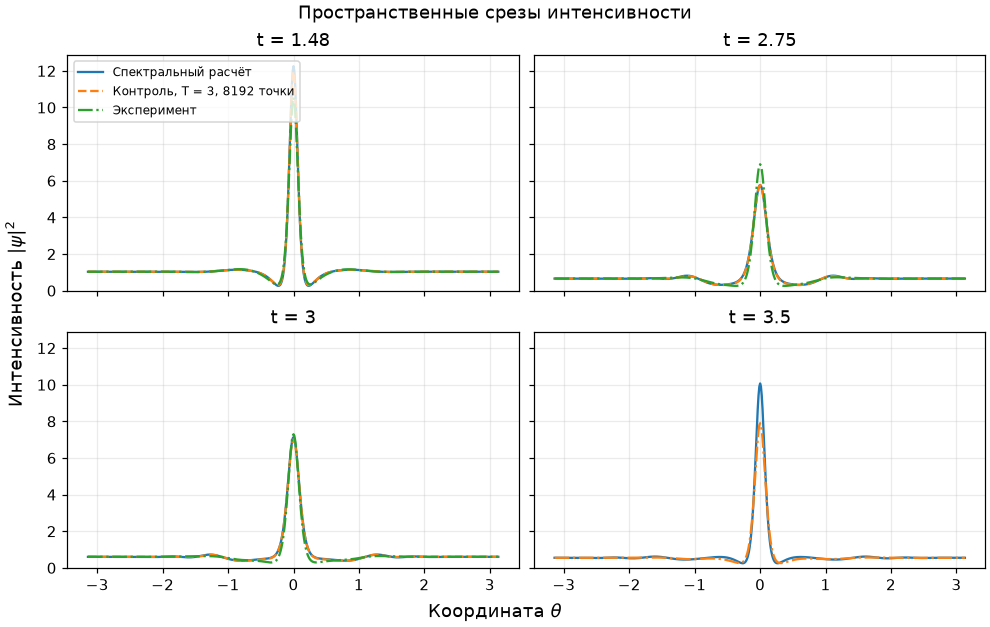

In [177]:
T35_16384_RUN_ID = "2026-11-13_05-28-42_575642"
show_horizon_run(T35_16384_RUN_ID, 'T = 3,5, 16384 внутренних точек', t35_control, 'Контроль, T = 3, 8192 точки', (1.48, 2.75, 3.0, 3.5))

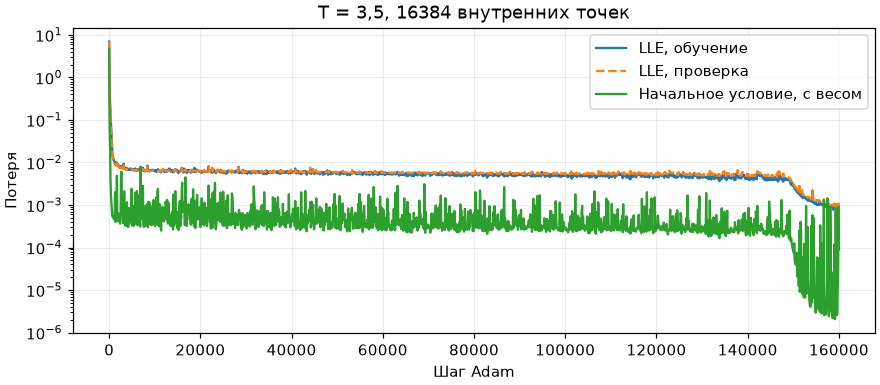

In [178]:
fig = plot_loss_history(T35_16384_RUN_ID, 'T = 3,5, 16384 внутренних точек')
plt.show()

### T = 4, 16384 внутренних точек

Максимальная ошибка на [0,2] — 72.33%
Максимальная ошибка на [0,T] — 72.33% при t = 1.79


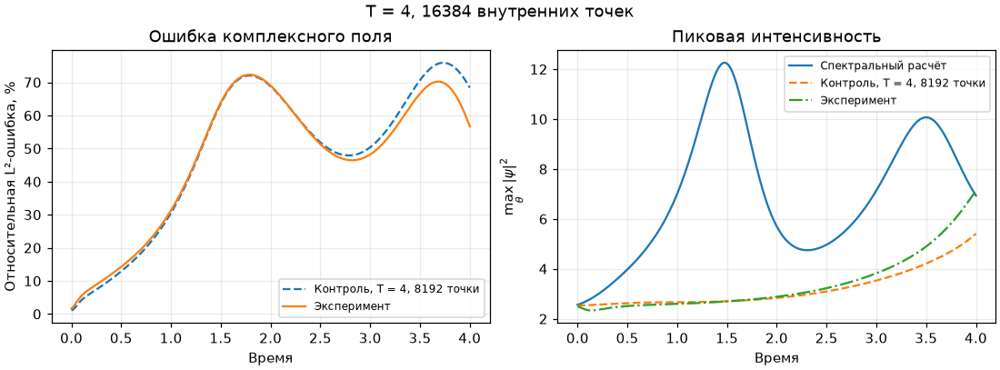

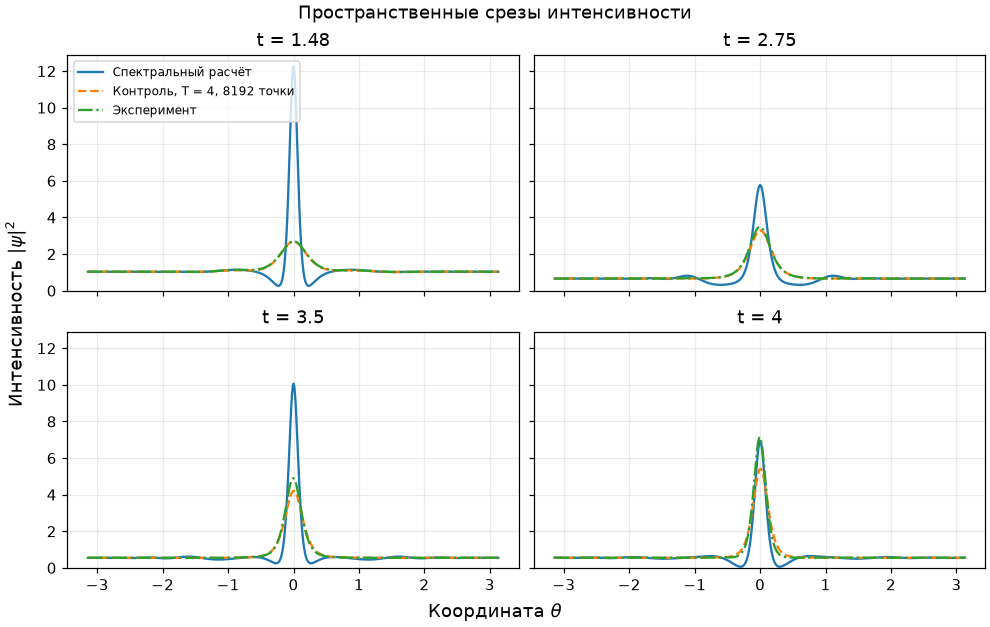

In [179]:
T4_16384_RUN_ID = "2026-11-13_05-28-51_640949"
show_horizon_run(T4_16384_RUN_ID, 'T = 4, 16384 внутренних точек', t4_8192_control, 'Контроль, T = 4, 8192 точки', (1.48, 2.75, 3.5, 4.0))

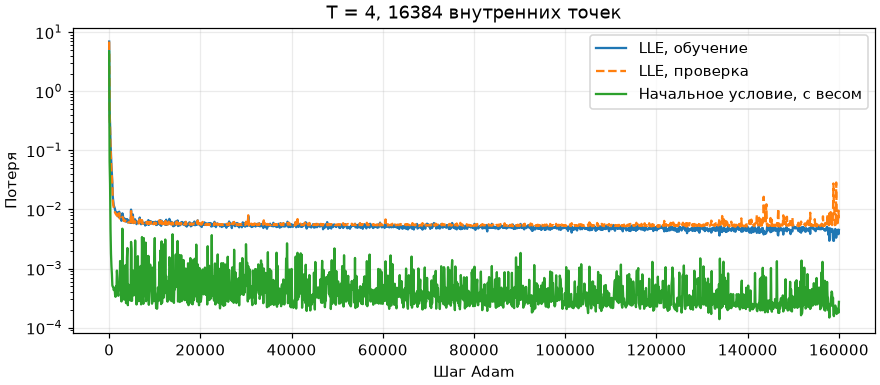

In [180]:
fig = plot_loss_history(T4_16384_RUN_ID, 'T = 4, 16384 внутренних точек')
plt.show()

### T = 4, 32768 внутренних точек

Максимальная ошибка на [0,2] — 72.05%
Максимальная ошибка на [0,T] — 72.05% при t = 1.79


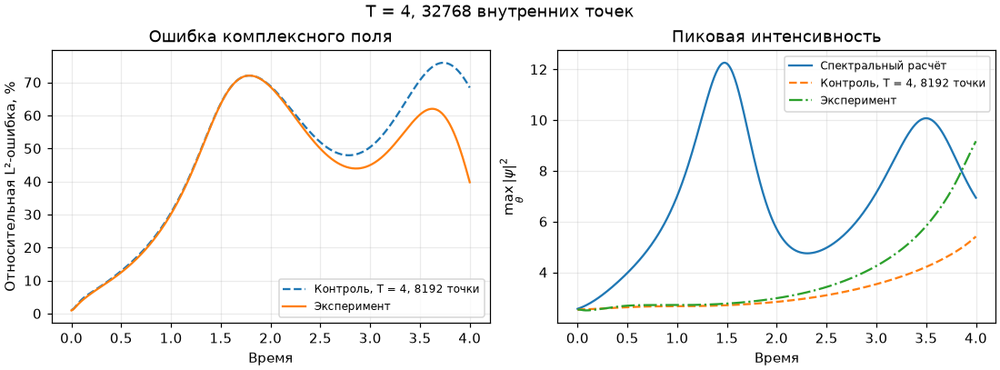

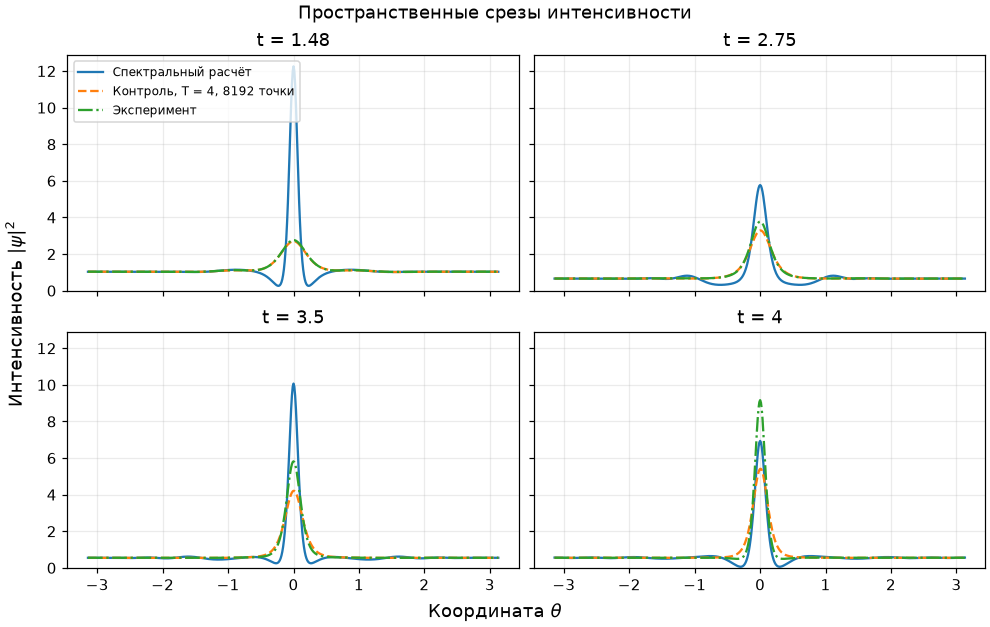

In [181]:
T4_32768_RUN_ID = "2026-11-13_05-29-13_031720"
show_horizon_run(T4_32768_RUN_ID, 'T = 4, 32768 внутренних точек', t4_8192_control, 'Контроль, T = 4, 8192 точки', (1.48, 2.75, 3.5, 4.0))

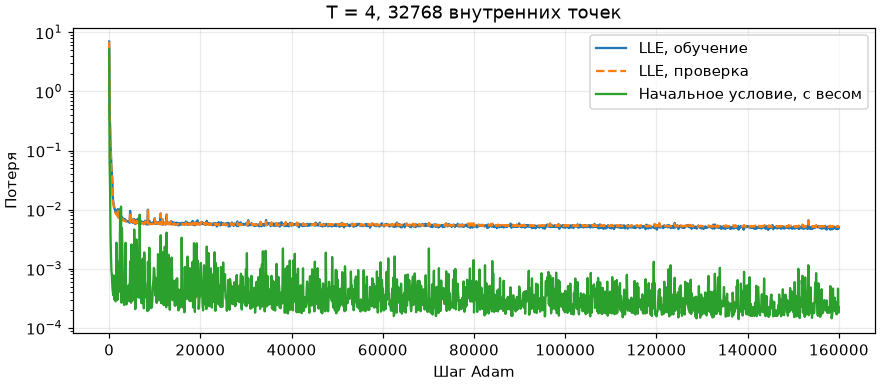

In [182]:
fig = plot_loss_history(T4_32768_RUN_ID, 'T = 4, 32768 внутренних точек')
plt.show()

## Больше шагов или больше точек на $[0,3{,}5]$ и $[0,4]$

Все четыре PINN обучены с нуля. Архитектура 4 × 64, четыре гармоники и seed 42. Ошибка — максимум относительной $L^2$-ошибки комплексного поля по сохранённым срезам относительно спектрального расчёта. Контроли взяты из предыдущей серии.

| $T$ | Внутренние точки | Шаги Adam | Макс. ошибка на $[0,3]$ | На $[3,T]$ | На $[0,T]$ | Перелом, шагов |
|---:|---:|---:|---:|---:|---:|---:|
| 3,5 | 16 384, контроль | 160 000 | 18,98% | 16,32% | 18,98% | ≈150 000 |
| **3,5** | **16 384** | **320 000** | **1,73%** | **1,01%** | **1,73%** | ≈151 000 |
| 3,5 | 32 768 | 160 000 | 9,90% | 8,61% | 9,90% | ≈134 000 |
| 4 | 32 768, контроль | 160 000 | 72,05% | 61,99% | 72,05% | — |
| **4** | **32 768** | **320 000** | **5,63%** | **5,74%** | **5,74%** | ≈247 000 |
| 4 | 65 536 | 160 000 | 72,11% | 59,53% | 72,11% | — |

Перелом оценён по совместному устойчивому снижению обучающей и проверочной невязок LLE, по медианам в соседних окнах по 5000 шагов. В обоих запусках с удвоенным бюджетом сохранённые потери на первых 160 000 шагах полностью совпадают с соответствующими контролями.

При $T=3{,}5$ и 16 384 точках за 320 000 шагов достигнут критерий 5%. Пики при $t=1{,}48$ и $t=3{,}5$ составляют 12,07 и 9,95 при эталонных 12,26 и 10,07. С 32 768 точками перелом наступает раньше, около 134 000 шагов, и к 160 000 шагам ошибка ниже контрольной, 9,90%.

При $T=4$ и 32 768 точках за 320 000 шагов оба пика восстановились до 11,61 и 9,37. Максимальная ошибка 5,74% приходится на $t=3{,}71$, а при $t=4$ она составляет 3,37%. С 65 536 точками за 160 000 шагов сопоставимого перелома не видно, ранний пик при $t=1{,}48$ равен 2,74. На обоих горизонтах из двух проверенных способов увеличить вычислительный бюджет больший выигрыш дало удвоение числа шагов. Все сравнения выполнены для seed 42.

In [183]:
t35_budget_control = load_evolution(get_run(T35_16384_RUN_ID).path)
t4_budget_control = load_evolution(get_run(T4_32768_RUN_ID).path)

### T = 3,5, 16384 точек, 320 тыс. шагов

Максимальная ошибка на [0,2] — 1.73%
Максимальная ошибка на [0,T] — 1.73% при t = 1.55


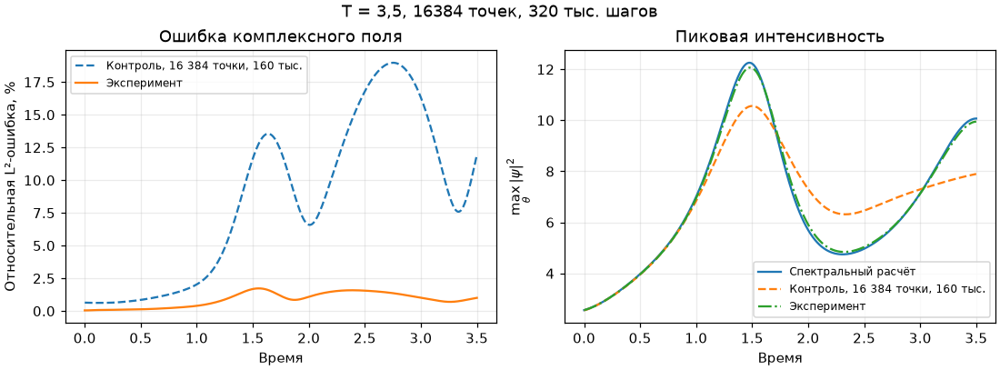

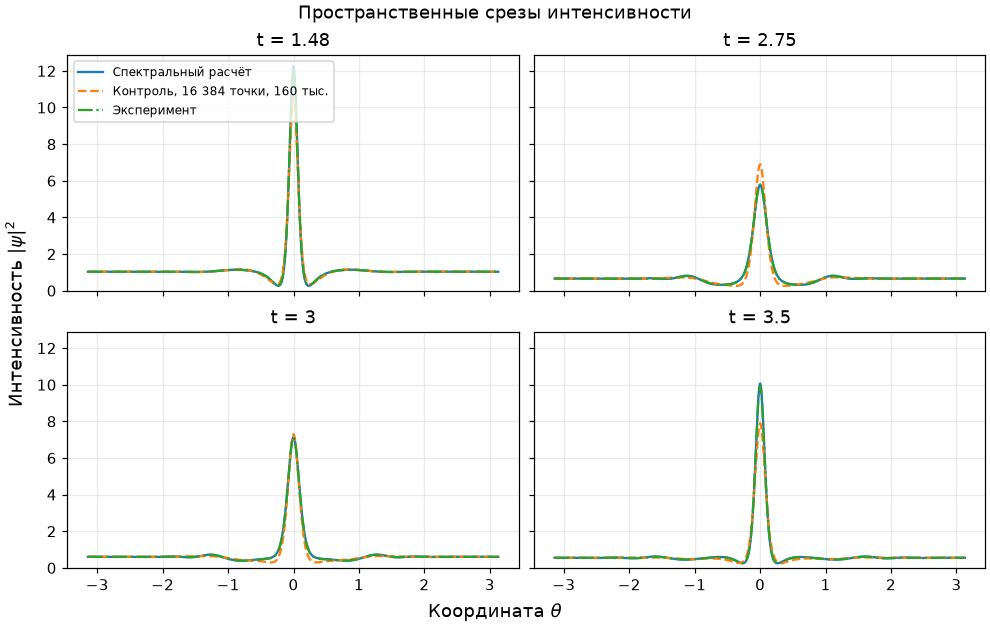

In [184]:
T35_16384_320K_RUN_ID = "2026-11-13_09-51-30_390652"
show_horizon_run(T35_16384_320K_RUN_ID, 'T = 3,5, 16384 точек, 320 тыс. шагов', t35_budget_control, 'Контроль, 16 384 точки, 160 тыс.', (1.48, 2.75, 3.0, 3.5))

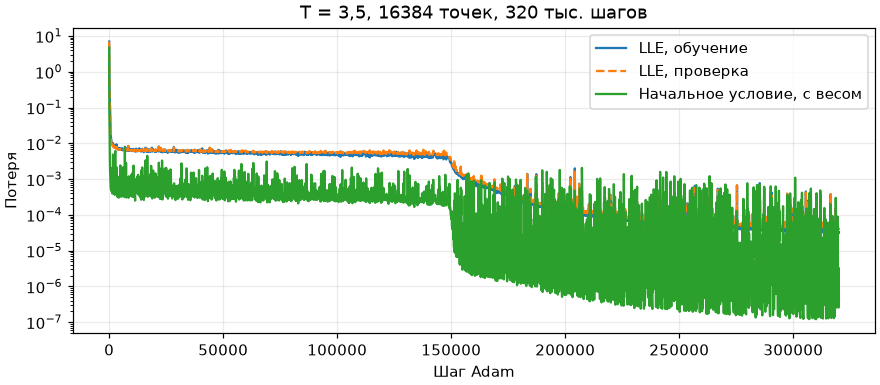

In [185]:
fig = plot_loss_history(T35_16384_320K_RUN_ID, 'T = 3,5, 16384 точек, 320 тыс. шагов')
plt.show()

### T = 3,5, 32768 точек, 160 тыс. шагов

Максимальная ошибка на [0,2] — 8.53%
Максимальная ошибка на [0,T] — 9.90% при t = 2.72


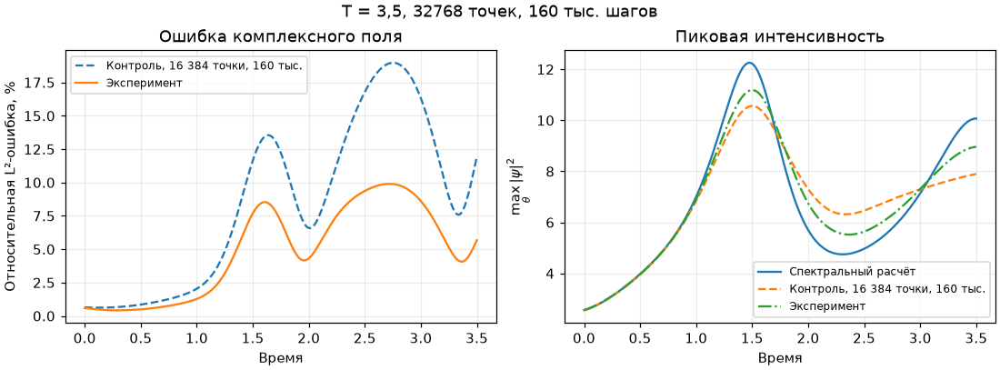

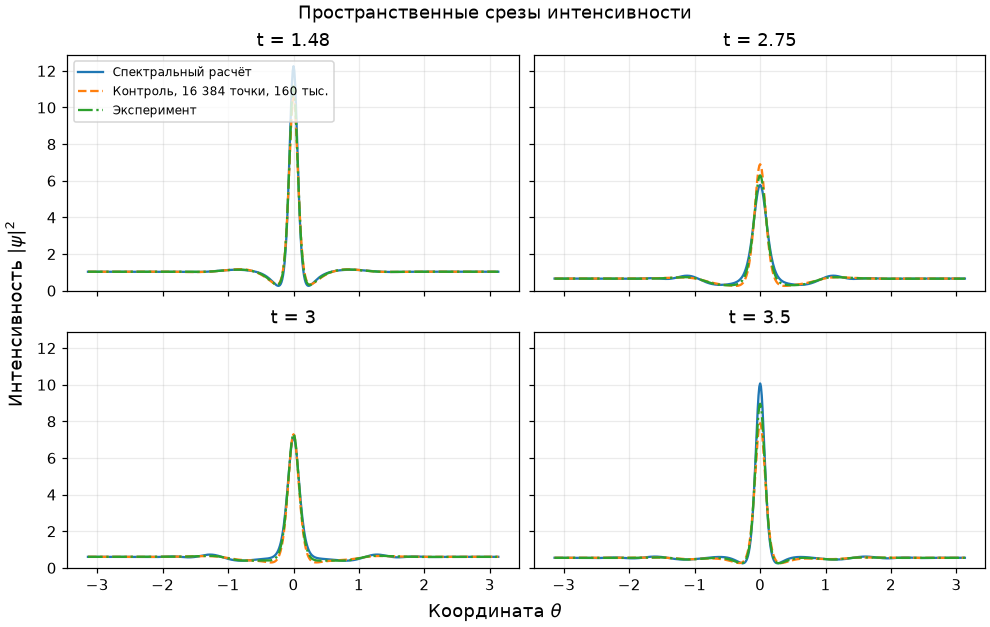

In [186]:
T35_32768_160K_RUN_ID = "2026-11-13_09-51-32_227493"
show_horizon_run(T35_32768_160K_RUN_ID, 'T = 3,5, 32768 точек, 160 тыс. шагов', t35_budget_control, 'Контроль, 16 384 точки, 160 тыс.', (1.48, 2.75, 3.0, 3.5))

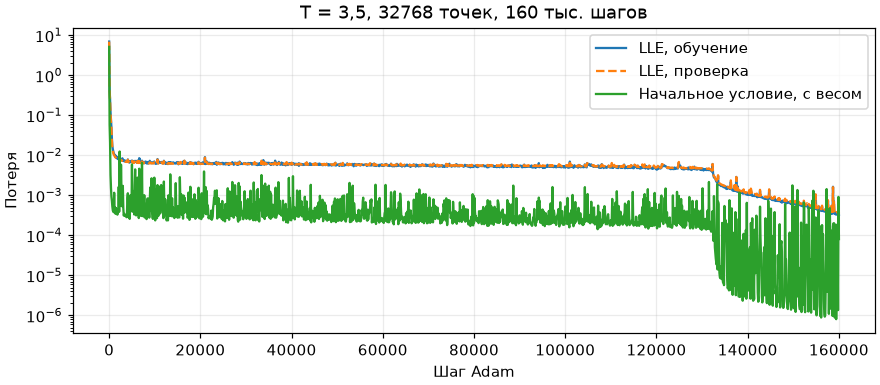

In [187]:
fig = plot_loss_history(T35_32768_160K_RUN_ID, 'T = 3,5, 32768 точек, 160 тыс. шагов')
plt.show()

### T = 4, 32768 точек, 320 тыс. шагов

Максимальная ошибка на [0,2] — 5.35%
Максимальная ошибка на [0,T] — 5.74% при t = 3.71


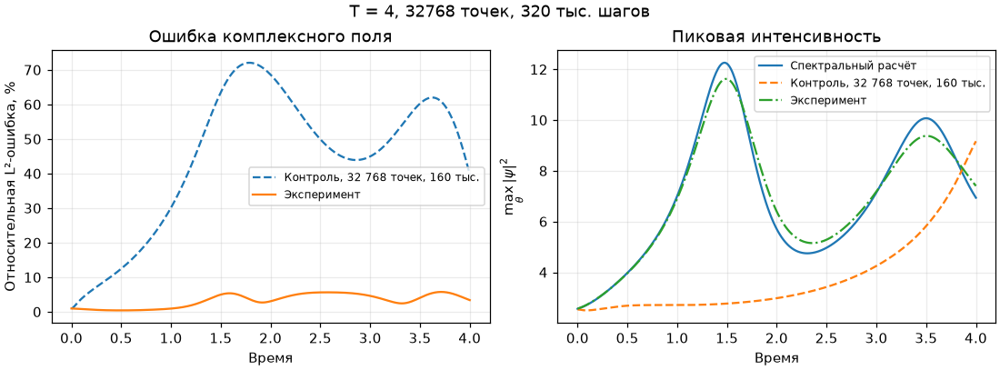

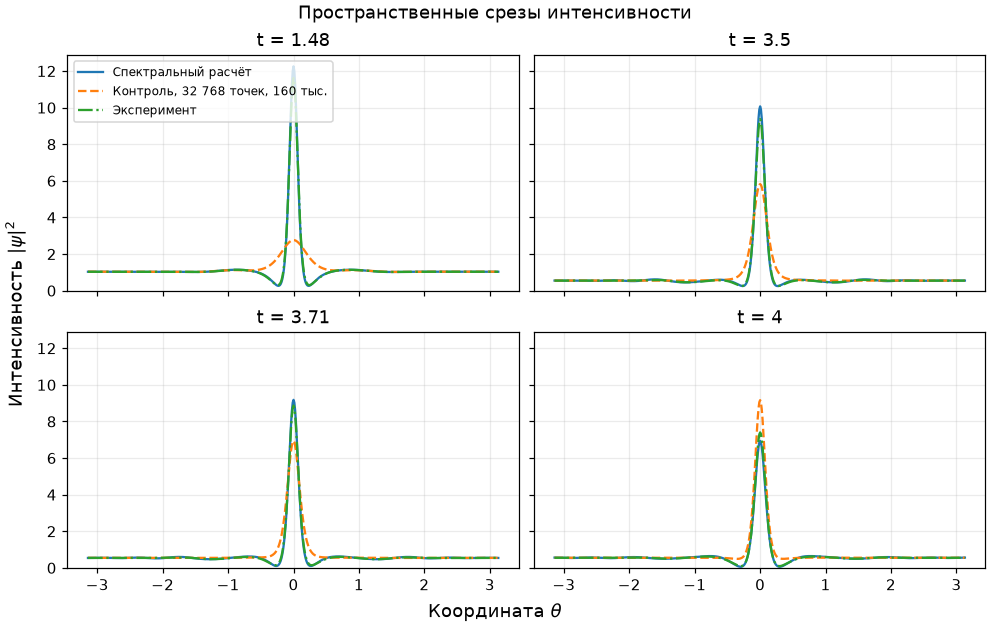

In [188]:
T4_32768_320K_RUN_ID = "2026-11-13_09-51-43_273221"
show_horizon_run(T4_32768_320K_RUN_ID, 'T = 4, 32768 точек, 320 тыс. шагов', t4_budget_control, 'Контроль, 32 768 точек, 160 тыс.', (1.48, 3.5, 3.71, 4.0))

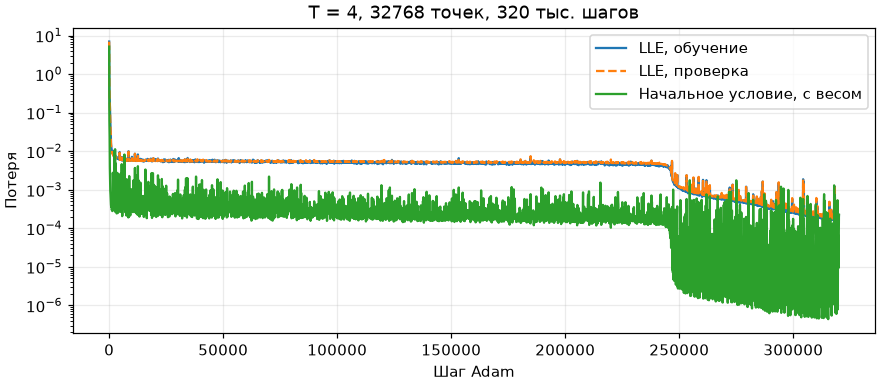

In [189]:
fig = plot_loss_history(T4_32768_320K_RUN_ID, 'T = 4, 32768 точек, 320 тыс. шагов')
plt.show()

### T = 4, 65536 точек, 160 тыс. шагов

Максимальная ошибка на [0,2] — 72.11%
Максимальная ошибка на [0,T] — 72.11% при t = 1.79


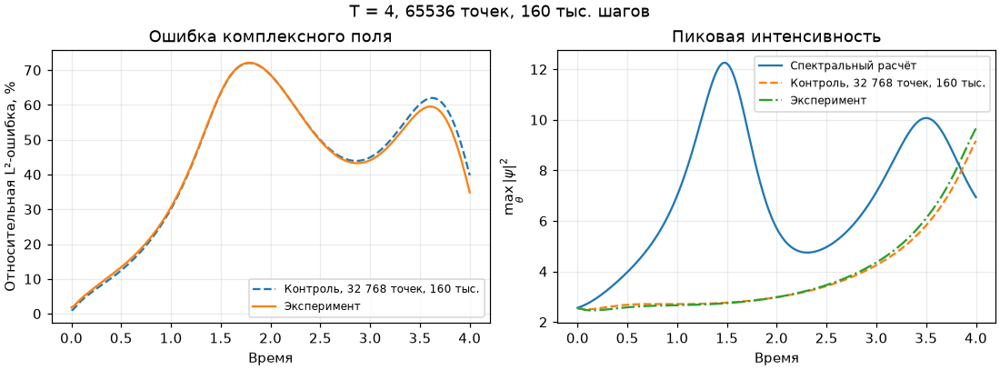

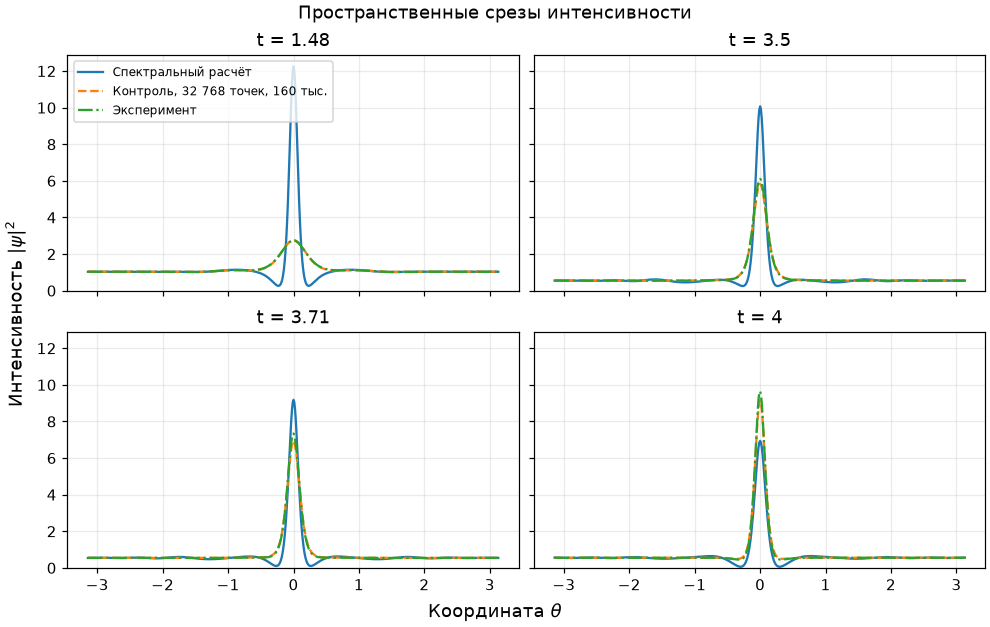

In [190]:
T4_65536_160K_RUN_ID = "2026-11-13_09-51-53_529719"
show_horizon_run(T4_65536_160K_RUN_ID, 'T = 4, 65536 точек, 160 тыс. шагов', t4_budget_control, 'Контроль, 32 768 точек, 160 тыс.', (1.48, 3.5, 3.71, 4.0))

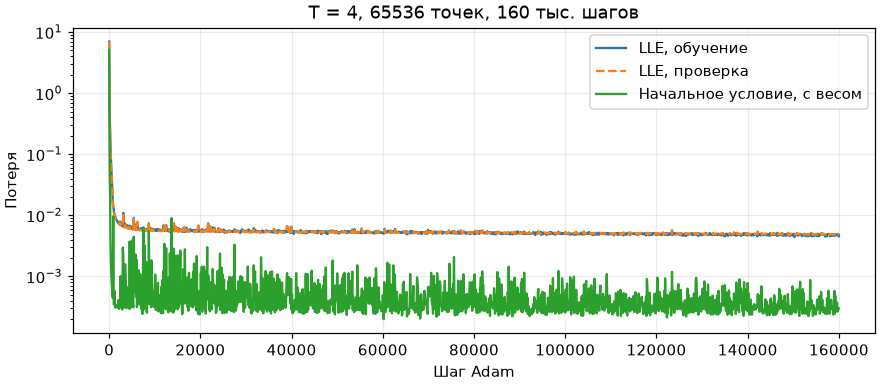

In [191]:
fig = plot_loss_history(T4_65536_160K_RUN_ID, 'T = 4, 65536 точек, 160 тыс. шагов')
plt.show()

## Базовая PINN на $[0,4]$ и $[0,4{,}5]$

Все четыре PINN обучены с нуля. Архитектура 4 × 64, четыре гармоники и seed 42. Ошибка — максимум относительной $L^2$-ошибки комплексного поля по сохранённым срезам с шагом 0,01. Для всех запусков использован спектральный расчёт до $T=4{,}5$.

| $T$ | Внутренние точки | Шаги Adam | Макс. ошибка на $[0,4]$ | На $[4,T]$ | На $[0,T]$ | Перелом |
|---:|---:|---:|---:|---:|---:|---:|
| 4 | 32 768 | 480 000 | 1,90% | — | 1,90% | ≈247 000 |
| 4 | 65 536 | 320 000 | 6,13% | — | 6,13% | ≈234 000 |
| 4,5 | 32 768 | 480 000 | 75,79% | 67,93% | 75,79% | — |
| 4,5 | 65 536 | 320 000 | 76,53% | 69,26% | 76,53% | — |

При $T=4$ и 32 768 точках увеличение бюджета с 320 000 до 480 000 шагов снизило максимальную ошибку с 5,74% до 1,90%. Оба пика воспроизведены. При $t=1{,}48$ и $t=3{,}5$ интенсивности пиков составляют 12,02 и 9,85 при эталонных 12,26 и 10,07. При 65 536 точках перелом на 13 100 шагов раньше, чем при 32 768, по медианам обучающей и проверочной невязок в соседних окнах по 5000 шагов. История потерь до конца соответствующих более коротких запусков совпала точно в обеих конфигурациях.

При $T=4{,}5$ обе модели остались на плато с проверочной невязкой порядка $5\times10^{-3}$. При увеличении горизонта ошибка резко выросла уже на общем интервале $[0,4]$ в обеих парах. Ранний пик при $t=1{,}48$ составляет 2,67 и 2,63 при эталонных 12,26.

In [192]:
REFERENCE_T45_RUN_ID = "2026-11-14_03-50-24_060470"
reference_t45 = load_evolution(get_run(REFERENCE_T45_RUN_ID).path)

### T = 4, 32768 точек, 480 тыс. шагов

Максимальная ошибка на [0,4] — 1.90%
Максимальная ошибка на [0,T] — 1.90% при t = 2.51


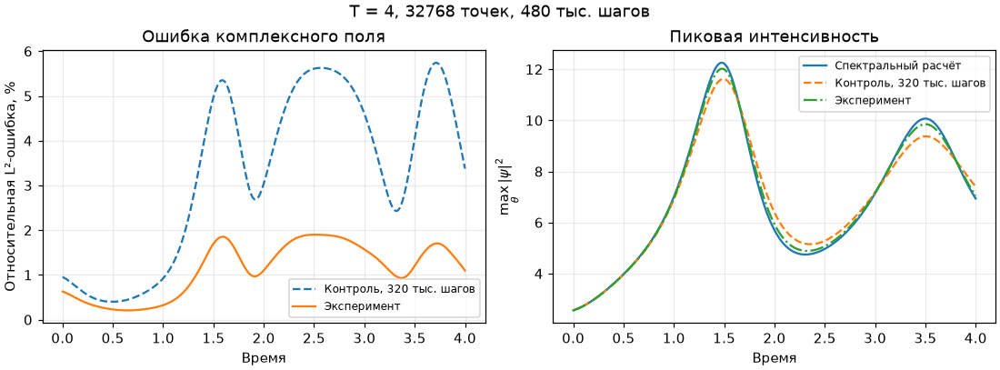

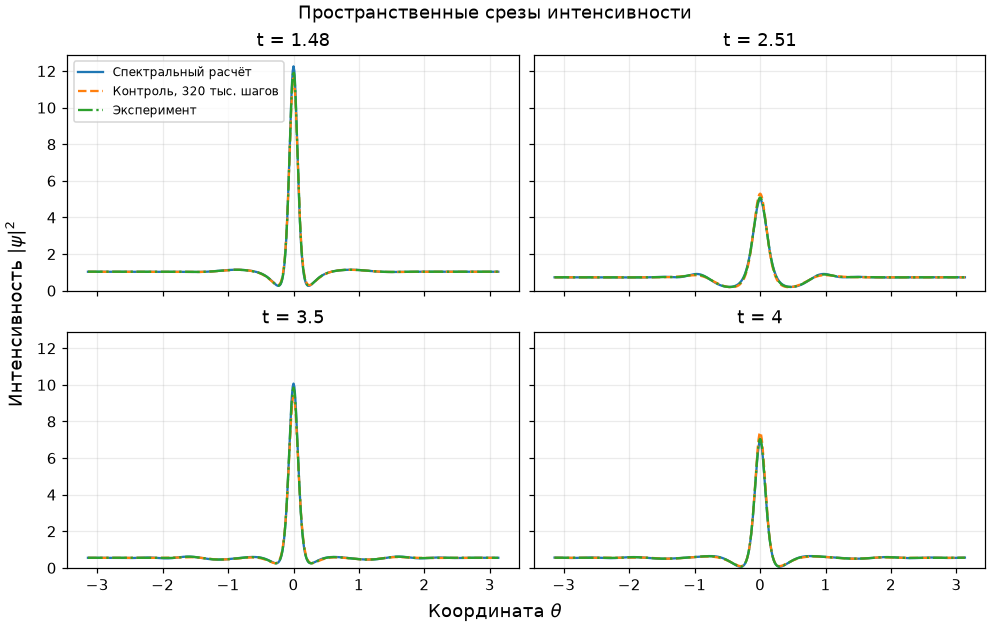

In [193]:
T4_32768_480K_RUN_ID = "2026-11-16_01-35-22_064938"
show_horizon_run(T4_32768_480K_RUN_ID, 'T = 4, 32768 точек, 480 тыс. шагов', load_evolution(get_run(T4_32768_320K_RUN_ID).path),
                 'Контроль, 320 тыс. шагов', (1.48, 2.51, 3.5, 4.0), reference=reference_t45, early_end=4)

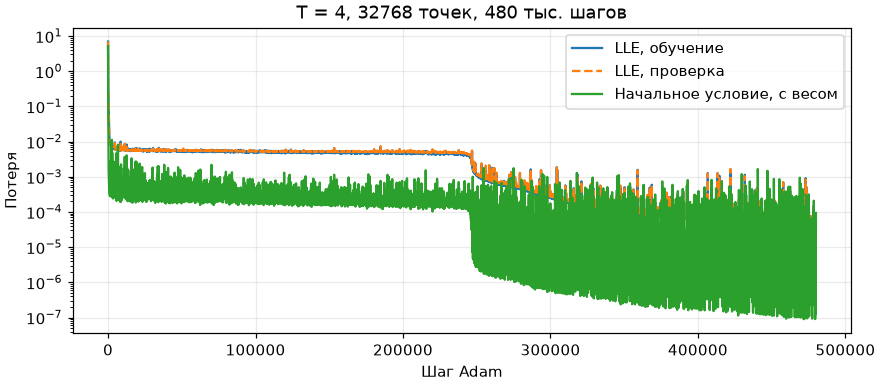

In [194]:
fig = plot_loss_history(T4_32768_480K_RUN_ID, 'T = 4, 32768 точек, 480 тыс. шагов')
plt.show()

### T = 4, 65536 точек, 320 тыс. шагов

Максимальная ошибка на [0,4] — 6.13%
Максимальная ошибка на [0,T] — 6.13% при t = 3.67


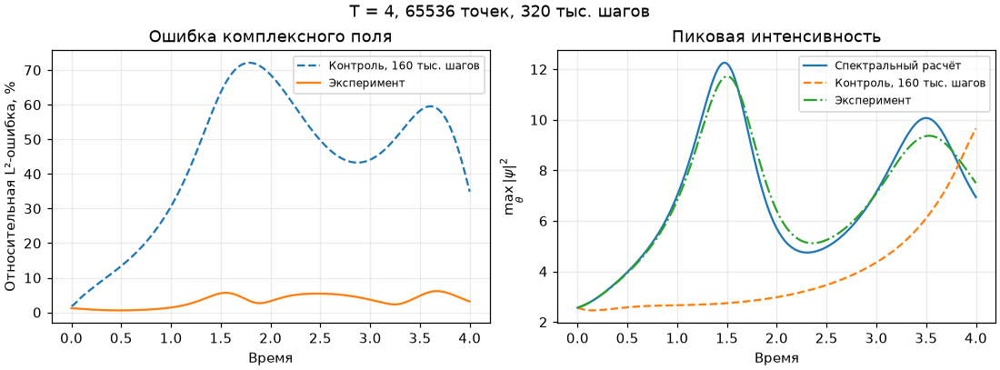

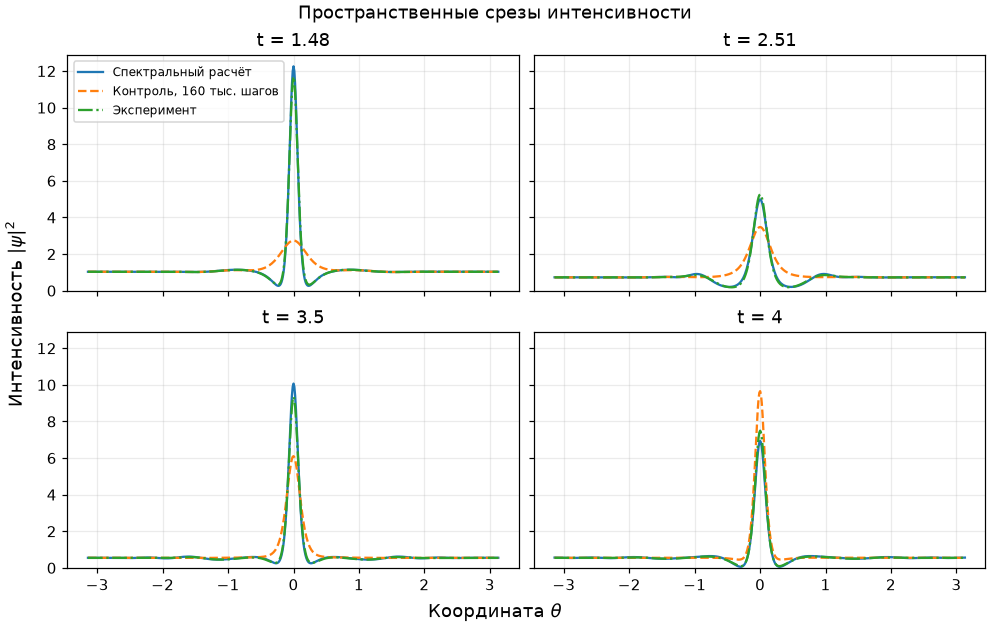

In [195]:
T4_65536_320K_RUN_ID = "2026-11-16_01-35-37_481548"
show_horizon_run(T4_65536_320K_RUN_ID, 'T = 4, 65536 точек, 320 тыс. шагов', load_evolution(get_run(T4_65536_160K_RUN_ID).path),
                 'Контроль, 160 тыс. шагов', (1.48, 2.51, 3.5, 4.0), reference=reference_t45, early_end=4)

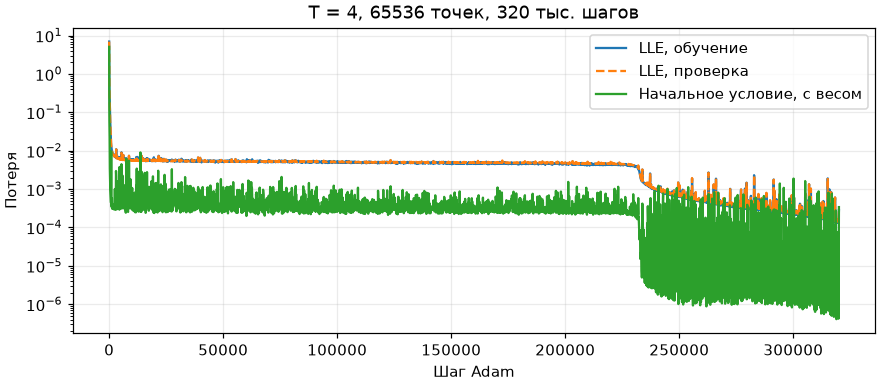

In [196]:
fig = plot_loss_history(T4_65536_320K_RUN_ID, 'T = 4, 65536 точек, 320 тыс. шагов')
plt.show()

### T = 4,5, 32768 точек, 480 тыс. шагов

Максимальная ошибка на [0,4] — 75.79%
Максимальная ошибка на [0,T] — 75.79% при t = 3.73


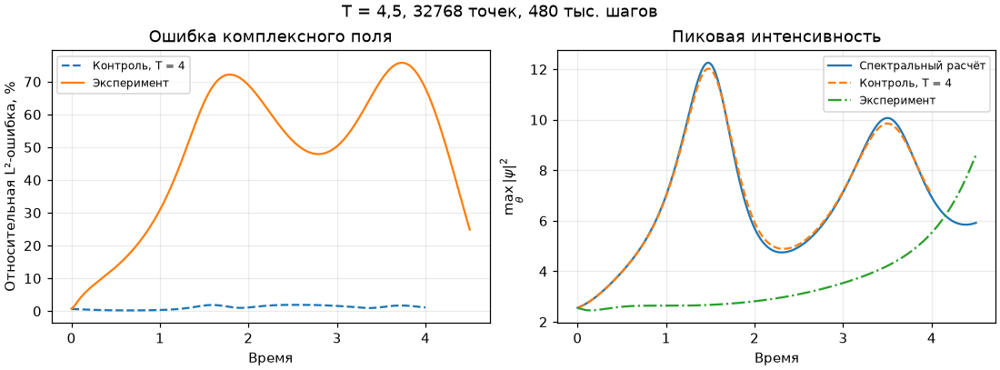

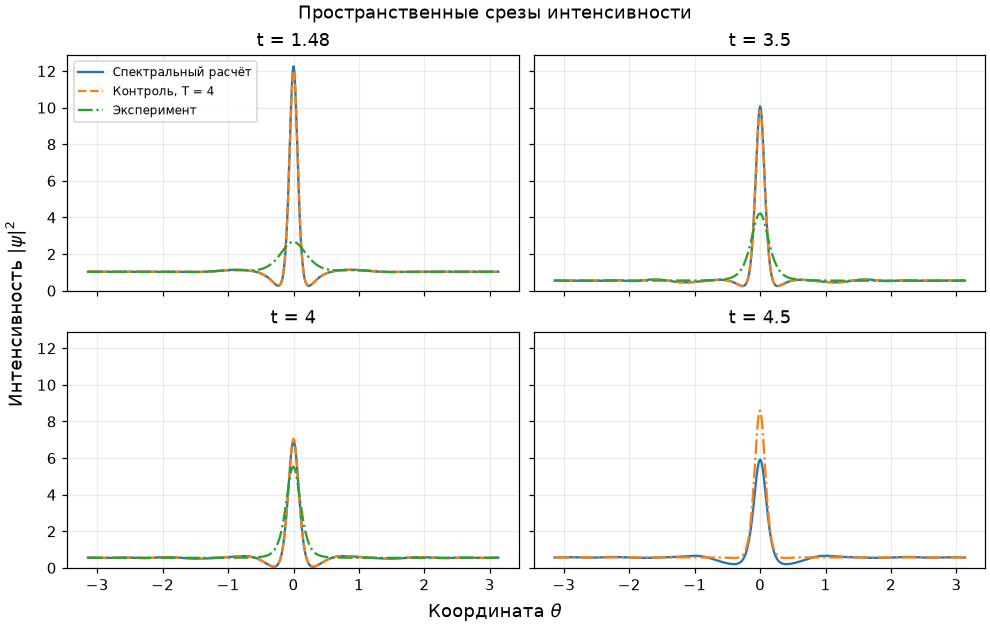

In [197]:
T45_32768_480K_RUN_ID = "2026-11-16_01-35-51_607637"
show_horizon_run(T45_32768_480K_RUN_ID, 'T = 4,5, 32768 точек, 480 тыс. шагов', load_evolution(get_run(T4_32768_480K_RUN_ID).path),
                 'Контроль, T = 4', (1.48, 3.5, 4.0, 4.5), reference=reference_t45, early_end=4)

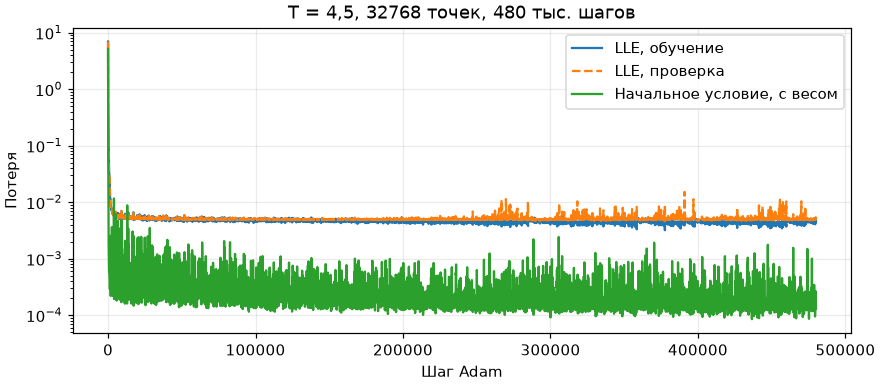

In [198]:
fig = plot_loss_history(T45_32768_480K_RUN_ID, 'T = 4,5, 32768 точек, 480 тыс. шагов')
plt.show()

### T = 4,5, 65536 точек, 320 тыс. шагов

Максимальная ошибка на [0,4] — 76.53%
Максимальная ошибка на [0,T] — 76.53% при t = 3.74


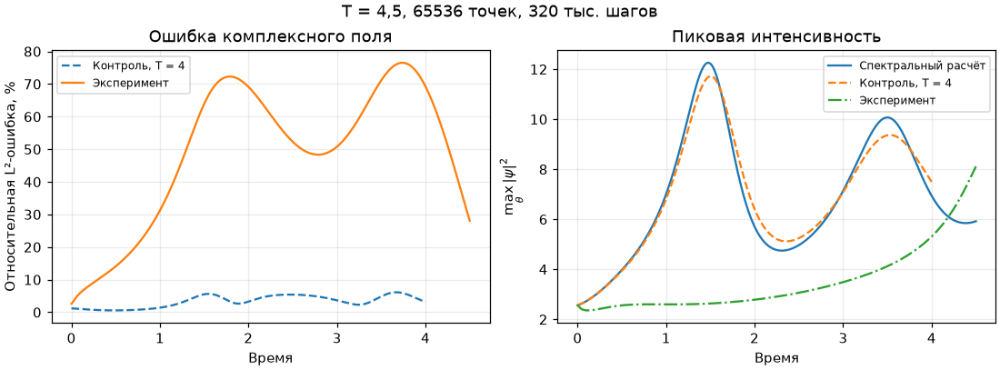

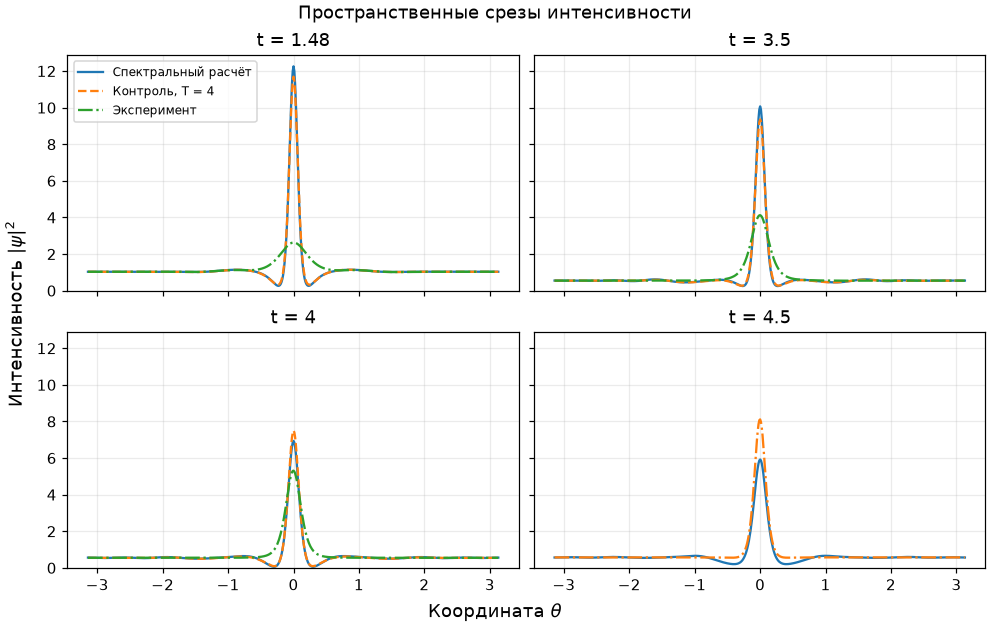

In [199]:
T45_65536_320K_RUN_ID = "2026-11-16_01-36-05_867753"
show_horizon_run(T45_65536_320K_RUN_ID, 'T = 4,5, 65536 точек, 320 тыс. шагов', load_evolution(get_run(T4_65536_320K_RUN_ID).path),
                 'Контроль, T = 4', (1.48, 3.5, 4.0, 4.5), reference=reference_t45, early_end=4)

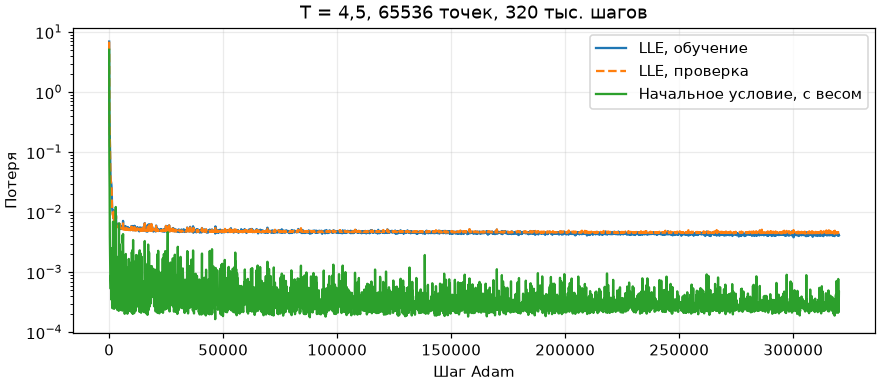

In [200]:
fig = plot_loss_history(T45_65536_320K_RUN_ID, 'T = 4,5, 65536 точек, 320 тыс. шагов')
plt.show()

## Карта перехода на кривых потерь в зависимости от $T$ и $N$

Для каждой пары взят самый длинный завершённый запуск базовой PINN с той же конфигурацией, что у запуска $T=4$, $N=32\,768$ на 480 000 шагов. В сравниваемых конфигурациях меняются $T$, число внутренних точек и бюджет. Шкалы показывают проверенные значения, пустые ячейки соответствуют отсутствующим сочетаниям.

Для каждого кандидата сравниваются медианы обучающей и проверочной невязок LLE в трёх окнах по 5000 шагов, одном до кандидата и двух после. Для каждой кривой берётся отношение медианы до шага к большей из двух медиан после. Положение перехода — максимум меньшего из двух отношений. Первые 15 000 шагов отведены под начальное падение loss, а оценка требует ещё 10 000 шагов после кандидата. Порог резкого перехода выбран равным 2,5, для более плавного спада — 1,8. Серые ячейки показывают бюджет наблюдения, поэтому переход в конце запуска или после него остаётся возможным.

При $N=32\,768$ переход сдвинулся с 134,4 тыс. шагов при $T=3{,}5$ до 247,4 тыс. при $T=4$. При фиксированных $T=3{,}5$ и $T=4$ удвоение $N$ сдвинуло переход раньше на 16,8 и 13,1 тыс. шагов соответственно. При $T=4{,}5$ в сохранённых запусках сравнимого спада пока нет.

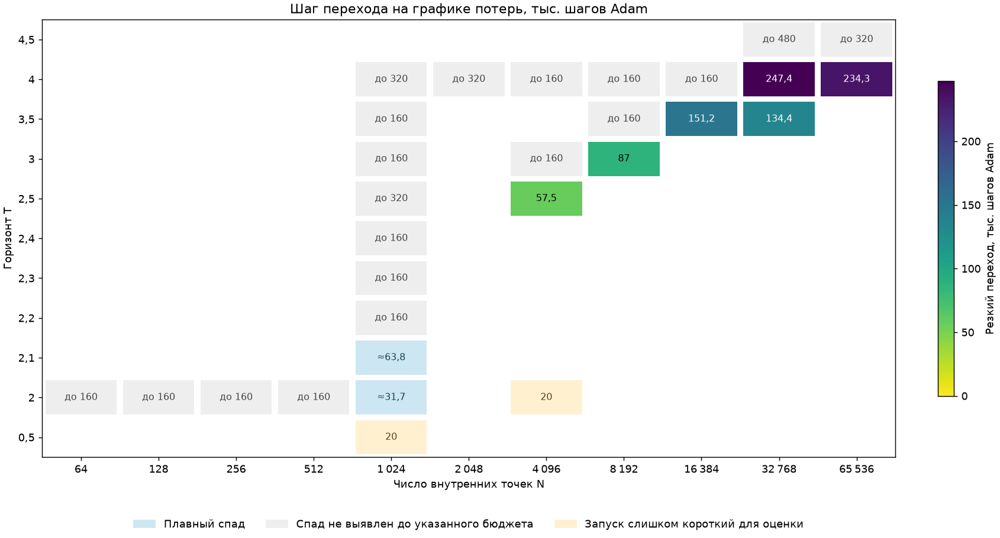

In [201]:

from lle.runs.runs import list_runs
from lle.workflows.pinn_gaussian.config import PinnGaussianConfig
import numpy as np

def collect_transition_runs():
    sweep_axes = {"domain": {"time_end", "interior_points"}, "training": {"iterations"}}
    baseline = get_run(T4_32768_480K_RUN_ID).load_config(PinnGaussianConfig)
    shared = baseline.model_dump(exclude=sweep_axes)
    records = {}
    for run in list_runs(script="scripts/pinn_gaussian.py"):
        meta = run.load_metadata()
        if meta["status"] != "complete" or meta.get("resumed_from") or not (run.path / "losses.csv").is_file():
            continue
        cfg = run.load_config(PinnGaussianConfig)
        if cfg.model_dump(exclude=sweep_axes) != shared:
            continue
        losses = np.genfromtxt(run.path / "losses.csv", delimiter=",", names=True)
        key = (cfg.domain.time_end, cfg.domain.interior_points)
        end = int(losses["step"][-1])
        if key not in records or end > records[key][0]:
            records[key] = (end, run.id, losses)
    return records

def find_loss_transition(losses, window=5000):
    steps = losses["step"]
    pde = np.column_stack([losses[f"{s}_pde_u"] + losses[f"{s}_pde_v"]
                           for s in ("train", "test")])
    best_step, best_drop = None, 0.0
    candidates = steps[(steps >= 3 * window) & (steps <= steps[-1] - 2 * window)]
    for step in candidates:
        i, j, k, l = np.searchsorted(steps, [step - window, step, step + window, step + 2 * window])
        before = np.median(pde[i:j], axis=0)
        after = np.maximum(np.median(pde[j:k], axis=0), np.median(pde[k:l], axis=0))
        if np.any(after <= 0):
            continue
        drop = (before / after).min()
        if drop > best_drop:
            best_step, best_drop = int(step), float(drop)
    return best_step, best_drop


from matplotlib.colors import Normalize
from matplotlib.patches import Patch, Rectangle

transition_runs = collect_transition_runs()
transition_estimates = {pair: find_loss_transition(losses)
                        for pair, (_, _, losses) in transition_runs.items()}
horizons = sorted({horizon for horizon, _ in transition_runs})
point_counts = sorted({points for _, points in transition_runs})
norm = Normalize(vmin=0, vmax=max(step / 1000 for step, drop in transition_estimates.values()
                                   if drop >= 2.5))
cmap = plt.get_cmap("viridis_r")
fig, ax = plt.subplots(figsize=(13, 7), layout="constrained")
ax.set(xlim=(-0.5, len(point_counts)-0.5), ylim=(-0.5, len(horizons)-0.5),
       xlabel="Число внутренних точек N", ylabel="Горизонт T",
       title="Шаг перехода на графике потерь, тыс. шагов Adam")
ax.set_xticks(range(len(point_counts)), [f"{n:,}".replace(",", " ") for n in point_counts])
ax.set_yticks(range(len(horizons)), [f"{t:g}".replace(".", ",") for t in horizons])

for row, horizon in enumerate(horizons):
    for column, points in enumerate(point_counts):
        pair = (horizon, points)
        if pair not in transition_runs:
            continue
        end, _, _ = transition_runs[pair]
        step, drop = transition_estimates[pair]
        if drop >= 2.5:
            color = cmap(norm(step / 1000))
            label = f"{step / 1000:g}".replace(".", ",")
            ink = "white" if np.dot(color[:3], [0.2126, 0.7152, 0.0722]) < 0.49 else "black"
        elif drop >= 1.8:
            color, ink = "#cce7f2", "#163e51"
            label = f"≈{step / 1000:g}".replace(".", ",")
        elif step is None:
            color, ink = "#fff1d0", "#554118"
            label = f"{end / 1000:g}"
        else:
            color, ink = "#eeeeee", "#444444"
            label = f"до {end / 1000:g}"
        ax.add_patch(Rectangle((column - 0.46, row - 0.43), 0.92, 0.86,
                               facecolor=color, edgecolor="none"))
        ax.text(column, row, label, ha="center", va="center", color=ink, fontsize=9)

fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.72,
             label="Резкий переход, тыс. шагов Adam")
ax.legend(handles=[Patch(color="#cce7f2", label="Плавный спад"),
                   Patch(color="#eeeeee", label="Спад не выявлен до указанного бюджета"),
                   Patch(color="#fff1d0", label="Запуск слишком короткий для оценки")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.show()


## Увеличение бюджета при T = 4,5

Все модели имеют архитектуру 4 × 64, четыре гармоники и seed 42. Ошибки комплексного поля вычислены на общей сетке спектрального расчёта до T = 4,5.

| Внутренние точки | Шаги Adam | Устройство | Макс. ошибка на [0; 4,5] | На [4; 4,5] | Пик при t = 1,48 | Пик при t = 3,5 |
|---:|---:|---|---:|---:|---:|---:|
| 32 768 | 480 000 | RTX 4060 Laptop | 75,79% | 67,93% | 2,67 | 4,22 |
| 32 768 | 640 000 | RTX 4060 Laptop | 75,67% | 67,49% | 2,64 | 4,24 |
| 65 536 | 320 000 | RTX 4060 Laptop | 76,53% | 69,26% | 2,63 | 4,12 |
| 65 536 | 480 000 | RTX 4060 Laptop | 72,65% | 61,64% | 2,65 | 4,61 |
| 65 536 | 640 000 | RTX 4090 | 72,03% | 30,57% | 2,78 | 7,13 |
| Спектральный расчёт | — | — | — | — | 12,26 | 10,07 |

В добавленных запусках 2026-11-17_13-01-27_191527 и 2026-11-17_13-04-57_667576 перелом на кривых потерь не выявлен. У обоих история потерь на общем префиксе точно совпала с прежним запуском с тем же числом точек и меньшим бюджетом. При 32 768 точках увеличение бюджета до 640 000 шагов почти не изменило ошибку. При 65 536 точках за 480 000 шагов максимальная ошибка уменьшилась до 72,65%, однако ранний пик остался существенно занижен.

Запуск на 640 000 шагов с 65 536 точками выполнен на RTX 4090 за 2 ч 44 мин. При сравнении его первых 320 000 шагов с прежним запуском медианное абсолютное относительное расхождение проверочной невязки LLE после шага 1000 составляет 0,73%, в 90% сохранённых шагов оно не превышает 3,53%. Режим плато сохраняется. Одновременно менялись аппаратная среда и версия кода, поэтому вклад каждой причины отдельно не установлен. Критерий 5% не достигнут ни одним из запусков при T = 4,5.


### T = 4,5, 65 536 точек, 480 тыс. шагов

Максимальная ошибка на [0,4] — 72.65%
Максимальная ошибка на [0,T] — 72.65% при t = 3.7


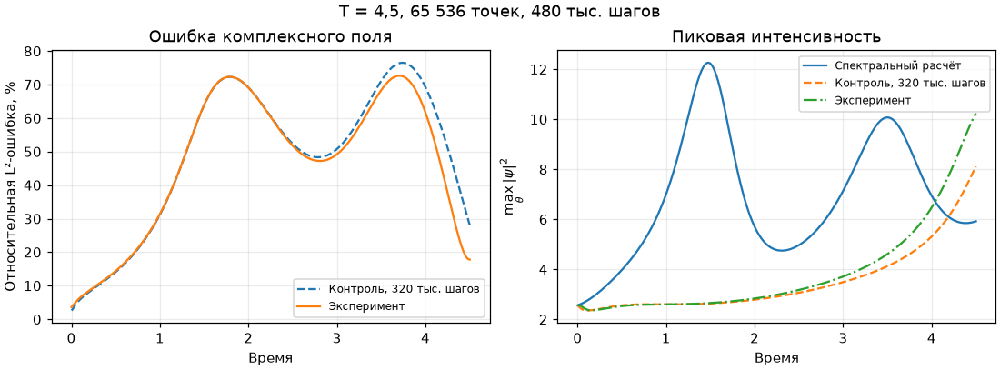

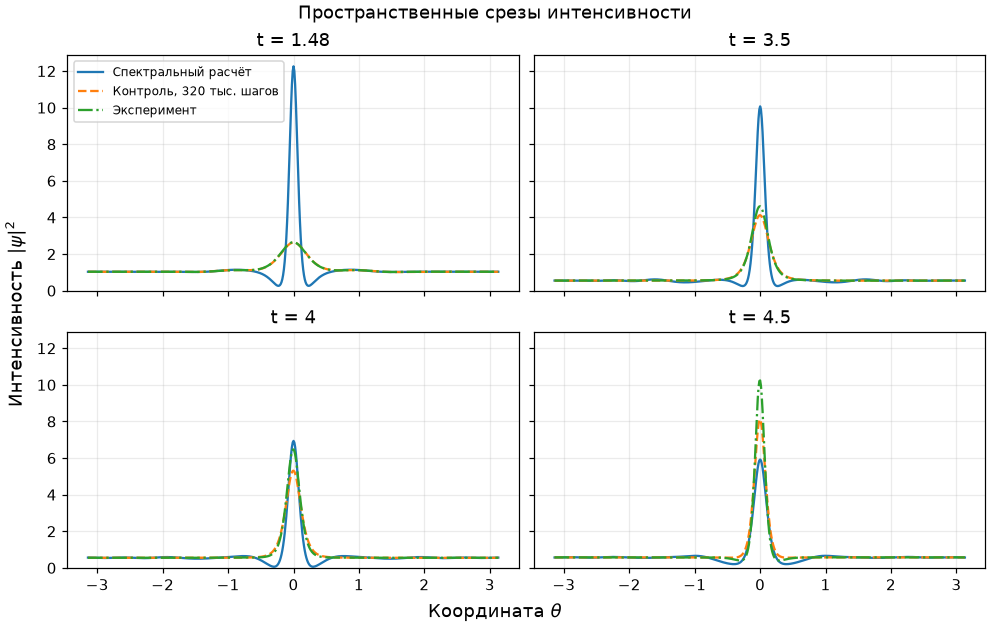

In [204]:
T45_65536_480K_RUN_ID = "2026-11-17_13-01-27_191527"
show_horizon_run(T45_65536_480K_RUN_ID, "T = 4,5, 65 536 точек, 480 тыс. шагов",
    load_evolution(get_run(T45_65536_320K_RUN_ID).path), "Контроль, 320 тыс. шагов",
    (1.48, 3.5, 4.0, 4.5), reference=load_evolution(get_run(REFERENCE_T45_RUN_ID).path), early_end=4)

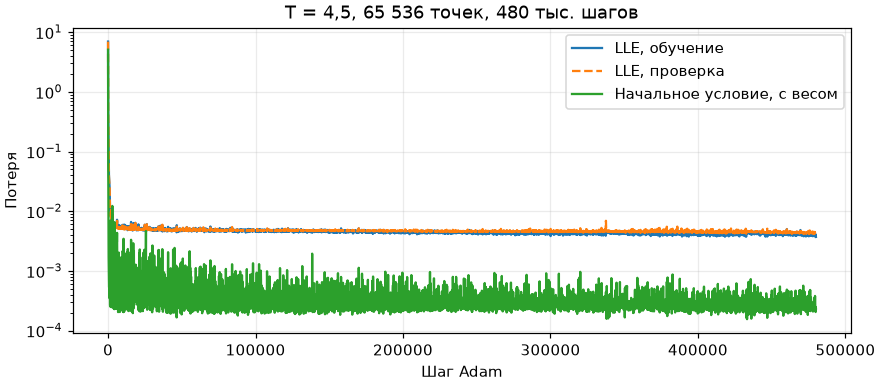

In [205]:
fig = plot_loss_history(T45_65536_480K_RUN_ID, "T = 4,5, 65 536 точек, 480 тыс. шагов")
plt.show()

### T = 4,5, 32 768 точек, 640 тыс. шагов

Максимальная ошибка на [0,4] — 75.67%
Максимальная ошибка на [0,T] — 75.67% при t = 3.73


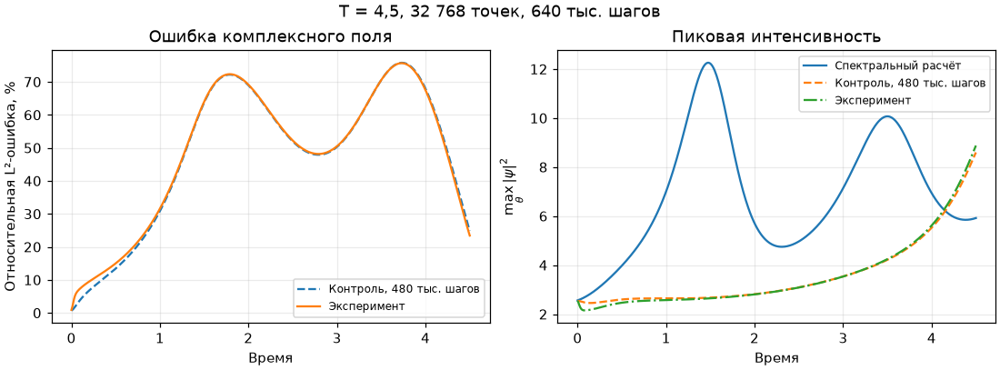

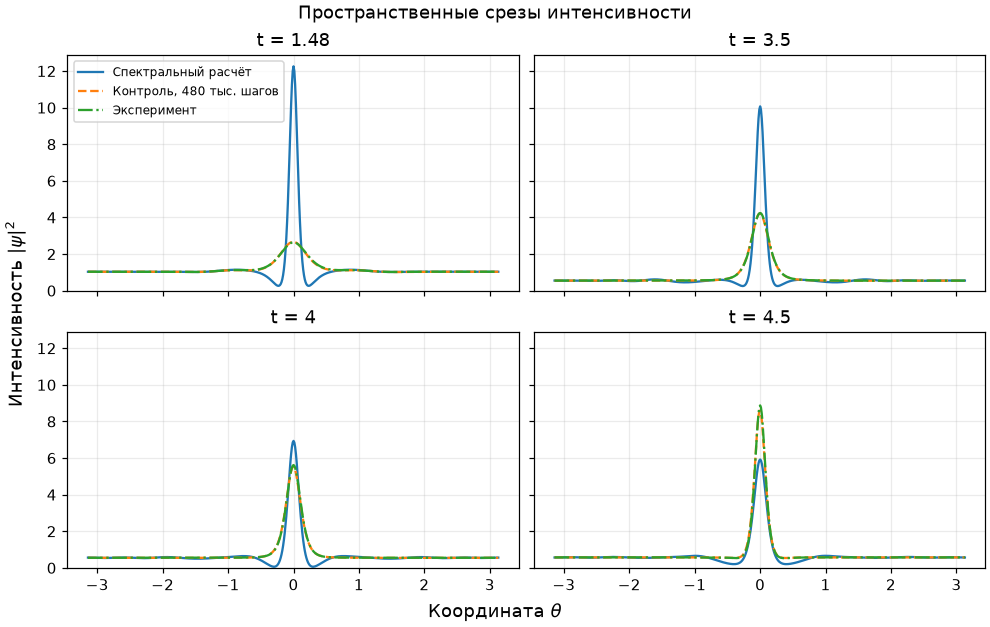

In [206]:
T45_32768_640K_RUN_ID = "2026-11-17_13-04-57_667576"
show_horizon_run(T45_32768_640K_RUN_ID, "T = 4,5, 32 768 точек, 640 тыс. шагов",
    load_evolution(get_run(T45_32768_480K_RUN_ID).path), "Контроль, 480 тыс. шагов",
    (1.48, 3.5, 4.0, 4.5), reference=load_evolution(get_run(REFERENCE_T45_RUN_ID).path), early_end=4)

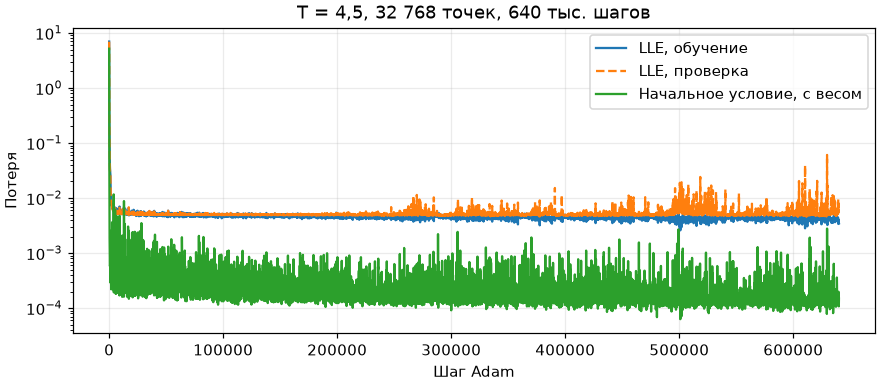

In [207]:
fig = plot_loss_history(T45_32768_640K_RUN_ID, "T = 4,5, 32 768 точек, 640 тыс. шагов")
plt.show()

Максимальная ошибка на [0,4] — 72.03%
Максимальная ошибка на [0,T] — 72.03% при t = 1.78


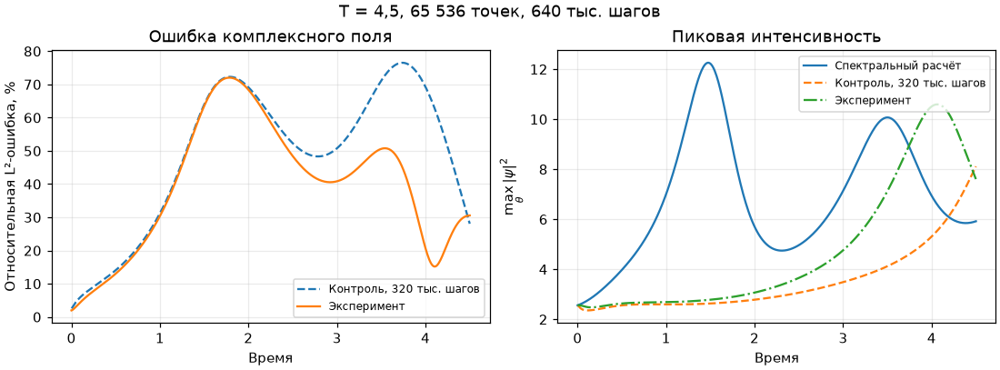

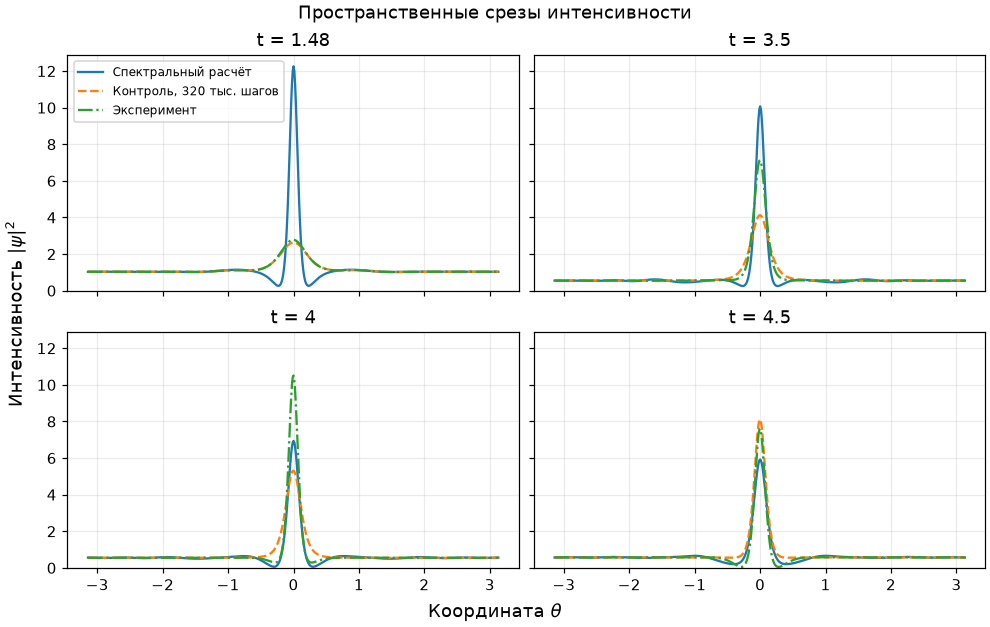

In [202]:
T45_65536_640K_RUN_ID = "2026-11-19_07-58-59_106269"
show_horizon_run(T45_65536_640K_RUN_ID, "T = 4,5, 65 536 точек, 640 тыс. шагов",
    load_evolution(get_run(T45_65536_320K_RUN_ID).path), "Контроль, 320 тыс. шагов",
    (1.48, 3.5, 4.0, 4.5), reference=load_evolution(get_run(REFERENCE_T45_RUN_ID).path), early_end=4)

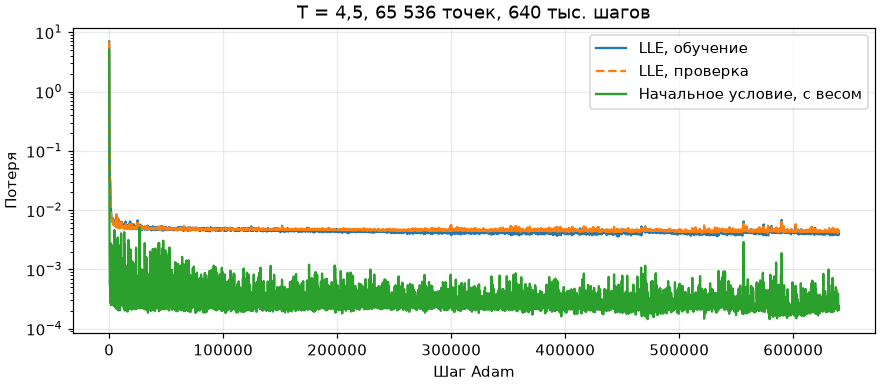

In [203]:
fig = plot_loss_history(T45_65536_640K_RUN_ID, "T = 4,5, 65 536 точек, 640 тыс. шагов")
plt.show()

## Продолжения при T = 4,5 до 2 и 2,2 млн шагов

Оба запуска продолжены с шага 640 000 через extend с сохранением состояния Adam, точек и генераторов случайных чисел. Истории потерь до этого шага точно совпадают с родительскими. Базовая сеть 4 × 64 с четырьмя гармониками, seed 42, NVIDIA GeForce RTX 4090.

| Точки | Итоговые шаги Adam | Дополнительные шаги | Макс. ошибка на [0; 4] | На [4; 4,5] | На [0; 4,5] |
|---:|---:|---:|---:|---:|---:|
| 65 536 | 2 000 000 | 1 360 000 | 0,80% | 0,60% | 0,80% |
| 32 768 | 2 200 000 | 1 560 000 | 81,27% | 77,38% | 81,27% |

При 65 536 точках критерий 5% выполнен на всём интервале. Максимум ошибки 0,80% приходится на t = 2,65. При t = 1,48 и t = 3,5 пиковые интенсивности равны 12,15 и 9,96 при эталонных 12,26 и 10,07. Устойчивый перелом на кривых потерь выявлен около шага 663 600 по прежнему критерию с медианами в окнах по 5000 шагов. Предыдущий запуск заканчивался на 640 000-м шаге, примерно за 24 000 шагов до перелома.

При 32 768 точках сопоставимого перелома до 2,2 млн шагов нет. Максимальная ошибка выросла с 75,67% до 81,27%, ранний пик при t = 1,48 остался на уровне 2,61. Увеличение бюджета само по себе не обеспечило успешного обучения при этом числе точек.

Фактические итоговые бюджеты по конфигурациям и losses.csv равны 2 и 2,2 млн шагов. Это больше ранее обсуждавшихся 1 и 1,2 млн.


### T = 4,5, 65536 точек, 2000 тыс. шагов

Максимальная ошибка на [0,4] — 0.80%
Максимальная ошибка на [0,T] — 0.80% при t = 2.65


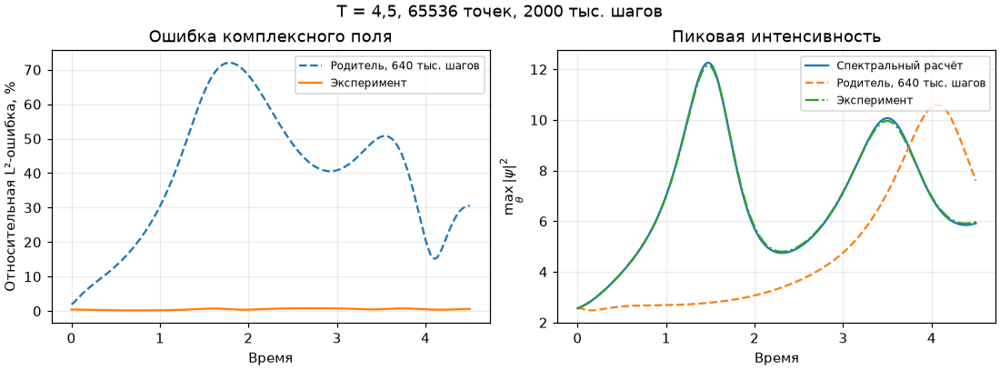

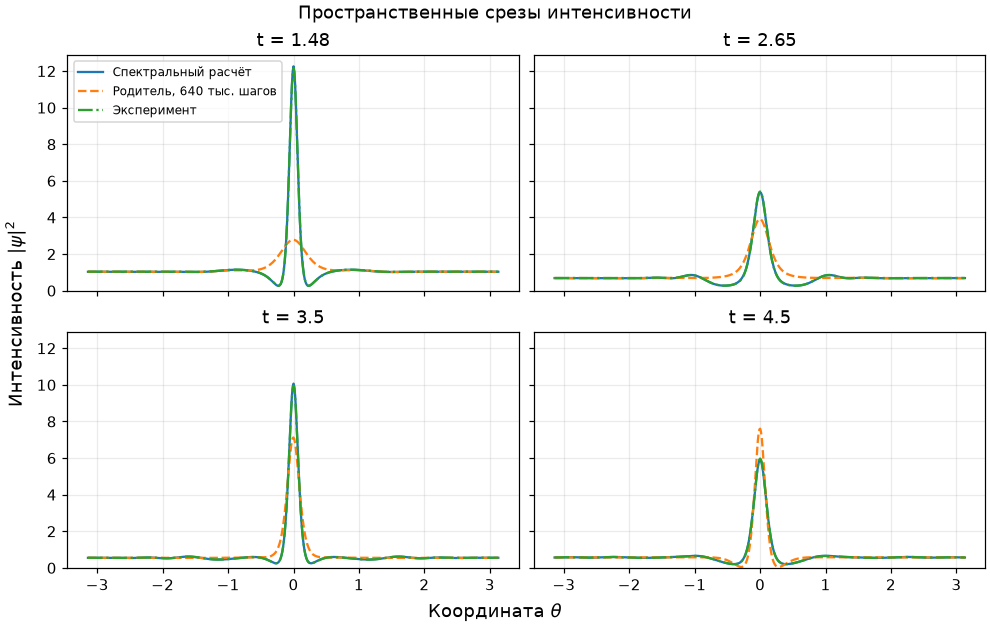

In [208]:
T45_65536_2000K_RUN_ID = "2026-11-19_15-01-33_282810"
show_horizon_run(T45_65536_2000K_RUN_ID, "T = 4,5, 65536 точек, 2000 тыс. шагов", load_evolution(get_run(T45_65536_640K_RUN_ID).path),
    "Родитель, 640 тыс. шагов", (1.48, 2.65, 3.5, 4.5),
    reference=load_evolution(get_run(REFERENCE_T45_RUN_ID).path), early_end=4)

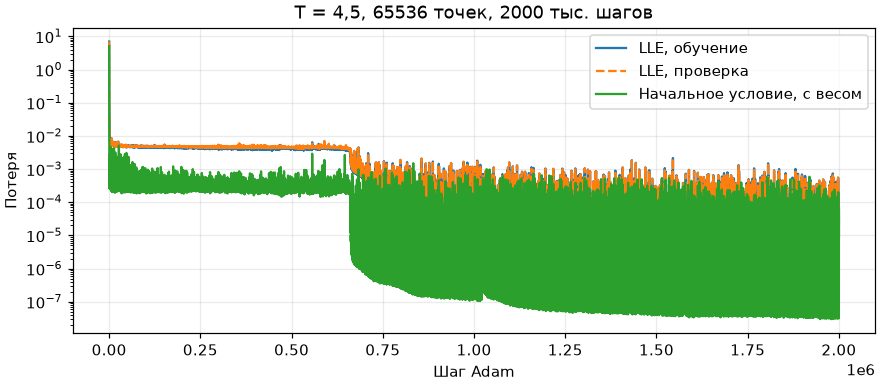

In [209]:
fig = plot_loss_history(T45_65536_2000K_RUN_ID, "T = 4,5, 65536 точек, 2000 тыс. шагов")
plt.show()

### T = 4,5, 32768 точек, 2200 тыс. шагов

Максимальная ошибка на [0,4] — 81.27%
Максимальная ошибка на [0,T] — 81.27% при t = 3.78


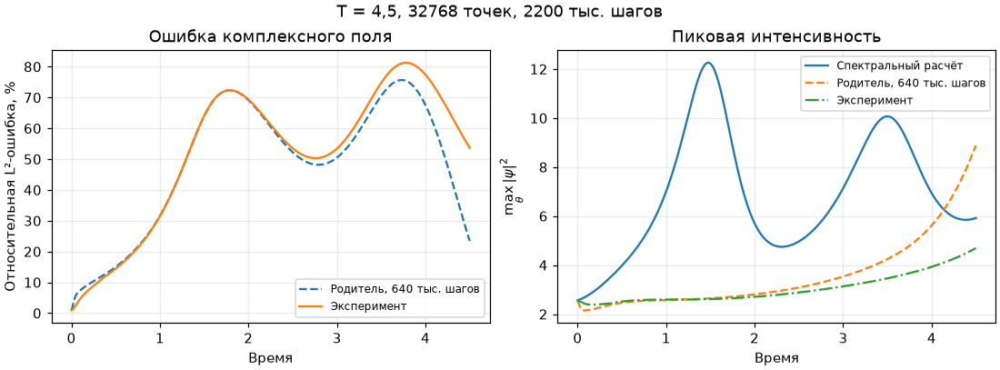

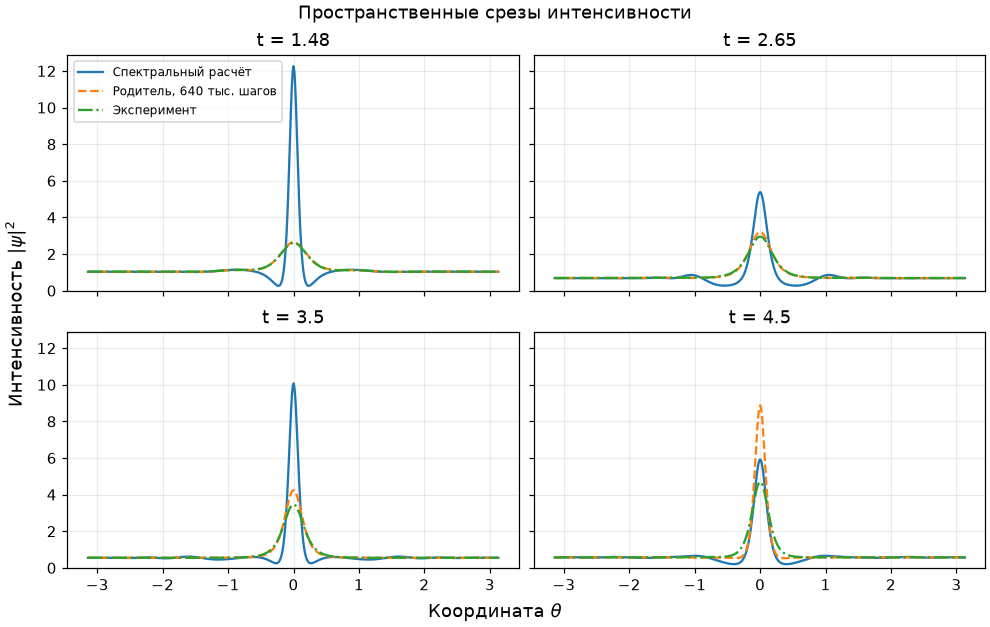

In [210]:
T45_32768_2200K_RUN_ID = "2026-11-19_15-06-40_966538"
show_horizon_run(T45_32768_2200K_RUN_ID, "T = 4,5, 32768 точек, 2200 тыс. шагов", load_evolution(get_run(T45_32768_640K_RUN_ID).path),
    "Родитель, 640 тыс. шагов", (1.48, 2.65, 3.5, 4.5),
    reference=load_evolution(get_run(REFERENCE_T45_RUN_ID).path), early_end=4)

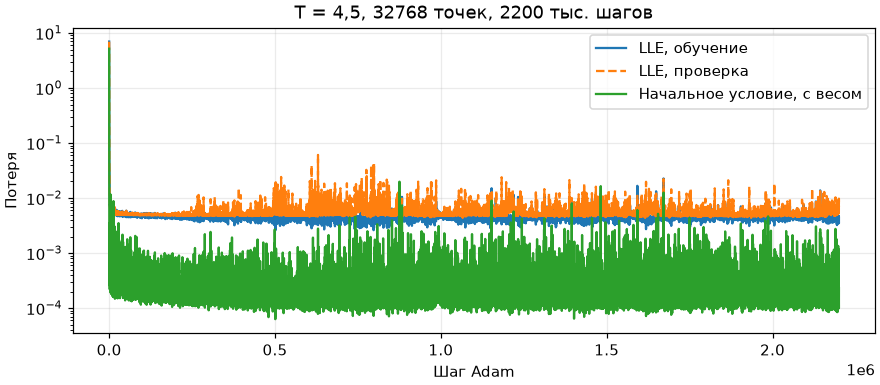

In [211]:
fig = plot_loss_history(T45_32768_2200K_RUN_ID, "T = 4,5, 32768 точек, 2200 тыс. шагов")
plt.show()

## Базовая PINN при T = 5 с 65 536 точками

Базовая сеть 4 × 64, четыре гармоники, seed 42. Первый запуск обучен с нуля за 2 млн шагов. Второй продолжает его ещё на 150 000 шагов с сохранением состояния. История потерь до 2 млн шагов совпала точно.

Спектральный эталон до T = 5 рассчитан с 512 пространственными узлами, шагом интегрирования 0,0005 и интервалом записи 0,01. ID эталона 2026-11-20_11-10-40_241883. На [0; 4,5] комплексное поле эталона точно совпадает с предыдущим расчётом.

| Шаги Adam | Макс. ошибка на [0; 4,5] | На [4,5; 5] | На всём [0; 5] | Ошибка при t = 5 |
|---:|---:|---:|---:|---:|
| 2 000 000 | 80,85% | 51,83% | 80,85% | 28,94% |
| 2 150 000 | 80,61% | 50,79% | 80,61% | 26,33% |

Критерий 5% не выполнен. Устойчивого перелома на кривых потерь не видно в обоих запусках. Проверочная невязка LLE остаётся порядка 0,0042. Максимальная ошибка поля приходится на t = 3,78. При t = 1,48 ранний пик равен 2,61 и 2,63 при эталонном 12,26. При t = 3,5 пики равны 3,53 и 3,55 при эталонном 10,07. Близкая к эталону высота конечного пика в первом запуске (7,49 против 7,52) сочетается с ошибкой комплексного поля 28,94% в том же срезе.


### T = 5, 65 536 точек, 2000 тыс. шагов

Максимальная ошибка на [0,4.5] — 80.85%
Максимальная ошибка на [0,T] — 80.85% при t = 3.78


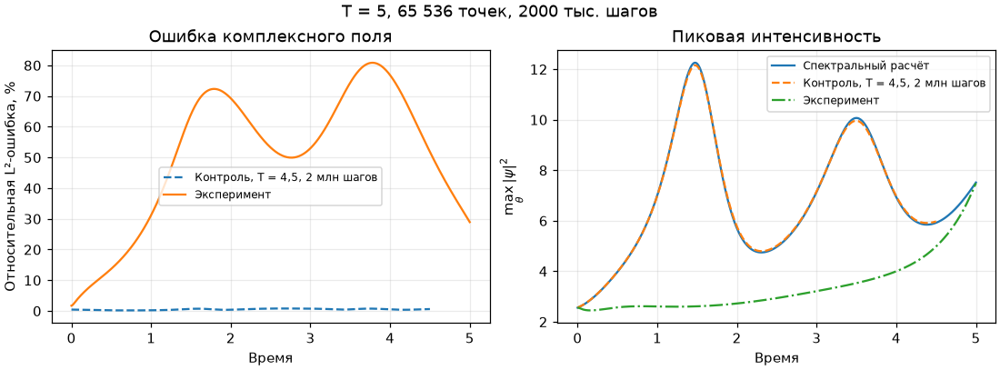

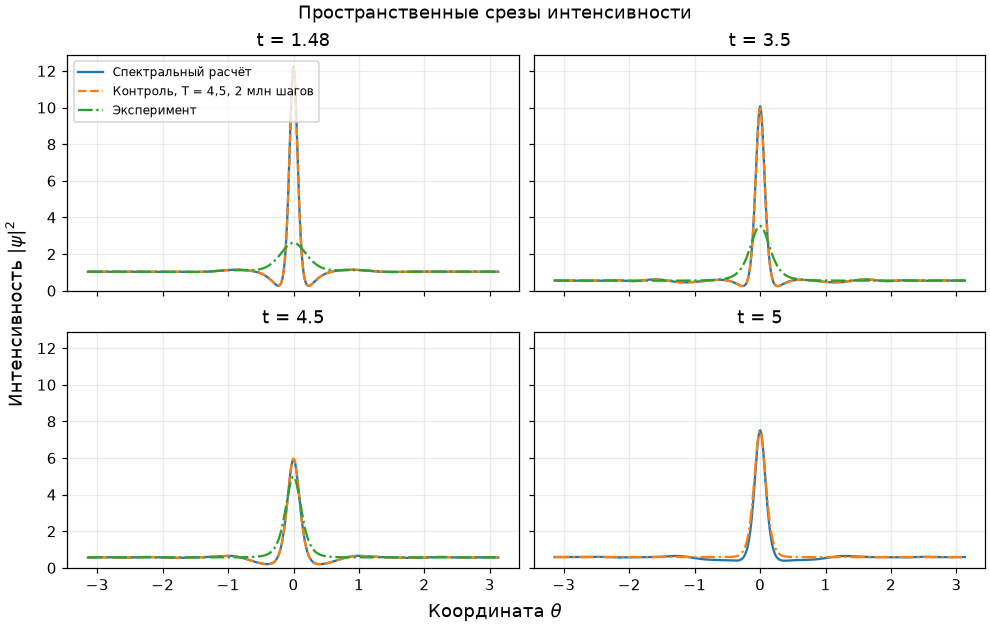

In [212]:
T5_65536_2000K_RUN_ID = "2026-11-20_01-22-50_279660"
show_horizon_run(T5_65536_2000K_RUN_ID, "T = 5, 65 536 точек, 2000 тыс. шагов", load_evolution(get_run(T45_65536_2000K_RUN_ID).path),
    "Контроль, T = 4,5, 2 млн шагов", (1.48, 3.5, 4.5, 5.0),
    reference=load_evolution(get_run("2026-11-20_11-10-40_241883").path), early_end=4.5)

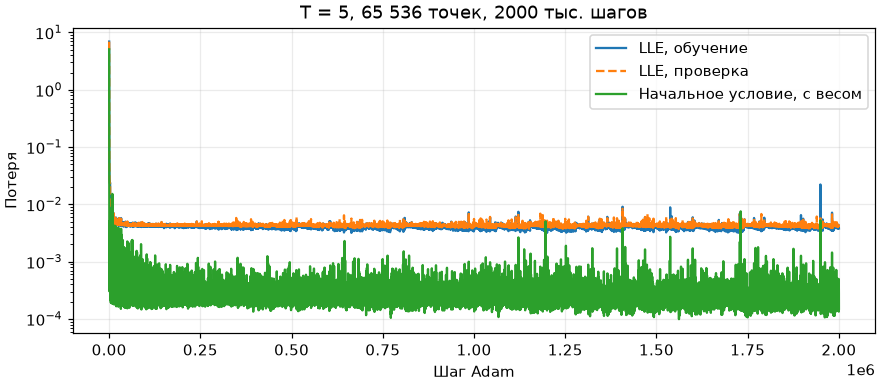

In [213]:
fig = plot_loss_history(T5_65536_2000K_RUN_ID, "T = 5, 65 536 точек, 2000 тыс. шагов")
plt.show()

### T = 5, 65 536 точек, 2150 тыс. шагов

Максимальная ошибка на [0,4.5] — 80.61%
Максимальная ошибка на [0,T] — 80.61% при t = 3.78


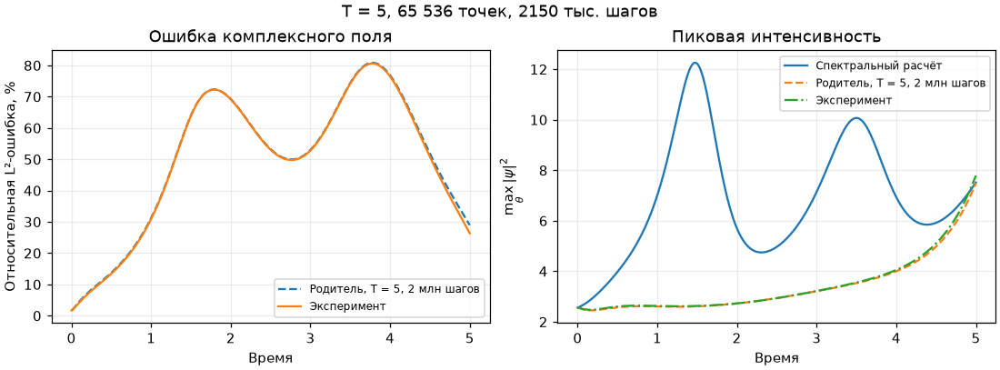

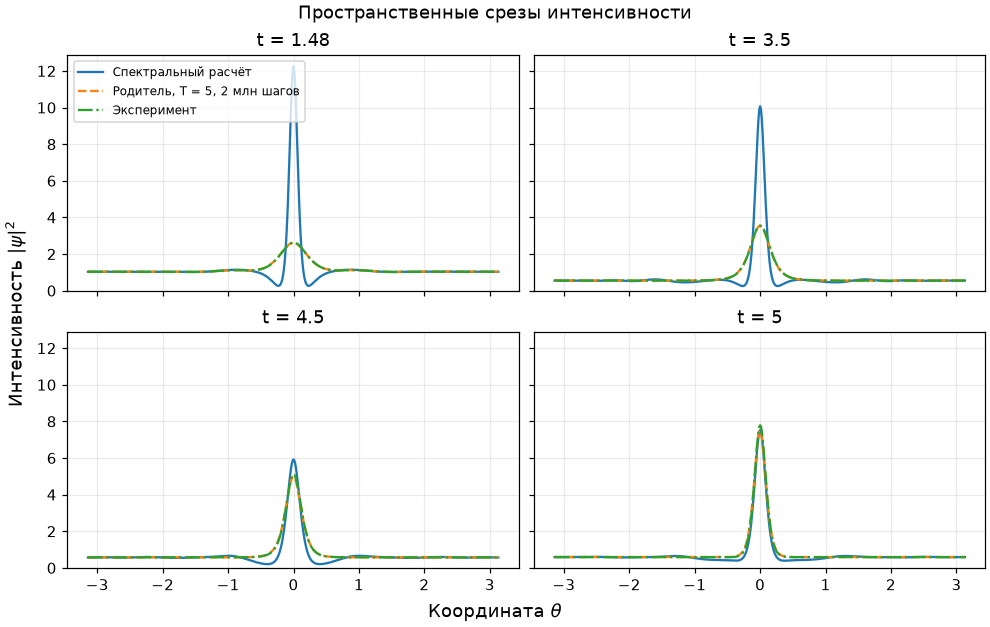

In [214]:
T5_65536_2150K_RUN_ID = "2026-11-20_10-20-38_146255"
show_horizon_run(T5_65536_2150K_RUN_ID, "T = 5, 65 536 точек, 2150 тыс. шагов", load_evolution(get_run(T5_65536_2000K_RUN_ID).path),
    "Родитель, T = 5, 2 млн шагов", (1.48, 3.5, 4.5, 5.0),
    reference=load_evolution(get_run("2026-11-20_11-10-40_241883").path), early_end=4.5)

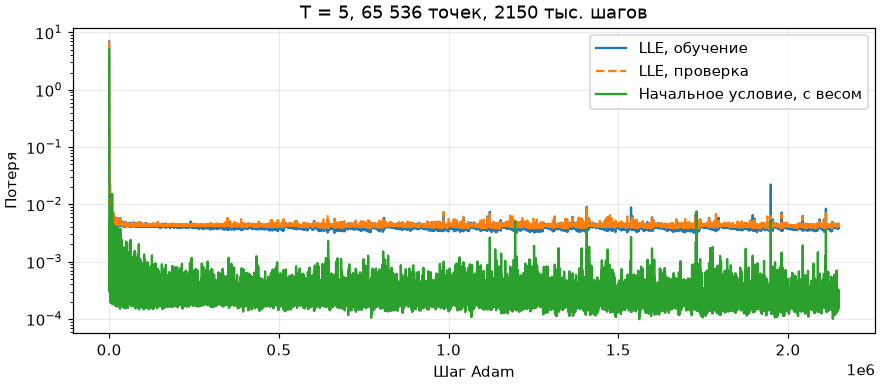

In [215]:
fig = plot_loss_history(T5_65536_2150K_RUN_ID, "T = 5, 65 536 точек, 2150 тыс. шагов")
plt.show()

## T = 5, 131072 точек и 2 млн шагов

Запуск 2026-11-20_11-18-26_476733 завершился на RTX 4090 за 17 ч 15 мин. Базовая сеть 4 x 64, четыре гармоники, seed 42, обучение с нуля. Число внутренних точек удвоено относительно контроля при том же бюджете 2 млн шагов.

| Внутренние точки | Шаги Adam | Макс. ошибка на [0; 4,5] | На [4,5; 5] | На всем [0; 5] | Перелом |
|---:|---:|---:|---:|---:|---:|
| 65536 | 2000000 | 80,85% | 51,83% | 80,85% | Не выявлен |
| 65536 | 2150000 | 80,61% | 50,79% | 80,61% | Не выявлен |
| 131072 | 2000000 | 1,17% | 1,03% | 1,17% | Около 1425700 шагов |

Критерий 5% выполнен на всем интервале. Максимальная относительная L2-ошибка комплексного поля приходится на t = 3,76. При t = 5 ошибка составляет 0,86%. Пики интенсивности при t = 1,48 и t = 3,5 равны 12,14 и 9,93 при эталонных 12,26 и 10,07. Конечный пик равен 7,54 при эталонном 7,52.

После длительного плато около 1,426 млн шагов происходит совместный спад обучающей и проверочной невязок LLE. По медианам в окнах по 5000 шагов положение резкого спада равно 1425700. На участке 1400-1410 тыс. шагов медиана проверочной невязки равна 0,00385, на 1500-1510 тыс. уже 0,000254. При том же бюджете удвоение числа точек изменило результат с 80,85% до 1,17%.

Сравнение выполнено на общей сетке спектрального эталона 2026-11-20_11-10-40_241883. По метаданным новый запуск выполнен с git_dirty=true, поэтому точное совпадение исходного кода с контрольным запуском по хешу подтвердить нельзя.


Максимальная ошибка на [0,4.5] — 1.17%
Максимальная ошибка на [0,T] — 1.17% при t = 3.76


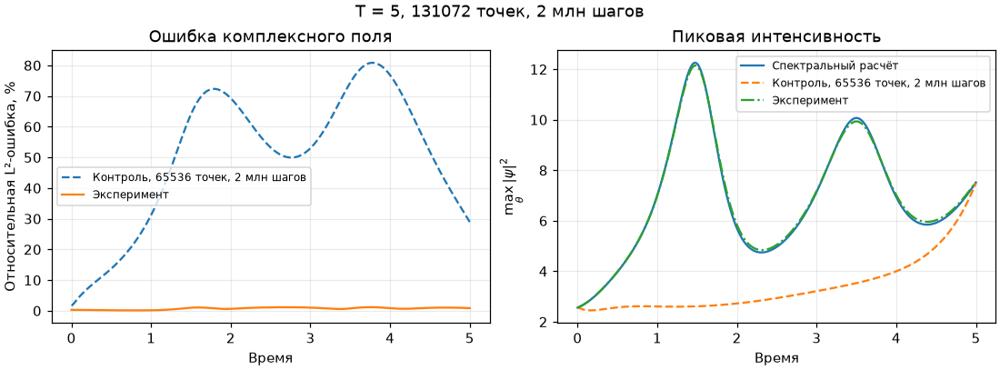

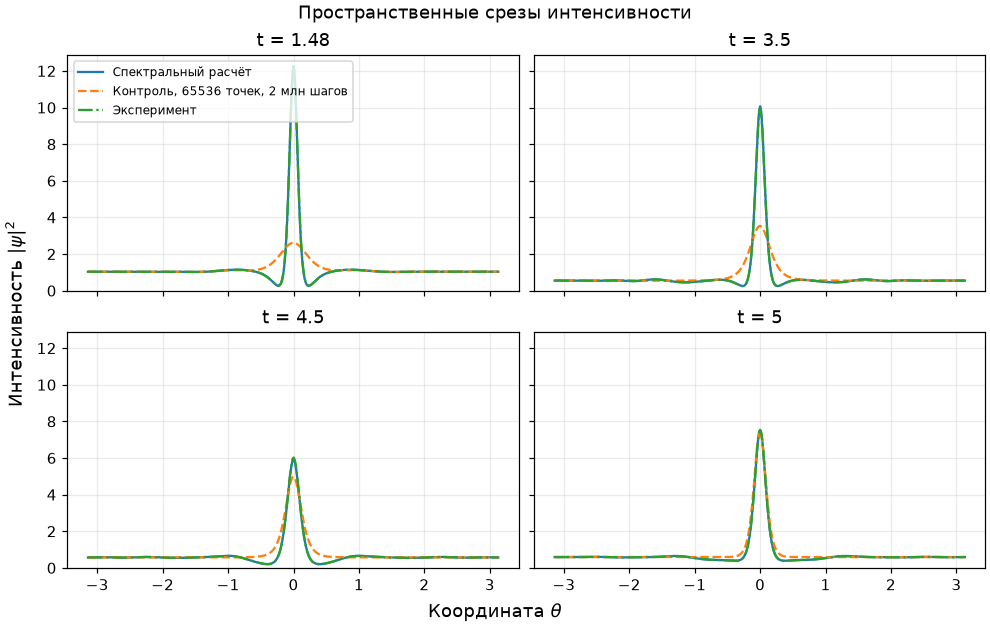

In [216]:
T5_131072_2000K_RUN_ID = "2026-11-20_11-18-26_476733"
show_horizon_run(T5_131072_2000K_RUN_ID, "T = 5, 131072 точек, 2 млн шагов",
    load_evolution(get_run(T5_65536_2000K_RUN_ID).path), "Контроль, 65536 точек, 2 млн шагов",
    (1.48, 3.5, 4.5, 5.0), reference=load_evolution(get_run("2026-11-20_11-10-40_241883").path), early_end=4.5)

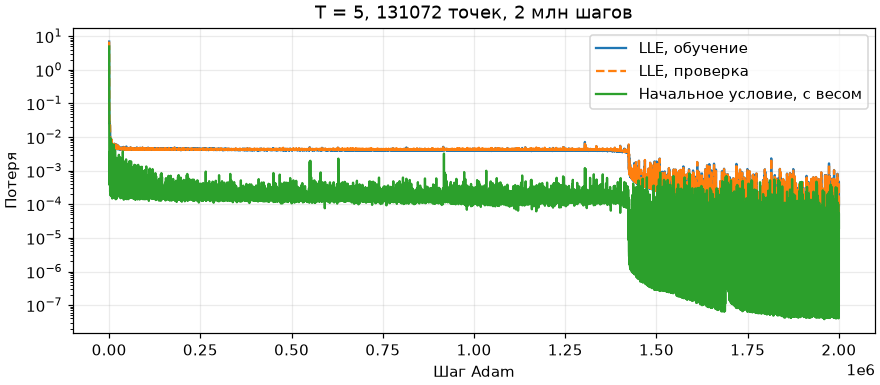

In [217]:
fig = plot_loss_history(T5_131072_2000K_RUN_ID, "T = 5, 131072 точек, 2 млн шагов")
plt.show()